
# STEP 1 — Inspect Google Colab runtime and GPU environment

In [1]:
import sys
import platform
import subprocess

print("=" * 70)
print("WiML Biological Equivalence Pilot — Runtime Check")
print("=" * 70)

# Python / operating system
print(f"Python version : {sys.version.split()[0]}")
print(f"Platform       : {platform.platform()}")

# PyTorch may already be installed in Colab.
try:
    import torch

    print(f"PyTorch version: {torch.__version__}")
    print(f"CUDA available : {torch.cuda.is_available()}")

    if torch.cuda.is_available():
        print(f"CUDA version    : {torch.version.cuda}")
        print(f"GPU count       : {torch.cuda.device_count()}")
        print(f"GPU name        : {torch.cuda.get_device_name(0)}")

        props = torch.cuda.get_device_properties(0)
        total_memory_gb = props.total_memory / (1024 ** 3)
        print(f"GPU memory      : {total_memory_gb:.2f} GB")
    else:
        print("GPU name        : NONE")

except Exception as e:
    print(f"PyTorch check FAILED: {type(e).__name__}: {e}")

# Transformers may or may not already be installed.
try:
    import transformers
    print(f"Transformers    : {transformers.__version__}")
except ImportError:
    print("Transformers    : NOT INSTALLED")
except Exception as e:
    print(f"Transformers check FAILED: {type(e).__name__}: {e}")

# Colab runtime confirmation.
try:
    import google.colab
    print("Google Colab    : YES")
except ImportError:
    print("Google Colab    : NO")

# NVIDIA driver / GPU diagnostic.
print("\n--- nvidia-smi ---")
result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print(result.stdout)
else:
    print("nvidia-smi unavailable or GPU runtime not attached.")
    if result.stderr:
        print(result.stderr)

WiML Biological Equivalence Pilot — Runtime Check
Python version : 3.12.13
Platform       : Linux-6.6.122+-x86_64-with-glibc2.35
PyTorch version: 2.11.0+cu128
CUDA available : True
CUDA version    : 12.8
GPU count       : 1
GPU name        : Tesla T4
GPU memory      : 14.56 GB
Transformers    : 5.13.1
Google Colab    : YES

--- nvidia-smi ---
Mon Aug 17 16:59:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+===


# STEP 2 — Install minimal Omni-DNA pilot dependencies


In [3]:
# Repair NumPy / pandas / pyarrow binary compatibility

import sys
import subprocess
import importlib.metadata as metadata

print("Before repair:")
for package in ["numpy", "pandas", "pyarrow", "datasets"]:
    try:
        print(f"{package:10s}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package:10s}: NOT FOUND")

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--upgrade",
        "--force-reinstall",
        "numpy==2.2.6",
        "pandas==2.2.3",
        "pyarrow==19.0.1",
    ],
    check=True,
)

print("\nAfter repair:")
for package in ["numpy", "pandas", "pyarrow", "datasets"]:
    print(f"{package:10s}: {metadata.version(package)}")

print("\nRestart the Colab runtime after this cell finishes.")

Before repair:
numpy     : 1.26.4
pandas    : 2.2.2
pyarrow   : 18.1.0
datasets  : 4.0.0

After repair:
numpy     : 2.2.6
pandas    : 2.2.3
pyarrow   : 19.0.1
datasets  : 4.0.0

Restart the Colab runtime after this cell finishes.


In [1]:
# Verify repaired dependency stack after runtime restart

import torch
import transformers
import datasets
import pandas as pd
import numpy as np
import pyarrow as pa
import olmo

print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("pyarrow     :", pa.__version__)
print("datasets    :", datasets.__version__)
print("torch       :", torch.__version__)
print("transformers:", transformers.__version__)
print("CUDA        :", torch.cuda.is_available())

assert torch.cuda.is_available(), "CUDA is not available."

numpy       : 2.2.6
pandas      : 2.2.3
pyarrow     : 19.0.1
datasets    : 4.0.0
torch       : 2.11.0+cu128
transformers: 5.13.1
CUDA        : True


# STEP 3 — Set reproducibility controls

In [2]:
import os
import random
import numpy as np
import torch

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Favor deterministic behavior where supported.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("SEED:", SEED)
print("Python random test:", random.random())
print("NumPy random test :", np.random.rand())
print("Torch random test :", torch.rand(1).item())
print("CUDA available    :", torch.cuda.is_available())

SEED: 42
Python random test: 0.6394267984578837
NumPy random test : 0.3745401188473625
Torch random test : 0.8822692632675171
CUDA available    : True


# STEP 4 — Mount Google Drive and create persistent project directories


In [3]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/wiml_equivalence")

PROJECT_DIRS = {
    "data_raw": PROJECT_ROOT / "data" / "raw",
    "data_processed": PROJECT_ROOT / "data" / "processed",
    "metadata": PROJECT_ROOT / "metadata",
    "embeddings": PROJECT_ROOT / "embeddings",
    "results": PROJECT_ROOT / "results",
    "figures": PROJECT_ROOT / "figures",
    "logs": PROJECT_ROOT / "logs",
}

for path in PROJECT_DIRS.values():
    path.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
for name, path in PROJECT_DIRS.items():
    print(f"{name:15s}: {path} | exists={path.exists()}")

assert all(path.exists() for path in PROJECT_DIRS.values())

Mounted at /content/drive
Project root: /content/drive/MyDrive/wiml_equivalence
data_raw       : /content/drive/MyDrive/wiml_equivalence/data/raw | exists=True
data_processed : /content/drive/MyDrive/wiml_equivalence/data/processed | exists=True
metadata       : /content/drive/MyDrive/wiml_equivalence/metadata | exists=True
embeddings     : /content/drive/MyDrive/wiml_equivalence/embeddings | exists=True
results        : /content/drive/MyDrive/wiml_equivalence/results | exists=True
figures        : /content/drive/MyDrive/wiml_equivalence/figures | exists=True
logs           : /content/drive/MyDrive/wiml_equivalence/logs | exists=True


# STEP 5 — Identify current Ensembl Homo sapiens CDS FASTA file

In [4]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

ENSEMBL_CDS_DIR = (
    "https://ftp.ensembl.org/pub/current_fasta/"
    "homo_sapiens/cds/"
)

response = requests.get(ENSEMBL_CDS_DIR, timeout=30)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

files = sorted(
    link.get("href")
    for link in soup.find_all("a")
    if link.get("href")
    and link.get("href").endswith(".cds.all.fa.gz")
)

print("Ensembl CDS directory:", ENSEMBL_CDS_DIR)
print("Matching CDS files:", len(files))

for filename in files:
    print(filename)

assert len(files) == 1, (
    f"Expected exactly one Homo sapiens .cds.all.fa.gz file, found {len(files)}"
)

ENSEMBL_CDS_FILENAME = files[0]
ENSEMBL_CDS_URL = urljoin(ENSEMBL_CDS_DIR, ENSEMBL_CDS_FILENAME)

print("\nSelected file:", ENSEMBL_CDS_FILENAME)
print("Download URL :", ENSEMBL_CDS_URL)

Ensembl CDS directory: https://ftp.ensembl.org/pub/current_fasta/homo_sapiens/cds/
Matching CDS files: 1
Homo_sapiens.GRCh38.cds.all.fa.gz

Selected file: Homo_sapiens.GRCh38.cds.all.fa.gz
Download URL : https://ftp.ensembl.org/pub/current_fasta/homo_sapiens/cds/Homo_sapiens.GRCh38.cds.all.fa.gz


In [5]:
# Download Ensembl CDS FASTA and save source metadata

from pathlib import Path
import requests
import hashlib
import json

RAW_FASTA_PATH = PROJECT_DIRS["data_raw"] / ENSEMBL_CDS_FILENAME
SOURCE_METADATA_PATH = PROJECT_DIRS["metadata"] / "source_metadata.json"

if not RAW_FASTA_PATH.exists():
    with requests.get(ENSEMBL_CDS_URL, stream=True, timeout=120) as response:
        response.raise_for_status()

        with open(RAW_FASTA_PATH, "wb") as f:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)

file_size_mb = RAW_FASTA_PATH.stat().st_size / (1024 ** 2)

sha256 = hashlib.sha256()
with open(RAW_FASTA_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(chunk)

source_metadata = {
    "source": "Ensembl",
    "organism": "Homo sapiens",
    "assembly": "GRCh38",
    "file_name": ENSEMBL_CDS_FILENAME,
    "download_url": ENSEMBL_CDS_URL,
    "local_path": str(RAW_FASTA_PATH),
    "file_size_mb": round(file_size_mb, 2),
    "sha256": sha256.hexdigest(),
}

with open(SOURCE_METADATA_PATH, "w") as f:
    json.dump(source_metadata, f, indent=2)

print("Downloaded file :", RAW_FASTA_PATH)
print("File size (MB)  :", round(file_size_mb, 2))
print("SHA256          :", source_metadata["sha256"])
print("Metadata file   :", SOURCE_METADATA_PATH)

assert RAW_FASTA_PATH.exists()
assert RAW_FASTA_PATH.stat().st_size > 0
assert SOURCE_METADATA_PATH.exists()

Downloaded file : /content/drive/MyDrive/wiml_equivalence/data/raw/Homo_sapiens.GRCh38.cds.all.fa.gz
File size (MB)  : 35.23
SHA256          : f8c6731e185957e29816a8a38ce21dc61ef6c3fc4963fbb9c0cdd8ebd20f1342
Metadata file   : /content/drive/MyDrive/wiml_equivalence/metadata/source_metadata.json


# STEP 6 — Inspect Ensembl CDS FASTA headers and basic sequence properties


In [6]:

import gzip
from collections import Counter

record_count = 0
lengths = []
alphabet_counts = Counter()
example_records = []

with gzip.open(RAW_FASTA_PATH, "rt") as f:
    current_header = None
    current_seq = []

    for line in f:
        line = line.strip()

        if line.startswith(">"):
            if current_header is not None:
                seq = "".join(current_seq).upper()
                record_count += 1
                lengths.append(len(seq))
                alphabet_counts.update(seq)

                if len(example_records) < 5:
                    example_records.append((current_header, seq))

            current_header = line[1:]
            current_seq = []
        else:
            current_seq.append(line)

    # Final FASTA record
    if current_header is not None:
        seq = "".join(current_seq).upper()
        record_count += 1
        lengths.append(len(seq))
        alphabet_counts.update(seq)

        if len(example_records) < 5:
            example_records.append((current_header, seq))

print("Total FASTA records:", record_count)
print("Minimum length     :", min(lengths))
print("Maximum length     :", max(lengths))
print("Median length      :", sorted(lengths)[len(lengths) // 2])
print("Observed alphabet  :", sorted(alphabet_counts.keys()))

print("\nFirst 5 FASTA headers:")
for i, (header, seq) in enumerate(example_records, start=1):
    print(f"\nRecord {i}")
    print("Header:", header)
    print("Length:", len(seq))
    print("First 60 nt:", seq[:60])

assert record_count > 0
assert all(length > 0 for length in lengths)

Total FASTA records: 382428
Minimum length     : 3
Maximum length     : 107976
Median length      : 915
Observed alphabet  : ['A', 'C', 'G', 'N', 'T']

First 5 FASTA headers:

Record 1
Header: ENST00000632585.1 cds scaffold:GRCh38:HG2290_PATCH:6058:6610:1 gene:ENSG00000282172.1 gene_biotype:IG_V_gene transcript_biotype:IG_V_gene gene_symbol:IGKV5-2 description:immunoglobulin kappa variable 5-2 [Source:HGNC Symbol;Acc:HGNC:5835]
Length: 345
First 60 nt: ATGGGGTCCCAGGTTCACCTCCTCAGCTTCCTCCTCCTTTGGATCTCTGATACCAGGGCA

Record 2
Header: ENST00000632205.1 cds scaffold:GRCh38:HG2290_PATCH:56127:56783:-1 gene:ENSG00000282801.1 gene_biotype:IG_V_gene transcript_biotype:IG_V_gene gene_symbol:IGKV1-5 description:immunoglobulin kappa variable 1-5 [Source:HGNC Symbol;Acc:HGNC:5741]
Length: 351
First 60 nt: ATGGACATGAGGGTCCCCGCTCAGCTCCTGGGGCTCCTGCTGCTCTGGCTCCCAGGTGCC

Record 3
Header: ENST00000632891.1 cds scaffold:GRCh38:HG2290_PATCH:75088:75593:-1 gene:ENSG00000282163.1 gene_biotype:IG_V_gene transc

# STEP 6 — Profile CDS quality and annotation categories before filtering


In [7]:

import gzip
import re
from collections import Counter
import numpy as np

biotype_counts = Counter()
location_type_counts = Counter()

total_records = 0
acgt_only_count = 0
divisible_by_3_count = 0
acgt_and_frame_count = 0
contains_n_count = 0

sequence_counts = Counter()
lengths_all = []
lengths_clean_frame = []

with gzip.open(RAW_FASTA_PATH, "rt") as f:
    header = None
    seq_parts = []

    def process_record(header, seq_parts):
        global total_records
        global acgt_only_count, divisible_by_3_count
        global acgt_and_frame_count, contains_n_count

        if header is None:
            return

        seq = "".join(seq_parts).upper()
        total_records += 1
        lengths_all.append(len(seq))
        sequence_counts[seq] += 1

        # Extract transcript biotype from structured Ensembl header.
        match = re.search(r"transcript_biotype:([^\s]+)", header)
        biotype = match.group(1) if match else "MISSING"
        biotype_counts[biotype] += 1

        # Ensembl coordinate descriptor appears immediately after "cds".
        match = re.search(r"\bcds\s+([^:]+):", header)
        location_type = match.group(1) if match else "MISSING"
        location_type_counts[location_type] += 1

        chars = set(seq)
        acgt_only = chars.issubset({"A", "C", "G", "T"})
        divisible_by_3 = (len(seq) % 3 == 0)

        if acgt_only:
            acgt_only_count += 1

        if "N" in chars:
            contains_n_count += 1

        if divisible_by_3:
            divisible_by_3_count += 1

        if acgt_only and divisible_by_3:
            acgt_and_frame_count += 1
            lengths_clean_frame.append(len(seq))

    for line in f:
        line = line.strip()

        if line.startswith(">"):
            process_record(header, seq_parts)
            header = line[1:]
            seq_parts = []
        else:
            seq_parts.append(line)

    process_record(header, seq_parts)

unique_sequences = len(sequence_counts)
duplicate_records = total_records - unique_sequences

print("Total records                 :", total_records)
print("ACGT-only records             :", acgt_only_count)
print("Records containing N          :", contains_n_count)
print("Length divisible by 3         :", divisible_by_3_count)
print("ACGT-only AND divisible by 3  :", acgt_and_frame_count)

print("\nUnique DNA sequences           :", unique_sequences)
print("Duplicate sequence records     :", duplicate_records)
print("Duplicate fraction             :", round(duplicate_records / total_records, 4))

print("\nTranscript biotypes (top 15):")
for biotype, count in biotype_counts.most_common(15):
    print(f"{biotype:30s} {count}")

print("\nCoordinate types:")
for location_type, count in location_type_counts.most_common():
    print(f"{location_type:15s} {count}")

if lengths_clean_frame:
    clean_lengths = np.array(lengths_clean_frame)

    print("\nLength distribution for ACGT-only, in-frame records:")
    print("Min :", int(clean_lengths.min()))
    print("P25 :", int(np.percentile(clean_lengths, 25)))
    print("P50 :", int(np.percentile(clean_lengths, 50)))
    print("P75 :", int(np.percentile(clean_lengths, 75)))
    print("P95 :", int(np.percentile(clean_lengths, 95)))
    print("Max :", int(clean_lengths.max()))

assert total_records == record_count
assert acgt_and_frame_count <= total_records
assert unique_sequences <= total_records

Total records                 : 382428
ACGT-only records             : 373401
Records containing N          : 9027
Length divisible by 3         : 368066
ACGT-only AND divisible by 3  : 360189

Unique DNA sequences           : 242793
Duplicate sequence records     : 139635
Duplicate fraction             : 0.3651

Transcript biotypes (top 15):
protein_coding                 288650
nonsense_mediated_decay        92893
IG_V_gene                      232
TR_V_gene                      160
protein_coding_LoF             148
non_stop_decay                 116
TR_J_gene                      93
IG_D_gene                      64
IG_C_gene                      34
IG_J_gene                      24
TR_C_gene                      8
TR_D_gene                      6

Coordinate types:
chromosome      370886
scaffold        11542

Length distribution for ACGT-only, in-frame records:
Min : 3
P25 : 456
P50 : 966
P75 : 1677
P95 : 3399
Max : 107976


# STEP 6 — Profile translation integrity and synonymous editability

In [8]:
import gzip
import re
from collections import Counter
import numpy as np

# Standard nuclear genetic code
CODON_TO_AA = {
    "TTT":"F","TTC":"F","TTA":"L","TTG":"L",
    "TCT":"S","TCC":"S","TCA":"S","TCG":"S",
    "TAT":"Y","TAC":"Y","TAA":"*","TAG":"*",
    "TGT":"C","TGC":"C","TGA":"*","TGG":"W",
    "CTT":"L","CTC":"L","CTA":"L","CTG":"L",
    "CCT":"P","CCC":"P","CCA":"P","CCG":"P",
    "CAT":"H","CAC":"H","CAA":"Q","CAG":"Q",
    "CGT":"R","CGC":"R","CGA":"R","CGG":"R",
    "ATT":"I","ATC":"I","ATA":"I","ATG":"M",
    "ACT":"T","ACC":"T","ACA":"T","ACG":"T",
    "AAT":"N","AAC":"N","AAA":"K","AAG":"K",
    "AGT":"S","AGC":"S","AGA":"R","AGG":"R",
    "GTT":"V","GTC":"V","GTA":"V","GTG":"V",
    "GCT":"A","GCC":"A","GCA":"A","GCG":"A",
    "GAT":"D","GAC":"D","GAA":"E","GAG":"E",
    "GGT":"G","GGC":"G","GGA":"G","GGG":"G",
}

AA_TO_CODONS = {}
for codon, aa in CODON_TO_AA.items():
    AA_TO_CODONS.setdefault(aa, []).append(codon)

def translate_cds(seq):
    assert len(seq) % 3 == 0
    return "".join(
        CODON_TO_AA[seq[i:i+3]]
        for i in range(0, len(seq), 3)
    )

def count_synonymous_editable_codons(seq):
    count = 0

    for i in range(0, len(seq), 3):
        codon = seq[i:i+3]
        aa = CODON_TO_AA[codon]

        # Start and stop codons are deliberately excluded from editing.
        if i == 0 or aa == "*":
            continue

        alternatives = [c for c in AA_TO_CODONS[aa] if c != codon]

        if alternatives:
            count += 1

    return count

candidate_count = 0
canonical_start_count = 0
terminal_stop_count = 0
internal_stop_count = 0
canonical_complete_count = 0

candidate_lengths = []
editable_counts = []
candidate_sequence_counts = Counter()

with gzip.open(RAW_FASTA_PATH, "rt") as f:
    header = None
    seq_parts = []

    def inspect_record(header, seq_parts):
        global candidate_count
        global canonical_start_count
        global terminal_stop_count
        global internal_stop_count
        global canonical_complete_count

        if header is None:
            return

        seq = "".join(seq_parts).upper()

        biotype_match = re.search(
            r"transcript_biotype:([^\s]+)", header
        )
        biotype = (
            biotype_match.group(1)
            if biotype_match else "MISSING"
        )

        location_match = re.search(r"\bcds\s+([^:]+):", header)
        location_type = (
            location_match.group(1)
            if location_match else "MISSING"
        )

        if biotype != "protein_coding":
            return

        if location_type != "chromosome":
            return

        if not set(seq).issubset({"A", "C", "G", "T"}):
            return

        if len(seq) % 3 != 0:
            return

        candidate_count += 1
        candidate_lengths.append(len(seq))
        candidate_sequence_counts[seq] += 1

        protein = translate_cds(seq)

        has_start = seq.startswith("ATG")
        has_terminal_stop = protein.endswith("*")
        has_internal_stop = "*" in protein[:-1]

        canonical_start_count += int(has_start)
        terminal_stop_count += int(has_terminal_stop)
        internal_stop_count += int(has_internal_stop)

        if has_start and has_terminal_stop and not has_internal_stop:
            canonical_complete_count += 1
            editable_counts.append(
                count_synonymous_editable_codons(seq)
            )

    for line in f:
        line = line.strip()

        if line.startswith(">"):
            inspect_record(header, seq_parts)
            header = line[1:]
            seq_parts = []
        else:
            seq_parts.append(line)

    inspect_record(header, seq_parts)

unique_candidate_sequences = len(candidate_sequence_counts)

print("Basic candidate records            :", candidate_count)
print("Canonical ATG start                :", canonical_start_count)
print("Terminal stop codon                :", terminal_stop_count)
print("Contains internal stop             :", internal_stop_count)
print("Start + terminal stop + no internal:", canonical_complete_count)

print("\nUnique basic candidate sequences    :", unique_candidate_sequences)
print(
    "Duplicate basic candidate records  :",
    candidate_count - unique_candidate_sequences
)

if editable_counts:
    editable = np.array(editable_counts)

    print("\nSynonymous-editable codons among complete candidates:")
    print("Min :", int(editable.min()))
    print("P25 :", int(np.percentile(editable, 25)))
    print("P50 :", int(np.percentile(editable, 50)))
    print("P75 :", int(np.percentile(editable, 75)))
    print("P95 :", int(np.percentile(editable, 95)))
    print("Max :", int(editable.max()))
    print("At least 3 editable codons:", int((editable >= 3).sum()))

assert len(CODON_TO_AA) == 64
assert candidate_count > 0
assert canonical_complete_count <= candidate_count

Basic candidate records            : 261998
Canonical ATG start                : 259261
Terminal stop codon                : 255897
Contains internal stop             : 109
Start + terminal stop + no internal: 253386

Unique basic candidate sequences    : 166417
Duplicate basic candidate records  : 95581

Synonymous-editable codons among complete candidates:
Min : 7
P25 : 224
P50 : 394
P75 : 630
P95 : 1198
Max : 35114
At least 3 editable codons: 253386


# STEP 7 — Build and save validated unique CDS candidate table

In [9]:
import gzip
import re
import pandas as pd

validated_records = []
seen_sequences = set()

with gzip.open(RAW_FASTA_PATH, "rt") as f:
    header = None
    seq_parts = []

    def collect_record(header, seq_parts):
        if header is None:
            return

        seq = "".join(seq_parts).upper()

        transcript_match = re.match(r"^(\S+)", header)
        transcript_id = transcript_match.group(1) if transcript_match else None

        gene_match = re.search(r"\bgene:([^\s]+)", header)
        gene_id = gene_match.group(1) if gene_match else None

        symbol_match = re.search(r"\bgene_symbol:([^\s]+)", header)
        gene_symbol = symbol_match.group(1) if symbol_match else None

        biotype_match = re.search(r"transcript_biotype:([^\s]+)", header)
        biotype = biotype_match.group(1) if biotype_match else None

        location_match = re.search(r"\bcds\s+([^:]+):([^:]+):", header)
        location_type = location_match.group(1) if location_match else None
        chromosome = location_match.group(2) if location_match else None

        if biotype != "protein_coding":
            return

        if location_type != "chromosome":
            return

        if not set(seq).issubset({"A", "C", "G", "T"}):
            return

        if len(seq) % 3 != 0:
            return

        protein = translate_cds(seq)

        if not seq.startswith("ATG"):
            return

        if not protein.endswith("*"):
            return

        if "*" in protein[:-1]:
            return

        # Deduplicate exact CDS sequence.
        if seq in seen_sequences:
            return

        seen_sequences.add(seq)

        validated_records.append({
            "sequence_id": transcript_id,
            "gene_id": gene_id,
            "gene_symbol": gene_symbol,
            "source": "Ensembl",
            "organism": "Homo sapiens",
            "assembly": "GRCh38",
            "chromosome": chromosome,
            "original_sequence": seq,
            "sequence_length": len(seq),
            "protein_translation": protein,
            "num_synonymous_editable_codons":
                count_synonymous_editable_codons(seq),
        })

    for line in f:
        line = line.strip()

        if line.startswith(">"):
            collect_record(header, seq_parts)
            header = line[1:]
            seq_parts = []
        else:
            seq_parts.append(line)

    collect_record(header, seq_parts)

validated_cds_df = pd.DataFrame(validated_records)

VALIDATED_CDS_PATH = (
    PROJECT_DIRS["data_processed"] / "validated_cds_candidates.csv"
)

validated_cds_df.to_csv(VALIDATED_CDS_PATH, index=False)

print("Validated unique CDS:", len(validated_cds_df))
print("Saved to            :", VALIDATED_CDS_PATH)

print("\nSequence length summary:")
print(validated_cds_df["sequence_length"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.95]
))

print("\nEditable codon summary:")
print(validated_cds_df["num_synonymous_editable_codons"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.95]
))

print("\nFirst 5 rows:")
print(
    validated_cds_df[
        [
            "sequence_id",
            "gene_id",
            "gene_symbol",
            "chromosome",
            "sequence_length",
            "num_synonymous_editable_codons",
        ]
    ].head()
)

assert len(validated_cds_df) > 0
assert validated_cds_df["original_sequence"].is_unique
assert (validated_cds_df["sequence_length"] % 3 == 0).all()
assert (
    validated_cds_df["num_synonymous_editable_codons"] >= 3
).all()

Validated unique CDS: 158033
Saved to            : /content/drive/MyDrive/wiml_equivalence/data/processed/validated_cds_candidates.csv

Sequence length summary:
count    158033.000000
mean       1554.330539
std        1567.831541
min          27.000000
25%         684.000000
50%        1236.000000
75%        2013.000000
95%        3822.000000
max      107976.000000
Name: sequence_length, dtype: float64

Editable codon summary:
count    158033.000000
mean        499.598508
std         507.754510
min           7.000000
25%         218.000000
50%         396.000000
75%         648.000000
95%        1236.000000
max       35114.000000
Name: num_synonymous_editable_codons, dtype: float64

First 5 rows:
         sequence_id            gene_id gene_symbol chromosome  \
0  ENST00000361335.1  ENSG00000212907.2     MT-ND4L     GRCh38   
1  ENST00000711256.2  ENSG00000292363.1       CRLF2     GRCh38   
2  ENST00000972698.1  ENSG00000292363.1       CRLF2     GRCh38   
3  ENST00001145933.1  ENSG0000

# STEP 8 — Correct chromosome parsing and rebuild nuclear CDS candidate table

In [10]:
import gzip
import re
import pandas as pd

STANDARD_CHROMOSOMES = {str(i) for i in range(1, 23)} | {"X", "Y"}

validated_records = []
seen_sequences = set()

with gzip.open(RAW_FASTA_PATH, "rt") as f:
    header = None
    seq_parts = []

    def collect_nuclear_record(header, seq_parts):
        if header is None:
            return

        seq = "".join(seq_parts).upper()

        transcript_match = re.match(r"^(\S+)", header)
        transcript_id = transcript_match.group(1) if transcript_match else None

        gene_match = re.search(r"\bgene:([^\s]+)", header)
        gene_id = gene_match.group(1) if gene_match else None

        symbol_match = re.search(r"\bgene_symbol:([^\s]+)", header)
        gene_symbol = symbol_match.group(1) if symbol_match else None

        biotype_match = re.search(r"\btranscript_biotype:([^\s]+)", header)
        biotype = biotype_match.group(1) if biotype_match else None

        # Expected Ensembl structure:
        # cds chromosome:GRCh38:<seqname>:<start>:<end>:<strand>
        coord_match = re.search(
            r"\bcds\s+([^:]+):([^:]+):([^:]+):(\d+):(\d+):(-?1)",
            header
        )

        if coord_match is None:
            return

        location_type = coord_match.group(1)
        assembly = coord_match.group(2)
        chromosome = coord_match.group(3)
        start = int(coord_match.group(4))
        end = int(coord_match.group(5))
        strand = int(coord_match.group(6))

        if biotype != "protein_coding":
            return

        if location_type != "chromosome":
            return

        if chromosome not in STANDARD_CHROMOSOMES:
            return

        if not set(seq).issubset({"A", "C", "G", "T"}):
            return

        if len(seq) % 3 != 0:
            return

        protein = translate_cds(seq)

        if not seq.startswith("ATG"):
            return

        if not protein.endswith("*"):
            return

        if "*" in protein[:-1]:
            return

        if seq in seen_sequences:
            return

        seen_sequences.add(seq)

        validated_records.append({
            "sequence_id": transcript_id,
            "gene_id": gene_id,
            "gene_symbol": gene_symbol,
            "source": "Ensembl",
            "organism": "Homo sapiens",
            "assembly": assembly,
            "chromosome": chromosome,
            "genomic_start": start,
            "genomic_end": end,
            "strand": strand,
            "original_sequence": seq,
            "sequence_length": len(seq),
            "protein_translation": protein,
            "num_synonymous_editable_codons":
                count_synonymous_editable_codons(seq),
        })

    for line in f:
        line = line.strip()

        if line.startswith(">"):
            collect_nuclear_record(header, seq_parts)
            header = line[1:]
            seq_parts = []
        else:
            seq_parts.append(line)

    collect_nuclear_record(header, seq_parts)

validated_cds_df = pd.DataFrame(validated_records)

VALIDATED_CDS_PATH = (
    PROJECT_DIRS["data_processed"] / "validated_cds_candidates.csv"
)

validated_cds_df.to_csv(VALIDATED_CDS_PATH, index=False)

print("Validated unique nuclear CDS:", len(validated_cds_df))
print("Saved to                    :", VALIDATED_CDS_PATH)

print("\nChromosome counts:")
print(
    validated_cds_df["chromosome"]
    .value_counts()
    .sort_index(key=lambda x: x.map(
        lambda c: int(c) if c.isdigit() else {"X": 23, "Y": 24}[c]
    ))
)

print("\nFirst 5 rows:")
print(
    validated_cds_df[
        [
            "sequence_id",
            "gene_id",
            "gene_symbol",
            "chromosome",
            "strand",
            "sequence_length",
            "num_synonymous_editable_codons",
        ]
    ].head()
)

assert len(validated_cds_df) > 0
assert validated_cds_df["original_sequence"].is_unique
assert set(validated_cds_df["chromosome"]).issubset(STANDARD_CHROMOSOMES)
assert not validated_cds_df["gene_symbol"].fillna("").str.startswith("MT-").any()
assert (validated_cds_df["sequence_length"] % 3 == 0).all()
assert (
    validated_cds_df["num_synonymous_editable_codons"] >= 3
).all()

Validated unique nuclear CDS: 158032
Saved to                    : /content/drive/MyDrive/wiml_equivalence/data/processed/validated_cds_candidates.csv

Chromosome counts:
chromosome
1     16375
2     11355
3      9600
4      6313
5      6666
6      7745
7      7769
8      5321
9      6462
10     6962
11     9418
12     8355
13     2698
14     4919
15     4814
16     6713
17     9209
18     2447
19    10269
20     4013
21     1631
22     3908
X      4739
Y       331
Name: count, dtype: int64

First 5 rows:
         sequence_id            gene_id gene_symbol chromosome  strand  \
0  ENST00000711256.2  ENSG00000292363.1       CRLF2          Y      -1   
1  ENST00000972698.1  ENSG00000292363.1       CRLF2          Y      -1   
2  ENST00001145933.1  ENSG00000292344.3      PLCXD1          Y       1   
3  ENST00001145995.1  ENSG00000292344.3      PLCXD1          Y       1   
4  ENST00001145996.1  ENSG00000292344.3      PLCXD1          Y       1   

   sequence_length  num_synonymous_editable_

# STEP 9 — Smoke-test one synonymous transformation

In [11]:


import random

# Re-seed explicitly so this transformation is reproducible.
rng = random.Random(SEED)

# Use one validated CDS with enough editable codons.
smoke_row = validated_cds_df.iloc[0]

smoke_sequence_id = smoke_row["sequence_id"]
smoke_original = smoke_row["original_sequence"]
smoke_original_protein = translate_cds(smoke_original)

def get_synonymous_editable_sites(seq):
    sites = []

    for codon_index in range(1, len(seq) // 3):
        nt_position = codon_index * 3
        codon = seq[nt_position:nt_position + 3]
        aa = CODON_TO_AA[codon]

        # Do not edit stop codons.
        if aa == "*":
            continue

        alternatives = [
            c for c in AA_TO_CODONS[aa]
            if c != codon
        ]

        if alternatives:
            sites.append({
                "codon_index": codon_index,
                "nt_position": nt_position,
                "original_codon": codon,
                "aa": aa,
                "alternatives": sorted(alternatives),
            })

    return sites

editable_sites = get_synonymous_editable_sites(smoke_original)

assert len(editable_sites) >= 1

site = rng.choice(editable_sites)
new_codon = rng.choice(site["alternatives"])

smoke_variant_list = list(smoke_original)

start = site["nt_position"]
smoke_variant_list[start:start + 3] = list(new_codon)

smoke_synonymous = "".join(smoke_variant_list)
smoke_synonymous_protein = translate_cds(smoke_synonymous)

nt_edit_distance = sum(
    a != b
    for a, b in zip(smoke_original, smoke_synonymous)
)

print("Sequence ID      :", smoke_sequence_id)
print("Sequence length  :", len(smoke_original))
print("Editable codons  :", len(editable_sites))
print("Codon index      :", site["codon_index"])
print("NT position      :", site["nt_position"])
print("Original codon   :", site["original_codon"])
print("New codon        :", new_codon)
print("Original AA      :", site["aa"])
print("New AA           :", CODON_TO_AA[new_codon])
print("NT edit distance :", nt_edit_distance)
print("Translation equal:", smoke_original_protein == smoke_synonymous_protein)

assert smoke_original != smoke_synonymous
assert CODON_TO_AA[site["original_codon"]] == CODON_TO_AA[new_codon]
assert smoke_original_protein == smoke_synonymous_protein
assert len(smoke_original) == len(smoke_synonymous)

Sequence ID      : ENST00000711256.2
Sequence length  : 1116
Editable codons  : 351
Codon index      : 346
NT position      : 1038
Original codon   : CCC
New codon        : CCA
Original AA      : P
New AA           : P
NT edit distance : 1
Translation equal: True


# STEP 10 — Generate depth-1/2/3 synonymous compositions for 5 CDSs


In [12]:

import random
import pandas as pd

SMOKE_N = 5

# Deterministic smoke-test sample.
smoke_sample_df = (
    validated_cds_df
    .sample(n=SMOKE_N, random_state=SEED)
    .reset_index(drop=True)
)

synonymous_variant_records = []
synonymous_edit_records = []

def make_one_synonymous_edit(seq, rng, excluded_codon_indices=None):
    """
    Make exactly one synonymous codon replacement.

    Previously edited codon indices can be excluded so that composition
    depth corresponds to edits at distinct codon sites.
    """
    if excluded_codon_indices is None:
        excluded_codon_indices = set()

    editable_sites = get_synonymous_editable_sites(seq)

    editable_sites = [
        site for site in editable_sites
        if site["codon_index"] not in excluded_codon_indices
    ]

    if not editable_sites:
        raise ValueError("No remaining synonymous-editable codons.")

    site = rng.choice(editable_sites)
    new_codon = rng.choice(site["alternatives"])

    seq_list = list(seq)
    start = site["nt_position"]
    seq_list[start:start + 3] = list(new_codon)
    new_seq = "".join(seq_list)

    edit = {
        "codon_index": site["codon_index"],
        "nt_position": site["nt_position"],
        "original_codon": site["original_codon"],
        "new_codon": new_codon,
        "original_aa": site["aa"],
        "new_aa": CODON_TO_AA[new_codon],
    }

    return new_seq, edit


for row_idx, row in smoke_sample_df.iterrows():
    sequence_id = row["sequence_id"]
    original_seq = row["original_sequence"]
    original_protein = translate_cds(original_seq)

    # Give each source sequence its own deterministic RNG stream.
    rng = random.Random(SEED + row_idx)

    current_seq = original_seq
    edited_codon_indices = set()

    for depth in [1, 2, 3]:
        previous_seq = current_seq

        current_seq, edit = make_one_synonymous_edit(
            current_seq,
            rng,
            excluded_codon_indices=edited_codon_indices,
        )

        edited_codon_indices.add(edit["codon_index"])

        current_protein = translate_cds(current_seq)

        # Hard biological inclusion criterion.
        assert current_protein == original_protein

        cumulative_nt_distance = sum(
            a != b
            for a, b in zip(original_seq, current_seq)
        )

        step_nt_distance = sum(
            a != b
            for a, b in zip(previous_seq, current_seq)
        )

        synonymous_variant_records.append({
            "sequence_id": sequence_id,
            "depth": depth,
            "original_sequence": original_seq,
            "variant_sequence": current_seq,
            "sequence_length": len(original_seq),
            "edited_codons": depth,
            "nucleotide_edit_distance": cumulative_nt_distance,
            "fraction_sequence_changed":
                cumulative_nt_distance / len(original_seq),
            "translation_equal": current_protein == original_protein,
        })

        synonymous_edit_records.append({
            "sequence_id": sequence_id,
            "depth": depth,
            "edit_number": depth,
            "codon_index": edit["codon_index"],
            "nt_position": edit["nt_position"],
            "original_codon": edit["original_codon"],
            "new_codon": edit["new_codon"],
            "original_aa": edit["original_aa"],
            "new_aa": edit["new_aa"],
            "step_nt_edit_distance": step_nt_distance,
        })

smoke_synonymous_variants_df = pd.DataFrame(synonymous_variant_records)
smoke_synonymous_edits_df = pd.DataFrame(synonymous_edit_records)

print("Source sequences :", smoke_sample_df["sequence_id"].nunique())
print("Variants created :", len(smoke_synonymous_variants_df))
print("Edits recorded    :", len(smoke_synonymous_edits_df))

print("\nVariants per depth:")
print(
    smoke_synonymous_variants_df
    .groupby("depth")
    .size()
)

print("\nTranslation validation:")
print(
    smoke_synonymous_variants_df["translation_equal"]
    .value_counts()
)

print("\nCumulative nucleotide edit distance by depth:")
print(
    smoke_synonymous_variants_df
    .groupby("depth")["nucleotide_edit_distance"]
    .describe()[["min", "mean", "max"]]
)

print("\nEdit audit:")
print(
    smoke_synonymous_edits_df[
        [
            "sequence_id",
            "depth",
            "codon_index",
            "original_codon",
            "new_codon",
            "original_aa",
            "new_aa",
            "step_nt_edit_distance",
        ]
    ]
)

assert len(smoke_synonymous_variants_df) == SMOKE_N * 3
assert len(smoke_synonymous_edits_df) == SMOKE_N * 3
assert smoke_synonymous_variants_df["translation_equal"].all()

# Each source must have exactly one variant at each sequential depth.
assert (
    smoke_synonymous_variants_df
    .groupby("sequence_id")["depth"]
    .apply(lambda x: sorted(x.tolist()) == [1, 2, 3])
    .all()
)

# Distinct codon sites are used within each composition path.
assert (
    smoke_synonymous_edits_df
    .groupby("sequence_id")["codon_index"]
    .nunique()
    .eq(3)
    .all()
)

Source sequences : 5
Variants created : 15
Edits recorded    : 15

Variants per depth:
depth
1    5
2    5
3    5
dtype: int64

Translation validation:
translation_equal
True    15
Name: count, dtype: int64

Cumulative nucleotide edit distance by depth:
       min  mean  max
depth                
1      1.0   1.2  2.0
2      2.0   2.4  3.0
3      3.0   3.4  4.0

Edit audit:
          sequence_id  depth  codon_index original_codon new_codon  \
0   ENST00001108106.1      1          166            GGA       GGC   
1   ENST00001108106.1      2            7            TGC       TGT   
2   ENST00001108106.1      3           64            TGC       TGT   
3   ENST00000891252.2      1           20            GCA       GCG   
4   ENST00000891252.2      2          364            CTC       CTG   
5   ENST00000891252.2      3          241            GGA       GGG   
6   ENST00000858078.2      1          435            CCA       CCT   
7   ENST00000858078.2      2          575            CCC       

# STEP 12 — Generate matched nonsynonymous controls for the 5-sequence smoke test

In [13]:
import random
import pandas as pd

def codon_hamming_distance(codon_a, codon_b):
    assert len(codon_a) == 3
    assert len(codon_b) == 3
    return sum(a != b for a, b in zip(codon_a, codon_b))


def get_matched_nonsynonymous_codons(
    original_codon,
    target_nt_distance
):
    """
    Return codons that:
      1. differ from original_codon by exactly target_nt_distance,
      2. encode a different amino acid,
      3. do not introduce a stop codon.
    """
    original_aa = CODON_TO_AA[original_codon]

    candidates = []

    for candidate_codon, candidate_aa in CODON_TO_AA.items():

        if candidate_aa == "*":
            continue

        if candidate_aa == original_aa:
            continue

        if (
            codon_hamming_distance(
                original_codon,
                candidate_codon
            )
            != target_nt_distance
        ):
            continue

        candidates.append(candidate_codon)

    return sorted(candidates)


nonsynonymous_variant_records = []
nonsynonymous_edit_records = []

for row_idx, row in smoke_sample_df.iterrows():

    sequence_id = row["sequence_id"]
    original_seq = row["original_sequence"]
    original_protein = translate_cds(original_seq)

    # Independent deterministic stream for control generation.
    rng = random.Random(SEED + 1000 + row_idx)

    current_seq = original_seq

    syn_edits_for_sequence = (
        smoke_synonymous_edits_df[
            smoke_synonymous_edits_df["sequence_id"] == sequence_id
        ]
        .sort_values("depth")
    )

    assert len(syn_edits_for_sequence) == 3

    for _, syn_edit in syn_edits_for_sequence.iterrows():

        depth = int(syn_edit["depth"])
        codon_index = int(syn_edit["codon_index"])
        nt_position = codon_index * 3

        target_step_nt_distance = int(
            syn_edit["step_nt_edit_distance"]
        )

        previous_seq = current_seq

        control_original_codon = current_seq[
            nt_position:nt_position + 3
        ]

        # Because synonymous composition uses distinct codon sites,
        # this should still equal the original source codon.
        assert (
            control_original_codon
            == syn_edit["original_codon"]
        )

        matched_codons = get_matched_nonsynonymous_codons(
            control_original_codon,
            target_step_nt_distance
        )

        if not matched_codons:
            raise ValueError(
                f"No exact nonsynonymous match for "
                f"{sequence_id}, depth={depth}, "
                f"codon={control_original_codon}, "
                f"required_nt_distance={target_step_nt_distance}"
            )

        new_codon = rng.choice(matched_codons)

        seq_list = list(current_seq)
        seq_list[
            nt_position:nt_position + 3
        ] = list(new_codon)

        current_seq = "".join(seq_list)
        current_protein = translate_cds(current_seq)

        step_nt_distance = sum(
            a != b
            for a, b in zip(previous_seq, current_seq)
        )

        cumulative_nt_distance = sum(
            a != b
            for a, b in zip(original_seq, current_seq)
        )

        assert step_nt_distance == target_step_nt_distance
        assert (
            CODON_TO_AA[control_original_codon]
            != CODON_TO_AA[new_codon]
        )
        assert CODON_TO_AA[new_codon] != "*"
        assert current_protein != original_protein

        nonsynonymous_variant_records.append({
            "sequence_id": sequence_id,
            "depth": depth,
            "original_sequence": original_seq,
            "variant_sequence": current_seq,
            "sequence_length": len(original_seq),
            "edited_codons": depth,
            "nucleotide_edit_distance": cumulative_nt_distance,
            "fraction_sequence_changed":
                cumulative_nt_distance / len(original_seq),
            "translation_equal":
                current_protein == original_protein,
        })

        nonsynonymous_edit_records.append({
            "sequence_id": sequence_id,
            "depth": depth,
            "edit_number": depth,
            "codon_index": codon_index,
            "nt_position": nt_position,
            "original_codon": control_original_codon,
            "new_codon": new_codon,
            "original_aa":
                CODON_TO_AA[control_original_codon],
            "new_aa":
                CODON_TO_AA[new_codon],
            "step_nt_edit_distance": step_nt_distance,
            "matched_syn_step_nt_distance":
                target_step_nt_distance,
        })


smoke_nonsynonymous_variants_df = pd.DataFrame(
    nonsynonymous_variant_records
)

smoke_nonsynonymous_edits_df = pd.DataFrame(
    nonsynonymous_edit_records
)


print("Control variants created:",
      len(smoke_nonsynonymous_variants_df))

print("\nTranslation validation:")
print(
    smoke_nonsynonymous_variants_df[
        "translation_equal"
    ].value_counts()
)

print("\nSynonymous vs nonsynonymous cumulative edit distance:")
comparison = (
    smoke_synonymous_variants_df[
        ["sequence_id", "depth", "nucleotide_edit_distance"]
    ]
    .rename(
        columns={
            "nucleotide_edit_distance":
                "syn_nt_distance"
        }
    )
    .merge(
        smoke_nonsynonymous_variants_df[
            ["sequence_id", "depth", "nucleotide_edit_distance"]
        ].rename(
            columns={
                "nucleotide_edit_distance":
                    "non_nt_distance"
            }
        ),
        on=["sequence_id", "depth"],
        validate="one_to_one"
    )
)

comparison["difference"] = (
    comparison["non_nt_distance"]
    - comparison["syn_nt_distance"]
)

print(comparison)

print("\nControl edit audit:")
print(
    smoke_nonsynonymous_edits_df[
        [
            "sequence_id",
            "depth",
            "codon_index",
            "original_codon",
            "new_codon",
            "original_aa",
            "new_aa",
            "step_nt_edit_distance",
            "matched_syn_step_nt_distance",
        ]
    ]
)

assert len(smoke_nonsynonymous_variants_df) == SMOKE_N * 3

# Every control must alter protein translation.
assert not smoke_nonsynonymous_variants_df[
    "translation_equal"
].any()

# Exact cumulative nucleotide edit matching.
assert (comparison["difference"] == 0).all()

# Exact per-step nucleotide edit matching.
assert (
    smoke_nonsynonymous_edits_df[
        "step_nt_edit_distance"
    ]
    ==
    smoke_nonsynonymous_edits_df[
        "matched_syn_step_nt_distance"
    ]
).all()

Control variants created: 15

Translation validation:
translation_equal
False    15
Name: count, dtype: int64

Synonymous vs nonsynonymous cumulative edit distance:
          sequence_id  depth  syn_nt_distance  non_nt_distance  difference
0   ENST00001108106.1      1                1                1           0
1   ENST00001108106.1      2                2                2           0
2   ENST00001108106.1      3                3                3           0
3   ENST00000891252.2      1                1                1           0
4   ENST00000891252.2      2                2                2           0
5   ENST00000891252.2      3                3                3           0
6   ENST00000858078.2      1                1                1           0
7   ENST00000858078.2      2                2                2           0
8   ENST00000858078.2      3                3                3           0
9   ENST00001116557.1      1                1                1           0
10  ENST00

# STEP 15 — Save validated transformation smoke-test artifacts


In [14]:
SMOKE_SOURCE_PATH = (
    PROJECT_DIRS["data_processed"] / "smoke_source_sequences.csv"
)

SMOKE_SYN_VARIANTS_PATH = (
    PROJECT_DIRS["data_processed"] / "smoke_synonymous_variants.csv"
)

SMOKE_NON_VARIANTS_PATH = (
    PROJECT_DIRS["data_processed"] / "smoke_nonsynonymous_controls.csv"
)

SMOKE_EDIT_AUDIT_PATH = (
    PROJECT_DIRS["metadata"] / "smoke_transformation_metadata.csv"
)

# Save the five source CDSs.
smoke_sample_df[
    [
        "sequence_id",
        "gene_id",
        "gene_symbol",
        "source",
        "organism",
        "assembly",
        "chromosome",
        "original_sequence",
        "sequence_length",
        "protein_translation",
        "num_synonymous_editable_codons",
    ]
].to_csv(SMOKE_SOURCE_PATH, index=False)

# Save synonymous variants.
smoke_synonymous_variants_df.to_csv(
    SMOKE_SYN_VARIANTS_PATH,
    index=False
)

# Save matched nonsynonymous controls.
smoke_nonsynonymous_variants_df.to_csv(
    SMOKE_NON_VARIANTS_PATH,
    index=False
)

# Combine edit-level audit metadata.
syn_audit = smoke_synonymous_edits_df.copy()
syn_audit["condition"] = "synonymous"

non_audit = smoke_nonsynonymous_edits_df.copy()
non_audit["condition"] = "nonsynonymous"

smoke_transformation_metadata_df = pd.concat(
    [syn_audit, non_audit],
    ignore_index=True,
    sort=False
)

smoke_transformation_metadata_df.to_csv(
    SMOKE_EDIT_AUDIT_PATH,
    index=False
)

# Read back from persistent storage to verify integrity.
check_sources = pd.read_csv(SMOKE_SOURCE_PATH)
check_syn = pd.read_csv(SMOKE_SYN_VARIANTS_PATH)
check_non = pd.read_csv(SMOKE_NON_VARIANTS_PATH)
check_audit = pd.read_csv(SMOKE_EDIT_AUDIT_PATH)

print("Saved source sequences       :", len(check_sources))
print("Saved synonymous variants    :", len(check_syn))
print("Saved nonsynonymous controls :", len(check_non))
print("Saved edit audit rows        :", len(check_audit))

print("\nAudit rows by condition:")
print(check_audit["condition"].value_counts())

print("\nFiles:")
print(SMOKE_SOURCE_PATH)
print(SMOKE_SYN_VARIANTS_PATH)
print(SMOKE_NON_VARIANTS_PATH)
print(SMOKE_EDIT_AUDIT_PATH)

assert len(check_sources) == 5
assert len(check_syn) == 15
assert len(check_non) == 15
assert len(check_audit) == 30

assert check_sources["sequence_id"].is_unique
assert check_syn["translation_equal"].all()
assert not check_non["translation_equal"].any()

assert set(check_audit["condition"]) == {
    "synonymous",
    "nonsynonymous"
}

Saved source sequences       : 5
Saved synonymous variants    : 15
Saved nonsynonymous controls : 15
Saved edit audit rows        : 30

Audit rows by condition:
condition
synonymous       15
nonsynonymous    15
Name: count, dtype: int64

Files:
/content/drive/MyDrive/wiml_equivalence/data/processed/smoke_source_sequences.csv
/content/drive/MyDrive/wiml_equivalence/data/processed/smoke_synonymous_variants.csv
/content/drive/MyDrive/wiml_equivalence/data/processed/smoke_nonsynonymous_controls.csv
/content/drive/MyDrive/wiml_equivalence/metadata/smoke_transformation_metadata.csv


# STEP 16 — Load Omni-DNA-20M tokenizer and configuration


In [15]:
from transformers import AutoTokenizer, AutoConfig

MODEL_ID = "zehui127/Omni-DNA-20M"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
)

config = AutoConfig.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
)

print("Model ID              :", MODEL_ID)
print("Tokenizer class       :", tokenizer.__class__.__name__)
print("Config class          :", config.__class__.__name__)

print("\nTokenizer metadata:")
print("Vocabulary size       :", getattr(tokenizer, "vocab_size", None))
print("Model max length      :", tokenizer.model_max_length)
print("Padding side          :", tokenizer.padding_side)
print("Pad token             :", tokenizer.pad_token)
print("Pad token ID          :", tokenizer.pad_token_id)
print("BOS token             :", tokenizer.bos_token)
print("BOS token ID          :", tokenizer.bos_token_id)
print("EOS token             :", tokenizer.eos_token)
print("EOS token ID          :", tokenizer.eos_token_id)

print("\nConfig metadata:")
for attr in [
    "hidden_size",
    "num_hidden_layers",
    "num_attention_heads",
    "max_position_embeddings",
    "model_type",
]:
    print(f"{attr:24s}:", getattr(config, attr, None))

assert tokenizer is not None
assert config is not None

config.json:   0%|          | 0.00/1.30k [00:00<?, ?B/s]

configuration_olmo.py:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/zehui127/Omni-DNA-20M:
- configuration_olmo.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


tokenizer_config.json:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/286k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

Model ID              : zehui127/Omni-DNA-20M
Tokenizer class       : TokenizersBackend
Config class          : OLMoConfig

Tokenizer metadata:
Vocabulary size       : 4096
Model max length      : 1000000000000000019884624838656
Padding side          : right
Pad token             : [PAD]
Pad token ID          : 3
BOS token             : None
BOS token ID          : None
EOS token             : None
EOS token ID          : None

Config metadata:
hidden_size             : 256
num_hidden_layers       : 8
num_attention_heads     : 8
max_position_embeddings : None
model_type              : olmo-gfm


Step 17 — inspect actual Omni-DNA tokenization behavior on controlled DNA lengths and real CDS examples.

In [16]:
# STEP 17 — Inspect Omni-DNA tokenization and effective token lengths

controlled_lengths = [30, 60, 120, 240, 300, 600, 1200]

print("Controlled DNA tokenization:")
for nt_length in controlled_lengths:
    seq = ("ACGT" * ((nt_length + 3) // 4))[:nt_length]

    encoded = tokenizer(
        seq,
        add_special_tokens=True,
        truncation=False,
        return_attention_mask=True,
    )

    token_ids = encoded["input_ids"]

    print(
        f"nt_length={nt_length:4d} | "
        f"token_length={len(token_ids):4d} | "
        f"first_ids={token_ids[:10]}"
    )

print("\nFive real validated CDSs:")
for _, row in validated_cds_df.head(5).iterrows():
    seq = row["original_sequence"]

    encoded = tokenizer(
        seq,
        add_special_tokens=True,
        truncation=False,
        return_attention_mask=True,
    )

    token_ids = encoded["input_ids"]

    print(
        f"{row['sequence_id']} | "
        f"nt_length={len(seq):4d} | "
        f"token_length={len(token_ids):4d}"
    )

# Inspect the actual token strings for one short sequence.
example_seq = "ATGACCGTACCGTAA"

example_encoding = tokenizer(
    example_seq,
    add_special_tokens=True,
    truncation=False,
)

example_tokens = tokenizer.convert_ids_to_tokens(
    example_encoding["input_ids"]
)

print("\nExample sequence :", example_seq)
print("Token IDs        :", example_encoding["input_ids"])
print("Tokens           :", example_tokens)

assert len(example_encoding["input_ids"]) > 0

Controlled DNA tokenization:
nt_length=  30 | token_length=  11 | first_ids=[1, 5, 194, 194, 194, 194, 194, 194, 194, 6]
nt_length=  60 | token_length=  19 | first_ids=[1, 5, 194, 194, 194, 194, 194, 194, 194, 194]
nt_length= 120 | token_length=  34 | first_ids=[1, 5, 194, 194, 194, 194, 194, 194, 194, 194]
nt_length= 240 | token_length=  64 | first_ids=[1, 5, 194, 194, 194, 194, 194, 194, 194, 194]
nt_length= 300 | token_length=  79 | first_ids=[1, 5, 194, 194, 194, 194, 194, 194, 194, 194]
nt_length= 600 | token_length= 154 | first_ids=[1, 5, 194, 194, 194, 194, 194, 194, 194, 194]
nt_length=1200 | token_length= 304 | first_ids=[1, 5, 194, 194, 194, 194, 194, 194, 194, 194]

Five real validated CDSs:
ENST00000711256.2 | nt_length=1116 | token_length= 236
ENST00000972698.1 | nt_length= 780 | token_length= 165
ENST00001145933.1 | nt_length= 972 | token_length= 214
ENST00001145995.1 | nt_length= 930 | token_length= 204
ENST00001145996.1 | nt_length= 687 | token_length= 152

Example sequ

Step 18 — Load Omni-DNA-20M and inspect one forward pass.

In [18]:
# Repair Omni-DNA compatibility by moving from Transformers 5.x to 4.x

import sys
import subprocess

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--upgrade",
        "--force-reinstall",
        "transformers==4.48.3",
        "huggingface-hub==0.28.1",
        "tokenizers==0.21.0",
    ],
    check=True,
)

import importlib.metadata as metadata

print("transformers   :", metadata.version("transformers"))
print("huggingface-hub:", metadata.version("huggingface-hub"))
print("tokenizers     :", metadata.version("tokenizers"))

print("\nRestart the Colab runtime after this cell.")

transformers   : 4.48.3
huggingface-hub: 0.28.1
tokenizers     : 0.21.0

Restart the Colab runtime after this cell.


In [1]:
# Verify the repaired Transformers environment after restart

import torch
import transformers
import tokenizers
import huggingface_hub
import datasets
import olmo

print("torch           :", torch.__version__)
print("transformers    :", transformers.__version__)
print("tokenizers      :", tokenizers.__version__)
print("huggingface_hub :", huggingface_hub.__version__)
print("datasets        :", datasets.__version__)
print("CUDA available  :", torch.cuda.is_available())

assert transformers.__version__ == "4.48.3"
assert torch.cuda.is_available()

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

torch           : 2.11.0+cu128
transformers    : 4.48.3
tokenizers      : 0.21.0
huggingface_hub : 0.28.1
datasets        : 4.0.0
CUDA available  : True


In [3]:
# Reload validated CDS data and retry one Omni-DNA forward pass

import pandas as pd
import torch
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForCausalLM

PROJECT_ROOT = Path("/content/drive/MyDrive/wiml_equivalence")
VALIDATED_CDS_PATH = (
    PROJECT_ROOT / "data" / "processed" / "validated_cds_candidates.csv"
)

validated_cds_df = pd.read_csv(VALIDATED_CDS_PATH)

MODEL_ID = "zehui127/Omni-DNA-20M"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
)

model = model.to("cuda")
model.eval()

target_id = "ENST00000711256.2"

matches = validated_cds_df.loc[
    validated_cds_df["sequence_id"] == target_id,
    "original_sequence"
]

assert len(matches) == 1, (
    f"Expected exactly one row for {target_id}, found {len(matches)}"
)

test_sequence = matches.iloc[0]

inputs = tokenizer(
    test_sequence,
    return_tensors="pt",
    add_special_tokens=True,
    truncation=False,
    return_attention_mask=True,
)

token_length = inputs["input_ids"].shape[1]

assert token_length <= 250, (
    f"Sequence exceeds Omni-DNA context: {token_length} tokens"
)

inputs = {
    key: value.to("cuda")
    for key, value in inputs.items()
}

with torch.inference_mode():
    outputs = model(
        **inputs,
        output_hidden_states=True,
        return_dict=True,
    )

print("Validated CDS rows :", len(validated_cds_df))
print("Model class        :", model.__class__.__name__)
print("Device             :", next(model.parameters()).device)
print("Input token length :", token_length)
print("Logits shape       :", tuple(outputs.logits.shape))
print("Hidden states      :", len(outputs.hidden_states))
print("Final hidden shape :", tuple(outputs.hidden_states[-1].shape))
print("Model dtype        :", next(model.parameters()).dtype)

assert outputs.logits.shape[0] == 1
assert outputs.logits.shape[1] == token_length
assert outputs.hidden_states[-1].shape == (1, token_length, 256)

/tmp/ipykernel_11405/1709373533.py:13: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  validated_cds_df = pd.read_csv(VALIDATED_CDS_PATH)


Validated CDS rows : 158032
Model class        : OLMoForCausalLM
Device             : cuda:0
Input token length : 236
Logits shape       : (1, 236, 4096)
Hidden states      : 9
Final hidden shape : (1, 236, 256)
Model dtype        : torch.float32


In [4]:
# Retry Omni-DNA-20M loading under Transformers 4.48.3

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "zehui127/Omni-DNA-20M"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
)

model = model.to("cuda")
model.eval()

test_sequence = validated_cds_df.loc[
    validated_cds_df["sequence_id"] == "ENST00000711256.2",
    "original_sequence"
].iloc[0]

inputs = tokenizer(
    test_sequence,
    return_tensors="pt",
    add_special_tokens=True,
    truncation=False,
    return_attention_mask=True,
)

token_length = inputs["input_ids"].shape[1]

assert token_length <= 250, (
    f"Sequence exceeds Omni-DNA context: {token_length} tokens"
)

inputs = {
    key: value.to("cuda")
    for key, value in inputs.items()
}

with torch.inference_mode():
    outputs = model(
        **inputs,
        output_hidden_states=True,
        return_dict=True,
    )

print("Model class       :", model.__class__.__name__)
print("Device            :", next(model.parameters()).device)
print("Input token length:", token_length)
print("Logits shape      :", tuple(outputs.logits.shape))
print("Hidden states     :", len(outputs.hidden_states))
print("Final hidden shape:", tuple(outputs.hidden_states[-1].shape))
print("Model dtype       :", next(model.parameters()).dtype)

assert outputs.logits.shape[0] == 1
assert outputs.logits.shape[1] == token_length
assert outputs.hidden_states[-1].shape == (1, token_length, 256)

Model class       : OLMoForCausalLM
Device            : cuda:0
Input token length: 236
Logits shape      : (1, 236, 4096)
Hidden states     : 9
Final hidden shape: (1, 236, 256)
Model dtype       : torch.float32


Step 19 — define and validate the fixed representation function.

In [5]:
# STEP 19 — Define fixed Omni-DNA representation

import torch

SPECIAL_TOKEN_IDS = set(tokenizer.all_special_ids)

print("Special token IDs:", sorted(SPECIAL_TOKEN_IDS))
print(
    "Special tokens   :",
    tokenizer.convert_ids_to_tokens(sorted(SPECIAL_TOKEN_IDS))
)


def embed_sequence(sequence):
    """
    PRE-SPECIFIED PILOT representation:
    final hidden-state mean pooling over biological sequence tokens only.

    Excludes:
      - padding tokens
      - tokenizer-designated special tokens

    No truncation is permitted.
    """

    encoded = tokenizer(
        sequence,
        return_tensors="pt",
        add_special_tokens=True,
        truncation=False,
        return_attention_mask=True,
    )

    token_length = encoded["input_ids"].shape[1]

    if token_length > 250:
        raise ValueError(
            f"Sequence exceeds Omni-DNA context: "
            f"{token_length} tokens > 250"
        )

    input_ids = encoded["input_ids"]
    attention_mask = encoded["attention_mask"].bool()

    # Remove all tokenizer-designated special tokens from pooling.
    biological_mask = attention_mask.clone()

    for special_id in SPECIAL_TOKEN_IDS:
        biological_mask &= input_ids.ne(special_id)

    biological_token_count = int(biological_mask.sum())

    if biological_token_count == 0:
        raise ValueError("No biological tokens remain after masking.")

    encoded_cuda = {
        key: value.to("cuda")
        for key, value in encoded.items()
    }

    biological_mask_cuda = biological_mask.to("cuda")

    with torch.inference_mode():
        outputs = model(
            **encoded_cuda,
            output_hidden_states=True,
            return_dict=True,
        )

        final_hidden = outputs.hidden_states[-1]

        pooled = (
            final_hidden
            * biological_mask_cuda.unsqueeze(-1)
        ).sum(dim=1) / biological_mask_cuda.sum(
            dim=1,
            keepdim=True
        )

    embedding = pooled.squeeze(0).detach().cpu()

    return embedding, {
        "token_length": token_length,
        "biological_token_count": biological_token_count,
    }


test_embedding, test_embedding_info = embed_sequence(test_sequence)

print("\nInput token length       :", test_embedding_info["token_length"])
print(
    "Biological tokens pooled:",
    test_embedding_info["biological_token_count"]
)
print("Embedding shape          :", tuple(test_embedding.shape))
print("Embedding dtype          :", test_embedding.dtype)
print("Contains NaN             :", torch.isnan(test_embedding).any().item())
print("Contains Inf             :", torch.isinf(test_embedding).any().item())
print("Embedding L2 norm        :", test_embedding.norm().item())

assert test_embedding.shape == (256,)
assert not torch.isnan(test_embedding).any()
assert not torch.isinf(test_embedding).any()
assert test_embedding_info["biological_token_count"] > 0
assert (
    test_embedding_info["biological_token_count"]
    <= test_embedding_info["token_length"]
)

Special token IDs: [0, 1, 2, 3, 4]
Special tokens   : ['[UNK]', '[CLS]', '[SEP]', '[PAD]', '[MASK]']

Input token length       : 236
Biological tokens pooled: 234
Embedding shape          : (256,)
Embedding dtype          : torch.float32
Contains NaN             : False
Contains Inf             : False
Embedding L2 norm        : 35.705421447753906


Step 20 — test embedding determinism for the identical sequence.

In [6]:
# STEP 20 — Test identical-sequence embedding determinism

import torch

embedding_1, info_1 = embed_sequence(test_sequence)
embedding_2, info_2 = embed_sequence(test_sequence)

absolute_diff = torch.abs(embedding_1 - embedding_2)

max_abs_diff = absolute_diff.max().item()
mean_abs_diff = absolute_diff.mean().item()

cosine_similarity = torch.nn.functional.cosine_similarity(
    embedding_1.unsqueeze(0),
    embedding_2.unsqueeze(0),
).item()

exactly_equal = torch.equal(embedding_1, embedding_2)

print("Token length run 1 :", info_1["token_length"])
print("Token length run 2 :", info_2["token_length"])
print("Exactly equal      :", exactly_equal)
print("Max abs difference :", max_abs_diff)
print("Mean abs difference:", mean_abs_diff)
print("Cosine similarity  :", cosine_similarity)

assert info_1 == info_2
assert max_abs_diff < 1e-6, (
    f"Repeated embeddings differ too much: {max_abs_diff}"
)
assert abs(cosine_similarity - 1.0) < 1e-6

Token length run 1 : 236
Token length run 2 : 236
Exactly equal      : True
Max abs difference : 0.0
Mean abs difference: 0.0
Cosine similarity  : 0.9999998211860657


# STEP 20 — Test single-sequence vs batched embedding consistency

In [7]:
# STEP 20 — Test single-sequence vs batched embedding consistency

import torch

batch_test_df = validated_cds_df[
    validated_cds_df["sequence_id"].isin([
        "ENST00000711256.2",
        "ENST00000972698.1",
        "ENST00001145933.1",
    ])
].copy()

assert len(batch_test_df) == 3

batch_sequences = batch_test_df["original_sequence"].tolist()
batch_ids = batch_test_df["sequence_id"].tolist()

# Compute reference embeddings one sequence at a time.
single_embeddings = {}

for sequence_id, sequence in zip(batch_ids, batch_sequences):
    emb, info = embed_sequence(sequence)

    assert info["token_length"] <= 250
    single_embeddings[sequence_id] = emb


# Tokenize the same sequences together with padding.
batch_encoded = tokenizer(
    batch_sequences,
    return_tensors="pt",
    padding=True,
    truncation=False,
    add_special_tokens=True,
    return_attention_mask=True,
)

batch_token_lengths = batch_encoded["attention_mask"].sum(dim=1)

assert int(batch_token_lengths.max()) <= 250

input_ids = batch_encoded["input_ids"]
attention_mask = batch_encoded["attention_mask"].bool()

# Exclude padding and all special tokens from pooling.
biological_mask = attention_mask.clone()

for special_id in SPECIAL_TOKEN_IDS:
    biological_mask &= input_ids.ne(special_id)

batch_encoded_cuda = {
    key: value.to("cuda")
    for key, value in batch_encoded.items()
}

biological_mask_cuda = biological_mask.to("cuda")

with torch.inference_mode():
    outputs = model(
        **batch_encoded_cuda,
        output_hidden_states=True,
        return_dict=True,
    )

    final_hidden = outputs.hidden_states[-1]

    batch_pooled = (
        final_hidden * biological_mask_cuda.unsqueeze(-1)
    ).sum(dim=1) / biological_mask_cuda.sum(
        dim=1,
        keepdim=True
    )

batch_pooled = batch_pooled.detach().cpu()

print("Batch padded shape:", tuple(batch_encoded["input_ids"].shape))

for i, sequence_id in enumerate(batch_ids):
    single_emb = single_embeddings[sequence_id]
    batch_emb = batch_pooled[i]

    diff = torch.abs(single_emb - batch_emb)

    max_abs_diff = diff.max().item()
    mean_abs_diff = diff.mean().item()

    cosine_similarity = torch.nn.functional.cosine_similarity(
        single_emb.unsqueeze(0),
        batch_emb.unsqueeze(0),
    ).item()

    print(
        f"{sequence_id} | "
        f"tokens={int(batch_token_lengths[i])} | "
        f"max_diff={max_abs_diff:.10f} | "
        f"mean_diff={mean_abs_diff:.10f} | "
        f"cosine={cosine_similarity:.10f}"
    )

    assert max_abs_diff < 1e-5
    assert abs(cosine_similarity - 1.0) < 1e-5

Batch padded shape: (3, 236)
ENST00000711256.2 | tokens=236 | max_diff=0.0000009537 | mean_diff=0.0000001685 | cosine=0.9999998212
ENST00000972698.1 | tokens=165 | max_diff=0.0000020564 | mean_diff=0.0000002827 | cosine=0.9999998808
ENST00001145933.1 | tokens=214 | max_diff=0.0000028610 | mean_diff=0.0000003183 | cosine=1.0000001192


PRE-SPECIFIED PILOT — Step 21: embed the complete 5-sequence smoke-test transformation set.

In [8]:
# STEP 21 — Embed the full 5-sequence transformation smoke test

import pandas as pd
import torch
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/wiml_equivalence")

SMOKE_SOURCE_PATH = (
    PROJECT_ROOT / "data" / "processed" / "smoke_source_sequences.csv"
)
SMOKE_SYN_VARIANTS_PATH = (
    PROJECT_ROOT / "data" / "processed" / "smoke_synonymous_variants.csv"
)
SMOKE_NON_VARIANTS_PATH = (
    PROJECT_ROOT / "data" / "processed" / "smoke_nonsynonymous_controls.csv"
)

smoke_sources = pd.read_csv(SMOKE_SOURCE_PATH)
smoke_syn = pd.read_csv(SMOKE_SYN_VARIANTS_PATH)
smoke_non = pd.read_csv(SMOKE_NON_VARIANTS_PATH)

embedding_records = []

# Build one table containing originals and all variants.
embedding_inputs = []

for _, row in smoke_sources.iterrows():
    embedding_inputs.append({
        "sequence_id": row["sequence_id"],
        "condition": "original",
        "depth": 0,
        "sequence": row["original_sequence"],
    })

for _, row in smoke_syn.iterrows():
    embedding_inputs.append({
        "sequence_id": row["sequence_id"],
        "condition": "synonymous",
        "depth": int(row["depth"]),
        "sequence": row["variant_sequence"],
    })

for _, row in smoke_non.iterrows():
    embedding_inputs.append({
        "sequence_id": row["sequence_id"],
        "condition": "nonsynonymous",
        "depth": int(row["depth"]),
        "sequence": row["variant_sequence"],
    })

embedding_input_df = pd.DataFrame(embedding_inputs)

# First inspect every token length WITHOUT truncation.
token_lengths = []

for sequence in embedding_input_df["sequence"]:
    encoded = tokenizer(
        sequence,
        add_special_tokens=True,
        truncation=False,
        return_attention_mask=True,
    )
    token_lengths.append(len(encoded["input_ids"]))

embedding_input_df["token_length"] = token_lengths

print("Sequences to embed :", len(embedding_input_df))
print("Maximum token length:", embedding_input_df["token_length"].max())

print("\nToken lengths by condition:")
print(
    embedding_input_df
    .groupby("condition")["token_length"]
    .agg(["min", "mean", "max"])
)

# Hard no-truncation rule.
over_context = embedding_input_df[
    embedding_input_df["token_length"] > 250
]

assert len(over_context) == 0, (
    f"{len(over_context)} smoke-test sequences exceed 250 tokens."
)

# Conservative batch size for the T4.
BATCH_SIZE = 4

for start in range(0, len(embedding_input_df), BATCH_SIZE):
    batch_df = embedding_input_df.iloc[start:start + BATCH_SIZE]

    sequences = batch_df["sequence"].tolist()

    encoded = tokenizer(
        sequences,
        return_tensors="pt",
        padding=True,
        truncation=False,
        add_special_tokens=True,
        return_attention_mask=True,
    )

    input_ids = encoded["input_ids"]
    attention_mask = encoded["attention_mask"].bool()

    biological_mask = attention_mask.clone()

    for special_id in SPECIAL_TOKEN_IDS:
        biological_mask &= input_ids.ne(special_id)

    encoded_cuda = {
        key: value.to("cuda")
        for key, value in encoded.items()
    }

    biological_mask_cuda = biological_mask.to("cuda")

    with torch.inference_mode():
        outputs = model(
            **encoded_cuda,
            output_hidden_states=True,
            return_dict=True,
        )

        final_hidden = outputs.hidden_states[-1]

        pooled = (
            final_hidden * biological_mask_cuda.unsqueeze(-1)
        ).sum(dim=1) / biological_mask_cuda.sum(
            dim=1,
            keepdim=True
        )

    pooled = pooled.detach().cpu()

    for local_i, (_, row) in enumerate(batch_df.iterrows()):
        embedding = pooled[local_i]

        embedding_records.append({
            "sequence_id": row["sequence_id"],
            "condition": row["condition"],
            "depth": int(row["depth"]),
            "token_length": int(row["token_length"]),
            "embedding": embedding,
        })

smoke_embedding_df = pd.DataFrame(embedding_records)

embedding_matrix = torch.stack(
    smoke_embedding_df["embedding"].tolist()
)

print("\nEmbeddings created :", len(smoke_embedding_df))
print("Embedding matrix   :", tuple(embedding_matrix.shape))
print("Contains NaN       :", torch.isnan(embedding_matrix).any().item())
print("Contains Inf       :", torch.isinf(embedding_matrix).any().item())

print("\nRows by condition:")
print(
    smoke_embedding_df
    .groupby(["condition", "depth"])
    .size()
)

assert len(smoke_embedding_df) == 35
assert embedding_matrix.shape == (35, 256)
assert not torch.isnan(embedding_matrix).any()
assert not torch.isinf(embedding_matrix).any()

assert (
    smoke_embedding_df[
        smoke_embedding_df["condition"] == "original"
    ]["sequence_id"].nunique()
    == 5
)

Sequences to embed : 35
Maximum token length: 387

Token lengths by condition:
               min        mean  max
condition                          
nonsynonymous  122  294.600000  386
original       121  294.200000  386
synonymous     121  295.133333  387


AssertionError: 28 smoke-test sequences exceed 250 tokens.

# Profile Omni-DNA token lengths for all validated CDS candidates

In [9]:


import pandas as pd
import numpy as np

TOKEN_CONTEXT = 250
TOKEN_BATCH_SIZE = 512

token_lengths = []

sequences = validated_cds_df["original_sequence"].tolist()

for start in range(0, len(sequences), TOKEN_BATCH_SIZE):
    batch_sequences = sequences[start:start + TOKEN_BATCH_SIZE]

    encoded = tokenizer(
        batch_sequences,
        add_special_tokens=True,
        truncation=False,
        padding=False,
        return_attention_mask=False,
    )

    token_lengths.extend(
        len(ids) for ids in encoded["input_ids"]
    )

assert len(token_lengths) == len(validated_cds_df)

validated_cds_df["omnidna_token_length"] = token_lengths

eligible_mask = (
    validated_cds_df["omnidna_token_length"] <= TOKEN_CONTEXT
)

eligible_count = int(eligible_mask.sum())
ineligible_count = int((~eligible_mask).sum())

print("Validated CDS total :", len(validated_cds_df))
print("Context <= 250      :", eligible_count)
print("Context > 250       :", ineligible_count)
print(
    "Eligible fraction   :",
    round(eligible_count / len(validated_cds_df), 4)
)

print("\nToken-length summary:")
print(
    validated_cds_df["omnidna_token_length"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nEligible token-length summary:")
print(
    validated_cds_df.loc[
        eligible_mask,
        "omnidna_token_length"
    ].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

TOKENIZED_CDS_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "validated_cds_candidates_with_token_lengths.csv"
)

validated_cds_df.to_csv(
    TOKENIZED_CDS_PATH,
    index=False
)

print("\nSaved to:", TOKENIZED_CDS_PATH)

assert eligible_count > 500, (
    "Too few CDSs fit within the Omni-DNA context for the planned pilot."
)
assert (
    validated_cds_df.loc[
        eligible_mask,
        "omnidna_token_length"
    ].max()
    <= TOKEN_CONTEXT
)

Validated CDS total : 158032
Context <= 250      : 77852
Context > 250       : 80180
Eligible fraction   : 0.4926

Token-length summary:
count    158032.000000
mean        318.367040
std         315.701193
min           8.000000
25%         142.000000
50%         254.000000
75%         412.000000
90%         620.000000
95%         778.000000
99%        1269.690000
max       21473.000000
Name: omnidna_token_length, dtype: float64

Eligible token-length summary:
count    77852.000000
mean       140.307018
std         62.969078
min          8.000000
25%         88.000000
50%        140.000000
75%        194.000000
90%        227.000000
95%        238.000000
99%        248.000000
max        250.000000
Name: omnidna_token_length, dtype: float64

Saved to: /content/drive/MyDrive/wiml_equivalence/data/processed/validated_cds_candidates_with_token_lengths.csv


# Select a replacement 5-CDS smoke sample with Omni-DNA context headroom

In [11]:
# Select a replacement 5-CDS smoke sample with Omni-DNA context headroom

SEED = 42
SMOKE_CONTEXT_LIMIT = 230
SMOKE_N = 5

context_safe_df = validated_cds_df[
    validated_cds_df["omnidna_token_length"] <= SMOKE_CONTEXT_LIMIT
].copy()

assert len(context_safe_df) > SMOKE_N

smoke_sample_df = (
    context_safe_df
    .sample(n=SMOKE_N, random_state=SEED)
    .reset_index(drop=True)
)

print("Context-safe candidate pool:", len(context_safe_df))

print("\nSelected smoke-test sources:")
print(
    smoke_sample_df[
        [
            "sequence_id",
            "gene_id",
            "gene_symbol",
            "chromosome",
            "sequence_length",
            "omnidna_token_length",
            "num_synonymous_editable_codons",
        ]
    ].to_string(index=False)
)

print(
    "\nMaximum original token length:",
    int(smoke_sample_df["omnidna_token_length"].max())
)

assert len(smoke_sample_df) == 5
assert smoke_sample_df["sequence_id"].is_unique
assert (
    smoke_sample_df["omnidna_token_length"]
    <= SMOKE_CONTEXT_LIMIT
).all()
assert (
    smoke_sample_df["num_synonymous_editable_codons"] >= 3
).all()

Context-safe candidate pool: 71368

Selected smoke-test sources:
      sequence_id            gene_id gene_symbol chromosome  sequence_length  omnidna_token_length  num_synonymous_editable_codons
ENST00000859410.2 ENSG00000105700.13        KXD1         19              378                    84                             121
ENST00001045881.1 ENSG00000165556.12        CDX2         13              822                   171                             266
ENST00001115960.1 ENSG00000132950.21       ZMYM5         13              894                   176                             289
ENST00001035916.1 ENSG00000178752.17        ERFE          2              942                   207                             307
ENST00000947578.2 ENSG00000131828.16       PDHA1          X              924                   192                             294

Maximum original token length: 207


# Regenerate depth-1/2/3 synonymous compositions for context-safe smoke sample

In [13]:
# Restore validated genetic-code and synonymous-edit utilities

CODON_TO_AA = {
    "TTT":"F","TTC":"F","TTA":"L","TTG":"L",
    "TCT":"S","TCC":"S","TCA":"S","TCG":"S",
    "TAT":"Y","TAC":"Y","TAA":"*","TAG":"*",
    "TGT":"C","TGC":"C","TGA":"*","TGG":"W",
    "CTT":"L","CTC":"L","CTA":"L","CTG":"L",
    "CCT":"P","CCC":"P","CCA":"P","CCG":"P",
    "CAT":"H","CAC":"H","CAA":"Q","CAG":"Q",
    "CGT":"R","CGC":"R","CGA":"R","CGG":"R",
    "ATT":"I","ATC":"I","ATA":"I","ATG":"M",
    "ACT":"T","ACC":"T","ACA":"T","ACG":"T",
    "AAT":"N","AAC":"N","AAA":"K","AAG":"K",
    "AGT":"S","AGC":"S","AGA":"R","AGG":"R",
    "GTT":"V","GTC":"V","GTA":"V","GTG":"V",
    "GCT":"A","GCC":"A","GCA":"A","GCG":"A",
    "GAT":"D","GAC":"D","GAA":"E","GAG":"E",
    "GGT":"G","GGC":"G","GGA":"G","GGG":"G",
}

AA_TO_CODONS = {}

for codon, aa in CODON_TO_AA.items():
    AA_TO_CODONS.setdefault(aa, []).append(codon)


def translate_cds(seq):
    assert len(seq) % 3 == 0

    return "".join(
        CODON_TO_AA[seq[i:i + 3]]
        for i in range(0, len(seq), 3)
    )


def get_synonymous_editable_sites(seq):
    sites = []

    for codon_index in range(1, len(seq) // 3):
        nt_position = codon_index * 3
        codon = seq[nt_position:nt_position + 3]
        aa = CODON_TO_AA[codon]

        # Never edit stop codons.
        if aa == "*":
            continue

        alternatives = sorted(
            c for c in AA_TO_CODONS[aa]
            if c != codon
        )

        if alternatives:
            sites.append({
                "codon_index": codon_index,
                "nt_position": nt_position,
                "original_codon": codon,
                "aa": aa,
                "alternatives": alternatives,
            })

    return sites


print("Genetic-code codons       :", len(CODON_TO_AA))
print("Amino-acid classes        :", len(AA_TO_CODONS))
print(
    "Smoke sources available  :",
    len(smoke_sample_df)
)

assert len(CODON_TO_AA) == 64
assert len(smoke_sample_df) == 5

for seq in smoke_sample_df["original_sequence"]:
    protein = translate_cds(seq)

    assert seq.startswith("ATG")
    assert protein.endswith("*")
    assert "*" not in protein[:-1]
    assert len(get_synonymous_editable_sites(seq)) >= 3

Genetic-code codons       : 64
Amino-acid classes        : 21
Smoke sources available  : 5


In [14]:
import random
import pandas as pd

synonymous_variant_records = []
synonymous_edit_records = []

def make_one_synonymous_edit(seq, rng, excluded_codon_indices=None):
    if excluded_codon_indices is None:
        excluded_codon_indices = set()

    editable_sites = get_synonymous_editable_sites(seq)

    editable_sites = [
        site for site in editable_sites
        if site["codon_index"] not in excluded_codon_indices
    ]

    if not editable_sites:
        raise ValueError("No remaining synonymous-editable codons.")

    site = rng.choice(editable_sites)
    new_codon = rng.choice(site["alternatives"])

    seq_list = list(seq)
    start = site["nt_position"]
    seq_list[start:start + 3] = list(new_codon)
    new_seq = "".join(seq_list)

    return new_seq, {
        "codon_index": site["codon_index"],
        "nt_position": site["nt_position"],
        "original_codon": site["original_codon"],
        "new_codon": new_codon,
        "original_aa": site["aa"],
        "new_aa": CODON_TO_AA[new_codon],
    }


for row_idx, row in smoke_sample_df.iterrows():
    sequence_id = row["sequence_id"]
    original_seq = row["original_sequence"]
    original_protein = translate_cds(original_seq)

    rng = random.Random(SEED + row_idx)

    current_seq = original_seq
    edited_codon_indices = set()

    for depth in [1, 2, 3]:
        previous_seq = current_seq

        current_seq, edit = make_one_synonymous_edit(
            current_seq,
            rng,
            excluded_codon_indices=edited_codon_indices,
        )

        edited_codon_indices.add(edit["codon_index"])

        current_protein = translate_cds(current_seq)

        assert current_protein == original_protein

        cumulative_nt_distance = sum(
            a != b
            for a, b in zip(original_seq, current_seq)
        )

        step_nt_distance = sum(
            a != b
            for a, b in zip(previous_seq, current_seq)
        )

        token_length = len(
            tokenizer(
                current_seq,
                add_special_tokens=True,
                truncation=False
            )["input_ids"]
        )

        synonymous_variant_records.append({
            "sequence_id": sequence_id,
            "depth": depth,
            "original_sequence": original_seq,
            "variant_sequence": current_seq,
            "sequence_length": len(original_seq),
            "edited_codons": depth,
            "nucleotide_edit_distance": cumulative_nt_distance,
            "fraction_sequence_changed":
                cumulative_nt_distance / len(original_seq),
            "translation_equal": True,
            "omnidna_token_length": token_length,
        })

        synonymous_edit_records.append({
            "sequence_id": sequence_id,
            "depth": depth,
            "edit_number": depth,
            "codon_index": edit["codon_index"],
            "nt_position": edit["nt_position"],
            "original_codon": edit["original_codon"],
            "new_codon": edit["new_codon"],
            "original_aa": edit["original_aa"],
            "new_aa": edit["new_aa"],
            "step_nt_edit_distance": step_nt_distance,
        })

smoke_synonymous_variants_df = pd.DataFrame(
    synonymous_variant_records
)

smoke_synonymous_edits_df = pd.DataFrame(
    synonymous_edit_records
)

print("Variants created:", len(smoke_synonymous_variants_df))

print("\nTranslation validation:")
print(
    smoke_synonymous_variants_df["translation_equal"].value_counts()
)

print("\nToken lengths by depth:")
print(
    smoke_synonymous_variants_df
    .groupby("depth")["omnidna_token_length"]
    .agg(["min", "mean", "max"])
)

print("\nMaximum variant token length:",
      smoke_synonymous_variants_df["omnidna_token_length"].max())

assert len(smoke_synonymous_variants_df) == 15
assert smoke_synonymous_variants_df["translation_equal"].all()
assert (
    smoke_synonymous_variants_df["omnidna_token_length"] <= 250
).all()
assert (
    smoke_synonymous_edits_df
    .groupby("sequence_id")["codon_index"]
    .nunique()
    .eq(3)
    .all()
)

Variants created: 15

Translation validation:
translation_equal
True    15
Name: count, dtype: int64

Token lengths by depth:
       min   mean  max
depth                 
1       84  166.2  207
2       84  166.4  208
3       84  166.4  208

Maximum variant token length: 208


In [15]:
# Regenerate matched nonsynonymous controls for context-safe smoke sample

import random
import pandas as pd

def codon_hamming_distance(codon_a, codon_b):
    assert len(codon_a) == 3
    assert len(codon_b) == 3
    return sum(a != b for a, b in zip(codon_a, codon_b))


def get_matched_nonsynonymous_codons(
    original_codon,
    target_nt_distance
):
    original_aa = CODON_TO_AA[original_codon]

    candidates = []

    for candidate_codon, candidate_aa in CODON_TO_AA.items():
        if candidate_aa == "*":
            continue

        if candidate_aa == original_aa:
            continue

        if (
            codon_hamming_distance(
                original_codon,
                candidate_codon
            )
            != target_nt_distance
        ):
            continue

        candidates.append(candidate_codon)

    return sorted(candidates)


nonsynonymous_variant_records = []
nonsynonymous_edit_records = []

for row_idx, row in smoke_sample_df.iterrows():
    sequence_id = row["sequence_id"]
    original_seq = row["original_sequence"]
    original_protein = translate_cds(original_seq)

    rng = random.Random(SEED + 1000 + row_idx)

    current_seq = original_seq

    syn_edits_for_sequence = (
        smoke_synonymous_edits_df[
            smoke_synonymous_edits_df["sequence_id"] == sequence_id
        ]
        .sort_values("depth")
    )

    assert len(syn_edits_for_sequence) == 3

    for _, syn_edit in syn_edits_for_sequence.iterrows():
        depth = int(syn_edit["depth"])
        codon_index = int(syn_edit["codon_index"])
        nt_position = codon_index * 3

        target_step_nt_distance = int(
            syn_edit["step_nt_edit_distance"]
        )

        previous_seq = current_seq

        control_original_codon = current_seq[
            nt_position:nt_position + 3
        ]

        assert (
            control_original_codon
            == syn_edit["original_codon"]
        )

        matched_codons = get_matched_nonsynonymous_codons(
            control_original_codon,
            target_step_nt_distance
        )

        if not matched_codons:
            raise ValueError(
                f"No exact control match for "
                f"{sequence_id}, depth={depth}, "
                f"codon={control_original_codon}, "
                f"required distance={target_step_nt_distance}"
            )

        new_codon = rng.choice(matched_codons)

        seq_list = list(current_seq)
        seq_list[
            nt_position:nt_position + 3
        ] = list(new_codon)

        current_seq = "".join(seq_list)

        current_protein = translate_cds(current_seq)

        step_nt_distance = sum(
            a != b
            for a, b in zip(previous_seq, current_seq)
        )

        cumulative_nt_distance = sum(
            a != b
            for a, b in zip(original_seq, current_seq)
        )

        token_length = len(
            tokenizer(
                current_seq,
                add_special_tokens=True,
                truncation=False
            )["input_ids"]
        )

        assert step_nt_distance == target_step_nt_distance
        assert current_protein != original_protein
        assert CODON_TO_AA[new_codon] != "*"

        nonsynonymous_variant_records.append({
            "sequence_id": sequence_id,
            "depth": depth,
            "original_sequence": original_seq,
            "variant_sequence": current_seq,
            "sequence_length": len(original_seq),
            "edited_codons": depth,
            "nucleotide_edit_distance": cumulative_nt_distance,
            "fraction_sequence_changed":
                cumulative_nt_distance / len(original_seq),
            "translation_equal": False,
            "omnidna_token_length": token_length,
        })

        nonsynonymous_edit_records.append({
            "sequence_id": sequence_id,
            "depth": depth,
            "edit_number": depth,
            "codon_index": codon_index,
            "nt_position": nt_position,
            "original_codon": control_original_codon,
            "new_codon": new_codon,
            "original_aa":
                CODON_TO_AA[control_original_codon],
            "new_aa":
                CODON_TO_AA[new_codon],
            "step_nt_edit_distance":
                step_nt_distance,
            "matched_syn_step_nt_distance":
                target_step_nt_distance,
        })


smoke_nonsynonymous_variants_df = pd.DataFrame(
    nonsynonymous_variant_records
)

smoke_nonsynonymous_edits_df = pd.DataFrame(
    nonsynonymous_edit_records
)


comparison = (
    smoke_synonymous_variants_df[
        ["sequence_id", "depth", "nucleotide_edit_distance"]
    ]
    .rename(
        columns={
            "nucleotide_edit_distance": "syn_nt_distance"
        }
    )
    .merge(
        smoke_nonsynonymous_variants_df[
            ["sequence_id", "depth", "nucleotide_edit_distance"]
        ].rename(
            columns={
                "nucleotide_edit_distance": "non_nt_distance"
            }
        ),
        on=["sequence_id", "depth"],
        validate="one_to_one"
    )
)

comparison["difference"] = (
    comparison["non_nt_distance"]
    - comparison["syn_nt_distance"]
)


print("Controls created:", len(smoke_nonsynonymous_variants_df))

print("\nTranslation validation:")
print(
    smoke_nonsynonymous_variants_df[
        "translation_equal"
    ].value_counts()
)

print("\nCumulative edit-distance matching:")
print(comparison)

print("\nControl token lengths by depth:")
print(
    smoke_nonsynonymous_variants_df
    .groupby("depth")["omnidna_token_length"]
    .agg(["min", "mean", "max"])
)

print(
    "\nMaximum control token length:",
    smoke_nonsynonymous_variants_df[
        "omnidna_token_length"
    ].max()
)

assert len(smoke_nonsynonymous_variants_df) == 15

assert not smoke_nonsynonymous_variants_df[
    "translation_equal"
].any()

assert (comparison["difference"] == 0).all()

assert (
    smoke_nonsynonymous_edits_df[
        "step_nt_edit_distance"
    ]
    ==
    smoke_nonsynonymous_edits_df[
        "matched_syn_step_nt_distance"
    ]
).all()

assert (
    smoke_nonsynonymous_variants_df[
        "omnidna_token_length"
    ] <= 250
).all()

Controls created: 15

Translation validation:
translation_equal
False    15
Name: count, dtype: int64

Cumulative edit-distance matching:
          sequence_id  depth  syn_nt_distance  non_nt_distance  difference
0   ENST00000859410.2      1                1                1           0
1   ENST00000859410.2      2                2                2           0
2   ENST00000859410.2      3                3                3           0
3   ENST00001045881.1      1                1                1           0
4   ENST00001045881.1      2                2                2           0
5   ENST00001045881.1      3                3                3           0
6   ENST00001115960.1      1                1                1           0
7   ENST00001115960.1      2                2                2           0
8   ENST00001115960.1      3                3                3           0
9   ENST00001035916.1      1                1                1           0
10  ENST00001035916.1      2         

In [16]:
# Save the corrected context-safe smoke-test transformation artifacts

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/drive/MyDrive/wiml_equivalence")

SMOKE_SOURCE_PATH = (
    PROJECT_ROOT / "data" / "processed" / "smoke_source_sequences.csv"
)

SMOKE_SYN_VARIANTS_PATH = (
    PROJECT_ROOT / "data" / "processed" / "smoke_synonymous_variants.csv"
)

SMOKE_NON_VARIANTS_PATH = (
    PROJECT_ROOT / "data" / "processed" / "smoke_nonsynonymous_controls.csv"
)

SMOKE_EDIT_AUDIT_PATH = (
    PROJECT_ROOT / "metadata" / "smoke_transformation_metadata.csv"
)

smoke_sample_df.to_csv(
    SMOKE_SOURCE_PATH,
    index=False
)

smoke_synonymous_variants_df.to_csv(
    SMOKE_SYN_VARIANTS_PATH,
    index=False
)

smoke_nonsynonymous_variants_df.to_csv(
    SMOKE_NON_VARIANTS_PATH,
    index=False
)

syn_audit = smoke_synonymous_edits_df.copy()
syn_audit["condition"] = "synonymous"

non_audit = smoke_nonsynonymous_edits_df.copy()
non_audit["condition"] = "nonsynonymous"

smoke_transformation_metadata_df = pd.concat(
    [syn_audit, non_audit],
    ignore_index=True,
    sort=False
)

smoke_transformation_metadata_df.to_csv(
    SMOKE_EDIT_AUDIT_PATH,
    index=False
)

# Read back from Drive.
check_sources = pd.read_csv(
    SMOKE_SOURCE_PATH,
    dtype={"chromosome": str}
)

check_syn = pd.read_csv(SMOKE_SYN_VARIANTS_PATH)
check_non = pd.read_csv(SMOKE_NON_VARIANTS_PATH)
check_audit = pd.read_csv(SMOKE_EDIT_AUDIT_PATH)

print("Source sequences       :", len(check_sources))
print("Synonymous variants    :", len(check_syn))
print("Nonsynonymous controls :", len(check_non))
print("Edit audit rows        :", len(check_audit))

print("\nMaximum token lengths:")
print(
    "Original       :",
    int(check_sources["omnidna_token_length"].max())
)
print(
    "Synonymous     :",
    int(check_syn["omnidna_token_length"].max())
)
print(
    "Nonsynonymous  :",
    int(check_non["omnidna_token_length"].max())
)

print("\nSaved source IDs:")
print(check_sources["sequence_id"].tolist())

assert len(check_sources) == 5
assert len(check_syn) == 15
assert len(check_non) == 15
assert len(check_audit) == 30

assert check_sources["sequence_id"].is_unique
assert check_syn["translation_equal"].all()
assert not check_non["translation_equal"].any()

assert check_sources["omnidna_token_length"].max() <= 250
assert check_syn["omnidna_token_length"].max() <= 250
assert check_non["omnidna_token_length"].max() <= 250

Source sequences       : 5
Synonymous variants    : 15
Nonsynonymous controls : 15
Edit audit rows        : 30

Maximum token lengths:
Original       : 207
Synonymous     : 208
Nonsynonymous  : 207

Saved source IDs:
['ENST00000859410.2', 'ENST00001045881.1', 'ENST00001115960.1', 'ENST00001035916.1', 'ENST00000947578.2']


Step 21 — embed the complete corrected 5-sequence smoke-test set.

In [17]:
# STEP 21 — Embed the corrected 5-sequence transformation smoke test

import pandas as pd
import torch

smoke_sources = pd.read_csv(
    SMOKE_SOURCE_PATH,
    dtype={"chromosome": str}
)
smoke_syn = pd.read_csv(SMOKE_SYN_VARIANTS_PATH)
smoke_non = pd.read_csv(SMOKE_NON_VARIANTS_PATH)

embedding_inputs = []

for _, row in smoke_sources.iterrows():
    embedding_inputs.append({
        "sequence_id": row["sequence_id"],
        "condition": "original",
        "depth": 0,
        "sequence": row["original_sequence"],
    })

for _, row in smoke_syn.iterrows():
    embedding_inputs.append({
        "sequence_id": row["sequence_id"],
        "condition": "synonymous",
        "depth": int(row["depth"]),
        "sequence": row["variant_sequence"],
    })

for _, row in smoke_non.iterrows():
    embedding_inputs.append({
        "sequence_id": row["sequence_id"],
        "condition": "nonsynonymous",
        "depth": int(row["depth"]),
        "sequence": row["variant_sequence"],
    })

embedding_input_df = pd.DataFrame(embedding_inputs)

token_lengths = []

for sequence in embedding_input_df["sequence"]:
    encoded = tokenizer(
        sequence,
        add_special_tokens=True,
        truncation=False,
        return_attention_mask=False,
    )
    token_lengths.append(len(encoded["input_ids"]))

embedding_input_df["token_length"] = token_lengths

print("Sequences to embed  :", len(embedding_input_df))
print("Maximum token length:", embedding_input_df["token_length"].max())

assert len(embedding_input_df) == 35
assert embedding_input_df["token_length"].max() <= 250

BATCH_SIZE = 4
embedding_records = []

for start in range(0, len(embedding_input_df), BATCH_SIZE):
    batch_df = embedding_input_df.iloc[start:start + BATCH_SIZE]

    sequences = batch_df["sequence"].tolist()

    encoded = tokenizer(
        sequences,
        return_tensors="pt",
        padding=True,
        truncation=False,
        add_special_tokens=True,
        return_attention_mask=True,
    )

    input_ids = encoded["input_ids"]
    attention_mask = encoded["attention_mask"].bool()

    biological_mask = attention_mask.clone()

    for special_id in SPECIAL_TOKEN_IDS:
        biological_mask &= input_ids.ne(special_id)

    encoded_cuda = {
        key: value.to("cuda")
        for key, value in encoded.items()
    }

    biological_mask_cuda = biological_mask.to("cuda")

    with torch.inference_mode():
        outputs = model(
            **encoded_cuda,
            output_hidden_states=True,
            return_dict=True,
        )

        final_hidden = outputs.hidden_states[-1]

        pooled = (
            final_hidden * biological_mask_cuda.unsqueeze(-1)
        ).sum(dim=1) / biological_mask_cuda.sum(
            dim=1,
            keepdim=True
        )

    pooled = pooled.detach().cpu()

    for local_i, (_, row) in enumerate(batch_df.iterrows()):
        embedding = pooled[local_i]

        embedding_records.append({
            "sequence_id": row["sequence_id"],
            "condition": row["condition"],
            "depth": int(row["depth"]),
            "token_length": int(row["token_length"]),
            "embedding": embedding,
        })

smoke_embedding_df = pd.DataFrame(embedding_records)

embedding_matrix = torch.stack(
    smoke_embedding_df["embedding"].tolist()
)

print("\nEmbeddings created :", len(smoke_embedding_df))
print("Embedding matrix   :", tuple(embedding_matrix.shape))
print("Contains NaN       :", torch.isnan(embedding_matrix).any().item())
print("Contains Inf       :", torch.isinf(embedding_matrix).any().item())

print("\nRows by condition/depth:")
print(
    smoke_embedding_df
    .groupby(["condition", "depth"])
    .size()
)

assert embedding_matrix.shape == (35, 256)
assert not torch.isnan(embedding_matrix).any()
assert not torch.isinf(embedding_matrix).any()

Sequences to embed  : 35
Maximum token length: 208

Embeddings created : 35
Embedding matrix   : (35, 256)
Contains NaN       : False
Contains Inf       : False

Rows by condition/depth:
condition      depth
nonsynonymous  1        5
               2        5
               3        5
original       0        5
synonymous     1        5
               2        5
               3        5
dtype: int64


Step 22 — manually inspect cosine distances on the 5-sequence smoke test.

In [18]:
# STEP 22 — Compute smoke-test cosine distances to each source embedding

import torch
import pandas as pd

def cosine_distance(a, b):
    return 1.0 - torch.nn.functional.cosine_similarity(
        a.unsqueeze(0),
        b.unsqueeze(0),
    ).item()

distance_records = []

for sequence_id in smoke_embedding_df["sequence_id"].unique():

    source_row = smoke_embedding_df[
        (smoke_embedding_df["sequence_id"] == sequence_id)
        & (smoke_embedding_df["condition"] == "original")
    ]

    assert len(source_row) == 1

    source_embedding = source_row.iloc[0]["embedding"]

    variant_rows = smoke_embedding_df[
        (smoke_embedding_df["sequence_id"] == sequence_id)
        & (smoke_embedding_df["condition"] != "original")
    ]

    for _, row in variant_rows.iterrows():

        distance = cosine_distance(
            source_embedding,
            row["embedding"],
        )

        distance_records.append({
            "sequence_id": sequence_id,
            "condition": row["condition"],
            "depth": int(row["depth"]),
            "cosine_distance": distance,
        })

smoke_distance_df = pd.DataFrame(distance_records)

# Add matched edit statistics.
syn_meta = smoke_syn[
    [
        "sequence_id",
        "depth",
        "nucleotide_edit_distance",
        "edited_codons",
        "fraction_sequence_changed",
    ]
].copy()

syn_meta["condition"] = "synonymous"

non_meta = smoke_non[
    [
        "sequence_id",
        "depth",
        "nucleotide_edit_distance",
        "edited_codons",
        "fraction_sequence_changed",
    ]
].copy()

non_meta["condition"] = "nonsynonymous"

edit_metadata = pd.concat(
    [syn_meta, non_meta],
    ignore_index=True,
)

smoke_distance_df = smoke_distance_df.merge(
    edit_metadata,
    on=["sequence_id", "condition", "depth"],
    validate="one_to_one",
)

print("Distance rows:", len(smoke_distance_df))

print("\nDistances by source/condition/depth:")
print(
    smoke_distance_df[
        [
            "sequence_id",
            "condition",
            "depth",
            "nucleotide_edit_distance",
            "cosine_distance",
        ]
    ]
    .sort_values(
        ["sequence_id", "condition", "depth"]
    )
    .to_string(index=False)
)

print("\nMean cosine distance by condition/depth:")
print(
    smoke_distance_df
    .groupby(["condition", "depth"])["cosine_distance"]
    .agg(["mean", "median", "min", "max"])
)

print("\nSanity checks:")
print(
    "Minimum distance:",
    smoke_distance_df["cosine_distance"].min()
)
print(
    "Maximum distance:",
    smoke_distance_df["cosine_distance"].max()
)

assert len(smoke_distance_df) == 30
assert smoke_distance_df["cosine_distance"].notna().all()

# Tiny negative values can occur from floating-point cosine arithmetic.
assert smoke_distance_df["cosine_distance"].min() > -1e-5
assert smoke_distance_df["cosine_distance"].max() <= 2.0 + 1e-5

Distance rows: 30

Distances by source/condition/depth:
      sequence_id     condition  depth  nucleotide_edit_distance  cosine_distance
ENST00000859410.2 nonsynonymous      1                         1         0.000035
ENST00000859410.2 nonsynonymous      2                         2         0.001002
ENST00000859410.2 nonsynonymous      3                         3         0.001518
ENST00000859410.2    synonymous      1                         1         0.000056
ENST00000859410.2    synonymous      2                         2         0.001317
ENST00000859410.2    synonymous      3                         3         0.001819
ENST00000947578.2 nonsynonymous      1                         1         0.000305
ENST00000947578.2 nonsynonymous      2                         2         0.000983
ENST00000947578.2 nonsynonymous      3                         3         0.000795
ENST00000947578.2    synonymous      1                         1         0.000232
ENST00000947578.2    synonymous      2    

In [19]:
# Select the 300-source PRE-SPECIFIED PILOT cohort

SEED = 42
PILOT_N = 300
PILOT_SOURCE_TOKEN_LIMIT = 245

pilot_candidate_pool = validated_cds_df[
    validated_cds_df["omnidna_token_length"]
    <= PILOT_SOURCE_TOKEN_LIMIT
].copy()

assert len(pilot_candidate_pool) >= PILOT_N

pilot_source_df = (
    pilot_candidate_pool
    .sample(
        n=PILOT_N,
        random_state=SEED
    )
    .reset_index(drop=True)
)

print("Eligible candidate pool :", len(pilot_candidate_pool))
print("Pilot source sequences  :", len(pilot_source_df))

print("\nOriginal token-length summary:")
print(
    pilot_source_df["omnidna_token_length"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

print("\nCDS nucleotide-length summary:")
print(
    pilot_source_df["sequence_length"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

print("\nChromosomes represented:")
print(
    pilot_source_df["chromosome"]
    .astype(str)
    .value_counts()
    .sort_index()
)

print(
    "\nUnique source sequences:",
    pilot_source_df["original_sequence"].nunique()
)

print(
    "Unique transcript IDs  :",
    pilot_source_df["sequence_id"].nunique()
)

assert len(pilot_source_df) == PILOT_N
assert pilot_source_df["sequence_id"].is_unique
assert pilot_source_df["original_sequence"].is_unique
assert (
    pilot_source_df["omnidna_token_length"]
    <= PILOT_SOURCE_TOKEN_LIMIT
).all()
assert (
    pilot_source_df["num_synonymous_editable_codons"] >= 3
).all()

Eligible candidate pool : 76249
Pilot source sequences  : 300

Original token-length summary:
count    300.000000
mean     135.170000
std       60.922077
min       13.000000
25%       82.750000
50%      136.000000
75%      187.000000
90%      215.000000
95%      229.000000
max      244.000000
Name: omnidna_token_length, dtype: float64

CDS nucleotide-length summary:
count     300.000000
mean      650.390000
std       298.820689
min        51.000000
25%       392.250000
50%       661.500000
75%       909.750000
90%      1038.300000
95%      1107.000000
max      1224.000000
Name: sequence_length, dtype: float64

Chromosomes represented:
chromosome
1     29
10    11
11    20
12    15
13     9
14     9
15     6
16    17
17    12
18     4
19    26
2     21
20     8
21     2
22    10
3     14
4     12
5     14
6     22
7     11
8     10
9     11
X      6
Y      1
Name: count, dtype: int64

Unique source sequences: 300
Unique transcript IDs  : 300


# Inspect gene-level duplication and very short CDSs in the proposed 300-source pilot

In [20]:


gene_counts = pilot_source_df["gene_id"].value_counts(dropna=False)

duplicated_gene_ids = gene_counts[gene_counts > 1]

print("Pilot transcripts         :", len(pilot_source_df))
print("Unique gene IDs           :", pilot_source_df["gene_id"].nunique())
print("Genes represented >1 time :", len(duplicated_gene_ids))
print(
    "Transcripts from repeated genes:",
    int(duplicated_gene_ids.sum()) if len(duplicated_gene_ids) else 0
)

if len(duplicated_gene_ids):
    print("\nRepeated genes:")
    repeated_rows = (
        pilot_source_df[
            pilot_source_df["gene_id"].isin(duplicated_gene_ids.index)
        ][
            [
                "gene_id",
                "gene_symbol",
                "sequence_id",
                "sequence_length",
                "omnidna_token_length",
            ]
        ]
        .sort_values(["gene_id", "sequence_id"])
    )
    print(repeated_rows.to_string(index=False))

print("\nShort-sequence counts:")
for nt_threshold in [90, 150, 300]:
    print(
        f"< {nt_threshold:3d} nt :",
        int((pilot_source_df["sequence_length"] < nt_threshold).sum())
    )

for token_threshold in [20, 40, 60]:
    print(
        f"< {token_threshold:2d} tokens:",
        int((pilot_source_df["omnidna_token_length"] < token_threshold).sum())
    )

print("\nFive shortest selected CDSs:")
print(
    pilot_source_df[
        [
            "sequence_id",
            "gene_id",
            "gene_symbol",
            "sequence_length",
            "omnidna_token_length",
            "num_synonymous_editable_codons",
        ]
    ]
    .sort_values("sequence_length")
    .head(5)
    .to_string(index=False)
)

assert len(pilot_source_df) == 300

Pilot transcripts         : 300
Unique gene IDs           : 293
Genes represented >1 time : 7
Transcripts from repeated genes: 14

Repeated genes:
           gene_id gene_symbol       sequence_id  sequence_length  omnidna_token_length
 ENSG00000089163.6       SIRT4 ENST00000202967.4              945                   195
 ENSG00000089163.6       SIRT4 ENST00000850925.2              672                   139
ENSG00000100316.18        RPL3 ENST00000871468.2             1116                   229
ENSG00000100316.18        RPL3 ENST00000926228.2              882                   181
ENSG00000105750.17       ZNF85 ENST00001097684.1              153                    32
ENSG00000105750.17       ZNF85 ENST00001130175.1              162                    36
ENSG00000131165.18      CHMP1A ENST00000949331.2              543                   118
ENSG00000131165.18      CHMP1A ENST00000949332.2              537                   116
ENSG00000134882.18       UBAC2 ENST00001107119.1             

In [21]:
# Regenerate and freeze the final 300-source PRE-SPECIFIED PILOT cohort

SEED = 42
PILOT_N = 300
PILOT_MIN_NT_LENGTH = 300
PILOT_SOURCE_TOKEN_LIMIT = 245

# Apply biological/model eligibility before any model-distance analysis.
pilot_candidate_pool = validated_cds_df[
    (validated_cds_df["sequence_length"] >= PILOT_MIN_NT_LENGTH)
    &
    (validated_cds_df["omnidna_token_length"] <= PILOT_SOURCE_TOKEN_LIMIT)
].copy()

assert pilot_candidate_pool["gene_id"].notna().all()

# Randomize deterministically, then retain one eligible CDS per gene.
# This avoids systematically favoring longest/shortest isoforms.
one_cds_per_gene = (
    pilot_candidate_pool
    .sample(frac=1.0, random_state=SEED)
    .drop_duplicates(subset="gene_id", keep="first")
    .reset_index(drop=True)
)

assert len(one_cds_per_gene) >= PILOT_N

# Select the final 300 genes/sequences deterministically.
pilot_source_df = (
    one_cds_per_gene
    .sample(n=PILOT_N, random_state=SEED)
    .reset_index(drop=True)
)

print("Eligible transcript pool :", len(pilot_candidate_pool))
print("Eligible unique genes    :", len(one_cds_per_gene))
print("Final pilot sources      :", len(pilot_source_df))

print("\nSequence-length summary:")
print(
    pilot_source_df["sequence_length"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

print("\nOmni-DNA token-length summary:")
print(
    pilot_source_df["omnidna_token_length"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

print("\nUniqueness:")
print("Unique transcripts :", pilot_source_df["sequence_id"].nunique())
print("Unique genes       :", pilot_source_df["gene_id"].nunique())
print("Unique DNA sequences:", pilot_source_df["original_sequence"].nunique())

print("\nMinimum values:")
print("Minimum nt length  :", pilot_source_df["sequence_length"].min())
print("Minimum token length:", pilot_source_df["omnidna_token_length"].min())
print("Maximum token length:", pilot_source_df["omnidna_token_length"].max())

assert len(pilot_source_df) == PILOT_N
assert pilot_source_df["sequence_id"].nunique() == PILOT_N
assert pilot_source_df["gene_id"].nunique() == PILOT_N
assert pilot_source_df["original_sequence"].nunique() == PILOT_N

assert (
    pilot_source_df["sequence_length"]
    >= PILOT_MIN_NT_LENGTH
).all()

assert (
    pilot_source_df["omnidna_token_length"]
    <= PILOT_SOURCE_TOKEN_LIMIT
).all()

assert (
    pilot_source_df["num_synonymous_editable_codons"] >= 3
).all()

Eligible transcript pool : 65570
Eligible unique genes    : 13877
Final pilot sources      : 300

Sequence-length summary:
count     300.00000
mean      729.11000
std       271.08481
min       300.00000
25%       474.00000
50%       751.50000
75%       969.00000
90%      1086.30000
95%      1143.00000
max      1227.00000
Name: sequence_length, dtype: float64

Omni-DNA token-length summary:
count    300.00000
mean     151.38000
std       55.41249
min       60.00000
25%      100.00000
50%      156.00000
75%      201.00000
90%      227.10000
95%      238.00000
max      245.00000
Name: omnidna_token_length, dtype: float64

Uniqueness:
Unique transcripts : 300
Unique genes       : 300
Unique DNA sequences: 300

Minimum values:
Minimum nt length  : 300
Minimum token length: 60
Maximum token length: 245


In [22]:
# Freeze and save the final 300-source PRE-SPECIFIED PILOT cohort

import json
import pandas as pd
from pathlib import Path

PILOT_SOURCE_PATH = (
    PROJECT_ROOT / "data" / "processed" / "original_sequences.csv"
)

PILOT_DESIGN_PATH = (
    PROJECT_ROOT / "metadata" / "pilot_design.json"
)

pilot_source_df.to_csv(
    PILOT_SOURCE_PATH,
    index=False
)

pilot_design = {
    "analysis_label": "PRE-SPECIFIED PILOT",
    "seed": 42,
    "n_source_sequences": 300,
    "organism": "Homo sapiens",
    "assembly": "GRCh38",
    "source": "Ensembl",
    "one_cds_per_gene": True,
    "minimum_cds_nt_length": 300,
    "maximum_original_omnidna_token_length": 245,
    "absolute_model_context_limit": 250,
    "allow_truncation": False,
    "composition_depths": [1, 2, 3],
    "primary_model": "zehui127/Omni-DNA-20M",
    "primary_distance": "cosine_distance",
    "bootstrap_unit": "source_sequence",
    "bootstrap_resamples": 10000,
}

with open(PILOT_DESIGN_PATH, "w") as f:
    json.dump(pilot_design, f, indent=2)

# Read back from persistent storage.
check_pilot = pd.read_csv(
    PILOT_SOURCE_PATH,
    dtype={"chromosome": str}
)

with open(PILOT_DESIGN_PATH, "r") as f:
    check_design = json.load(f)

print("Saved pilot sources :", len(check_pilot))
print("Unique genes        :", check_pilot["gene_id"].nunique())
print("Unique sequences    :", check_pilot["original_sequence"].nunique())
print("Min CDS length      :", check_pilot["sequence_length"].min())
print("Max source tokens   :", check_pilot["omnidna_token_length"].max())

print("\nSource file:")
print(PILOT_SOURCE_PATH)

print("\nDesign metadata:")
print(PILOT_DESIGN_PATH)

assert len(check_pilot) == 300
assert check_pilot["gene_id"].nunique() == 300
assert check_pilot["sequence_id"].nunique() == 300
assert check_pilot["original_sequence"].nunique() == 300
assert check_pilot["sequence_length"].min() >= 300
assert check_pilot["omnidna_token_length"].max() <= 245

assert check_design["n_source_sequences"] == 300
assert check_design["allow_truncation"] is False
assert check_design["composition_depths"] == [1, 2, 3]

Saved pilot sources : 300
Unique genes        : 300
Unique sequences    : 300
Min CDS length      : 300
Max source tokens   : 245

Source file:
/content/drive/MyDrive/wiml_equivalence/data/processed/original_sequences.csv

Design metadata:
/content/drive/MyDrive/wiml_equivalence/metadata/pilot_design.json


In [23]:
# Generate full-pilot synonymous depth-1/2/3 compositions

import random
import pandas as pd

pilot_synonymous_variant_records = []
pilot_synonymous_edit_records = []
pilot_synonymous_failures = []

for row_idx, row in pilot_source_df.iterrows():
    sequence_id = row["sequence_id"]
    original_seq = row["original_sequence"]
    original_protein = translate_cds(original_seq)

    rng = random.Random(SEED + row_idx)

    current_seq = original_seq
    edited_codon_indices = set()

    try:
        for depth in [1, 2, 3]:
            previous_seq = current_seq

            current_seq, edit = make_one_synonymous_edit(
                current_seq,
                rng,
                excluded_codon_indices=edited_codon_indices,
            )

            edited_codon_indices.add(edit["codon_index"])

            current_protein = translate_cds(current_seq)

            if current_protein != original_protein:
                raise ValueError(
                    f"Translation mismatch at depth {depth}"
                )

            cumulative_nt_distance = sum(
                a != b
                for a, b in zip(original_seq, current_seq)
            )

            step_nt_distance = sum(
                a != b
                for a, b in zip(previous_seq, current_seq)
            )

            token_length = len(
                tokenizer(
                    current_seq,
                    add_special_tokens=True,
                    truncation=False,
                )["input_ids"]
            )

            if token_length > 250:
                raise ValueError(
                    f"Context overflow at depth {depth}: "
                    f"{token_length} tokens"
                )

            pilot_synonymous_variant_records.append({
                "sequence_id": sequence_id,
                "depth": depth,
                "original_sequence": original_seq,
                "variant_sequence": current_seq,
                "sequence_length": len(original_seq),
                "edited_codons": depth,
                "nucleotide_edit_distance": cumulative_nt_distance,
                "fraction_sequence_changed":
                    cumulative_nt_distance / len(original_seq),
                "translation_equal": True,
                "omnidna_token_length": token_length,
            })

            pilot_synonymous_edit_records.append({
                "sequence_id": sequence_id,
                "depth": depth,
                "edit_number": depth,
                "codon_index": edit["codon_index"],
                "nt_position": edit["nt_position"],
                "original_codon": edit["original_codon"],
                "new_codon": edit["new_codon"],
                "original_aa": edit["original_aa"],
                "new_aa": edit["new_aa"],
                "step_nt_edit_distance": step_nt_distance,
            })

    except Exception as e:
        pilot_synonymous_failures.append({
            "sequence_id": sequence_id,
            "error": str(e),
        })

pilot_synonymous_variants_df = pd.DataFrame(
    pilot_synonymous_variant_records
)

pilot_synonymous_edits_df = pd.DataFrame(
    pilot_synonymous_edit_records
)

pilot_synonymous_failures_df = pd.DataFrame(
    pilot_synonymous_failures
)

complete_source_counts = (
    pilot_synonymous_variants_df
    .groupby("sequence_id")["depth"]
    .nunique()
)

complete_sources = int((complete_source_counts == 3).sum())

print("Pilot sources attempted :", len(pilot_source_df))
print("Complete source paths   :", complete_sources)
print("Variant rows created    :", len(pilot_synonymous_variants_df))
print("Edit rows created       :", len(pilot_synonymous_edits_df))
print("Failed source paths     :", len(pilot_synonymous_failures_df))

if len(pilot_synonymous_failures_df):
    print("\nFailure reasons:")
    print(
        pilot_synonymous_failures_df["error"]
        .value_counts()
    )

print("\nToken lengths by depth:")
print(
    pilot_synonymous_variants_df
    .groupby("depth")["omnidna_token_length"]
    .agg(["min", "mean", "max"])
)

print("\nNucleotide edit distance by depth:")
print(
    pilot_synonymous_variants_df
    .groupby("depth")["nucleotide_edit_distance"]
    .agg(["min", "mean", "max"])
)

assert pilot_synonymous_variants_df["translation_equal"].all()
assert (
    pilot_synonymous_variants_df["omnidna_token_length"] <= 250
).all()

Pilot sources attempted : 300
Complete source paths   : 300
Variant rows created    : 900
Edit rows created       : 900
Failed source paths     : 0

Token lengths by depth:
       min        mean  max
depth                      
1       59  151.420000  245
2       59  151.443333  245
3       58  151.453333  245

Nucleotide edit distance by depth:
       min      mean  max
depth                    
1        1  1.143333    3
2        2  2.310000    4
3        3  3.433333    7


In [24]:
# Generate full-pilot exactly matched nonsynonymous controls

import random
import pandas as pd

pilot_nonsynonymous_variant_records = []
pilot_nonsynonymous_edit_records = []
pilot_nonsynonymous_failures = []

for row_idx, row in pilot_source_df.iterrows():
    sequence_id = row["sequence_id"]
    original_seq = row["original_sequence"]
    original_protein = translate_cds(original_seq)

    rng = random.Random(SEED + 1000 + row_idx)

    syn_edits = (
        pilot_synonymous_edits_df[
            pilot_synonymous_edits_df["sequence_id"] == sequence_id
        ]
        .sort_values("depth")
    )

    assert len(syn_edits) == 3

    current_seq = original_seq

    # Build a complete source path locally first.
    source_variant_records = []
    source_edit_records = []

    try:
        for _, syn_edit in syn_edits.iterrows():

            depth = int(syn_edit["depth"])
            codon_index = int(syn_edit["codon_index"])
            nt_position = int(syn_edit["nt_position"])

            target_step_nt_distance = int(
                syn_edit["step_nt_edit_distance"]
            )

            previous_seq = current_seq

            control_original_codon = current_seq[
                nt_position:nt_position + 3
            ]

            # Synonymous paths used distinct codon positions, so this
            # site should still contain the same source codon.
            if control_original_codon != syn_edit["original_codon"]:
                raise ValueError(
                    f"Unexpected codon state at depth {depth}"
                )

            matched_codons = get_matched_nonsynonymous_codons(
                control_original_codon,
                target_step_nt_distance,
            )

            if not matched_codons:
                raise ValueError(
                    f"No exact nonsynonymous match at depth {depth}; "
                    f"codon={control_original_codon}; "
                    f"required_nt_distance={target_step_nt_distance}"
                )

            new_codon = rng.choice(matched_codons)

            seq_list = list(current_seq)
            seq_list[
                nt_position:nt_position + 3
            ] = list(new_codon)

            current_seq = "".join(seq_list)
            current_protein = translate_cds(current_seq)

            step_nt_distance = sum(
                a != b
                for a, b in zip(previous_seq, current_seq)
            )

            cumulative_nt_distance = sum(
                a != b
                for a, b in zip(original_seq, current_seq)
            )

            token_length = len(
                tokenizer(
                    current_seq,
                    add_special_tokens=True,
                    truncation=False,
                )["input_ids"]
            )

            if step_nt_distance != target_step_nt_distance:
                raise ValueError(
                    f"Step edit mismatch at depth {depth}"
                )

            if current_protein == original_protein:
                raise ValueError(
                    f"Protein translation unchanged at depth {depth}"
                )

            if CODON_TO_AA[new_codon] == "*":
                raise ValueError(
                    f"Stop codon introduced at depth {depth}"
                )

            if token_length > 250:
                raise ValueError(
                    f"Context overflow at depth {depth}: "
                    f"{token_length} tokens"
                )

            source_variant_records.append({
                "sequence_id": sequence_id,
                "depth": depth,
                "original_sequence": original_seq,
                "variant_sequence": current_seq,
                "sequence_length": len(original_seq),
                "edited_codons": depth,
                "nucleotide_edit_distance":
                    cumulative_nt_distance,
                "fraction_sequence_changed":
                    cumulative_nt_distance / len(original_seq),
                "translation_equal": False,
                "omnidna_token_length": token_length,
            })

            source_edit_records.append({
                "sequence_id": sequence_id,
                "depth": depth,
                "edit_number": depth,
                "codon_index": codon_index,
                "nt_position": nt_position,
                "original_codon": control_original_codon,
                "new_codon": new_codon,
                "original_aa":
                    CODON_TO_AA[control_original_codon],
                "new_aa": CODON_TO_AA[new_codon],
                "step_nt_edit_distance": step_nt_distance,
                "matched_syn_step_nt_distance":
                    target_step_nt_distance,
            })

        # Commit only after the full depth-1/2/3 path succeeds.
        pilot_nonsynonymous_variant_records.extend(
            source_variant_records
        )
        pilot_nonsynonymous_edit_records.extend(
            source_edit_records
        )

    except Exception as e:
        pilot_nonsynonymous_failures.append({
            "sequence_id": sequence_id,
            "error": str(e),
        })


pilot_nonsynonymous_variants_df = pd.DataFrame(
    pilot_nonsynonymous_variant_records
)

pilot_nonsynonymous_edits_df = pd.DataFrame(
    pilot_nonsynonymous_edit_records
)

pilot_nonsynonymous_failures_df = pd.DataFrame(
    pilot_nonsynonymous_failures
)


# Compare synonymous vs nonsynonymous cumulative edit budgets.
edit_match = (
    pilot_synonymous_variants_df[
        ["sequence_id", "depth", "nucleotide_edit_distance"]
    ]
    .rename(
        columns={
            "nucleotide_edit_distance": "syn_nt_distance"
        }
    )
    .merge(
        pilot_nonsynonymous_variants_df[
            ["sequence_id", "depth", "nucleotide_edit_distance"]
        ].rename(
            columns={
                "nucleotide_edit_distance": "non_nt_distance"
            }
        ),
        on=["sequence_id", "depth"],
        how="inner",
        validate="one_to_one",
    )
)

edit_match["difference"] = (
    edit_match["non_nt_distance"]
    - edit_match["syn_nt_distance"]
)


complete_control_sources = (
    pilot_nonsynonymous_variants_df
    .groupby("sequence_id")["depth"]
    .nunique()
    .eq(3)
    .sum()
)

print("Pilot sources attempted :", len(pilot_source_df))
print("Complete control paths  :", int(complete_control_sources))
print("Control variant rows    :", len(pilot_nonsynonymous_variants_df))
print("Control edit rows       :", len(pilot_nonsynonymous_edits_df))
print("Failed control paths    :", len(pilot_nonsynonymous_failures_df))

if len(pilot_nonsynonymous_failures_df):
    print("\nFailure reasons:")
    print(
        pilot_nonsynonymous_failures_df["error"]
        .value_counts()
    )

print("\nCumulative edit matching:")
print(
    edit_match["difference"]
    .value_counts()
    .sort_index()
)

print("\nControl token lengths by depth:")
print(
    pilot_nonsynonymous_variants_df
    .groupby("depth")["omnidna_token_length"]
    .agg(["min", "mean", "max"])
)

print("\nControl nucleotide edit distance by depth:")
print(
    pilot_nonsynonymous_variants_df
    .groupby("depth")["nucleotide_edit_distance"]
    .agg(["min", "mean", "max"])
)

print(
    "\nAll controls change translation:",
    not pilot_nonsynonymous_variants_df[
        "translation_equal"
    ].any()
)

# These assertions apply to every successfully retained path.
assert not pilot_nonsynonymous_variants_df[
    "translation_equal"
].any()

assert (
    pilot_nonsynonymous_variants_df[
        "omnidna_token_length"
    ] <= 250
).all()

assert (
    pilot_nonsynonymous_edits_df[
        "step_nt_edit_distance"
    ]
    ==
    pilot_nonsynonymous_edits_df[
        "matched_syn_step_nt_distance"
    ]
).all()

assert (edit_match["difference"] == 0).all()

Pilot sources attempted : 300
Complete control paths  : 300
Control variant rows    : 900
Control edit rows       : 900
Failed control paths    : 0

Cumulative edit matching:
difference
0    900
Name: count, dtype: int64

Control token lengths by depth:
       min        mean  max
depth                      
1       60  151.406667  245
2       60  151.416667  245
3       59  151.393333  245

Control nucleotide edit distance by depth:
       min      mean  max
depth                    
1        1  1.143333    3
2        2  2.310000    4
3        3  3.433333    7

All controls change translation: True


In [25]:
# Save and verify full-pilot transformation artifacts

import pandas as pd

PILOT_SYN_PATH = (
    PROJECT_ROOT / "data" / "processed" / "synonymous_variants.csv"
)

PILOT_NON_PATH = (
    PROJECT_ROOT / "data" / "processed" / "nonsynonymous_controls.csv"
)

PILOT_TRANSFORM_AUDIT_PATH = (
    PROJECT_ROOT / "metadata" / "transformation_metadata.csv"
)

pilot_synonymous_variants_df.to_csv(
    PILOT_SYN_PATH,
    index=False
)

pilot_nonsynonymous_variants_df.to_csv(
    PILOT_NON_PATH,
    index=False
)

syn_audit = pilot_synonymous_edits_df.copy()
syn_audit["condition"] = "synonymous"

non_audit = pilot_nonsynonymous_edits_df.copy()
non_audit["condition"] = "nonsynonymous"

pilot_transformation_metadata_df = pd.concat(
    [syn_audit, non_audit],
    ignore_index=True,
    sort=False
)

pilot_transformation_metadata_df.to_csv(
    PILOT_TRANSFORM_AUDIT_PATH,
    index=False
)

# Read back from persistent storage.
check_syn = pd.read_csv(PILOT_SYN_PATH)
check_non = pd.read_csv(PILOT_NON_PATH)
check_audit = pd.read_csv(PILOT_TRANSFORM_AUDIT_PATH)

print("Synonymous variants    :", len(check_syn))
print("Nonsynonymous controls :", len(check_non))
print("Transformation audit   :", len(check_audit))

print("\nSource coverage:")
print(
    "Synonymous sources    :",
    check_syn["sequence_id"].nunique()
)
print(
    "Nonsynonymous sources:",
    check_non["sequence_id"].nunique()
)

print("\nDepth counts — synonymous:")
print(check_syn["depth"].value_counts().sort_index())

print("\nDepth counts — nonsynonymous:")
print(check_non["depth"].value_counts().sort_index())

print("\nAudit rows by condition:")
print(check_audit["condition"].value_counts())

print("\nMaximum token lengths:")
print("Synonymous    :", check_syn["omnidna_token_length"].max())
print("Nonsynonymous :", check_non["omnidna_token_length"].max())

assert len(check_syn) == 900
assert len(check_non) == 900
assert len(check_audit) == 1800

assert check_syn["sequence_id"].nunique() == 300
assert check_non["sequence_id"].nunique() == 300

assert check_syn["translation_equal"].all()
assert not check_non["translation_equal"].any()

assert check_syn["omnidna_token_length"].max() <= 250
assert check_non["omnidna_token_length"].max() <= 250

assert set(check_audit["condition"]) == {
    "synonymous",
    "nonsynonymous"
}

Synonymous variants    : 900
Nonsynonymous controls : 900
Transformation audit   : 1800

Source coverage:
Synonymous sources    : 300
Nonsynonymous sources: 300

Depth counts — synonymous:
depth
1    300
2    300
3    300
Name: count, dtype: int64

Depth counts — nonsynonymous:
depth
1    300
2    300
3    300
Name: count, dtype: int64

Audit rows by condition:
condition
synonymous       900
nonsynonymous    900
Name: count, dtype: int64

Maximum token lengths:
Synonymous    : 245
Nonsynonymous : 245


Step 23 — small full-pipeline inference sanity check before embedding all 2,100 sequences.

In [26]:
# STEP 23 — Small batched inference sanity check before full pilot embedding

import pandas as pd
import torch

# Build the complete inference table.
full_embedding_inputs = []

for _, row in pilot_source_df.iterrows():
    full_embedding_inputs.append({
        "sequence_id": row["sequence_id"],
        "condition": "original",
        "depth": 0,
        "sequence": row["original_sequence"],
    })

for _, row in pilot_synonymous_variants_df.iterrows():
    full_embedding_inputs.append({
        "sequence_id": row["sequence_id"],
        "condition": "synonymous",
        "depth": int(row["depth"]),
        "sequence": row["variant_sequence"],
    })

for _, row in pilot_nonsynonymous_variants_df.iterrows():
    full_embedding_inputs.append({
        "sequence_id": row["sequence_id"],
        "condition": "nonsynonymous",
        "depth": int(row["depth"]),
        "sequence": row["variant_sequence"],
    })

full_embedding_input_df = pd.DataFrame(full_embedding_inputs)

assert len(full_embedding_input_df) == 2100

# Reconfirm token lengths for the complete inference table.
full_token_lengths = []

for sequence in full_embedding_input_df["sequence"]:
    encoded = tokenizer(
        sequence,
        add_special_tokens=True,
        truncation=False,
        return_attention_mask=False,
    )
    full_token_lengths.append(len(encoded["input_ids"]))

full_embedding_input_df["token_length"] = full_token_lengths

assert full_embedding_input_df["token_length"].max() <= 250

# Test only a small subset first.
test_df = full_embedding_input_df.iloc[:32].copy()

TEST_BATCH_SIZE = 8
test_embeddings = []

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

for start in range(0, len(test_df), TEST_BATCH_SIZE):
    batch_df = test_df.iloc[start:start + TEST_BATCH_SIZE]

    encoded = tokenizer(
        batch_df["sequence"].tolist(),
        return_tensors="pt",
        padding=True,
        truncation=False,
        add_special_tokens=True,
        return_attention_mask=True,
    )

    input_ids = encoded["input_ids"]
    attention_mask = encoded["attention_mask"].bool()

    biological_mask = attention_mask.clone()

    for special_id in SPECIAL_TOKEN_IDS:
        biological_mask &= input_ids.ne(special_id)

    encoded_cuda = {
        key: value.to("cuda")
        for key, value in encoded.items()
    }

    biological_mask_cuda = biological_mask.to("cuda")

    with torch.inference_mode():
        outputs = model(
            **encoded_cuda,
            output_hidden_states=True,
            return_dict=True,
        )

        final_hidden = outputs.hidden_states[-1]

        pooled = (
            final_hidden * biological_mask_cuda.unsqueeze(-1)
        ).sum(dim=1) / biological_mask_cuda.sum(
            dim=1,
            keepdim=True
        )

    test_embeddings.append(
        pooled.detach().cpu()
    )

test_embedding_matrix = torch.cat(
    test_embeddings,
    dim=0
)

peak_memory_gb = (
    torch.cuda.max_memory_allocated() / (1024 ** 3)
)

print("Total inference sequences :", len(full_embedding_input_df))
print("Max token length          :", full_embedding_input_df["token_length"].max())
print("Test sequences embedded   :", len(test_df))
print("Test embedding shape      :", tuple(test_embedding_matrix.shape))
print("Contains NaN              :", torch.isnan(test_embedding_matrix).any().item())
print("Contains Inf              :", torch.isinf(test_embedding_matrix).any().item())
print("Peak CUDA memory (GB)     :", round(peak_memory_gb, 3))

assert test_embedding_matrix.shape == (32, 256)
assert not torch.isnan(test_embedding_matrix).any()
assert not torch.isinf(test_embedding_matrix).any()

Total inference sequences : 2100
Max token length          : 245
Test sequences embedded   : 32
Test embedding shape      : (32, 256)
Contains NaN              : False
Contains Inf              : False
Peak CUDA memory (GB)     : 0.24


Step 23 — run full inference for all 2,100 sequences and save the embeddings.

In [27]:
# STEP 23 — Run full Omni-DNA pilot inference and save embeddings

import torch
import pandas as pd

FULL_BATCH_SIZE = 32

all_embedding_batches = []

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

model.eval()

for start in range(
    0,
    len(full_embedding_input_df),
    FULL_BATCH_SIZE
):
    batch_df = full_embedding_input_df.iloc[
        start:start + FULL_BATCH_SIZE
    ]

    encoded = tokenizer(
        batch_df["sequence"].tolist(),
        return_tensors="pt",
        padding=True,
        truncation=False,
        add_special_tokens=True,
        return_attention_mask=True,
    )

    input_ids = encoded["input_ids"]
    attention_mask = encoded["attention_mask"].bool()

    biological_mask = attention_mask.clone()

    for special_id in SPECIAL_TOKEN_IDS:
        biological_mask &= input_ids.ne(special_id)

    assert biological_mask.sum(dim=1).min().item() > 0

    encoded_cuda = {
        key: value.to("cuda")
        for key, value in encoded.items()
    }

    biological_mask_cuda = biological_mask.to("cuda")

    with torch.inference_mode():
        outputs = model(
            **encoded_cuda,
            output_hidden_states=True,
            return_dict=True,
        )

        final_hidden = outputs.hidden_states[-1]

        pooled = (
            final_hidden
            * biological_mask_cuda.unsqueeze(-1)
        ).sum(dim=1) / biological_mask_cuda.sum(
            dim=1,
            keepdim=True
        )

    all_embedding_batches.append(
        pooled.detach().cpu()
    )

    del outputs
    del final_hidden
    del pooled
    del encoded_cuda
    del biological_mask_cuda


full_embedding_matrix = torch.cat(
    all_embedding_batches,
    dim=0
)

peak_memory_gb = (
    torch.cuda.max_memory_allocated()
    / (1024 ** 3)
)

print("Embeddings created :", full_embedding_matrix.shape[0])
print("Embedding dimension:", full_embedding_matrix.shape[1])
print("Matrix shape       :", tuple(full_embedding_matrix.shape))
print("Contains NaN       :", torch.isnan(full_embedding_matrix).any().item())
print("Contains Inf       :", torch.isinf(full_embedding_matrix).any().item())
print("Peak CUDA memory GB:", round(peak_memory_gb, 3))


# Save vectors separately from identifying metadata.
EMBEDDING_PATH = (
    PROJECT_ROOT
    / "embeddings"
    / "omnidna20m_pilot_embeddings.pt"
)

EMBEDDING_METADATA_PATH = (
    PROJECT_ROOT
    / "embeddings"
    / "omnidna20m_pilot_embedding_metadata.csv"
)

torch.save(
    full_embedding_matrix,
    EMBEDDING_PATH
)

embedding_metadata_df = (
    full_embedding_input_df[
        [
            "sequence_id",
            "condition",
            "depth",
            "token_length",
        ]
    ]
    .copy()
)

embedding_metadata_df["embedding_index"] = range(
    len(embedding_metadata_df)
)

embedding_metadata_df.to_csv(
    EMBEDDING_METADATA_PATH,
    index=False
)


# Verify persistent files by reading them back.
check_embedding_matrix = torch.load(
    EMBEDDING_PATH,
    map_location="cpu",
    weights_only=True,
)

check_embedding_metadata = pd.read_csv(
    EMBEDDING_METADATA_PATH
)

print("\nSaved embedding matrix:")
print(EMBEDDING_PATH)

print("\nSaved embedding metadata:")
print(EMBEDDING_METADATA_PATH)

print("\nMetadata rows by condition:")
print(
    check_embedding_metadata["condition"]
    .value_counts()
)

assert full_embedding_matrix.shape == (2100, 256)

assert check_embedding_matrix.shape == (2100, 256)

assert len(check_embedding_metadata) == 2100

assert (
    check_embedding_metadata["embedding_index"]
    .tolist()
    == list(range(2100))
)

assert not torch.isnan(check_embedding_matrix).any()
assert not torch.isinf(check_embedding_matrix).any()

assert (
    check_embedding_metadata[
        "condition"
    ].value_counts().to_dict()
    ==
    {
        "synonymous": 900,
        "nonsynonymous": 900,
        "original": 300,
    }
)

Embeddings created : 2100
Embedding dimension: 256
Matrix shape       : (2100, 256)
Contains NaN       : False
Contains Inf       : False
Peak CUDA memory GB: 0.535

Saved embedding matrix:
/content/drive/MyDrive/wiml_equivalence/embeddings/omnidna20m_pilot_embeddings.pt

Saved embedding metadata:
/content/drive/MyDrive/wiml_equivalence/embeddings/omnidna20m_pilot_embedding_metadata.csv

Metadata rows by condition:
condition
synonymous       900
nonsynonymous    900
original         300
Name: count, dtype: int64


Step 24 — calculate the pre-specified cosine distances for all 1,800 variants.

In [28]:
# STEP 24 — Calculate full-pilot cosine distances and save primary result table

import torch
import pandas as pd

# Load persisted embeddings and metadata to ensure this analysis
# uses the saved artifacts rather than transient in-memory ordering.
embedding_matrix = torch.load(
    EMBEDDING_PATH,
    map_location="cpu",
    weights_only=True,
)

embedding_metadata = pd.read_csv(
    EMBEDDING_METADATA_PATH
)

assert embedding_matrix.shape == (2100, 256)
assert len(embedding_metadata) == 2100

# Map each metadata row to its embedding.
embedding_lookup = {}

for _, row in embedding_metadata.iterrows():
    key = (
        row["sequence_id"],
        row["condition"],
        int(row["depth"]),
    )

    assert key not in embedding_lookup

    embedding_lookup[key] = embedding_matrix[
        int(row["embedding_index"])
    ]


def cosine_distance_tensor(a, b):
    return float(
        1.0
        - torch.nn.functional.cosine_similarity(
            a.unsqueeze(0),
            b.unsqueeze(0),
        ).item()
    )


distance_records = []

for _, row in pilot_synonymous_variants_df.iterrows():
    sequence_id = row["sequence_id"]
    depth = int(row["depth"])

    original_embedding = embedding_lookup[
        (sequence_id, "original", 0)
    ]

    variant_embedding = embedding_lookup[
        (sequence_id, "synonymous", depth)
    ]

    distance_records.append({
        "sequence_id": sequence_id,
        "condition": "synonymous",
        "depth": depth,
        "original_sequence_length": int(row["sequence_length"]),
        "nucleotide_edit_distance": int(row["nucleotide_edit_distance"]),
        "edited_codons": int(row["edited_codons"]),
        "fraction_changed": float(row["fraction_sequence_changed"]),
        "cosine_distance": cosine_distance_tensor(
            original_embedding,
            variant_embedding,
        ),
    })


for _, row in pilot_nonsynonymous_variants_df.iterrows():
    sequence_id = row["sequence_id"]
    depth = int(row["depth"])

    original_embedding = embedding_lookup[
        (sequence_id, "original", 0)
    ]

    variant_embedding = embedding_lookup[
        (sequence_id, "nonsynonymous", depth)
    ]

    distance_records.append({
        "sequence_id": sequence_id,
        "condition": "nonsynonymous",
        "depth": depth,
        "original_sequence_length": int(row["sequence_length"]),
        "nucleotide_edit_distance": int(row["nucleotide_edit_distance"]),
        "edited_codons": int(row["edited_codons"]),
        "fraction_changed": float(row["fraction_sequence_changed"]),
        "cosine_distance": cosine_distance_tensor(
            original_embedding,
            variant_embedding,
        ),
    })


distance_results_df = pd.DataFrame(distance_records)

DISTANCE_RESULTS_PATH = (
    PROJECT_ROOT
    / "results"
    / "distance_results.csv"
)

distance_results_df.to_csv(
    DISTANCE_RESULTS_PATH,
    index=False
)


print("Distance rows:", len(distance_results_df))

print("\nRows by condition/depth:")
print(
    distance_results_df
    .groupby(["condition", "depth"])
    .size()
)

print("\nCosine-distance summary:")
print(
    distance_results_df
    .groupby(["condition", "depth"])["cosine_distance"]
    .agg(["mean", "median", "std", "min", "max"])
)

print("\nEdit-distance matching check:")
edit_check = (
    distance_results_df
    .pivot(
        index=["sequence_id", "depth"],
        columns="condition",
        values="nucleotide_edit_distance",
    )
)

edit_check["difference"] = (
    edit_check["nonsynonymous"]
    - edit_check["synonymous"]
)

print(
    edit_check["difference"]
    .value_counts()
    .sort_index()
)

print("\nSaved to:")
print(DISTANCE_RESULTS_PATH)


assert len(distance_results_df) == 1800

assert (
    distance_results_df
    .groupby(["condition", "depth"])
    .size()
    .eq(300)
    .all()
)

assert distance_results_df["cosine_distance"].notna().all()

assert distance_results_df["cosine_distance"].min() > -1e-5
assert distance_results_df["cosine_distance"].max() <= 2.0 + 1e-5

assert (edit_check["difference"] == 0).all()

Distance rows: 1800

Rows by condition/depth:
condition      depth
nonsynonymous  1        300
               2        300
               3        300
synonymous     1        300
               2        300
               3        300
dtype: int64

Cosine-distance summary:
                         mean    median       std           min       max
condition     depth                                                      
nonsynonymous 1      0.000680  0.000328  0.001058  7.748604e-07  0.009516
              2      0.001458  0.000713  0.002237  1.966953e-06  0.015521
              3      0.002131  0.001246  0.002779  2.324581e-06  0.018182
synonymous    1      0.000862  0.000353  0.001367  7.152557e-07  0.010059
              2      0.001702  0.000815  0.002465  1.966953e-06  0.017334
              3      0.002372  0.001330  0.003127  4.732609e-05  0.022192

Edit-distance matching check:
difference
0    900
Name: count, dtype: int64

Saved to:
/content/drive/MyDrive/wiml_equivalence/result

Step 25 — check the edit-distance confound.

In [29]:
# STEP 25 — Diagnose relationship between cosine distance and actual edit count

import pandas as pd
from scipy.stats import spearmanr

diagnostic_rows = []

print("Mean cosine distance by condition and actual nucleotide edit distance:")

edit_count_summary = (
    distance_results_df
    .groupby(
        ["condition", "nucleotide_edit_distance"]
    )["cosine_distance"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

print(edit_count_summary.to_string(index=False))


print("\nSpearman correlation: cosine distance vs nucleotide edit distance")

# Overall within each condition
for condition in ["synonymous", "nonsynonymous"]:
    subset = distance_results_df[
        distance_results_df["condition"] == condition
    ]

    rho, p_value = spearmanr(
        subset["nucleotide_edit_distance"],
        subset["cosine_distance"],
    )

    diagnostic_rows.append({
        "condition": condition,
        "depth": "all",
        "n": len(subset),
        "spearman_rho": rho,
        "p_value": p_value,
    })

    print(
        f"{condition:15s} overall | "
        f"N={len(subset):3d} | "
        f"rho={rho:.4f} | "
        f"p={p_value:.3e}"
    )


# Within each nominal composition depth
for condition in ["synonymous", "nonsynonymous"]:
    for depth in [1, 2, 3]:

        subset = distance_results_df[
            (distance_results_df["condition"] == condition)
            &
            (distance_results_df["depth"] == depth)
        ]

        rho, p_value = spearmanr(
            subset["nucleotide_edit_distance"],
            subset["cosine_distance"],
        )

        diagnostic_rows.append({
            "condition": condition,
            "depth": depth,
            "n": len(subset),
            "spearman_rho": rho,
            "p_value": p_value,
        })

        print(
            f"{condition:15s} depth={depth} | "
            f"N={len(subset):3d} | "
            f"rho={rho:.4f} | "
            f"p={p_value:.3e}"
        )


edit_distance_diagnostic_df = pd.DataFrame(
    diagnostic_rows
)

EDIT_DISTANCE_SUMMARY_PATH = (
    PROJECT_ROOT
    / "results"
    / "edit_distance_summary.csv"
)

EDIT_DISTANCE_CORRELATION_PATH = (
    PROJECT_ROOT
    / "results"
    / "edit_distance_correlations.csv"
)

edit_count_summary.to_csv(
    EDIT_DISTANCE_SUMMARY_PATH,
    index=False
)

edit_distance_diagnostic_df.to_csv(
    EDIT_DISTANCE_CORRELATION_PATH,
    index=False
)

print("\nSaved:")
print(EDIT_DISTANCE_SUMMARY_PATH)
print(EDIT_DISTANCE_CORRELATION_PATH)

assert len(edit_distance_diagnostic_df) == 8
assert edit_count_summary["count"].sum() == 1800

Mean cosine distance by condition and actual nucleotide edit distance:
    condition  nucleotide_edit_distance  count     mean   median      std
nonsynonymous                         1    268 0.000648 0.000307 0.001049
nonsynonymous                         2    249 0.001409 0.000632 0.002314
nonsynonymous                         3    268 0.002013 0.001144 0.002806
nonsynonymous                         4     83 0.001960 0.001183 0.002158
nonsynonymous                         5     29 0.001627 0.001067 0.001502
nonsynonymous                         6      2 0.001460 0.001460 0.001127
nonsynonymous                         7      1 0.004086 0.004086      NaN
   synonymous                         1    268 0.000854 0.000347 0.001405
   synonymous                         2    249 0.001674 0.000723 0.002594
   synonymous                         3    268 0.002242 0.001168 0.003165
   synonymous                         4     83 0.002031 0.001194 0.001991
   synonymous                         5  

Step 26 — compute the pre-specified 10,000 sequence-level bootstrap confidence intervals.

In [30]:
# STEP 26 — Sequence-level bootstrap confidence intervals

import numpy as np
import pandas as pd

BOOTSTRAP_SEED = 42
N_BOOTSTRAP = 10_000

# Pivot to one row per source so bootstrap resampling preserves pairing.
wide_df = distance_results_df.pivot(
    index="sequence_id",
    columns=["condition", "depth"],
    values="cosine_distance",
)

expected_columns = [
    ("synonymous", 1),
    ("synonymous", 2),
    ("synonymous", 3),
    ("nonsynonymous", 1),
    ("nonsynonymous", 2),
    ("nonsynonymous", 3),
]

wide_df = wide_df[expected_columns]

assert wide_df.shape == (300, 6)
assert not wide_df.isna().any().any()

values = wide_df.to_numpy()

rng = np.random.default_rng(BOOTSTRAP_SEED)

bootstrap_means = np.empty(
    (N_BOOTSTRAP, values.shape[1]),
    dtype=np.float64,
)

# Also store paired synonymous - nonsynonymous differences.
bootstrap_differences = np.empty(
    (N_BOOTSTRAP, 3),
    dtype=np.float64,
)

n_sources = len(wide_df)

for b in range(N_BOOTSTRAP):
    sampled_indices = rng.integers(
        0,
        n_sources,
        size=n_sources,
    )

    sampled = values[sampled_indices]

    bootstrap_means[b] = sampled.mean(axis=0)

    bootstrap_differences[b, 0] = (
        sampled[:, 0] - sampled[:, 3]
    ).mean()

    bootstrap_differences[b, 1] = (
        sampled[:, 1] - sampled[:, 4]
    ).mean()

    bootstrap_differences[b, 2] = (
        sampled[:, 2] - sampled[:, 5]
    ).mean()


summary_records = []

for col_idx, (condition, depth) in enumerate(expected_columns):
    observed = values[:, col_idx]

    ci_low, ci_high = np.percentile(
        bootstrap_means[:, col_idx],
        [2.5, 97.5],
    )

    summary_records.append({
        "condition": condition,
        "depth": depth,
        "n_sources": n_sources,
        "mean": observed.mean(),
        "median": np.median(observed),
        "std": observed.std(ddof=1),
        "ci95_low": ci_low,
        "ci95_high": ci_high,
    })

bootstrap_summary_df = pd.DataFrame(summary_records)


difference_records = []

for depth in [1, 2, 3]:
    syn = wide_df[("synonymous", depth)].to_numpy()
    non = wide_df[("nonsynonymous", depth)].to_numpy()

    paired_difference = syn - non

    ci_low, ci_high = np.percentile(
        bootstrap_differences[:, depth - 1],
        [2.5, 97.5],
    )

    difference_records.append({
        "depth": depth,
        "n_sources": n_sources,
        "mean_syn_minus_non":
            paired_difference.mean(),
        "median_syn_minus_non":
            np.median(paired_difference),
        "ci95_low": ci_low,
        "ci95_high": ci_high,
        "fraction_syn_greater_non":
            np.mean(paired_difference > 0),
    })

paired_difference_df = pd.DataFrame(
    difference_records
)


BOOTSTRAP_SUMMARY_PATH = (
    PROJECT_ROOT
    / "results"
    / "bootstrap_summary.csv"
)

PAIRED_DIFFERENCE_PATH = (
    PROJECT_ROOT
    / "results"
    / "paired_condition_differences.csv"
)

bootstrap_summary_df.to_csv(
    BOOTSTRAP_SUMMARY_PATH,
    index=False,
)

paired_difference_df.to_csv(
    PAIRED_DIFFERENCE_PATH,
    index=False,
)


print("Bootstrap summary:")
print(
    bootstrap_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}"
    )
)

print("\nPaired synonymous - nonsynonymous differences:")
print(
    paired_difference_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}"
    )
)

print("\nSaved:")
print(BOOTSTRAP_SUMMARY_PATH)
print(PAIRED_DIFFERENCE_PATH)

assert len(bootstrap_summary_df) == 6
assert len(paired_difference_df) == 3
assert (bootstrap_summary_df["n_sources"] == 300).all()
assert (paired_difference_df["n_sources"] == 300).all()

Bootstrap summary:
    condition  depth  n_sources       mean     median        std   ci95_low  ci95_high
   synonymous      1        300 0.00086228 0.00035253 0.00136664 0.00071078 0.00102169
   synonymous      2        300 0.00170216 0.00081521 0.00246470 0.00142929 0.00199607
   synonymous      3        300 0.00237236 0.00133017 0.00312745 0.00202686 0.00274152
nonsynonymous      1        300 0.00067997 0.00032803 0.00105771 0.00056783 0.00080663
nonsynonymous      2        300 0.00145816 0.00071311 0.00223656 0.00122000 0.00172290
nonsynonymous      3        300 0.00213098 0.00124621 0.00277936 0.00182806 0.00245924

Paired synonymous - nonsynonymous differences:
 depth  n_sources  mean_syn_minus_non  median_syn_minus_non    ci95_low  ci95_high  fraction_syn_greater_non
     1        300          0.00018231            0.00001457  0.00006604 0.00030814                0.52666667
     2        300          0.00024400            0.00005174  0.00002810 0.00047157                0.596666

In [31]:
# STEP 26 — Paired bootstrap tests of representation drift across depth

import numpy as np
import pandas as pd

DEPTH_BOOTSTRAP_SEED = 42
N_BOOTSTRAP = 10_000

rng = np.random.default_rng(DEPTH_BOOTSTRAP_SEED)

depth_contrast_records = []

for condition in ["synonymous", "nonsynonymous"]:

    condition_wide = (
        distance_results_df[
            distance_results_df["condition"] == condition
        ]
        .pivot(
            index="sequence_id",
            columns="depth",
            values="cosine_distance",
        )
        [[1, 2, 3]]
    )

    assert condition_wide.shape == (300, 3)
    assert not condition_wide.isna().any().any()

    values = condition_wide.to_numpy()
    n_sources = values.shape[0]

    observed_contrasts = {
        "depth2_minus_depth1": values[:, 1] - values[:, 0],
        "depth3_minus_depth2": values[:, 2] - values[:, 1],
        "depth3_minus_depth1": values[:, 2] - values[:, 0],
    }

    bootstrap_contrasts = {
        name: np.empty(N_BOOTSTRAP, dtype=np.float64)
        for name in observed_contrasts
    }

    for b in range(N_BOOTSTRAP):
        sampled_indices = rng.integers(
            0,
            n_sources,
            size=n_sources,
        )

        sampled = values[sampled_indices]

        bootstrap_contrasts["depth2_minus_depth1"][b] = (
            sampled[:, 1] - sampled[:, 0]
        ).mean()

        bootstrap_contrasts["depth3_minus_depth2"][b] = (
            sampled[:, 2] - sampled[:, 1]
        ).mean()

        bootstrap_contrasts["depth3_minus_depth1"][b] = (
            sampled[:, 2] - sampled[:, 0]
        ).mean()

    for contrast_name, observed_values in observed_contrasts.items():

        ci_low, ci_high = np.percentile(
            bootstrap_contrasts[contrast_name],
            [2.5, 97.5],
        )

        depth_contrast_records.append({
            "condition": condition,
            "contrast": contrast_name,
            "n_sources": n_sources,
            "mean_difference": observed_values.mean(),
            "median_difference": np.median(observed_values),
            "ci95_low": ci_low,
            "ci95_high": ci_high,
            "fraction_positive": np.mean(observed_values > 0),
        })


depth_contrast_df = pd.DataFrame(
    depth_contrast_records
)

DEPTH_CONTRAST_PATH = (
    PROJECT_ROOT
    / "results"
    / "bootstrap_depth_contrasts.csv"
)

depth_contrast_df.to_csv(
    DEPTH_CONTRAST_PATH,
    index=False,
)

print(
    depth_contrast_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}",
    )
)

print("\nSaved:")
print(DEPTH_CONTRAST_PATH)

assert len(depth_contrast_df) == 6
assert (depth_contrast_df["n_sources"] == 300).all()

    condition            contrast  n_sources  mean_difference  median_difference   ci95_low  ci95_high  fraction_positive
   synonymous depth2_minus_depth1        300       0.00083988         0.00036845 0.00068219 0.00101865         0.96333333
   synonymous depth3_minus_depth2        300       0.00067020         0.00033998 0.00053811 0.00081604         0.92333333
   synonymous depth3_minus_depth1        300       0.00151009         0.00085619 0.00127606 0.00177036         0.99000000
nonsynonymous depth2_minus_depth1        300       0.00077819         0.00027341 0.00061904 0.00094831         0.93000000
nonsynonymous depth3_minus_depth2        300       0.00067282         0.00030741 0.00056483 0.00079227         0.91333333
nonsynonymous depth3_minus_depth1        300       0.00145101         0.00074899 0.00122764 0.00168533         0.99666667

Saved:
/content/drive/MyDrive/wiml_equivalence/results/bootstrap_depth_contrasts.csv


In [32]:
# STEP 26 — Bootstrap difference-in-differences across composition depth

import numpy as np
import pandas as pd

DID_BOOTSTRAP_SEED = 42
N_BOOTSTRAP = 10_000

wide = distance_results_df.pivot(
    index="sequence_id",
    columns=["condition", "depth"],
    values="cosine_distance",
)

required_cols = [
    ("synonymous", 1),
    ("synonymous", 2),
    ("synonymous", 3),
    ("nonsynonymous", 1),
    ("nonsynonymous", 2),
    ("nonsynonymous", 3),
]

wide = wide[required_cols]

assert wide.shape == (300, 6)
assert not wide.isna().any().any()

syn1 = wide[("synonymous", 1)].to_numpy()
syn2 = wide[("synonymous", 2)].to_numpy()
syn3 = wide[("synonymous", 3)].to_numpy()

non1 = wide[("nonsynonymous", 1)].to_numpy()
non2 = wide[("nonsynonymous", 2)].to_numpy()
non3 = wide[("nonsynonymous", 3)].to_numpy()

did_values = {
    "did_depth2_minus_depth1":
        (syn2 - syn1) - (non2 - non1),

    "did_depth3_minus_depth2":
        (syn3 - syn2) - (non3 - non2),

    "did_depth3_minus_depth1":
        (syn3 - syn1) - (non3 - non1),
}

rng = np.random.default_rng(DID_BOOTSTRAP_SEED)
n_sources = len(wide)

records = []

for name, observed in did_values.items():

    boot = np.empty(N_BOOTSTRAP, dtype=np.float64)

    for b in range(N_BOOTSTRAP):
        idx = rng.integers(
            0,
            n_sources,
            size=n_sources,
        )

        boot[b] = observed[idx].mean()

    ci_low, ci_high = np.percentile(
        boot,
        [2.5, 97.5],
    )

    records.append({
        "contrast": name,
        "n_sources": n_sources,
        "mean_difference_in_differences": observed.mean(),
        "median_difference_in_differences": np.median(observed),
        "ci95_low": ci_low,
        "ci95_high": ci_high,
        "fraction_positive": np.mean(observed > 0),
    })


difference_in_differences_df = pd.DataFrame(records)

DID_PATH = (
    PROJECT_ROOT
    / "results"
    / "bootstrap_difference_in_differences.csv"
)

difference_in_differences_df.to_csv(
    DID_PATH,
    index=False,
)

print(
    difference_in_differences_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}",
    )
)

print("\nSaved:")
print(DID_PATH)

assert len(difference_in_differences_df) == 3
assert (
    difference_in_differences_df["n_sources"] == 300
).all()

               contrast  n_sources  mean_difference_in_differences  median_difference_in_differences    ci95_low  ci95_high  fraction_positive
did_depth2_minus_depth1        300                      0.00006169                        0.00004253 -0.00010337 0.00021867         0.58333333
did_depth3_minus_depth2        300                     -0.00000262                        0.00001585 -0.00014038 0.00013785         0.54333333
did_depth3_minus_depth1        300                      0.00005907                        0.00007135 -0.00014585 0.00027326         0.57000000

Saved:
/content/drive/MyDrive/wiml_equivalence/results/bootstrap_difference_in_differences.csv


Step 27 — Generate the pre-specified primary figure.

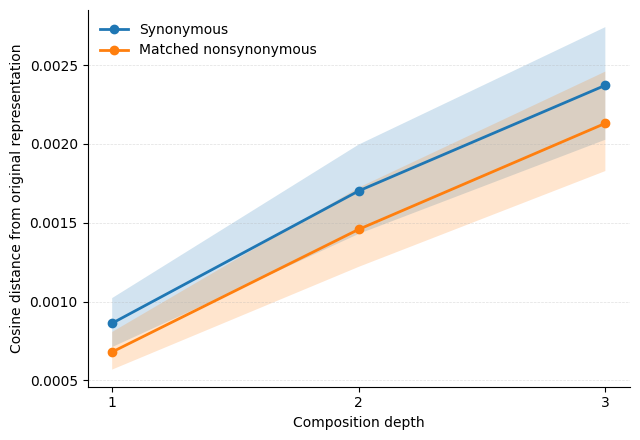

PNG: /content/drive/MyDrive/wiml_equivalence/figures/figure1_depth_vs_distance.png
PDF: /content/drive/MyDrive/wiml_equivalence/figures/figure1_depth_vs_distance.pdf


In [33]:
# STEP 27 — Generate pre-specified primary depth-vs-distance figure

import matplotlib.pyplot as plt
import pandas as pd

plot_df = bootstrap_summary_df.copy()

syn = (
    plot_df[plot_df["condition"] == "synonymous"]
    .sort_values("depth")
)

non = (
    plot_df[plot_df["condition"] == "nonsynonymous"]
    .sort_values("depth")
)

fig, ax = plt.subplots(figsize=(6.5, 4.5))

# Synonymous curve
ax.plot(
    syn["depth"],
    syn["mean"],
    marker="o",
    linewidth=2,
    label="Synonymous",
)

ax.fill_between(
    syn["depth"],
    syn["ci95_low"],
    syn["ci95_high"],
    alpha=0.20,
)

# Matched nonsynonymous curve
ax.plot(
    non["depth"],
    non["mean"],
    marker="o",
    linewidth=2,
    label="Matched nonsynonymous",
)

ax.fill_between(
    non["depth"],
    non["ci95_low"],
    non["ci95_high"],
    alpha=0.20,
)

ax.set_xlabel("Composition depth")
ax.set_ylabel("Cosine distance from original representation")

ax.set_xticks([1, 2, 3])

ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.4,
)

fig.tight_layout()

FIGURE_PNG_PATH = (
    PROJECT_ROOT
    / "figures"
    / "figure1_depth_vs_distance.png"
)

FIGURE_PDF_PATH = (
    PROJECT_ROOT
    / "figures"
    / "figure1_depth_vs_distance.pdf"
)

fig.savefig(
    FIGURE_PNG_PATH,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_PDF_PATH,
    bbox_inches="tight",
)

plt.show()

print("PNG:", FIGURE_PNG_PATH)
print("PDF:", FIGURE_PDF_PATH)

assert FIGURE_PNG_PATH.exists()
assert FIGURE_PDF_PATH.exists()
assert FIGURE_PNG_PATH.stat().st_size > 0
assert FIGURE_PDF_PATH.stat().st_size > 0

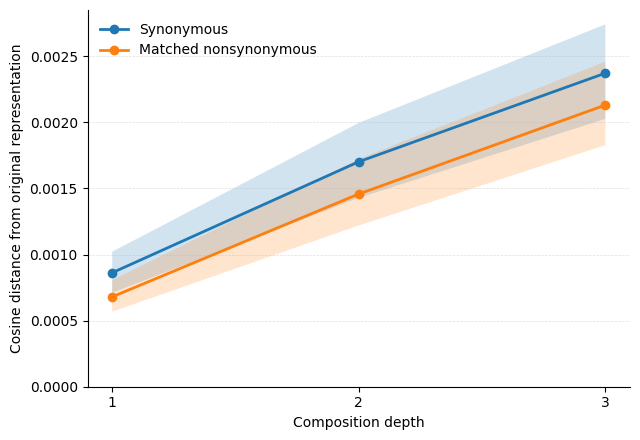

PNG: /content/drive/MyDrive/wiml_equivalence/figures/figure1_depth_vs_distance.png
PDF: /content/drive/MyDrive/wiml_equivalence/figures/figure1_depth_vs_distance.pdf


In [34]:
# STEP 27 — Regenerate primary figure with conservative zero y-axis baseline

import matplotlib.pyplot as plt

plot_df = bootstrap_summary_df.copy()

syn = (
    plot_df[plot_df["condition"] == "synonymous"]
    .sort_values("depth")
)

non = (
    plot_df[plot_df["condition"] == "nonsynonymous"]
    .sort_values("depth")
)

fig, ax = plt.subplots(figsize=(6.5, 4.5))

ax.plot(
    syn["depth"],
    syn["mean"],
    marker="o",
    linewidth=2,
    label="Synonymous",
)

ax.fill_between(
    syn["depth"],
    syn["ci95_low"],
    syn["ci95_high"],
    alpha=0.20,
)

ax.plot(
    non["depth"],
    non["mean"],
    marker="o",
    linewidth=2,
    label="Matched nonsynonymous",
)

ax.fill_between(
    non["depth"],
    non["ci95_low"],
    non["ci95_high"],
    alpha=0.20,
)

ax.set_xlabel("Composition depth")
ax.set_ylabel("Cosine distance from original representation")
ax.set_xticks([1, 2, 3])

# Conservative baseline to avoid visually exaggerating small differences.
ax.set_ylim(bottom=0)

ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.4,
)

fig.tight_layout()

fig.savefig(
    FIGURE_PNG_PATH,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_PDF_PATH,
    bbox_inches="tight",
)

plt.show()

print("PNG:", FIGURE_PNG_PATH)
print("PDF:", FIGURE_PDF_PATH)

assert FIGURE_PNG_PATH.exists()
assert FIGURE_PDF_PATH.exists()
assert FIGURE_PNG_PATH.stat().st_size > 0
assert FIGURE_PDF_PATH.stat().st_size > 0

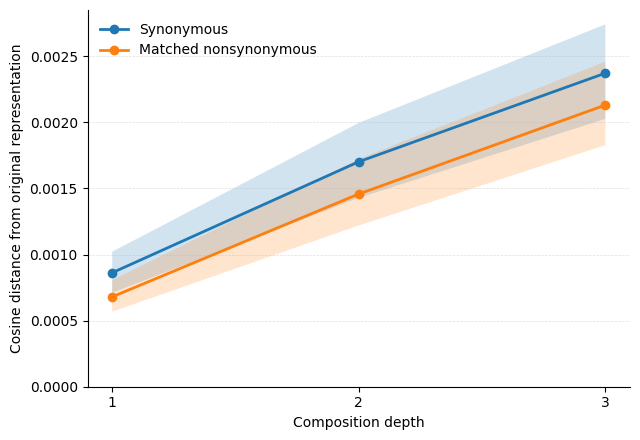

PNG: /content/drive/MyDrive/wiml_equivalence/figures/figure1_depth_vs_distance.png
PDF: /content/drive/MyDrive/wiml_equivalence/figures/figure1_depth_vs_distance.pdf


In [35]:
# STEP 27 — Regenerate primary figure with conservative zero y-axis baseline

import matplotlib.pyplot as plt

plot_df = bootstrap_summary_df.copy()

syn = (
    plot_df[plot_df["condition"] == "synonymous"]
    .sort_values("depth")
)

non = (
    plot_df[plot_df["condition"] == "nonsynonymous"]
    .sort_values("depth")
)

fig, ax = plt.subplots(figsize=(6.5, 4.5))

ax.plot(
    syn["depth"],
    syn["mean"],
    marker="o",
    linewidth=2,
    label="Synonymous",
)

ax.fill_between(
    syn["depth"],
    syn["ci95_low"],
    syn["ci95_high"],
    alpha=0.20,
)

ax.plot(
    non["depth"],
    non["mean"],
    marker="o",
    linewidth=2,
    label="Matched nonsynonymous",
)

ax.fill_between(
    non["depth"],
    non["ci95_low"],
    non["ci95_high"],
    alpha=0.20,
)

ax.set_xlabel("Composition depth")
ax.set_ylabel("Cosine distance from original representation")
ax.set_xticks([1, 2, 3])

# Conservative baseline to avoid visually exaggerating small differences.
ax.set_ylim(bottom=0)

ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.4,
)

fig.tight_layout()

fig.savefig(
    FIGURE_PNG_PATH,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_PDF_PATH,
    bbox_inches="tight",
)

plt.show()

print("PNG:", FIGURE_PNG_PATH)
print("PDF:", FIGURE_PDF_PATH)

assert FIGURE_PNG_PATH.exists()
assert FIGURE_PDF_PATH.exists()
assert FIGURE_PNG_PATH.stat().st_size > 0
assert FIGURE_PDF_PATH.stat().st_size > 0

In [36]:
# STEP 28 — Final reproducibility metadata and artifact verification

import json
import sys
import platform
import importlib.metadata as metadata
from pathlib import Path
from datetime import datetime, timezone

experiment_metadata = {
    "analysis_label": "PRE-SPECIFIED PILOT",
    "model_id": MODEL_ID,
    "model_class": model.__class__.__name__,
    "model_commit_hash": getattr(model.config, "_commit_hash", None),
    "tokenizer_class": tokenizer.__class__.__name__,
    "tokenizer_commit_hash": getattr(tokenizer, "_commit_hash", None),
    "model_context_tokens": 250,
    "embedding_dimension": 256,
    "representation": (
        "Final hidden-state mean pooling over attention-valid "
        "non-special biological tokens"
    ),
    "primary_distance": "cosine_distance",
    "seed": 42,
    "n_source_sequences": 300,
    "composition_depths": [1, 2, 3],
    "bootstrap_resamples": 10000,
    "bootstrap_unit": "source_sequence",
    "python_version": sys.version.split()[0],
    "platform": platform.platform(),
    "torch_version": metadata.version("torch"),
    "transformers_version": metadata.version("transformers"),
    "tokenizers_version": metadata.version("tokenizers"),
    "datasets_version": metadata.version("datasets"),
    "numpy_version": metadata.version("numpy"),
    "pandas_version": metadata.version("pandas"),
    "cuda_available": bool(torch.cuda.is_available()),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "allow_truncation": False,
    "created_utc": datetime.now(timezone.utc).isoformat(),
}

EXPERIMENT_METADATA_PATH = (
    PROJECT_ROOT / "metadata" / "experiment_metadata.json"
)

with open(EXPERIMENT_METADATA_PATH, "w") as f:
    json.dump(experiment_metadata, f, indent=2)


decision_log = [
    "D001: Clean CDSs restricted to conventional nuclear protein-coding CDSs using the standard genetic code.",
    "D002: Exact duplicate CDS sequences removed before sampling.",
    "D003: Final sequence eligibility determined using actual Omni-DNA tokenizer length.",
    "D004: Every synonymous variant validated by full-CDS retranslation.",
    "D005: Composition paths use distinct codon sites at depths 1, 2, and 3.",
    "D006: Nonsynonymous controls match codon position and per-step nucleotide Hamming distance.",
    "D007: Omni-DNA eligibility uses actual tokenizer length with a 250-token context.",
    "D008: No truncation permitted.",
    "D009: Transformers 4.48.3 used because Transformers 5.13.1 was incompatible with Omni-DNA custom model loading.",
    "D010: Primary representation fixed as final hidden-state mean pooling over non-special biological tokens.",
    "D011: All generated variants independently checked for context eligibility.",
    "D012: Smoke-test CDSs used context headroom only for pipeline validation.",
    "D013: Smoke-test distances treated as diagnostic only.",
    "D014: Primary pilot uses at most one CDS per Ensembl gene.",
    "D015: Primary pilot requires CDS length >= 300 nt.",
    "D016: Primary pilot size fixed at N=300 before full-pilot distance analysis.",
    "D017: All 300 synonymous composition paths completed with no exclusions.",
    "D018: Actual nucleotide edit distance retained as an explicit diagnostic variable.",
    "D019: All 900 nonsynonymous observations are exactly edit-matched to synonymous counterparts.",
    "D020: Full inference batch size fixed at 32 after GPU-memory validation.",
    "D021: Difference-in-differences does not support faster synonymous-specific drift across depth.",
]

DECISION_LOG_PATH = (
    PROJECT_ROOT / "logs" / "decision_log.txt"
)

with open(DECISION_LOG_PATH, "w") as f:
    f.write("\n".join(decision_log) + "\n")


expected_artifacts = {
    "source_metadata":
        PROJECT_ROOT / "metadata" / "source_metadata.json",

    "pilot_design":
        PROJECT_ROOT / "metadata" / "pilot_design.json",

    "experiment_metadata":
        EXPERIMENT_METADATA_PATH,

    "decision_log":
        DECISION_LOG_PATH,

    "original_sequences":
        PROJECT_ROOT / "data" / "processed" / "original_sequences.csv",

    "synonymous_variants":
        PROJECT_ROOT / "data" / "processed" / "synonymous_variants.csv",

    "nonsynonymous_controls":
        PROJECT_ROOT / "data" / "processed" / "nonsynonymous_controls.csv",

    "transformation_metadata":
        PROJECT_ROOT / "metadata" / "transformation_metadata.csv",

    "embeddings":
        PROJECT_ROOT / "embeddings" / "omnidna20m_pilot_embeddings.pt",

    "embedding_metadata":
        PROJECT_ROOT / "embeddings" / "omnidna20m_pilot_embedding_metadata.csv",

    "distance_results":
        PROJECT_ROOT / "results" / "distance_results.csv",

    "bootstrap_summary":
        PROJECT_ROOT / "results" / "bootstrap_summary.csv",

    "paired_condition_differences":
        PROJECT_ROOT / "results" / "paired_condition_differences.csv",

    "edit_distance_summary":
        PROJECT_ROOT / "results" / "edit_distance_summary.csv",

    "edit_distance_correlations":
        PROJECT_ROOT / "results" / "edit_distance_correlations.csv",

    "depth_contrasts":
        PROJECT_ROOT / "results" / "bootstrap_depth_contrasts.csv",

    "difference_in_differences":
        PROJECT_ROOT / "results" / "bootstrap_difference_in_differences.csv",

    "figure_png":
        PROJECT_ROOT / "figures" / "figure1_depth_vs_distance.png",

    "figure_pdf":
        PROJECT_ROOT / "figures" / "figure1_depth_vs_distance.pdf",
}

artifact_rows = []

for name, path in expected_artifacts.items():
    exists = path.exists()
    size_bytes = path.stat().st_size if exists else 0

    artifact_rows.append({
        "artifact": name,
        "path": str(path),
        "exists": exists,
        "size_bytes": size_bytes,
    })

artifact_manifest_df = pd.DataFrame(artifact_rows)

ARTIFACT_MANIFEST_PATH = (
    PROJECT_ROOT / "metadata" / "artifact_manifest.csv"
)

artifact_manifest_df.to_csv(
    ARTIFACT_MANIFEST_PATH,
    index=False
)

print("Experiment metadata:")
print(json.dumps(experiment_metadata, indent=2))

print("\nArtifact verification:")
print(
    artifact_manifest_df[
        ["artifact", "exists", "size_bytes"]
    ].to_string(index=False)
)

print("\nArtifacts present:",
      int(artifact_manifest_df["exists"].sum()),
      "/",
      len(artifact_manifest_df))

print("\nManifest:")
print(ARTIFACT_MANIFEST_PATH)

assert artifact_manifest_df["exists"].all()
assert (artifact_manifest_df["size_bytes"] > 0).all()

Experiment metadata:
{
  "analysis_label": "PRE-SPECIFIED PILOT",
  "model_id": "zehui127/Omni-DNA-20M",
  "model_class": "OLMoForCausalLM",
  "model_commit_hash": "3b64e6a5ed6c8f72bad76823ce728b3045243026",
  "tokenizer_class": "PreTrainedTokenizerFast",
  "tokenizer_commit_hash": null,
  "model_context_tokens": 250,
  "embedding_dimension": 256,
  "representation": "Final hidden-state mean pooling over attention-valid non-special biological tokens",
  "primary_distance": "cosine_distance",
  "seed": 42,
  "n_source_sequences": 300,
  "composition_depths": [
    1,
    2,
    3
  ],
  "bootstrap_resamples": 10000,
  "bootstrap_unit": "source_sequence",
  "python_version": "3.12.13",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.35",
  "torch_version": "2.11.0+cu128",
  "transformers_version": "4.48.3",
  "tokenizers_version": "0.21.0",
  "datasets_version": "4.0.0",
  "numpy_version": "2.5.2",
  "pandas_version": "2.2.3",
  "cuda_available": true,
  "gpu_name": "Tesla T4",
  "allow

In [37]:
# EXTENSION 1 — Freeze source cohort for structural equivalence experiments

import pandas as pd
from pathlib import Path

SEED = 42
STRUCTURAL_N = 100
N_PATHS = 10
PATH_DEPTH = 3

# Use only sources from the already-frozen 300-CDS pilot.
# Add modest context headroom because many new variants will be generated.
STRUCTURAL_SOURCE_TOKEN_LIMIT = 235

structural_candidate_df = pilot_source_df[
    pilot_source_df["omnidna_token_length"]
    <= STRUCTURAL_SOURCE_TOKEN_LIMIT
].copy()

assert len(structural_candidate_df) >= STRUCTURAL_N

structural_source_df = (
    structural_candidate_df
    .sample(
        n=STRUCTURAL_N,
        random_state=SEED,
    )
    .reset_index(drop=True)
)

STRUCTURAL_SOURCE_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "structural_extension_sources.csv"
)

structural_source_df.to_csv(
    STRUCTURAL_SOURCE_PATH,
    index=False,
)

print("Eligible frozen-pilot sources:", len(structural_candidate_df))
print("Structural extension sources :", len(structural_source_df))
print("Paths planned per source     :", N_PATHS)
print("Composition depth            :", PATH_DEPTH)

print("\nSource token-length summary:")
print(
    structural_source_df["omnidna_token_length"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

print("\nSource nucleotide-length summary:")
print(
    structural_source_df["sequence_length"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

print("\nUniqueness:")
print(
    "Unique genes       :",
    structural_source_df["gene_id"].nunique()
)
print(
    "Unique transcripts :",
    structural_source_df["sequence_id"].nunique()
)
print(
    "Unique sequences   :",
    structural_source_df["original_sequence"].nunique()
)

print("\nSaved to:")
print(STRUCTURAL_SOURCE_PATH)

assert len(structural_source_df) == STRUCTURAL_N
assert structural_source_df["gene_id"].nunique() == STRUCTURAL_N
assert structural_source_df["sequence_id"].nunique() == STRUCTURAL_N
assert structural_source_df["original_sequence"].nunique() == STRUCTURAL_N
assert (
    structural_source_df["omnidna_token_length"]
    <= STRUCTURAL_SOURCE_TOKEN_LIMIT
).all()
assert (
    structural_source_df["num_synonymous_editable_codons"]
    >= PATH_DEPTH
).all()

Eligible frozen-pilot sources: 280
Structural extension sources : 100
Paths planned per source     : 10
Composition depth            : 3

Source token-length summary:
count    100.000000
mean     139.120000
std       51.123791
min       62.000000
25%       94.500000
50%      140.500000
75%      179.500000
90%      214.000000
95%      219.000000
max      234.000000
Name: omnidna_token_length, dtype: float64

Source nucleotide-length summary:
count     100.000000
mean      668.160000
std       249.345354
min       300.000000
25%       446.250000
50%       681.000000
75%       879.750000
90%      1017.600000
95%      1083.000000
max      1101.000000
Name: sequence_length, dtype: float64

Uniqueness:
Unique genes       : 100
Unique transcripts : 100
Unique sequences   : 100

Saved to:
/content/drive/MyDrive/wiml_equivalence/data/processed/structural_extension_sources.csv


In [38]:
# EXTENSION 1 — Generate 10 distinct synonymous paths per source

import random
import pandas as pd

structural_variant_records = []
structural_edit_records = []
structural_failures = []

for source_idx, row in structural_source_df.iterrows():
    sequence_id = row["sequence_id"]
    original_seq = row["original_sequence"]
    original_protein = translate_cds(original_seq)

    source_endpoint_sequences = set()

    for path_id in range(N_PATHS):
        # Independent deterministic RNG stream for each source/path.
        rng = random.Random(
            SEED + source_idx * 1000 + path_id
        )

        current_seq = original_seq
        edited_codon_indices = set()

        path_variant_records = []
        path_edit_records = []

        try:
            for depth in range(1, PATH_DEPTH + 1):
                previous_seq = current_seq

                current_seq, edit = make_one_synonymous_edit(
                    current_seq,
                    rng,
                    excluded_codon_indices=edited_codon_indices,
                )

                edited_codon_indices.add(edit["codon_index"])

                current_protein = translate_cds(current_seq)

                if current_protein != original_protein:
                    raise ValueError(
                        f"Translation mismatch at path={path_id}, depth={depth}"
                    )

                step_nt_distance = sum(
                    a != b
                    for a, b in zip(previous_seq, current_seq)
                )

                cumulative_nt_distance = sum(
                    a != b
                    for a, b in zip(original_seq, current_seq)
                )

                token_length = len(
                    tokenizer(
                        current_seq,
                        add_special_tokens=True,
                        truncation=False,
                    )["input_ids"]
                )

                if token_length > 250:
                    raise ValueError(
                        f"Context overflow at path={path_id}, "
                        f"depth={depth}: {token_length} tokens"
                    )

                path_variant_records.append({
                    "sequence_id": sequence_id,
                    "path_id": path_id,
                    "depth": depth,
                    "original_sequence": original_seq,
                    "variant_sequence": current_seq,
                    "sequence_length": len(original_seq),
                    "edited_codons": depth,
                    "nucleotide_edit_distance": cumulative_nt_distance,
                    "fraction_sequence_changed":
                        cumulative_nt_distance / len(original_seq),
                    "translation_equal": True,
                    "omnidna_token_length": token_length,
                })

                path_edit_records.append({
                    "sequence_id": sequence_id,
                    "path_id": path_id,
                    "depth": depth,
                    "edit_number": depth,
                    "codon_index": edit["codon_index"],
                    "nt_position": edit["nt_position"],
                    "original_codon": edit["original_codon"],
                    "new_codon": edit["new_codon"],
                    "original_aa": edit["original_aa"],
                    "new_aa": edit["new_aa"],
                    "step_nt_edit_distance": step_nt_distance,
                })

            endpoint = current_seq

            if endpoint in source_endpoint_sequences:
                raise ValueError(
                    f"Duplicate depth-{PATH_DEPTH} endpoint for path {path_id}"
                )

            source_endpoint_sequences.add(endpoint)

            structural_variant_records.extend(path_variant_records)
            structural_edit_records.extend(path_edit_records)

        except Exception as e:
            structural_failures.append({
                "sequence_id": sequence_id,
                "path_id": path_id,
                "error": str(e),
            })


structural_synonymous_variants_df = pd.DataFrame(
    structural_variant_records
)

structural_synonymous_edits_df = pd.DataFrame(
    structural_edit_records
)

structural_failures_df = pd.DataFrame(
    structural_failures
)


expected_paths = STRUCTURAL_N * N_PATHS
expected_variants = expected_paths * PATH_DEPTH

complete_paths = (
    structural_synonymous_variants_df
    .groupby(["sequence_id", "path_id"])["depth"]
    .nunique()
    .eq(PATH_DEPTH)
    .sum()
)

endpoint_df = structural_synonymous_variants_df[
    structural_synonymous_variants_df["depth"] == PATH_DEPTH
]

unique_endpoints_per_source = (
    endpoint_df
    .groupby("sequence_id")["variant_sequence"]
    .nunique()
)

print("Sources attempted       :", STRUCTURAL_N)
print("Paths attempted         :", expected_paths)
print("Complete paths          :", int(complete_paths))
print("Variant rows created    :", len(structural_synonymous_variants_df))
print("Edit rows created       :", len(structural_synonymous_edits_df))
print("Failed paths            :", len(structural_failures_df))

if len(structural_failures_df):
    print("\nFailure reasons:")
    print(
        structural_failures_df["error"]
        .value_counts()
        .head(20)
    )

print("\nUnique depth-3 endpoints per source:")
print(unique_endpoints_per_source.describe())

print("\nToken lengths:")
print(
    structural_synonymous_variants_df[
        "omnidna_token_length"
    ].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)

print("\nNucleotide edit distance at depth 3:")
print(
    endpoint_df[
        "nucleotide_edit_distance"
    ].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)

assert len(structural_synonymous_variants_df) == expected_variants
assert len(structural_synonymous_edits_df) == expected_variants
assert int(complete_paths) == expected_paths
assert len(structural_failures_df) == 0

assert structural_synonymous_variants_df[
    "translation_equal"
].all()

assert (
    structural_synonymous_variants_df[
        "omnidna_token_length"
    ] <= 250
).all()

assert (
    unique_endpoints_per_source == N_PATHS
).all()

Sources attempted       : 100
Paths attempted         : 1000
Complete paths          : 1000
Variant rows created    : 3000
Edit rows created       : 3000
Failed paths            : 0

Unique depth-3 endpoints per source:
count    100.0
mean      10.0
std        0.0
min       10.0
25%       10.0
50%       10.0
75%       10.0
max       10.0
Name: variant_sequence, dtype: float64

Token lengths:
count    3000.000000
mean      139.192333
std        50.907031
min        62.000000
50%       141.000000
90%       214.000000
95%       219.000000
99%       227.060000
max       236.000000
Name: omnidna_token_length, dtype: float64

Nucleotide edit distance at depth 3:
count    1000.000000
mean        3.400000
std         0.725621
min         3.000000
50%         3.000000
90%         5.000000
95%         5.000000
99%         6.000000
max         7.000000
Name: nucleotide_edit_distance, dtype: float64


In [39]:
# EXTENSION 1 — Generate path-matched nonsynonymous controls

import random
import pandas as pd

structural_non_variant_records = []
structural_non_edit_records = []
structural_non_failures = []

for source_idx, row in structural_source_df.iterrows():
    sequence_id = row["sequence_id"]
    original_seq = row["original_sequence"]
    original_protein = translate_cds(original_seq)

    for path_id in range(N_PATHS):

        syn_edits = (
            structural_synonymous_edits_df[
                (structural_synonymous_edits_df["sequence_id"] == sequence_id)
                &
                (structural_synonymous_edits_df["path_id"] == path_id)
            ]
            .sort_values("depth")
        )

        assert len(syn_edits) == PATH_DEPTH

        rng = random.Random(
            SEED + 1_000_000 + source_idx * 1000 + path_id
        )

        current_seq = original_seq
        local_variant_records = []
        local_edit_records = []

        try:
            for _, syn_edit in syn_edits.iterrows():

                depth = int(syn_edit["depth"])
                codon_index = int(syn_edit["codon_index"])
                nt_position = int(syn_edit["nt_position"])
                target_step_nt_distance = int(
                    syn_edit["step_nt_edit_distance"]
                )

                previous_seq = current_seq

                original_codon = current_seq[
                    nt_position:nt_position + 3
                ]

                if original_codon != syn_edit["original_codon"]:
                    raise ValueError(
                        f"Unexpected codon state at path={path_id}, depth={depth}"
                    )

                matched_codons = get_matched_nonsynonymous_codons(
                    original_codon,
                    target_step_nt_distance,
                )

                if not matched_codons:
                    raise ValueError(
                        f"No exact control match at path={path_id}, "
                        f"depth={depth}, codon={original_codon}, "
                        f"distance={target_step_nt_distance}"
                    )

                new_codon = rng.choice(matched_codons)

                seq_list = list(current_seq)
                seq_list[
                    nt_position:nt_position + 3
                ] = list(new_codon)

                current_seq = "".join(seq_list)

                current_protein = translate_cds(current_seq)

                step_nt_distance = sum(
                    a != b
                    for a, b in zip(previous_seq, current_seq)
                )

                cumulative_nt_distance = sum(
                    a != b
                    for a, b in zip(original_seq, current_seq)
                )

                token_length = len(
                    tokenizer(
                        current_seq,
                        add_special_tokens=True,
                        truncation=False,
                    )["input_ids"]
                )

                if current_protein == original_protein:
                    raise ValueError(
                        f"Protein unchanged at path={path_id}, depth={depth}"
                    )

                if CODON_TO_AA[new_codon] == "*":
                    raise ValueError(
                        f"Stop introduced at path={path_id}, depth={depth}"
                    )

                if step_nt_distance != target_step_nt_distance:
                    raise ValueError(
                        f"Step edit mismatch at path={path_id}, depth={depth}"
                    )

                if token_length > 250:
                    raise ValueError(
                        f"Context overflow at path={path_id}, "
                        f"depth={depth}: {token_length}"
                    )

                local_variant_records.append({
                    "sequence_id": sequence_id,
                    "path_id": path_id,
                    "depth": depth,
                    "original_sequence": original_seq,
                    "variant_sequence": current_seq,
                    "sequence_length": len(original_seq),
                    "edited_codons": depth,
                    "nucleotide_edit_distance":
                        cumulative_nt_distance,
                    "fraction_sequence_changed":
                        cumulative_nt_distance / len(original_seq),
                    "translation_equal": False,
                    "omnidna_token_length": token_length,
                })

                local_edit_records.append({
                    "sequence_id": sequence_id,
                    "path_id": path_id,
                    "depth": depth,
                    "edit_number": depth,
                    "codon_index": codon_index,
                    "nt_position": nt_position,
                    "original_codon": original_codon,
                    "new_codon": new_codon,
                    "original_aa": CODON_TO_AA[original_codon],
                    "new_aa": CODON_TO_AA[new_codon],
                    "step_nt_edit_distance": step_nt_distance,
                    "matched_syn_step_nt_distance":
                        target_step_nt_distance,
                })

            structural_non_variant_records.extend(
                local_variant_records
            )
            structural_non_edit_records.extend(
                local_edit_records
            )

        except Exception as e:
            structural_non_failures.append({
                "sequence_id": sequence_id,
                "path_id": path_id,
                "error": str(e),
            })


structural_nonsynonymous_variants_df = pd.DataFrame(
    structural_non_variant_records
)

structural_nonsynonymous_edits_df = pd.DataFrame(
    structural_non_edit_records
)

structural_non_failures_df = pd.DataFrame(
    structural_non_failures
)


syn_depth3 = (
    structural_synonymous_variants_df[
        structural_synonymous_variants_df["depth"] == 3
    ][
        [
            "sequence_id",
            "path_id",
            "nucleotide_edit_distance",
        ]
    ]
    .rename(
        columns={
            "nucleotide_edit_distance": "syn_nt_distance"
        }
    )
)

non_depth3 = (
    structural_nonsynonymous_variants_df[
        structural_nonsynonymous_variants_df["depth"] == 3
    ][
        [
            "sequence_id",
            "path_id",
            "nucleotide_edit_distance",
        ]
    ]
    .rename(
        columns={
            "nucleotide_edit_distance": "non_nt_distance"
        }
    )
)

endpoint_match = syn_depth3.merge(
    non_depth3,
    on=["sequence_id", "path_id"],
    validate="one_to_one",
)

endpoint_match["difference"] = (
    endpoint_match["non_nt_distance"]
    - endpoint_match["syn_nt_distance"]
)


print("Control paths attempted :", STRUCTURAL_N * N_PATHS)
print(
    "Complete control paths  :",
    structural_nonsynonymous_variants_df
    .groupby(["sequence_id", "path_id"])["depth"]
    .nunique()
    .eq(PATH_DEPTH)
    .sum()
)
print(
    "Control variant rows    :",
    len(structural_nonsynonymous_variants_df)
)
print(
    "Control edit rows       :",
    len(structural_nonsynonymous_edits_df)
)
print(
    "Failed control paths    :",
    len(structural_non_failures_df)
)

if len(structural_non_failures_df):
    print("\nFailure reasons:")
    print(
        structural_non_failures_df["error"]
        .value_counts()
        .head(20)
    )

print("\nDepth-3 edit matching:")
print(
    endpoint_match["difference"]
    .value_counts()
    .sort_index()
)

print("\nControl token lengths:")
print(
    structural_nonsynonymous_variants_df[
        "omnidna_token_length"
    ].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)

assert len(structural_nonsynonymous_variants_df) == 3000
assert len(structural_nonsynonymous_edits_df) == 3000
assert len(structural_non_failures_df) == 0
assert (endpoint_match["difference"] == 0).all()
assert not structural_nonsynonymous_variants_df[
    "translation_equal"
].any()
assert (
    structural_nonsynonymous_variants_df[
        "omnidna_token_length"
    ] <= 250
).all()

Control paths attempted : 1000
Complete control paths  : 1000
Control variant rows    : 3000
Control edit rows       : 3000
Failed control paths    : 0

Depth-3 edit matching:
difference
0    1000
Name: count, dtype: int64

Control token lengths:
count    3000.000000
mean      139.169333
std        50.864641
min        61.000000
50%       141.000000
90%       214.000000
95%       219.000000
99%       227.050000
max       236.000000
Name: omnidna_token_length, dtype: float64


In [40]:
# Save and verify structural-extension transformation artifacts

import pandas as pd

STRUCTURAL_SYN_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "structural_synonymous_variants.csv"
)

STRUCTURAL_NON_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "structural_nonsynonymous_controls.csv"
)

STRUCTURAL_AUDIT_PATH = (
    PROJECT_ROOT
    / "metadata"
    / "structural_transformation_metadata.csv"
)

structural_synonymous_variants_df.to_csv(
    STRUCTURAL_SYN_PATH,
    index=False,
)

structural_nonsynonymous_variants_df.to_csv(
    STRUCTURAL_NON_PATH,
    index=False,
)

syn_audit = structural_synonymous_edits_df.copy()
syn_audit["condition"] = "synonymous"

non_audit = structural_nonsynonymous_edits_df.copy()
non_audit["condition"] = "nonsynonymous"

structural_transformation_metadata_df = pd.concat(
    [syn_audit, non_audit],
    ignore_index=True,
    sort=False,
)

structural_transformation_metadata_df.to_csv(
    STRUCTURAL_AUDIT_PATH,
    index=False,
)

# Read back from Drive.
check_sources = pd.read_csv(
    STRUCTURAL_SOURCE_PATH,
    dtype={"chromosome": str},
)

check_syn = pd.read_csv(STRUCTURAL_SYN_PATH)
check_non = pd.read_csv(STRUCTURAL_NON_PATH)
check_audit = pd.read_csv(STRUCTURAL_AUDIT_PATH)

print("Structural sources       :", len(check_sources))
print("Synonymous variants      :", len(check_syn))
print("Nonsynonymous controls   :", len(check_non))
print("Transformation audit rows:", len(check_audit))

print("\nUnique paths:")
print(
    "Synonymous    :",
    check_syn[
        ["sequence_id", "path_id"]
    ].drop_duplicates().shape[0]
)
print(
    "Nonsynonymous :",
    check_non[
        ["sequence_id", "path_id"]
    ].drop_duplicates().shape[0]
)

print("\nDepth counts — synonymous:")
print(
    check_syn["depth"]
    .value_counts()
    .sort_index()
)

print("\nDepth counts — nonsynonymous:")
print(
    check_non["depth"]
    .value_counts()
    .sort_index()
)

print("\nAudit rows by condition:")
print(
    check_audit["condition"]
    .value_counts()
)

print("\nMaximum token lengths:")
print(
    "Original       :",
    int(check_sources["omnidna_token_length"].max())
)
print(
    "Synonymous     :",
    int(check_syn["omnidna_token_length"].max())
)
print(
    "Nonsynonymous  :",
    int(check_non["omnidna_token_length"].max())
)

assert len(check_sources) == 100
assert len(check_syn) == 3000
assert len(check_non) == 3000
assert len(check_audit) == 6000

assert (
    check_syn[
        ["sequence_id", "path_id"]
    ].drop_duplicates().shape[0]
    == 1000
)

assert (
    check_non[
        ["sequence_id", "path_id"]
    ].drop_duplicates().shape[0]
    == 1000
)

assert check_syn["translation_equal"].all()
assert not check_non["translation_equal"].any()

assert check_syn["omnidna_token_length"].max() <= 250
assert check_non["omnidna_token_length"].max() <= 250

assert set(check_audit["condition"]) == {
    "synonymous",
    "nonsynonymous",
}

Structural sources       : 100
Synonymous variants      : 3000
Nonsynonymous controls   : 3000
Transformation audit rows: 6000

Unique paths:
Synonymous    : 1000
Nonsynonymous : 1000

Depth counts — synonymous:
depth
1    1000
2    1000
3    1000
Name: count, dtype: int64

Depth counts — nonsynonymous:
depth
1    1000
2    1000
3    1000
Name: count, dtype: int64

Audit rows by condition:
condition
synonymous       3000
nonsynonymous    3000
Name: count, dtype: int64

Maximum token lengths:
Original       : 234
Synonymous     : 236
Nonsynonymous  : 236


In [41]:
# EXTENSION 1–3 — Embed all structural-extension sequences with Omni-DNA-20M

import pandas as pd
import torch

structural_embedding_inputs = []

# 100 originals
for _, row in structural_source_df.iterrows():
    structural_embedding_inputs.append({
        "sequence_id": row["sequence_id"],
        "path_id": -1,
        "condition": "original",
        "depth": 0,
        "sequence": row["original_sequence"],
    })

# 3000 synonymous variants
for _, row in structural_synonymous_variants_df.iterrows():
    structural_embedding_inputs.append({
        "sequence_id": row["sequence_id"],
        "path_id": int(row["path_id"]),
        "condition": "synonymous",
        "depth": int(row["depth"]),
        "sequence": row["variant_sequence"],
    })

# 3000 matched nonsynonymous variants
for _, row in structural_nonsynonymous_variants_df.iterrows():
    structural_embedding_inputs.append({
        "sequence_id": row["sequence_id"],
        "path_id": int(row["path_id"]),
        "condition": "nonsynonymous",
        "depth": int(row["depth"]),
        "sequence": row["variant_sequence"],
    })

structural_embedding_input_df = pd.DataFrame(
    structural_embedding_inputs
)

assert len(structural_embedding_input_df) == 6100

# Recheck actual token lengths without truncation.
token_lengths = []

for sequence in structural_embedding_input_df["sequence"]:
    encoded = tokenizer(
        sequence,
        add_special_tokens=True,
        truncation=False,
        return_attention_mask=False,
    )
    token_lengths.append(len(encoded["input_ids"]))

structural_embedding_input_df["token_length"] = token_lengths

assert structural_embedding_input_df["token_length"].max() <= 250

STRUCTURAL_BATCH_SIZE = 32
embedding_batches = []

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

model.eval()

for start in range(
    0,
    len(structural_embedding_input_df),
    STRUCTURAL_BATCH_SIZE,
):
    batch_df = structural_embedding_input_df.iloc[
        start:start + STRUCTURAL_BATCH_SIZE
    ]

    encoded = tokenizer(
        batch_df["sequence"].tolist(),
        return_tensors="pt",
        padding=True,
        truncation=False,
        add_special_tokens=True,
        return_attention_mask=True,
    )

    input_ids = encoded["input_ids"]
    attention_mask = encoded["attention_mask"].bool()

    biological_mask = attention_mask.clone()

    for special_id in SPECIAL_TOKEN_IDS:
        biological_mask &= input_ids.ne(special_id)

    assert biological_mask.sum(dim=1).min().item() > 0

    encoded_cuda = {
        key: value.to("cuda")
        for key, value in encoded.items()
    }

    biological_mask_cuda = biological_mask.to("cuda")

    with torch.inference_mode():
        outputs = model(
            **encoded_cuda,
            output_hidden_states=True,
            return_dict=True,
        )

        final_hidden = outputs.hidden_states[-1]

        pooled = (
            final_hidden
            * biological_mask_cuda.unsqueeze(-1)
        ).sum(dim=1) / biological_mask_cuda.sum(
            dim=1,
            keepdim=True
        )

    embedding_batches.append(
        pooled.detach().cpu()
    )

    del outputs
    del final_hidden
    del pooled
    del encoded_cuda
    del biological_mask_cuda

structural_embedding_matrix = torch.cat(
    embedding_batches,
    dim=0,
)

peak_memory_gb = (
    torch.cuda.max_memory_allocated()
    / (1024 ** 3)
)

print("Sequences embedded :", structural_embedding_matrix.shape[0])
print("Embedding dimension:", structural_embedding_matrix.shape[1])
print("Matrix shape       :", tuple(structural_embedding_matrix.shape))
print("Contains NaN       :", torch.isnan(structural_embedding_matrix).any().item())
print("Contains Inf       :", torch.isinf(structural_embedding_matrix).any().item())
print("Peak CUDA memory GB:", round(peak_memory_gb, 3))

STRUCTURAL_EMBEDDING_PATH = (
    PROJECT_ROOT
    / "embeddings"
    / "omnidna20m_structural_embeddings.pt"
)

STRUCTURAL_EMBEDDING_METADATA_PATH = (
    PROJECT_ROOT
    / "embeddings"
    / "omnidna20m_structural_embedding_metadata.csv"
)

torch.save(
    structural_embedding_matrix,
    STRUCTURAL_EMBEDDING_PATH,
)

structural_embedding_metadata_df = (
    structural_embedding_input_df[
        [
            "sequence_id",
            "path_id",
            "condition",
            "depth",
            "token_length",
        ]
    ]
    .copy()
)

structural_embedding_metadata_df["embedding_index"] = range(
    len(structural_embedding_metadata_df)
)

structural_embedding_metadata_df.to_csv(
    STRUCTURAL_EMBEDDING_METADATA_PATH,
    index=False,
)

# Read back for integrity.
check_matrix = torch.load(
    STRUCTURAL_EMBEDDING_PATH,
    map_location="cpu",
    weights_only=True,
)

check_metadata = pd.read_csv(
    STRUCTURAL_EMBEDDING_METADATA_PATH
)

print("\nRows by condition:")
print(
    check_metadata["condition"]
    .value_counts()
)

print("\nSaved:")
print(STRUCTURAL_EMBEDDING_PATH)
print(STRUCTURAL_EMBEDDING_METADATA_PATH)

assert check_matrix.shape == (6100, 256)
assert len(check_metadata) == 6100
assert not torch.isnan(check_matrix).any()
assert not torch.isinf(check_matrix).any()

assert (
    check_metadata["embedding_index"].tolist()
    == list(range(6100))
)

assert (
    check_metadata["condition"].value_counts().to_dict()
    ==
    {
        "synonymous": 3000,
        "nonsynonymous": 3000,
        "original": 100,
    }
)

Sequences embedded : 6100
Embedding dimension: 256
Matrix shape       : (6100, 256)
Contains NaN       : False
Contains Inf       : False
Peak CUDA memory GB: 0.436

Rows by condition:
condition
synonymous       3000
nonsynonymous    3000
original          100
Name: count, dtype: int64

Saved:
/content/drive/MyDrive/wiml_equivalence/embeddings/omnidna20m_structural_embeddings.pt
/content/drive/MyDrive/wiml_equivalence/embeddings/omnidna20m_structural_embedding_metadata.csv


In [42]:
# EXTENSION 1 — Multiple-path consistency at depth-3 endpoints

import itertools
import numpy as np
import pandas as pd
import torch

# Work only with the 10 distinct depth-3 endpoints per source.
syn_endpoint_seq_df = (
    structural_synonymous_variants_df[
        structural_synonymous_variants_df["depth"] == 3
    ][
        ["sequence_id", "path_id", "variant_sequence"]
    ]
    .copy()
)

non_endpoint_seq_df = (
    structural_nonsynonymous_variants_df[
        structural_nonsynonymous_variants_df["depth"] == 3
    ][
        ["sequence_id", "path_id", "variant_sequence"]
    ]
    .copy()
)

# Map each structural embedding row to its stored embedding.
meta = structural_embedding_metadata_df.copy()

embedding_lookup = {
    (
        row.sequence_id,
        row.condition,
        int(row.path_id),
        int(row.depth),
    ): int(row.embedding_index)
    for row in meta.itertuples()
}

# Normalize once so cosine distance = 1 - dot product.
emb = structural_embedding_matrix.float()

emb_norm = emb / emb.norm(
    dim=1,
    keepdim=True,
).clamp_min(1e-12)


def nucleotide_hamming(seq_a, seq_b):
    assert len(seq_a) == len(seq_b)
    return sum(a != b for a, b in zip(seq_a, seq_b))


pair_records = []

for condition, endpoint_df in [
    ("synonymous", syn_endpoint_seq_df),
    ("nonsynonymous", non_endpoint_seq_df),
]:

    for sequence_id, source_df in endpoint_df.groupby("sequence_id"):

        source_df = source_df.sort_values("path_id")

        assert len(source_df) == N_PATHS
        assert source_df["path_id"].nunique() == N_PATHS

        endpoint_rows = {
            int(row.path_id): row
            for row in source_df.itertuples()
        }

        for path_a, path_b in itertools.combinations(
            range(N_PATHS),
            2,
        ):
            row_a = endpoint_rows[path_a]
            row_b = endpoint_rows[path_b]

            idx_a = embedding_lookup[
                (
                    sequence_id,
                    condition,
                    path_a,
                    3,
                )
            ]

            idx_b = embedding_lookup[
                (
                    sequence_id,
                    condition,
                    path_b,
                    3,
                )
            ]

            cosine_similarity = float(
                torch.dot(
                    emb_norm[idx_a],
                    emb_norm[idx_b],
                )
            )

            cosine_distance = 1.0 - cosine_similarity

            nt_pair_distance = nucleotide_hamming(
                row_a.variant_sequence,
                row_b.variant_sequence,
            )

            pair_records.append({
                "sequence_id": sequence_id,
                "condition": condition,
                "path_a": path_a,
                "path_b": path_b,
                "cosine_distance": cosine_distance,
                "pairwise_nt_hamming": nt_pair_distance,
            })


path_consistency_pairs_df = pd.DataFrame(pair_records)

expected_pairs_per_source = N_PATHS * (N_PATHS - 1) // 2
expected_pairs_per_condition = (
    STRUCTURAL_N * expected_pairs_per_source
)

assert expected_pairs_per_source == 45
assert len(path_consistency_pairs_df) == (
    2 * expected_pairs_per_condition
)


# Per-source mean endpoint dispersion.
source_dispersion_df = (
    path_consistency_pairs_df
    .groupby(
        ["sequence_id", "condition"],
        as_index=False,
    )
    .agg(
        mean_cosine_distance=("cosine_distance", "mean"),
        median_cosine_distance=("cosine_distance", "median"),
        mean_pairwise_nt_hamming=("pairwise_nt_hamming", "mean"),
    )
)


# Pair the synonymous and nonsynonymous summaries by source.
paired_source_dispersion_df = (
    source_dispersion_df[
        source_dispersion_df["condition"] == "synonymous"
    ]
    .merge(
        source_dispersion_df[
            source_dispersion_df["condition"] == "nonsynonymous"
        ],
        on="sequence_id",
        suffixes=("_syn", "_non"),
        validate="one_to_one",
    )
)

paired_source_dispersion_df[
    "syn_minus_non_cosine"
] = (
    paired_source_dispersion_df[
        "mean_cosine_distance_syn"
    ]
    -
    paired_source_dispersion_df[
        "mean_cosine_distance_non"
    ]
)

paired_source_dispersion_df[
    "syn_minus_non_nt_hamming"
] = (
    paired_source_dispersion_df[
        "mean_pairwise_nt_hamming_syn"
    ]
    -
    paired_source_dispersion_df[
        "mean_pairwise_nt_hamming_non"
    ]
)


# Source-level paired bootstrap.
rng = np.random.default_rng(SEED)

source_ids = (
    paired_source_dispersion_df["sequence_id"]
    .to_numpy()
)

observed_diffs = (
    paired_source_dispersion_df[
        "syn_minus_non_cosine"
    ]
    .to_numpy()
)

bootstrap_means = np.empty(10000)

for i in range(10000):
    sampled_indices = rng.integers(
        0,
        len(source_ids),
        size=len(source_ids),
    )

    bootstrap_means[i] = observed_diffs[
        sampled_indices
    ].mean()


ci_low, ci_high = np.quantile(
    bootstrap_means,
    [0.025, 0.975],
)


print("Pairs per source per condition :", expected_pairs_per_source)
print("Synonymous endpoint pairs      :", expected_pairs_per_condition)
print("Nonsynonymous endpoint pairs   :", expected_pairs_per_condition)

print("\nEndpoint-to-endpoint representation dispersion:")
print(
    source_dispersion_df
    .groupby("condition")["mean_cosine_distance"]
    .agg(["mean", "median", "std"])
)

print("\nEndpoint-to-endpoint nucleotide Hamming distance:")
print(
    source_dispersion_df
    .groupby("condition")["mean_pairwise_nt_hamming"]
    .agg(["mean", "median", "std"])
)

print("\nPaired source-level synonymous minus nonsynonymous:")
print(
    "Mean cosine difference :",
    f"{observed_diffs.mean():.8f}"
)
print(
    "Median difference      :",
    f"{np.median(observed_diffs):.8f}"
)
print(
    "95% bootstrap CI       :",
    f"[{ci_low:.8f}, {ci_high:.8f}]"
)
print(
    "Fraction syn > non     :",
    f"{(observed_diffs > 0).mean():.4f}"
)

print("\nPairwise nucleotide-distance diagnostic:")
print(
    paired_source_dispersion_df[
        "syn_minus_non_nt_hamming"
    ].describe()
)


PATH_CONSISTENCY_PAIRS_PATH = (
    PROJECT_ROOT
    / "results"
    / "path_consistency_endpoint_pairs.csv"
)

PATH_CONSISTENCY_SOURCE_PATH = (
    PROJECT_ROOT
    / "results"
    / "path_consistency_source_summary.csv"
)

PATH_CONSISTENCY_BOOTSTRAP_PATH = (
    PROJECT_ROOT
    / "results"
    / "path_consistency_bootstrap_summary.csv"
)

path_consistency_pairs_df.to_csv(
    PATH_CONSISTENCY_PAIRS_PATH,
    index=False,
)

paired_source_dispersion_df.to_csv(
    PATH_CONSISTENCY_SOURCE_PATH,
    index=False,
)

pd.DataFrame([{
    "contrast": "synonymous_minus_nonsynonymous_endpoint_dispersion",
    "n_sources": STRUCTURAL_N,
    "paths_per_source": N_PATHS,
    "pairs_per_source_per_condition": expected_pairs_per_source,
    "mean_difference": observed_diffs.mean(),
    "median_difference": np.median(observed_diffs),
    "ci95_low": ci_low,
    "ci95_high": ci_high,
    "fraction_positive": (observed_diffs > 0).mean(),
}]).to_csv(
    PATH_CONSISTENCY_BOOTSTRAP_PATH,
    index=False,
)


assert (
    path_consistency_pairs_df[
        ["condition", "sequence_id", "path_a", "path_b"]
    ]
    .duplicated()
    .sum()
    == 0
)

assert np.isfinite(
    path_consistency_pairs_df["cosine_distance"]
).all()

assert (
    path_consistency_pairs_df["cosine_distance"] >= -1e-6
).all()

print("\nSaved:")
print(PATH_CONSISTENCY_PAIRS_PATH)
print(PATH_CONSISTENCY_SOURCE_PATH)
print(PATH_CONSISTENCY_BOOTSTRAP_PATH)

Pairs per source per condition : 45
Synonymous endpoint pairs      : 4500
Nonsynonymous endpoint pairs   : 4500

Endpoint-to-endpoint representation dispersion:
                   mean    median       std
condition                                  
nonsynonymous  0.004744  0.002953  0.004990
synonymous     0.004918  0.003075  0.005077

Endpoint-to-endpoint nucleotide Hamming distance:
                   mean    median       std
condition                                  
nonsynonymous  6.764667  6.722222  0.470685
synonymous     6.714444  6.677778  0.470657

Paired source-level synonymous minus nonsynonymous:
Mean cosine difference : 0.00017399
Median difference      : 0.00014410
95% bootstrap CI       : [-0.00011264, 0.00045641]
Fraction syn > non     : 0.5700

Pairwise nucleotide-distance diagnostic:
count    100.000000
mean      -0.050222
std        0.052816
min       -0.222222
25%       -0.088889
50%       -0.044444
75%        0.000000
max        0.044444
Name: syn_minus_non_nt_ham

In [43]:
# EXTENSION 2 — Equivalence-class geometry at depth 3

import numpy as np
import pandas as pd
import torch
import itertools

geometry_records = []

for sequence_id in structural_source_df["sequence_id"]:

    original_idx = embedding_lookup[
        (sequence_id, "original", -1, 0)
    ]

    original_vec = emb_norm[original_idx]

    syn_indices = []
    non_indices = []

    for path_id in range(N_PATHS):

        syn_indices.append(
            embedding_lookup[
                (sequence_id, "synonymous", path_id, 3)
            ]
        )

        non_indices.append(
            embedding_lookup[
                (sequence_id, "nonsynonymous", path_id, 3)
            ]
        )

    # Original-to-member distances
    syn_orig_distances = [
        1.0 - float(torch.dot(
            original_vec,
            emb_norm[idx]
        ))
        for idx in syn_indices
    ]

    non_orig_distances = [
        1.0 - float(torch.dot(
            original_vec,
            emb_norm[idx]
        ))
        for idx in non_indices
    ]

    # Member-to-member distances
    syn_pair_distances = []

    for a, b in itertools.combinations(
        syn_indices,
        2,
    ):
        syn_pair_distances.append(
            1.0 - float(
                torch.dot(
                    emb_norm[a],
                    emb_norm[b],
                )
            )
        )

    non_pair_distances = []

    for a, b in itertools.combinations(
        non_indices,
        2,
    ):
        non_pair_distances.append(
            1.0 - float(
                torch.dot(
                    emb_norm[a],
                    emb_norm[b],
                )
            )
        )

    mean_syn_orig = np.mean(
        syn_orig_distances
    )

    mean_non_orig = np.mean(
        non_orig_distances
    )

    mean_syn_pair = np.mean(
        syn_pair_distances
    )

    mean_non_pair = np.mean(
        non_pair_distances
    )

    geometry_records.append({
        "sequence_id": sequence_id,
        "mean_original_to_synonymous":
            mean_syn_orig,
        "mean_original_to_nonsynonymous":
            mean_non_orig,
        "mean_synonymous_pairwise":
            mean_syn_pair,
        "mean_nonsynonymous_pairwise":
            mean_non_pair,
        "original_margin_non_minus_syn":
            mean_non_orig - mean_syn_orig,
        "pairwise_margin_non_minus_syn":
            mean_non_pair - mean_syn_pair,
        "pairwise_coherence_ratio_syn_over_non":
            (
                mean_syn_pair / mean_non_pair
                if mean_non_pair > 0
                else np.nan
            ),
    })


equivalence_geometry_df = pd.DataFrame(
    geometry_records
)

assert len(equivalence_geometry_df) == STRUCTURAL_N


def source_bootstrap_ci(values, n_boot=10000):
    values = np.asarray(values, dtype=float)

    rng = np.random.default_rng(SEED)

    boot_means = np.empty(n_boot)

    for i in range(n_boot):
        idx = rng.integers(
            0,
            len(values),
            size=len(values),
        )

        boot_means[i] = values[idx].mean()

    return (
        values.mean(),
        np.median(values),
        np.quantile(
            boot_means,
            0.025,
        ),
        np.quantile(
            boot_means,
            0.975,
        ),
        np.mean(values > 0),
    )


orig_stats = source_bootstrap_ci(
    equivalence_geometry_df[
        "original_margin_non_minus_syn"
    ]
)

pair_stats = source_bootstrap_ci(
    equivalence_geometry_df[
        "pairwise_margin_non_minus_syn"
    ]
)


print("Equivalence-class geometry:")
print(
    equivalence_geometry_df[
        [
            "mean_original_to_synonymous",
            "mean_original_to_nonsynonymous",
            "mean_synonymous_pairwise",
            "mean_nonsynonymous_pairwise",
            "pairwise_coherence_ratio_syn_over_non",
        ]
    ].agg(
        ["mean", "median", "std"]
    )
)

print("\nOriginal-to-member semantic margin")
print("(positive means nonsynonymous is farther):")
print(
    f"Mean     : {orig_stats[0]:.8f}"
)
print(
    f"Median   : {orig_stats[1]:.8f}"
)
print(
    f"95% CI   : [{orig_stats[2]:.8f}, {orig_stats[3]:.8f}]"
)
print(
    f"Fraction positive: {orig_stats[4]:.4f}"
)

print("\nMember-to-member semantic margin")
print("(positive means nonsynonymous class is more dispersed):")
print(
    f"Mean     : {pair_stats[0]:.8f}"
)
print(
    f"Median   : {pair_stats[1]:.8f}"
)
print(
    f"95% CI   : [{pair_stats[2]:.8f}, {pair_stats[3]:.8f}]"
)
print(
    f"Fraction positive: {pair_stats[4]:.4f}"
)

print("\nCoherence ratio:")
print(
    equivalence_geometry_df[
        "pairwise_coherence_ratio_syn_over_non"
    ].describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )
)


EQUIVALENCE_GEOMETRY_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_class_geometry.csv"
)

EQUIVALENCE_GEOMETRY_SUMMARY_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_class_geometry_bootstrap_summary.csv"
)

equivalence_geometry_df.to_csv(
    EQUIVALENCE_GEOMETRY_PATH,
    index=False,
)

pd.DataFrame([
    {
        "contrast":
            "original_margin_non_minus_syn",
        "n_sources": STRUCTURAL_N,
        "mean": orig_stats[0],
        "median": orig_stats[1],
        "ci95_low": orig_stats[2],
        "ci95_high": orig_stats[3],
        "fraction_positive": orig_stats[4],
    },
    {
        "contrast":
            "pairwise_margin_non_minus_syn",
        "n_sources": STRUCTURAL_N,
        "mean": pair_stats[0],
        "median": pair_stats[1],
        "ci95_low": pair_stats[2],
        "ci95_high": pair_stats[3],
        "fraction_positive": pair_stats[4],
    },
]).to_csv(
    EQUIVALENCE_GEOMETRY_SUMMARY_PATH,
    index=False,
)

assert np.isfinite(
    equivalence_geometry_df.select_dtypes(
        include=[np.number]
    ).to_numpy()
).all()

print("\nSaved:")
print(EQUIVALENCE_GEOMETRY_PATH)
print(EQUIVALENCE_GEOMETRY_SUMMARY_PATH)

Equivalence-class geometry:
        mean_original_to_synonymous  mean_original_to_nonsynonymous  \
mean                       0.002667                        0.002464   
median                     0.001618                        0.001518   
std                        0.002786                        0.002652   

        mean_synonymous_pairwise  mean_nonsynonymous_pairwise  \
mean                    0.004918                     0.004744   
median                  0.003075                     0.002953   
std                     0.005077                     0.004990   

        pairwise_coherence_ratio_syn_over_non  
mean                                 1.079192  
median                               1.069526  
std                                  0.249702  

Original-to-member semantic margin
(positive means nonsynonymous is farther):
Mean     : -0.00020282
Median   : -0.00005744
95% CI   : [-0.00034744, -0.00006445]
Fraction positive: 0.4000

Member-to-member semantic margin
(positive m

# EXTENSION 3 — Equivalent-vs-nonequivalent retrieval and semantic margin

In [44]:
# EXTENSION 3 — Equivalent-vs-nonequivalent retrieval and semantic margin

import numpy as np
import pandas as pd
import torch

retrieval_records = []

for sequence_id in structural_source_df["sequence_id"]:

    original_idx = embedding_lookup[
        (sequence_id, "original", -1, 0)
    ]

    original_vec = emb_norm[original_idx]

    for query_path in range(N_PATHS):

        query_idx = embedding_lookup[
            (
                sequence_id,
                "synonymous",
                query_path,
                3,
            )
        ]

        query_vec = emb_norm[query_idx]

        # Candidate pool excludes the query path itself.
        for candidate_path in range(N_PATHS):

            if candidate_path == query_path:
                continue

            syn_candidate_idx = embedding_lookup[
                (
                    sequence_id,
                    "synonymous",
                    candidate_path,
                    3,
                )
            ]

            non_candidate_idx = embedding_lookup[
                (
                    sequence_id,
                    "nonsynonymous",
                    candidate_path,
                    3,
                )
            ]

            syn_distance = 1.0 - float(
                torch.dot(
                    query_vec,
                    emb_norm[syn_candidate_idx],
                )
            )

            non_distance = 1.0 - float(
                torch.dot(
                    query_vec,
                    emb_norm[non_candidate_idx],
                )
            )

            semantic_margin = (
                non_distance - syn_distance
            )

            retrieval_correct = (
                syn_distance < non_distance
            )

            retrieval_records.append({
                "sequence_id": sequence_id,
                "query_path": query_path,
                "candidate_path": candidate_path,
                "synonymous_candidate_distance":
                    syn_distance,
                "nonsynonymous_candidate_distance":
                    non_distance,
                "semantic_margin_non_minus_syn":
                    semantic_margin,
                "retrieval_correct":
                    retrieval_correct,
            })


retrieval_df = pd.DataFrame(
    retrieval_records
)

expected_comparisons = (
    STRUCTURAL_N
    * N_PATHS
    * (N_PATHS - 1)
)

assert len(retrieval_df) == expected_comparisons


# Aggregate first to source level so each CDS remains
# the statistical unit.
source_retrieval_df = (
    retrieval_df
    .groupby(
        "sequence_id",
        as_index=False,
    )
    .agg(
        retrieval_accuracy=(
            "retrieval_correct",
            "mean",
        ),
        mean_semantic_margin=(
            "semantic_margin_non_minus_syn",
            "mean",
        ),
        median_semantic_margin=(
            "semantic_margin_non_minus_syn",
            "median",
        ),
        mean_synonymous_candidate_distance=(
            "synonymous_candidate_distance",
            "mean",
        ),
        mean_nonsynonymous_candidate_distance=(
            "nonsynonymous_candidate_distance",
            "mean",
        ),
    )
)


# Bootstrap source-level retrieval accuracy and semantic margin.
rng = np.random.default_rng(SEED)

accuracy_values = (
    source_retrieval_df[
        "retrieval_accuracy"
    ].to_numpy()
)

margin_values = (
    source_retrieval_df[
        "mean_semantic_margin"
    ].to_numpy()
)

boot_accuracy = np.empty(10000)
boot_margin = np.empty(10000)

for i in range(10000):

    idx = rng.integers(
        0,
        STRUCTURAL_N,
        size=STRUCTURAL_N,
    )

    boot_accuracy[i] = (
        accuracy_values[idx].mean()
    )

    boot_margin[i] = (
        margin_values[idx].mean()
    )


accuracy_ci = np.quantile(
    boot_accuracy,
    [0.025, 0.975],
)

margin_ci = np.quantile(
    boot_margin,
    [0.025, 0.975],
)


print("Total pairwise retrieval comparisons:",
      len(retrieval_df))

print("\nSource-level retrieval accuracy:")
print(
    source_retrieval_df[
        "retrieval_accuracy"
    ].describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )
)

print("\nOverall source-mean retrieval accuracy:")
print(
    f"{accuracy_values.mean():.4f}"
)

print(
    "95% bootstrap CI:",
    f"[{accuracy_ci[0]:.4f}, {accuracy_ci[1]:.4f}]"
)

print(
    "Chance level:",
    "0.5000"
)


print("\nSemantic margin")
print("(positive = equivalent candidate is closer):")

print(
    "Mean:",
    f"{margin_values.mean():.8f}"
)

print(
    "Median:",
    f"{np.median(margin_values):.8f}"
)

print(
    "95% bootstrap CI:",
    f"[{margin_ci[0]:.8f}, {margin_ci[1]:.8f}]"
)

print(
    "Fraction of sources with positive mean margin:",
    f"{(margin_values > 0).mean():.4f}"
)


print("\nMean candidate distances:")
print(
    source_retrieval_df[
        [
            "mean_synonymous_candidate_distance",
            "mean_nonsynonymous_candidate_distance",
        ]
    ].agg(
        ["mean", "median", "std"]
    )
)


RETRIEVAL_RESULTS_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_retrieval_pairwise.csv"
)

RETRIEVAL_SOURCE_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_retrieval_source_summary.csv"
)

RETRIEVAL_BOOTSTRAP_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_retrieval_bootstrap_summary.csv"
)

retrieval_df.to_csv(
    RETRIEVAL_RESULTS_PATH,
    index=False,
)

source_retrieval_df.to_csv(
    RETRIEVAL_SOURCE_PATH,
    index=False,
)

pd.DataFrame([
    {
        "metric":
            "equivalence_retrieval_accuracy",
        "n_sources":
            STRUCTURAL_N,
        "mean":
            accuracy_values.mean(),
        "median":
            np.median(accuracy_values),
        "ci95_low":
            accuracy_ci[0],
        "ci95_high":
            accuracy_ci[1],
        "reference":
            0.5,
    },
    {
        "metric":
            "semantic_margin_non_minus_syn",
        "n_sources":
            STRUCTURAL_N,
        "mean":
            margin_values.mean(),
        "median":
            np.median(margin_values),
        "ci95_low":
            margin_ci[0],
        "ci95_high":
            margin_ci[1],
        "reference":
            0.0,
    },
]).to_csv(
    RETRIEVAL_BOOTSTRAP_PATH,
    index=False,
)


assert source_retrieval_df["retrieval_accuracy"].between(
    0,
    1,
).all()

assert np.isfinite(
    retrieval_df[
        [
            "synonymous_candidate_distance",
            "nonsynonymous_candidate_distance",
            "semantic_margin_non_minus_syn",
        ]
    ].to_numpy()
).all()

print("\nSaved:")
print(RETRIEVAL_RESULTS_PATH)
print(RETRIEVAL_SOURCE_PATH)
print(RETRIEVAL_BOOTSTRAP_PATH)

Total pairwise retrieval comparisons: 9000

Source-level retrieval accuracy:
count    100.000000
mean       0.497333
std        0.093258
min        0.300000
10%        0.376667
25%        0.430556
50%        0.488889
75%        0.566667
90%        0.612222
max        0.733333
Name: retrieval_accuracy, dtype: float64

Overall source-mean retrieval accuracy:
0.4973
95% bootstrap CI: [0.4791, 0.5159]
Chance level: 0.5000

Semantic margin
(positive = equivalent candidate is closer):
Mean: -0.00000527
Median: -0.00001157
95% bootstrap CI: [-0.00015177, 0.00015631]
Fraction of sources with positive mean margin: 0.4900

Mean candidate distances:
        mean_synonymous_candidate_distance  \
mean                              0.004918   
median                            0.003075   
std                               0.005077   

        mean_nonsynonymous_candidate_distance  
mean                                 0.004912  
median                               0.002938  
std                     

In [46]:
# Inspect exact persisted result-table schemas before consolidation

import pandas as pd

RESULTS_DIR = PROJECT_ROOT / "results"

result_files = {
    "bootstrap_summary":
        RESULTS_DIR / "bootstrap_summary.csv",
    "paired_condition_differences":
        RESULTS_DIR / "paired_condition_differences.csv",
    "bootstrap_depth_contrasts":
        RESULTS_DIR / "bootstrap_depth_contrasts.csv",
    "bootstrap_difference_in_differences":
        RESULTS_DIR / "bootstrap_difference_in_differences.csv",
    "path_consistency":
        RESULTS_DIR / "path_consistency_bootstrap_summary.csv",
    "equivalence_geometry":
        RESULTS_DIR / "equivalence_class_geometry_bootstrap_summary.csv",
    "equivalence_retrieval":
        RESULTS_DIR / "equivalence_retrieval_bootstrap_summary.csv",
}

for name, path in result_files.items():
    df = pd.read_csv(path)

    print(f"\n{name}")
    print("Columns:", list(df.columns))
    print(df.to_string(index=False))

    assert len(df) > 0
    assert len(df.columns) > 0


bootstrap_summary
Columns: ['condition', 'depth', 'n_sources', 'mean', 'median', 'std', 'ci95_low', 'ci95_high']
    condition  depth  n_sources     mean   median      std  ci95_low  ci95_high
   synonymous      1        300 0.000862 0.000353 0.001367  0.000711   0.001022
   synonymous      2        300 0.001702 0.000815 0.002465  0.001429   0.001996
   synonymous      3        300 0.002372 0.001330 0.003127  0.002027   0.002742
nonsynonymous      1        300 0.000680 0.000328 0.001058  0.000568   0.000807
nonsynonymous      2        300 0.001458 0.000713 0.002237  0.001220   0.001723
nonsynonymous      3        300 0.002131 0.001246 0.002779  0.001828   0.002459

paired_condition_differences
Columns: ['depth', 'n_sources', 'mean_syn_minus_non', 'median_syn_minus_non', 'ci95_low', 'ci95_high', 'fraction_syn_greater_non']
 depth  n_sources  mean_syn_minus_non  median_syn_minus_non  ci95_low  ci95_high  fraction_syn_greater_non
     1        300            0.000182              0.00001

In [47]:
# OMNI-DNA-20M — Rebuild consolidated pilot + structural-extension summary

import json
import pandas as pd

RESULTS_DIR = PROJECT_ROOT / "results"
METADATA_DIR = PROJECT_ROOT / "metadata"

bootstrap_summary_check = pd.read_csv(
    RESULTS_DIR / "bootstrap_summary.csv"
)

paired_condition_check = pd.read_csv(
    RESULTS_DIR / "paired_condition_differences.csv"
)

depth_contrasts_check = pd.read_csv(
    RESULTS_DIR / "bootstrap_depth_contrasts.csv"
)

did_check = pd.read_csv(
    RESULTS_DIR / "bootstrap_difference_in_differences.csv"
)

path_check = pd.read_csv(
    RESULTS_DIR / "path_consistency_bootstrap_summary.csv"
)

geometry_check = pd.read_csv(
    RESULTS_DIR / "equivalence_class_geometry_bootstrap_summary.csv"
)

retrieval_check = pd.read_csv(
    RESULTS_DIR / "equivalence_retrieval_bootstrap_summary.csv"
)

summary_rows = []

# Pilot depth-drift summaries
for _, row in bootstrap_summary_check.iterrows():
    summary_rows.append({
        "experiment": "pilot_depth_drift",
        "metric": "mean_cosine_distance",
        "condition": row["condition"],
        "depth_or_contrast": str(int(row["depth"])),
        "estimate": row["mean"],
        "ci95_low": row["ci95_low"],
        "ci95_high": row["ci95_high"],
        "reference": None,
    })

# Paired synonymous - nonsynonymous differences
for _, row in paired_condition_check.iterrows():
    summary_rows.append({
        "experiment": "pilot_condition_difference",
        "metric": "synonymous_minus_nonsynonymous",
        "condition": "paired",
        "depth_or_contrast": str(int(row["depth"])),
        "estimate": row["mean_syn_minus_non"],
        "ci95_low": row["ci95_low"],
        "ci95_high": row["ci95_high"],
        "reference": 0.0,
    })

# Depth contrasts
for _, row in depth_contrasts_check.iterrows():
    summary_rows.append({
        "experiment": "pilot_depth_contrast",
        "metric": "paired_depth_difference",
        "condition": row["condition"],
        "depth_or_contrast": row["contrast"],
        "estimate": row["mean_difference"],
        "ci95_low": row["ci95_low"],
        "ci95_high": row["ci95_high"],
        "reference": 0.0,
    })

# Difference-in-differences
for _, row in did_check.iterrows():
    summary_rows.append({
        "experiment": "pilot_difference_in_differences",
        "metric": "synonymous_specific_depth_growth",
        "condition": "paired",
        "depth_or_contrast": row["contrast"],
        "estimate": row["mean_difference_in_differences"],
        "ci95_low": row["ci95_low"],
        "ci95_high": row["ci95_high"],
        "reference": 0.0,
    })

# Multiple-path consistency
for _, row in path_check.iterrows():
    summary_rows.append({
        "experiment": "multiple_path_consistency",
        "metric": row["contrast"],
        "condition": "paired",
        "depth_or_contrast": "depth3_endpoints",
        "estimate": row["mean_difference"],
        "ci95_low": row["ci95_low"],
        "ci95_high": row["ci95_high"],
        "reference": 0.0,
    })

# Equivalence-class geometry
for _, row in geometry_check.iterrows():
    summary_rows.append({
        "experiment": "equivalence_class_geometry",
        "metric": row["contrast"],
        "condition": "paired",
        "depth_or_contrast": "depth3",
        "estimate": row["mean"],
        "ci95_low": row["ci95_low"],
        "ci95_high": row["ci95_high"],
        "reference": 0.0,
    })

# Retrieval / semantic margin
for _, row in retrieval_check.iterrows():
    summary_rows.append({
        "experiment": "equivalence_retrieval",
        "metric": row["metric"],
        "condition": "paired",
        "depth_or_contrast": "depth3",
        "estimate": row["mean"],
        "ci95_low": row["ci95_low"],
        "ci95_high": row["ci95_high"],
        "reference": row["reference"],
    })

omnidna20m_summary_df = pd.DataFrame(summary_rows)

SUMMARY_CSV_PATH = (
    RESULTS_DIR / "omnidna20m_consolidated_results.csv"
)

omnidna20m_summary_df.to_csv(
    SUMMARY_CSV_PATH,
    index=False,
)

headline_summary = {
    "model_id": "zehui127/Omni-DNA-20M",
    "pilot_sources": 300,
    "structural_extension_sources": 100,
    "structural_paths_per_source": 10,
    "main_findings": {
        "synonymous_drift_increases_with_depth": True,
        "nonsynonymous_drift_also_increases_with_depth": True,
        "synonymous_specific_acceleration_supported": False,
        "synonymous_endpoint_classes_tighter_than_nonsynonymous": False,
        "equivalent_retrieval_above_chance": False,
    },
    "interpretation": (
        "Omni-DNA-20M shows systematic representation drift under composed "
        "synonymous transformations, but matched nonsynonymous transformations "
        "show nearly parallel drift. In structural tests, protein-preserving "
        "variants do not form a reliably tighter representation neighborhood, "
        "and local equivalence retrieval is indistinguishable from chance."
    ),
}

SUMMARY_JSON_PATH = (
    METADATA_DIR / "omnidna20m_headline_summary.json"
)

with open(SUMMARY_JSON_PATH, "w") as f:
    json.dump(
        headline_summary,
        f,
        indent=2,
    )

print("Consolidated result rows:", len(omnidna20m_summary_df))

print("\nExperiments included:")
print(
    omnidna20m_summary_df["experiment"]
    .value_counts()
)

print("\nStructural headline rows:")
print(
    omnidna20m_summary_df[
        omnidna20m_summary_df["experiment"].isin([
            "multiple_path_consistency",
            "equivalence_class_geometry",
            "equivalence_retrieval",
        ])
    ][
        [
            "experiment",
            "metric",
            "estimate",
            "ci95_low",
            "ci95_high",
            "reference",
        ]
    ].to_string(index=False)
)

print("\nSaved:")
print(SUMMARY_CSV_PATH)
print(SUMMARY_JSON_PATH)

assert len(omnidna20m_summary_df) == 23

assert set(
    omnidna20m_summary_df["experiment"]
) == {
    "pilot_depth_drift",
    "pilot_condition_difference",
    "pilot_depth_contrast",
    "pilot_difference_in_differences",
    "multiple_path_consistency",
    "equivalence_class_geometry",
    "equivalence_retrieval",
}

assert SUMMARY_CSV_PATH.exists()
assert SUMMARY_JSON_PATH.exists()
assert SUMMARY_CSV_PATH.stat().st_size > 0
assert SUMMARY_JSON_PATH.stat().st_size > 0

retrieval_row = omnidna20m_summary_df[
    omnidna20m_summary_df["metric"]
    == "equivalence_retrieval_accuracy"
].iloc[0]

assert abs(retrieval_row["estimate"] - 0.497333) < 1e-5
assert retrieval_row["ci95_low"] < 0.5 < retrieval_row["ci95_high"]

Consolidated result rows: 23

Experiments included:
experiment
pilot_depth_drift                  6
pilot_depth_contrast               6
pilot_condition_difference         3
pilot_difference_in_differences    3
equivalence_class_geometry         2
equivalence_retrieval              2
multiple_path_consistency          1
Name: count, dtype: int64

Structural headline rows:
                experiment                                             metric  estimate  ci95_low  ci95_high  reference
 multiple_path_consistency synonymous_minus_nonsynonymous_endpoint_dispersion  0.000174 -0.000113   0.000456        0.0
equivalence_class_geometry                      original_margin_non_minus_syn -0.000203 -0.000347  -0.000064        0.0
equivalence_class_geometry                      pairwise_margin_non_minus_syn -0.000174 -0.000465   0.000125        0.0
     equivalence_retrieval                     equivalence_retrieval_accuracy  0.497333  0.479111   0.515889        0.5
     equivalence_retrieva

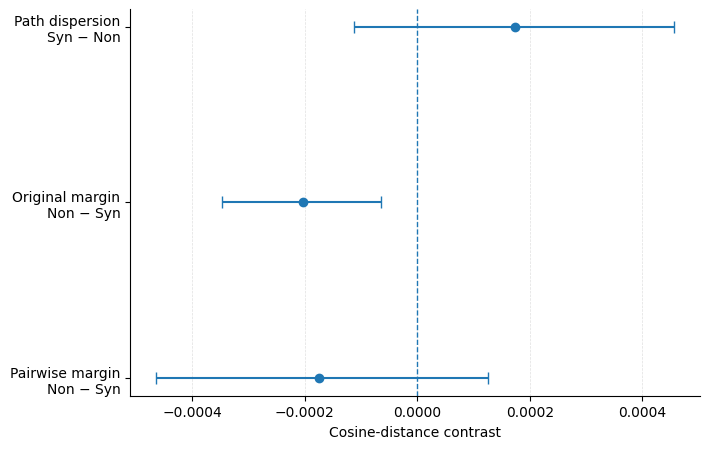

Retrieval accuracy:
0.4973 [0.4791, 0.5159]

Chance level:
0.5000

Retrieval semantic margin:
-0.00000527 [-0.00015177, 0.00015631]

Saved:
/content/drive/MyDrive/wiml_equivalence/figures/figure2_structural_geometry_20m.png
/content/drive/MyDrive/wiml_equivalence/figures/figure2_structural_geometry_20m.pdf


In [48]:
# OMNI-DNA-20M — Create structural summary figure

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

geometry_plot_df = pd.read_csv(
    RESULTS_DIR / "equivalence_class_geometry_bootstrap_summary.csv"
)

retrieval_plot_df = pd.read_csv(
    RESULTS_DIR / "equivalence_retrieval_bootstrap_summary.csv"
)

path_plot_df = pd.read_csv(
    RESULTS_DIR / "path_consistency_bootstrap_summary.csv"
)

figure_rows = pd.DataFrame([
    {
        "label": "Path dispersion\nSyn − Non",
        "estimate": path_plot_df.iloc[0]["mean_difference"],
        "ci_low": path_plot_df.iloc[0]["ci95_low"],
        "ci_high": path_plot_df.iloc[0]["ci95_high"],
        "reference": 0.0,
    },
    {
        "label": "Original margin\nNon − Syn",
        "estimate": geometry_plot_df.loc[
            geometry_plot_df["contrast"]
            == "original_margin_non_minus_syn",
            "mean"
        ].iloc[0],
        "ci_low": geometry_plot_df.loc[
            geometry_plot_df["contrast"]
            == "original_margin_non_minus_syn",
            "ci95_low"
        ].iloc[0],
        "ci_high": geometry_plot_df.loc[
            geometry_plot_df["contrast"]
            == "original_margin_non_minus_syn",
            "ci95_high"
        ].iloc[0],
        "reference": 0.0,
    },
    {
        "label": "Pairwise margin\nNon − Syn",
        "estimate": geometry_plot_df.loc[
            geometry_plot_df["contrast"]
            == "pairwise_margin_non_minus_syn",
            "mean"
        ].iloc[0],
        "ci_low": geometry_plot_df.loc[
            geometry_plot_df["contrast"]
            == "pairwise_margin_non_minus_syn",
            "ci95_low"
        ].iloc[0],
        "ci_high": geometry_plot_df.loc[
            geometry_plot_df["contrast"]
            == "pairwise_margin_non_minus_syn",
            "ci95_high"
        ].iloc[0],
        "reference": 0.0,
    },
])

fig, ax = plt.subplots(figsize=(7.2, 4.6))

y = np.arange(len(figure_rows))

xerr = np.vstack([
    figure_rows["estimate"] - figure_rows["ci_low"],
    figure_rows["ci_high"] - figure_rows["estimate"],
])

ax.errorbar(
    figure_rows["estimate"],
    y,
    xerr=xerr,
    fmt="o",
    capsize=4,
    linewidth=1.5,
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_yticks(y)
ax.set_yticklabels(figure_rows["label"])
ax.set_xlabel("Cosine-distance contrast")

ax.invert_yaxis()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.5,
    alpha=0.4,
)

fig.tight_layout()

STRUCTURAL_FIGURE_PNG = (
    PROJECT_ROOT
    / "figures"
    / "figure2_structural_geometry_20m.png"
)

STRUCTURAL_FIGURE_PDF = (
    PROJECT_ROOT
    / "figures"
    / "figure2_structural_geometry_20m.pdf"
)

fig.savefig(
    STRUCTURAL_FIGURE_PNG,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    STRUCTURAL_FIGURE_PDF,
    bbox_inches="tight",
)

plt.show()

# Retrieval summary printed separately because its reference is 0.5,
# not zero like the distance contrasts.
retrieval_accuracy_row = retrieval_plot_df[
    retrieval_plot_df["metric"]
    == "equivalence_retrieval_accuracy"
].iloc[0]

semantic_margin_row = retrieval_plot_df[
    retrieval_plot_df["metric"]
    == "semantic_margin_non_minus_syn"
].iloc[0]

print("Retrieval accuracy:")
print(
    f"{retrieval_accuracy_row['mean']:.4f} "
    f"[{retrieval_accuracy_row['ci95_low']:.4f}, "
    f"{retrieval_accuracy_row['ci95_high']:.4f}]"
)

print("\nChance level:")
print("0.5000")

print("\nRetrieval semantic margin:")
print(
    f"{semantic_margin_row['mean']:.8f} "
    f"[{semantic_margin_row['ci95_low']:.8f}, "
    f"{semantic_margin_row['ci95_high']:.8f}]"
)

print("\nSaved:")
print(STRUCTURAL_FIGURE_PNG)
print(STRUCTURAL_FIGURE_PDF)

assert STRUCTURAL_FIGURE_PNG.exists()
assert STRUCTURAL_FIGURE_PDF.exists()
assert STRUCTURAL_FIGURE_PNG.stat().st_size > 0
assert STRUCTURAL_FIGURE_PDF.stat().st_size > 0

In [49]:
# OMNI-DNA-20M — Freeze and verify complete experiment block

import pandas as pd

OMNI20M_ARTIFACTS = {
    "pilot_sources":
        PROJECT_ROOT / "data" / "processed" / "original_sequences.csv",

    "pilot_synonymous":
        PROJECT_ROOT / "data" / "processed" / "synonymous_variants.csv",

    "pilot_nonsynonymous":
        PROJECT_ROOT / "data" / "processed" / "nonsynonymous_controls.csv",

    "pilot_embeddings":
        PROJECT_ROOT / "embeddings" / "omnidna20m_pilot_embeddings.pt",

    "pilot_distances":
        PROJECT_ROOT / "results" / "distance_results.csv",

    "pilot_bootstrap":
        PROJECT_ROOT / "results" / "bootstrap_summary.csv",

    "pilot_difference_in_differences":
        PROJECT_ROOT / "results" / "bootstrap_difference_in_differences.csv",

    "structural_sources":
        PROJECT_ROOT / "data" / "processed" / "structural_extension_sources.csv",

    "structural_synonymous":
        PROJECT_ROOT / "data" / "processed" / "structural_synonymous_variants.csv",

    "structural_nonsynonymous":
        PROJECT_ROOT / "data" / "processed" / "structural_nonsynonymous_controls.csv",

    "structural_transform_audit":
        PROJECT_ROOT / "metadata" / "structural_transformation_metadata.csv",

    "structural_embeddings":
        PROJECT_ROOT / "embeddings" / "omnidna20m_structural_embeddings.pt",

    "structural_embedding_metadata":
        PROJECT_ROOT / "embeddings" / "omnidna20m_structural_embedding_metadata.csv",

    "path_consistency":
        PROJECT_ROOT / "results" / "path_consistency_bootstrap_summary.csv",

    "equivalence_geometry":
        PROJECT_ROOT / "results" / "equivalence_class_geometry_bootstrap_summary.csv",

    "equivalence_retrieval":
        PROJECT_ROOT / "results" / "equivalence_retrieval_bootstrap_summary.csv",

    "consolidated_results":
        PROJECT_ROOT / "results" / "omnidna20m_consolidated_results.csv",

    "headline_summary":
        PROJECT_ROOT / "metadata" / "omnidna20m_headline_summary.json",

    "figure1_composition":
        PROJECT_ROOT / "figures" / "figure1_depth_vs_distance.png",

    "figure2_structure":
        PROJECT_ROOT / "figures" / "figure2_structural_geometry_20m.png",
}

freeze_rows = []

for artifact, path in OMNI20M_ARTIFACTS.items():

    exists = path.exists()
    size_bytes = path.stat().st_size if exists else 0

    freeze_rows.append({
        "artifact": artifact,
        "path": str(path),
        "exists": exists,
        "size_bytes": size_bytes,
    })

omnidna20m_manifest_df = pd.DataFrame(freeze_rows)

OMNI20M_MANIFEST_PATH = (
    PROJECT_ROOT
    / "metadata"
    / "omnidna20m_complete_manifest.csv"
)

omnidna20m_manifest_df.to_csv(
    OMNI20M_MANIFEST_PATH,
    index=False,
)

print(
    omnidna20m_manifest_df[
        ["artifact", "exists", "size_bytes"]
    ].to_string(index=False)
)

print(
    "\nArtifacts present:",
    int(omnidna20m_manifest_df["exists"].sum()),
    "/",
    len(omnidna20m_manifest_df),
)

print("\nFrozen manifest:")
print(OMNI20M_MANIFEST_PATH)

assert omnidna20m_manifest_df["exists"].all()
assert (omnidna20m_manifest_df["size_bytes"] > 0).all()
assert len(omnidna20m_manifest_df) == 20

                       artifact  exists  size_bytes
                  pilot_sources    True      324332
               pilot_synonymous    True     1366757
            pilot_nonsynonymous    True     1367657
               pilot_embeddings    True     2152181
                pilot_distances    True      151132
                pilot_bootstrap    True         824
pilot_difference_in_differences    True         520
             structural_sources    True      100108
          structural_synonymous    True     4194885
       structural_nonsynonymous    True     4197880
     structural_transform_audit    True      361861
          structural_embeddings    True     6248280
  structural_embedding_metadata    True      262456
               path_consistency    True         294
           equivalence_geometry    True         331
          equivalence_retrieval    True         304
           consolidated_results    True        3148
               headline_summary    True         812
            

In [50]:
# EXTENSION 4 — Load and validate Omni-DNA-116M before replication

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_116M_ID = "zehui127/Omni-DNA-116M"

tokenizer_116m = AutoTokenizer.from_pretrained(
    MODEL_116M_ID,
    trust_remote_code=True,
)

model_116m = AutoModelForCausalLM.from_pretrained(
    MODEL_116M_ID,
    trust_remote_code=True,
    torch_dtype=torch.float32,
)

model_116m = model_116m.to("cuda")
model_116m.eval()

hidden_size_116m = getattr(
    model_116m.config,
    "hidden_size",
    None,
)

num_layers_116m = getattr(
    model_116m.config,
    "num_hidden_layers",
    None,
)

print("Model ID          :", MODEL_116M_ID)
print("Model class       :", model_116m.__class__.__name__)
print(
    "Commit hash       :",
    getattr(model_116m.config, "_commit_hash", None)
)
print("Tokenizer class   :", tokenizer_116m.__class__.__name__)
print("Hidden size       :", hidden_size_116m)
print("Hidden layers     :", num_layers_116m)

# Check exact tokenization on the frozen 6,100-sequence structural set.
token_lengths_116m = []

for sequence in structural_embedding_input_df["sequence"]:
    encoded = tokenizer_116m(
        sequence,
        add_special_tokens=True,
        truncation=False,
        return_attention_mask=False,
    )

    token_lengths_116m.append(
        len(encoded["input_ids"])
    )

print(
    "Maximum token length:",
    max(token_lengths_116m)
)

print(
    "Sequences >250 tokens:",
    sum(x > 250 for x in token_lengths_116m)
)

# Small forward-pass check.
test_sequence = structural_embedding_input_df.iloc[0]["sequence"]

encoded_test = tokenizer_116m(
    test_sequence,
    return_tensors="pt",
    add_special_tokens=True,
    truncation=False,
)

encoded_test = {
    key: value.to("cuda")
    for key, value in encoded_test.items()
}

with torch.inference_mode():
    test_outputs = model_116m(
        **encoded_test,
        output_hidden_states=True,
        return_dict=True,
    )

print(
    "Hidden states returned:",
    len(test_outputs.hidden_states)
)

print(
    "Final hidden shape:",
    tuple(test_outputs.hidden_states[-1].shape)
)

print(
    "Contains NaN:",
    torch.isnan(
        test_outputs.hidden_states[-1]
    ).any().item()
)

print(
    "Contains Inf:",
    torch.isinf(
        test_outputs.hidden_states[-1]
    ).any().item()
)

assert max(token_lengths_116m) <= 250
assert not torch.isnan(
    test_outputs.hidden_states[-1]
).any()
assert not torch.isinf(
    test_outputs.hidden_states[-1]
).any()
assert (
    test_outputs.hidden_states[-1].shape[-1]
    == hidden_size_116m
)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

configuration_olmo.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/zehui127/Omni-DNA-116M:
- configuration_olmo.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_olmo.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/zehui127/Omni-DNA-116M:
- modeling_olmo.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors:   0%|          | 0.00/466M [00:00<?, ?B/s]

Model ID          : zehui127/Omni-DNA-116M
Model class       : OLMoForCausalLM
Commit hash       : 8a602a8324e1c29aff91112a7b78cad841d4c9d5
Tokenizer class   : PreTrainedTokenizerFast
Hidden size       : 768
Hidden layers     : 12
Maximum token length: 236
Sequences >250 tokens: 0
Hidden states returned: 13
Final hidden shape: (1, 174, 768)
Contains NaN: False
Contains Inf: False


# OMNI-DNA-116M — Full structural embedding replication

In [51]:
# OMNI-DNA-116M — Full structural embedding replication

import pandas as pd
import torch

MODEL_116M_REVISION = "8a602a8324e1c29aff91112a7b78cad841d4c9d5"

# Reload pinned model/tokenizer revision for exact reproducibility.
tokenizer_116m = AutoTokenizer.from_pretrained(
    MODEL_116M_ID,
    revision=MODEL_116M_REVISION,
    trust_remote_code=True,
)

model_116m = AutoModelForCausalLM.from_pretrained(
    MODEL_116M_ID,
    revision=MODEL_116M_REVISION,
    trust_remote_code=True,
    torch_dtype=torch.float32,
)

model_116m = model_116m.to("cuda")
model_116m.eval()

SPECIAL_TOKEN_IDS_116M = {
    token_id
    for token_id in [
        tokenizer_116m.unk_token_id,
        tokenizer_116m.cls_token_id,
        tokenizer_116m.sep_token_id,
        tokenizer_116m.pad_token_id,
        tokenizer_116m.mask_token_id,
        tokenizer_116m.bos_token_id,
        tokenizer_116m.eos_token_id,
    ]
    if token_id is not None
}

BATCH_SIZE_116M = 16
embedding_batches_116m = []

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

for start in range(
    0,
    len(structural_embedding_input_df),
    BATCH_SIZE_116M,
):
    batch_df = structural_embedding_input_df.iloc[
        start:start + BATCH_SIZE_116M
    ]

    encoded = tokenizer_116m(
        batch_df["sequence"].tolist(),
        return_tensors="pt",
        padding=True,
        truncation=False,
        add_special_tokens=True,
        return_attention_mask=True,
    )

    input_ids = encoded["input_ids"]
    attention_mask = encoded["attention_mask"].bool()

    biological_mask = attention_mask.clone()

    for special_id in SPECIAL_TOKEN_IDS_116M:
        biological_mask &= input_ids.ne(special_id)

    assert biological_mask.sum(dim=1).min().item() > 0

    encoded_cuda = {
        key: value.to("cuda")
        for key, value in encoded.items()
    }

    biological_mask_cuda = biological_mask.to("cuda")

    with torch.inference_mode():
        outputs = model_116m(
            **encoded_cuda,
            output_hidden_states=True,
            return_dict=True,
        )

        final_hidden = outputs.hidden_states[-1]

        pooled = (
            final_hidden
            * biological_mask_cuda.unsqueeze(-1)
        ).sum(dim=1) / biological_mask_cuda.sum(
            dim=1,
            keepdim=True,
        )

    embedding_batches_116m.append(
        pooled.detach().cpu()
    )

    del outputs
    del final_hidden
    del pooled
    del encoded_cuda
    del biological_mask_cuda

structural_embedding_matrix_116m = torch.cat(
    embedding_batches_116m,
    dim=0,
)

peak_memory_gb_116m = (
    torch.cuda.max_memory_allocated()
    / (1024 ** 3)
)

print(
    "Sequences embedded :",
    structural_embedding_matrix_116m.shape[0]
)

print(
    "Embedding dimension:",
    structural_embedding_matrix_116m.shape[1]
)

print(
    "Matrix shape       :",
    tuple(structural_embedding_matrix_116m.shape)
)

print(
    "Contains NaN       :",
    torch.isnan(
        structural_embedding_matrix_116m
    ).any().item()
)

print(
    "Contains Inf       :",
    torch.isinf(
        structural_embedding_matrix_116m
    ).any().item()
)

print(
    "Peak CUDA memory GB:",
    round(peak_memory_gb_116m, 3)
)

OMNI116M_EMBEDDING_PATH = (
    PROJECT_ROOT
    / "embeddings"
    / "omnidna116m_structural_embeddings.pt"
)

OMNI116M_METADATA_PATH = (
    PROJECT_ROOT
    / "embeddings"
    / "omnidna116m_structural_embedding_metadata.csv"
)

torch.save(
    structural_embedding_matrix_116m,
    OMNI116M_EMBEDDING_PATH,
)

metadata_116m_df = (
    structural_embedding_input_df[
        [
            "sequence_id",
            "path_id",
            "condition",
            "depth",
        ]
    ]
    .copy()
)

metadata_116m_df["token_length"] = token_lengths_116m
metadata_116m_df["embedding_index"] = range(
    len(metadata_116m_df)
)
metadata_116m_df["model_id"] = MODEL_116M_ID
metadata_116m_df["model_revision"] = MODEL_116M_REVISION

metadata_116m_df.to_csv(
    OMNI116M_METADATA_PATH,
    index=False,
)

# Read-back integrity checks.
check_matrix_116m = torch.load(
    OMNI116M_EMBEDDING_PATH,
    map_location="cpu",
    weights_only=True,
)

check_meta_116m = pd.read_csv(
    OMNI116M_METADATA_PATH
)

print("\nRows by condition:")
print(
    check_meta_116m["condition"]
    .value_counts()
)

print("\nSaved:")
print(OMNI116M_EMBEDDING_PATH)
print(OMNI116M_METADATA_PATH)

assert check_matrix_116m.shape == (6100, 768)
assert len(check_meta_116m) == 6100

assert not torch.isnan(check_matrix_116m).any()
assert not torch.isinf(check_matrix_116m).any()

assert (
    check_meta_116m["embedding_index"].tolist()
    == list(range(6100))
)

assert (
    check_meta_116m["condition"].value_counts().to_dict()
    ==
    {
        "synonymous": 3000,
        "nonsynonymous": 3000,
        "original": 100,
    }
)

assert check_meta_116m["token_length"].max() <= 250

Sequences embedded : 6100
Embedding dimension: 768
Matrix shape       : (6100, 768)
Contains NaN       : False
Contains Inf       : False
Peak CUDA memory GB: 1.245

Rows by condition:
condition
synonymous       3000
nonsynonymous    3000
original          100
Name: count, dtype: int64

Saved:
/content/drive/MyDrive/wiml_equivalence/embeddings/omnidna116m_structural_embeddings.pt
/content/drive/MyDrive/wiml_equivalence/embeddings/omnidna116m_structural_embedding_metadata.csv


In [52]:
# OMNI-DNA-116M — Multiple-path consistency replication

import itertools
import numpy as np
import pandas as pd
import torch

meta_116m = metadata_116m_df.copy()

embedding_lookup_116m = {
    (
        row.sequence_id,
        row.condition,
        int(row.path_id),
        int(row.depth),
    ): int(row.embedding_index)
    for row in meta_116m.itertuples()
}

emb_116m = structural_embedding_matrix_116m.float()

emb_norm_116m = emb_116m / emb_116m.norm(
    dim=1,
    keepdim=True,
).clamp_min(1e-12)

pair_records_116m = []

for condition, endpoint_df in [
    ("synonymous", syn_endpoint_seq_df),
    ("nonsynonymous", non_endpoint_seq_df),
]:

    for sequence_id, source_df in endpoint_df.groupby("sequence_id"):

        source_df = source_df.sort_values("path_id")

        assert len(source_df) == N_PATHS
        assert source_df["path_id"].nunique() == N_PATHS

        endpoint_rows = {
            int(row.path_id): row
            for row in source_df.itertuples()
        }

        for path_a, path_b in itertools.combinations(
            range(N_PATHS),
            2,
        ):

            row_a = endpoint_rows[path_a]
            row_b = endpoint_rows[path_b]

            idx_a = embedding_lookup_116m[
                (
                    sequence_id,
                    condition,
                    path_a,
                    3,
                )
            ]

            idx_b = embedding_lookup_116m[
                (
                    sequence_id,
                    condition,
                    path_b,
                    3,
                )
            ]

            cosine_similarity = float(
                torch.dot(
                    emb_norm_116m[idx_a],
                    emb_norm_116m[idx_b],
                )
            )

            cosine_distance = 1.0 - cosine_similarity

            nt_pair_distance = nucleotide_hamming(
                row_a.variant_sequence,
                row_b.variant_sequence,
            )

            pair_records_116m.append({
                "sequence_id": sequence_id,
                "condition": condition,
                "path_a": path_a,
                "path_b": path_b,
                "cosine_distance": cosine_distance,
                "pairwise_nt_hamming": nt_pair_distance,
            })


path_consistency_pairs_116m_df = pd.DataFrame(
    pair_records_116m
)

expected_pairs_per_source = (
    N_PATHS * (N_PATHS - 1) // 2
)

expected_pairs_per_condition = (
    STRUCTURAL_N * expected_pairs_per_source
)

assert len(path_consistency_pairs_116m_df) == (
    2 * expected_pairs_per_condition
)


source_dispersion_116m_df = (
    path_consistency_pairs_116m_df
    .groupby(
        ["sequence_id", "condition"],
        as_index=False,
    )
    .agg(
        mean_cosine_distance=("cosine_distance", "mean"),
        median_cosine_distance=("cosine_distance", "median"),
        mean_pairwise_nt_hamming=("pairwise_nt_hamming", "mean"),
    )
)


paired_source_dispersion_116m_df = (
    source_dispersion_116m_df[
        source_dispersion_116m_df["condition"] == "synonymous"
    ]
    .merge(
        source_dispersion_116m_df[
            source_dispersion_116m_df["condition"] == "nonsynonymous"
        ],
        on="sequence_id",
        suffixes=("_syn", "_non"),
        validate="one_to_one",
    )
)

paired_source_dispersion_116m_df[
    "syn_minus_non_cosine"
] = (
    paired_source_dispersion_116m_df[
        "mean_cosine_distance_syn"
    ]
    -
    paired_source_dispersion_116m_df[
        "mean_cosine_distance_non"
    ]
)

observed_diffs_116m = (
    paired_source_dispersion_116m_df[
        "syn_minus_non_cosine"
    ]
    .to_numpy()
)


rng = np.random.default_rng(SEED)

bootstrap_means_116m = np.empty(10000)

for i in range(10000):

    sampled_indices = rng.integers(
        0,
        STRUCTURAL_N,
        size=STRUCTURAL_N,
    )

    bootstrap_means_116m[i] = (
        observed_diffs_116m[
            sampled_indices
        ].mean()
    )


ci_low_116m, ci_high_116m = np.quantile(
    bootstrap_means_116m,
    [0.025, 0.975],
)


print("Pairs per source per condition :", expected_pairs_per_source)
print("Synonymous endpoint pairs      :", expected_pairs_per_condition)
print("Nonsynonymous endpoint pairs   :", expected_pairs_per_condition)

print("\nEndpoint-to-endpoint representation dispersion:")
print(
    source_dispersion_116m_df
    .groupby("condition")["mean_cosine_distance"]
    .agg(["mean", "median", "std"])
)

print("\nPaired source-level synonymous minus nonsynonymous:")
print(
    "Mean cosine difference :",
    f"{observed_diffs_116m.mean():.8f}"
)
print(
    "Median difference      :",
    f"{np.median(observed_diffs_116m):.8f}"
)
print(
    "95% bootstrap CI       :",
    f"[{ci_low_116m:.8f}, {ci_high_116m:.8f}]"
)
print(
    "Fraction syn > non     :",
    f"{(observed_diffs_116m > 0).mean():.4f}"
)


PATH_CONSISTENCY_116M_PAIRS_PATH = (
    PROJECT_ROOT
    / "results"
    / "path_consistency_endpoint_pairs_116m.csv"
)

PATH_CONSISTENCY_116M_SOURCE_PATH = (
    PROJECT_ROOT
    / "results"
    / "path_consistency_source_summary_116m.csv"
)

PATH_CONSISTENCY_116M_BOOTSTRAP_PATH = (
    PROJECT_ROOT
    / "results"
    / "path_consistency_bootstrap_summary_116m.csv"
)

path_consistency_pairs_116m_df.to_csv(
    PATH_CONSISTENCY_116M_PAIRS_PATH,
    index=False,
)

paired_source_dispersion_116m_df.to_csv(
    PATH_CONSISTENCY_116M_SOURCE_PATH,
    index=False,
)

pd.DataFrame([{
    "contrast":
        "synonymous_minus_nonsynonymous_endpoint_dispersion",
    "n_sources": STRUCTURAL_N,
    "paths_per_source": N_PATHS,
    "pairs_per_source_per_condition":
        expected_pairs_per_source,
    "mean_difference":
        observed_diffs_116m.mean(),
    "median_difference":
        np.median(observed_diffs_116m),
    "ci95_low":
        ci_low_116m,
    "ci95_high":
        ci_high_116m,
    "fraction_positive":
        (observed_diffs_116m > 0).mean(),
}]).to_csv(
    PATH_CONSISTENCY_116M_BOOTSTRAP_PATH,
    index=False,
)

assert np.isfinite(
    path_consistency_pairs_116m_df[
        "cosine_distance"
    ]
).all()

assert (
    path_consistency_pairs_116m_df[
        "cosine_distance"
    ] >= -1e-6
).all()

assert (
    path_consistency_pairs_116m_df[
        [
            "condition",
            "sequence_id",
            "path_a",
            "path_b",
        ]
    ]
    .duplicated()
    .sum()
    == 0
)

print("\nSaved:")
print(PATH_CONSISTENCY_116M_PAIRS_PATH)
print(PATH_CONSISTENCY_116M_SOURCE_PATH)
print(PATH_CONSISTENCY_116M_BOOTSTRAP_PATH)

Pairs per source per condition : 45
Synonymous endpoint pairs      : 4500
Nonsynonymous endpoint pairs   : 4500

Endpoint-to-endpoint representation dispersion:
                   mean    median       std
condition                                  
nonsynonymous  0.000287  0.000205  0.000229
synonymous     0.000301  0.000222  0.000245

Paired source-level synonymous minus nonsynonymous:
Mean cosine difference : 0.00001417
Median difference      : 0.00000538
95% bootstrap CI       : [-0.00000084, 0.00002944]
Fraction syn > non     : 0.5700

Saved:
/content/drive/MyDrive/wiml_equivalence/results/path_consistency_endpoint_pairs_116m.csv
/content/drive/MyDrive/wiml_equivalence/results/path_consistency_source_summary_116m.csv
/content/drive/MyDrive/wiml_equivalence/results/path_consistency_bootstrap_summary_116m.csv


In [53]:
# OMNI-DNA-116M — Equivalence-class geometry replication

import numpy as np
import pandas as pd
import torch
import itertools

geometry_records_116m = []

for sequence_id in structural_source_df["sequence_id"]:

    original_idx = embedding_lookup_116m[
        (sequence_id, "original", -1, 0)
    ]

    original_vec = emb_norm_116m[original_idx]

    syn_indices = []
    non_indices = []

    for path_id in range(N_PATHS):

        syn_indices.append(
            embedding_lookup_116m[
                (sequence_id, "synonymous", path_id, 3)
            ]
        )

        non_indices.append(
            embedding_lookup_116m[
                (sequence_id, "nonsynonymous", path_id, 3)
            ]
        )

    syn_orig_distances = [
        1.0 - float(
            torch.dot(
                original_vec,
                emb_norm_116m[idx],
            )
        )
        for idx in syn_indices
    ]

    non_orig_distances = [
        1.0 - float(
            torch.dot(
                original_vec,
                emb_norm_116m[idx],
            )
        )
        for idx in non_indices
    ]

    syn_pair_distances = []

    for a, b in itertools.combinations(
        syn_indices,
        2,
    ):
        syn_pair_distances.append(
            1.0 - float(
                torch.dot(
                    emb_norm_116m[a],
                    emb_norm_116m[b],
                )
            )
        )

    non_pair_distances = []

    for a, b in itertools.combinations(
        non_indices,
        2,
    ):
        non_pair_distances.append(
            1.0 - float(
                torch.dot(
                    emb_norm_116m[a],
                    emb_norm_116m[b],
                )
            )
        )

    mean_syn_orig = np.mean(
        syn_orig_distances
    )

    mean_non_orig = np.mean(
        non_orig_distances
    )

    mean_syn_pair = np.mean(
        syn_pair_distances
    )

    mean_non_pair = np.mean(
        non_pair_distances
    )

    geometry_records_116m.append({
        "sequence_id": sequence_id,
        "mean_original_to_synonymous":
            mean_syn_orig,
        "mean_original_to_nonsynonymous":
            mean_non_orig,
        "mean_synonymous_pairwise":
            mean_syn_pair,
        "mean_nonsynonymous_pairwise":
            mean_non_pair,
        "original_margin_non_minus_syn":
            mean_non_orig - mean_syn_orig,
        "pairwise_margin_non_minus_syn":
            mean_non_pair - mean_syn_pair,
        "pairwise_coherence_ratio_syn_over_non":
            (
                mean_syn_pair / mean_non_pair
                if mean_non_pair > 0
                else np.nan
            ),
    })


equivalence_geometry_116m_df = pd.DataFrame(
    geometry_records_116m
)

assert len(equivalence_geometry_116m_df) == STRUCTURAL_N


def bootstrap_source_values_116m(
    values,
    n_boot=10000,
):
    values = np.asarray(
        values,
        dtype=float,
    )

    rng = np.random.default_rng(SEED)

    boot_means = np.empty(
        n_boot
    )

    for i in range(n_boot):

        idx = rng.integers(
            0,
            len(values),
            size=len(values),
        )

        boot_means[i] = (
            values[idx].mean()
        )

    return {
        "mean": values.mean(),
        "median": np.median(values),
        "ci_low": np.quantile(
            boot_means,
            0.025,
        ),
        "ci_high": np.quantile(
            boot_means,
            0.975,
        ),
        "fraction_positive":
            np.mean(values > 0),
    }


orig_stats_116m = bootstrap_source_values_116m(
    equivalence_geometry_116m_df[
        "original_margin_non_minus_syn"
    ]
)

pair_stats_116m = bootstrap_source_values_116m(
    equivalence_geometry_116m_df[
        "pairwise_margin_non_minus_syn"
    ]
)


print("Equivalence-class geometry:")
print(
    equivalence_geometry_116m_df[
        [
            "mean_original_to_synonymous",
            "mean_original_to_nonsynonymous",
            "mean_synonymous_pairwise",
            "mean_nonsynonymous_pairwise",
            "pairwise_coherence_ratio_syn_over_non",
        ]
    ].agg(
        ["mean", "median", "std"]
    )
)

print("\nOriginal-to-member semantic margin")
print("(positive means nonsynonymous is farther):")
print(
    f"Mean     : {orig_stats_116m['mean']:.8f}"
)
print(
    f"Median   : {orig_stats_116m['median']:.8f}"
)
print(
    "95% CI   : "
    f"[{orig_stats_116m['ci_low']:.8f}, "
    f"{orig_stats_116m['ci_high']:.8f}]"
)
print(
    "Fraction positive: "
    f"{orig_stats_116m['fraction_positive']:.4f}"
)

print("\nMember-to-member semantic margin")
print("(positive means nonsynonymous class is more dispersed):")
print(
    f"Mean     : {pair_stats_116m['mean']:.8f}"
)
print(
    f"Median   : {pair_stats_116m['median']:.8f}"
)
print(
    "95% CI   : "
    f"[{pair_stats_116m['ci_low']:.8f}, "
    f"{pair_stats_116m['ci_high']:.8f}]"
)
print(
    "Fraction positive: "
    f"{pair_stats_116m['fraction_positive']:.4f}"
)

print("\nCoherence ratio:")
print(
    equivalence_geometry_116m_df[
        "pairwise_coherence_ratio_syn_over_non"
    ].describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )
)


EQUIVALENCE_GEOMETRY_116M_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_class_geometry_116m.csv"
)

EQUIVALENCE_GEOMETRY_116M_SUMMARY_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_class_geometry_bootstrap_summary_116m.csv"
)

equivalence_geometry_116m_df.to_csv(
    EQUIVALENCE_GEOMETRY_116M_PATH,
    index=False,
)

pd.DataFrame([
    {
        "contrast":
            "original_margin_non_minus_syn",
        "n_sources": STRUCTURAL_N,
        "mean": orig_stats_116m["mean"],
        "median": orig_stats_116m["median"],
        "ci95_low": orig_stats_116m["ci_low"],
        "ci95_high": orig_stats_116m["ci_high"],
        "fraction_positive":
            orig_stats_116m["fraction_positive"],
    },
    {
        "contrast":
            "pairwise_margin_non_minus_syn",
        "n_sources": STRUCTURAL_N,
        "mean": pair_stats_116m["mean"],
        "median": pair_stats_116m["median"],
        "ci95_low": pair_stats_116m["ci_low"],
        "ci95_high": pair_stats_116m["ci_high"],
        "fraction_positive":
            pair_stats_116m["fraction_positive"],
    },
]).to_csv(
    EQUIVALENCE_GEOMETRY_116M_SUMMARY_PATH,
    index=False,
)

assert np.isfinite(
    equivalence_geometry_116m_df.select_dtypes(
        include=[np.number]
    ).to_numpy()
).all()

print("\nSaved:")
print(EQUIVALENCE_GEOMETRY_116M_PATH)
print(EQUIVALENCE_GEOMETRY_116M_SUMMARY_PATH)

Equivalence-class geometry:
        mean_original_to_synonymous  mean_original_to_nonsynonymous  \
mean                       0.000169                        0.000151   
median                     0.000124                        0.000107   
std                        0.000137                        0.000121   

        mean_synonymous_pairwise  mean_nonsynonymous_pairwise  \
mean                    0.000301                     0.000287   
median                  0.000222                     0.000205   
std                     0.000245                     0.000229   

        pairwise_coherence_ratio_syn_over_non  
mean                                 1.084275  
median                               1.042770  
std                                  0.320288  

Original-to-member semantic margin
(positive means nonsynonymous is farther):
Mean     : -0.00001870
Median   : -0.00000694
95% CI   : [-0.00002711, -0.00001101]
Fraction positive: 0.3200

Member-to-member semantic margin
(positive m

In [54]:
# OMNI-DNA-116M — Equivalent-vs-nonequivalent retrieval replication

import numpy as np
import pandas as pd
import torch

retrieval_records_116m = []

for sequence_id in structural_source_df["sequence_id"]:

    for query_path in range(N_PATHS):

        query_idx = embedding_lookup_116m[
            (
                sequence_id,
                "synonymous",
                query_path,
                3,
            )
        ]

        query_vec = emb_norm_116m[query_idx]

        for candidate_path in range(N_PATHS):

            if candidate_path == query_path:
                continue

            syn_candidate_idx = embedding_lookup_116m[
                (
                    sequence_id,
                    "synonymous",
                    candidate_path,
                    3,
                )
            ]

            non_candidate_idx = embedding_lookup_116m[
                (
                    sequence_id,
                    "nonsynonymous",
                    candidate_path,
                    3,
                )
            ]

            syn_distance = 1.0 - float(
                torch.dot(
                    query_vec,
                    emb_norm_116m[syn_candidate_idx],
                )
            )

            non_distance = 1.0 - float(
                torch.dot(
                    query_vec,
                    emb_norm_116m[non_candidate_idx],
                )
            )

            semantic_margin = (
                non_distance - syn_distance
            )

            retrieval_correct = (
                syn_distance < non_distance
            )

            retrieval_records_116m.append({
                "sequence_id": sequence_id,
                "query_path": query_path,
                "candidate_path": candidate_path,
                "synonymous_candidate_distance":
                    syn_distance,
                "nonsynonymous_candidate_distance":
                    non_distance,
                "semantic_margin_non_minus_syn":
                    semantic_margin,
                "retrieval_correct":
                    retrieval_correct,
            })


retrieval_116m_df = pd.DataFrame(
    retrieval_records_116m
)

expected_comparisons = (
    STRUCTURAL_N
    * N_PATHS
    * (N_PATHS - 1)
)

assert len(retrieval_116m_df) == expected_comparisons


source_retrieval_116m_df = (
    retrieval_116m_df
    .groupby(
        "sequence_id",
        as_index=False,
    )
    .agg(
        retrieval_accuracy=(
            "retrieval_correct",
            "mean",
        ),
        mean_semantic_margin=(
            "semantic_margin_non_minus_syn",
            "mean",
        ),
        median_semantic_margin=(
            "semantic_margin_non_minus_syn",
            "median",
        ),
        mean_synonymous_candidate_distance=(
            "synonymous_candidate_distance",
            "mean",
        ),
        mean_nonsynonymous_candidate_distance=(
            "nonsynonymous_candidate_distance",
            "mean",
        ),
    )
)


rng = np.random.default_rng(SEED)

accuracy_values_116m = (
    source_retrieval_116m_df[
        "retrieval_accuracy"
    ].to_numpy()
)

margin_values_116m = (
    source_retrieval_116m_df[
        "mean_semantic_margin"
    ].to_numpy()
)

boot_accuracy_116m = np.empty(10000)
boot_margin_116m = np.empty(10000)

for i in range(10000):

    idx = rng.integers(
        0,
        STRUCTURAL_N,
        size=STRUCTURAL_N,
    )

    boot_accuracy_116m[i] = (
        accuracy_values_116m[idx].mean()
    )

    boot_margin_116m[i] = (
        margin_values_116m[idx].mean()
    )


accuracy_ci_116m = np.quantile(
    boot_accuracy_116m,
    [0.025, 0.975],
)

margin_ci_116m = np.quantile(
    boot_margin_116m,
    [0.025, 0.975],
)


print(
    "Total pairwise retrieval comparisons:",
    len(retrieval_116m_df)
)

print("\nSource-level retrieval accuracy:")
print(
    source_retrieval_116m_df[
        "retrieval_accuracy"
    ].describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )
)

print("\nOverall source-mean retrieval accuracy:")
print(
    f"{accuracy_values_116m.mean():.4f}"
)

print(
    "95% bootstrap CI:",
    f"[{accuracy_ci_116m[0]:.4f}, "
    f"{accuracy_ci_116m[1]:.4f}]"
)

print("Chance level: 0.5000")


print("\nSemantic margin")
print("(positive = equivalent candidate is closer):")

print(
    "Mean:",
    f"{margin_values_116m.mean():.8f}"
)

print(
    "Median:",
    f"{np.median(margin_values_116m):.8f}"
)

print(
    "95% bootstrap CI:",
    f"[{margin_ci_116m[0]:.8f}, "
    f"{margin_ci_116m[1]:.8f}]"
)

print(
    "Fraction of sources with positive mean margin:",
    f"{(margin_values_116m > 0).mean():.4f}"
)


print("\nMean candidate distances:")
print(
    source_retrieval_116m_df[
        [
            "mean_synonymous_candidate_distance",
            "mean_nonsynonymous_candidate_distance",
        ]
    ].agg(
        ["mean", "median", "std"]
    )
)


RETRIEVAL_116M_RESULTS_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_retrieval_pairwise_116m.csv"
)

RETRIEVAL_116M_SOURCE_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_retrieval_source_summary_116m.csv"
)

RETRIEVAL_116M_BOOTSTRAP_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_retrieval_bootstrap_summary_116m.csv"
)

retrieval_116m_df.to_csv(
    RETRIEVAL_116M_RESULTS_PATH,
    index=False,
)

source_retrieval_116m_df.to_csv(
    RETRIEVAL_116M_SOURCE_PATH,
    index=False,
)

pd.DataFrame([
    {
        "metric":
            "equivalence_retrieval_accuracy",
        "n_sources":
            STRUCTURAL_N,
        "mean":
            accuracy_values_116m.mean(),
        "median":
            np.median(accuracy_values_116m),
        "ci95_low":
            accuracy_ci_116m[0],
        "ci95_high":
            accuracy_ci_116m[1],
        "reference":
            0.5,
    },
    {
        "metric":
            "semantic_margin_non_minus_syn",
        "n_sources":
            STRUCTURAL_N,
        "mean":
            margin_values_116m.mean(),
        "median":
            np.median(margin_values_116m),
        "ci95_low":
            margin_ci_116m[0],
        "ci95_high":
            margin_ci_116m[1],
        "reference":
            0.0,
    },
]).to_csv(
    RETRIEVAL_116M_BOOTSTRAP_PATH,
    index=False,
)


assert source_retrieval_116m_df[
    "retrieval_accuracy"
].between(
    0,
    1,
).all()

assert np.isfinite(
    retrieval_116m_df[
        [
            "synonymous_candidate_distance",
            "nonsynonymous_candidate_distance",
            "semantic_margin_non_minus_syn",
        ]
    ].to_numpy()
).all()

print("\nSaved:")
print(RETRIEVAL_116M_RESULTS_PATH)
print(RETRIEVAL_116M_SOURCE_PATH)
print(RETRIEVAL_116M_BOOTSTRAP_PATH)

Total pairwise retrieval comparisons: 9000

Source-level retrieval accuracy:
count    100.000000
mean       0.506222
std        0.121812
min        0.200000
10%        0.355556
25%        0.422222
50%        0.500000
75%        0.580556
90%        0.666667
max        0.833333
Name: retrieval_accuracy, dtype: float64

Overall source-mean retrieval accuracy:
0.5062
95% bootstrap CI: [0.4824, 0.5304]
Chance level: 0.5000

Semantic margin
(positive = equivalent candidate is closer):
Mean: 0.00000032
Median: -0.00000037
95% bootstrap CI: [-0.00000864, 0.00000937]
Fraction of sources with positive mean margin: 0.4900

Mean candidate distances:
        mean_synonymous_candidate_distance  \
mean                              0.000301   
median                            0.000222   
std                               0.000245   

        mean_nonsynonymous_candidate_distance  
mean                                 0.000302  
median                               0.000202  
std                      

In [55]:
# OMNI-DNA SCALE REPLICATION — Consolidate and freeze 20M vs 116M results

import json
import pandas as pd

RESULTS_DIR = PROJECT_ROOT / "results"
METADATA_DIR = PROJECT_ROOT / "metadata"

path20 = pd.read_csv(
    RESULTS_DIR / "path_consistency_bootstrap_summary.csv"
)

geom20 = pd.read_csv(
    RESULTS_DIR / "equivalence_class_geometry_bootstrap_summary.csv"
)

ret20 = pd.read_csv(
    RESULTS_DIR / "equivalence_retrieval_bootstrap_summary.csv"
)

path116 = pd.read_csv(
    RESULTS_DIR / "path_consistency_bootstrap_summary_116m.csv"
)

geom116 = pd.read_csv(
    RESULTS_DIR / "equivalence_class_geometry_bootstrap_summary_116m.csv"
)

ret116 = pd.read_csv(
    RESULTS_DIR / "equivalence_retrieval_bootstrap_summary_116m.csv"
)

scale_rows = []

def add_model_rows(model_name, path_df, geom_df, ret_df):

    scale_rows.append({
        "model": model_name,
        "experiment": "multiple_path_consistency",
        "metric": "syn_minus_non_endpoint_dispersion",
        "estimate": path_df.iloc[0]["mean_difference"],
        "ci95_low": path_df.iloc[0]["ci95_low"],
        "ci95_high": path_df.iloc[0]["ci95_high"],
        "reference": 0.0,
    })

    for _, row in geom_df.iterrows():
        scale_rows.append({
            "model": model_name,
            "experiment": "equivalence_class_geometry",
            "metric": row["contrast"],
            "estimate": row["mean"],
            "ci95_low": row["ci95_low"],
            "ci95_high": row["ci95_high"],
            "reference": 0.0,
        })

    for _, row in ret_df.iterrows():
        scale_rows.append({
            "model": model_name,
            "experiment": "equivalence_retrieval",
            "metric": row["metric"],
            "estimate": row["mean"],
            "ci95_low": row["ci95_low"],
            "ci95_high": row["ci95_high"],
            "reference": row["reference"],
        })

add_model_rows(
    "Omni-DNA-20M",
    path20,
    geom20,
    ret20,
)

add_model_rows(
    "Omni-DNA-116M",
    path116,
    geom116,
    ret116,
)

scale_comparison_df = pd.DataFrame(scale_rows)

SCALE_COMPARISON_PATH = (
    RESULTS_DIR / "omnidna_scale_comparison.csv"
)

scale_comparison_df.to_csv(
    SCALE_COMPARISON_PATH,
    index=False,
)

headline_scale_summary = {
    "models": [
        "zehui127/Omni-DNA-20M",
        "zehui127/Omni-DNA-116M",
    ],
    "same_frozen_structural_dataset": True,
    "n_sources": 100,
    "paths_per_source": 10,
    "depth": 3,
    "interpretation": (
        "Increasing Omni-DNA scale substantially reduces absolute cosine "
        "distances, but does not restore the expected preference for "
        "protein-preserving biological equivalence. Both scales show "
        "chance-level local equivalence retrieval and no evidence that "
        "synonymous endpoint classes are tighter than matched "
        "nonsynonymous classes."
    ),
}

SCALE_SUMMARY_JSON_PATH = (
    METADATA_DIR / "omnidna_scale_replication_summary.json"
)

with open(SCALE_SUMMARY_JSON_PATH, "w") as f:
    json.dump(
        headline_scale_summary,
        f,
        indent=2,
    )

print("Scale comparison:")
print(
    scale_comparison_df[
        [
            "model",
            "experiment",
            "metric",
            "estimate",
            "ci95_low",
            "ci95_high",
            "reference",
        ]
    ].to_string(index=False)
)

print("\nRetrieval comparison:")
print(
    scale_comparison_df[
        scale_comparison_df["metric"]
        == "equivalence_retrieval_accuracy"
    ][
        [
            "model",
            "estimate",
            "ci95_low",
            "ci95_high",
            "reference",
        ]
    ].to_string(index=False)
)

print("\nSaved:")
print(SCALE_COMPARISON_PATH)
print(SCALE_SUMMARY_JSON_PATH)

assert len(scale_comparison_df) == 10

assert set(scale_comparison_df["model"]) == {
    "Omni-DNA-20M",
    "Omni-DNA-116M",
}

retrieval_scale = scale_comparison_df[
    scale_comparison_df["metric"]
    == "equivalence_retrieval_accuracy"
]

assert len(retrieval_scale) == 2

for _, row in retrieval_scale.iterrows():
    assert row["ci95_low"] < 0.5 < row["ci95_high"]

assert SCALE_COMPARISON_PATH.exists()
assert SCALE_SUMMARY_JSON_PATH.exists()
assert SCALE_COMPARISON_PATH.stat().st_size > 0
assert SCALE_SUMMARY_JSON_PATH.stat().st_size > 0

Scale comparison:
        model                 experiment                            metric      estimate      ci95_low     ci95_high  reference
 Omni-DNA-20M  multiple_path_consistency syn_minus_non_endpoint_dispersion  1.739876e-04 -1.126381e-04  4.564070e-04        0.0
 Omni-DNA-20M equivalence_class_geometry     original_margin_non_minus_syn -2.028185e-04 -3.474440e-04 -6.444869e-05        0.0
 Omni-DNA-20M equivalence_class_geometry     pairwise_margin_non_minus_syn -1.739876e-04 -4.646014e-04  1.250883e-04        0.0
 Omni-DNA-20M      equivalence_retrieval    equivalence_retrieval_accuracy  4.973333e-01  4.791111e-01  5.158889e-01        0.5
 Omni-DNA-20M      equivalence_retrieval     semantic_margin_non_minus_syn -5.267368e-06 -1.517665e-04  1.563147e-04        0.0
Omni-DNA-116M  multiple_path_consistency syn_minus_non_endpoint_dispersion  1.417175e-05 -8.435071e-07  2.943697e-05        0.0
Omni-DNA-116M equivalence_class_geometry     original_margin_non_minus_syn -1.869607e-

# SECOND MODEL FAMILY — Discover exact public NucEL checkpoint(s)

In [56]:
# SECOND MODEL FAMILY — Discover exact public NucEL checkpoint(s)

from huggingface_hub import HfApi

api = HfApi()

models = list(
    api.list_models(
        search="NucEL",
        limit=20,
        full=True,
    )
)

print("NucEL-related Hugging Face models found:", len(models))

for model_info in models:
    print("\nModel ID     :", model_info.id)
    print("Downloads    :", getattr(model_info, "downloads", None))
    print("Likes        :", getattr(model_info, "likes", None))
    print("Pipeline tag :", getattr(model_info, "pipeline_tag", None))
    print(
        "Library      :",
        getattr(model_info, "library_name", None)
    )

assert len(models) > 0

NucEL-related Hugging Face models found: 3

Model ID     : FreakingPotato/NucEL
Downloads    : 238
Likes        : 1
Pipeline tag : feature-extraction
Library      : transformers

Model ID     : ryaluous/nucelar
Downloads    : 0
Likes        : 0
Pipeline tag : None
Library      : None

Model ID     : Nucelios/news-ai-bert
Downloads    : 9
Likes        : 0
Pipeline tag : text-classification
Library      : transformers


In [57]:
# SECOND MODEL FAMILY — Inspect NucEL repository metadata before loading

from huggingface_hub import HfApi, ModelCard

NUCEL_MODEL_ID = "FreakingPotato/NucEL"

api = HfApi()

info = api.model_info(
    NUCEL_MODEL_ID,
    files_metadata=True,
)

print("Model ID        :", info.id)
print("Author          :", getattr(info, "author", None))
print("Pipeline tag    :", getattr(info, "pipeline_tag", None))
print("Library         :", getattr(info, "library_name", None))
print("Downloads       :", getattr(info, "downloads", None))
print("Likes           :", getattr(info, "likes", None))
print("Commit SHA      :", getattr(info, "sha", None))

print("\nTags:")
for tag in getattr(info, "tags", []) or []:
    print("-", tag)

print("\nRepository files:")
for sibling in info.siblings:
    print("-", sibling.rfilename)

print("\nModel card excerpt:")
try:
    card = ModelCard.load(NUCEL_MODEL_ID)
    card_text = card.text
    print(card_text[:5000])
except Exception as e:
    print("Could not load model card:", repr(e))

assert info.id == NUCEL_MODEL_ID
assert getattr(info, "sha", None) is not None

Model ID        : FreakingPotato/NucEL
Author          : FreakingPotato
Pipeline tag    : feature-extraction
Library         : transformers
Downloads       : 238
Likes           : 1
Commit SHA      : 0c802982985e572d9dc0659b072a1ceb03c8000f

Tags:
- transformers
- pytorch
- safetensors
- modernbert
- feature-extraction
- genomics
- nucleotide
- dna
- sequence-modeling
- biology
- bioinformatics
- electra
- en
- arxiv:2508.13191
- license:apache-2.0
- endpoints_compatible
- region:us

Repository files:
- .gitattributes
- README.md
- config.json
- model.safetensors
- model_index.json
- pytorch_model.bin
- special_tokens_map.json
- tokenizer.py
- tokenizer_config.json
- vocab.json

Model card excerpt:


README.md: 0.00B [00:00, ?B/s]


# NucEL

**Single-Nucleotide ELECTRA-Style Genomic Pre-training for Efficient and Interpretable Representations**

[![Paper](https://img.shields.io/badge/arXiv-2508.13191-b31b1b.svg)](https://arxiv.org/abs/2508.13191)
[![bioRxiv](https://img.shields.io/badge/bioRxiv-2025.08.17.670700-c00.svg)](https://www.biorxiv.org/content/10.1101/2025.08.17.670700v1)
[![GitHub](https://img.shields.io/badge/GitHub-FreakingPotato%2FNucEL-181717.svg)](https://github.com/FreakingPotato/NucEL)

NucEL is the first ELECTRA-style genomic foundation model. A small generator
proposes single-nucleotide substitutions to a masked DNA sequence, and a
larger ModernBERT discriminator is trained to detect which positions were
replaced — giving **dense supervision across all tokens** instead of the
~15 % covered by masked language modeling. At 93 M parameters, NucEL
outperforms MLM-based models of similar size and matches or exceeds models
up to 25× larger (e.g. NT-Multi-2.5B) on GUE, GB, and NT benchmarks.

## Mode

In [58]:
# SECOND MODEL FAMILY — Check NucEL pretraining-length compatibility

import pandas as pd

NUCEL_PRETRAINED_BP_LIMIT = 1024

# Rebuild the complete frozen structural input table with nucleotide lengths.
nucel_length_check_df = structural_embedding_input_df.copy()

nucel_length_check_df["bp_length"] = (
    nucel_length_check_df["sequence"]
    .str.len()
)

nucel_length_check_df["within_nucel_pretraining_length"] = (
    nucel_length_check_df["bp_length"]
    <= NUCEL_PRETRAINED_BP_LIMIT
)

print("Total frozen sequences:", len(nucel_length_check_df))

print("\nAll-sequence nucleotide-length summary:")
print(
    nucel_length_check_df["bp_length"].describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
)

print("\nSequences >1024 bp:")
print(
    int(
        (
            nucel_length_check_df["bp_length"]
            > NUCEL_PRETRAINED_BP_LIMIT
        ).sum()
    )
)

print("\nSequences >1024 bp by condition:")
print(
    nucel_length_check_df[
        nucel_length_check_df["bp_length"]
        > NUCEL_PRETRAINED_BP_LIMIT
    ]["condition"]
    .value_counts()
)

# Determine which source CDSs are fully compatible:
# original + every synonymous + every nonsynonymous variant <=1024 bp.
source_length_compatibility_df = (
    nucel_length_check_df
    .groupby(
        "sequence_id",
        as_index=False,
    )
    .agg(
        max_bp_length=("bp_length", "max"),
        n_sequences=("sequence", "size"),
    )
)

source_length_compatibility_df[
    "fully_within_1024"
] = (
    source_length_compatibility_df["max_bp_length"]
    <= NUCEL_PRETRAINED_BP_LIMIT
)

print("\nSource-level compatibility:")
print(
    source_length_compatibility_df[
        "fully_within_1024"
    ].value_counts()
)

compatible_source_ids = (
    source_length_compatibility_df.loc[
        source_length_compatibility_df[
            "fully_within_1024"
        ],
        "sequence_id",
    ]
    .tolist()
)

incompatible_source_ids = (
    source_length_compatibility_df.loc[
        ~source_length_compatibility_df[
            "fully_within_1024"
        ],
        "sequence_id",
    ]
    .tolist()
)

print(
    "\nFully compatible sources:",
    len(compatible_source_ids)
)

print(
    "Sources exceeding 1024 bp:",
    len(incompatible_source_ids)
)

if incompatible_source_ids:
    print("\nIncompatible source lengths:")
    print(
        source_length_compatibility_df[
            ~source_length_compatibility_df[
                "fully_within_1024"
            ]
        ]
        .sort_values(
            "max_bp_length",
            ascending=False,
        )
        .to_string(index=False)
    )

assert len(nucel_length_check_df) == 6100
assert (
    source_length_compatibility_df[
        "n_sequences"
    ] == 61
).all()
assert (
    len(compatible_source_ids)
    + len(incompatible_source_ids)
    == 100
)

Total frozen sequences: 6100

All-sequence nucleotide-length summary:
count    6100.000000
mean      668.160000
std       248.115833
min       300.000000
50%       681.000000
75%       879.750000
90%      1017.600000
95%      1083.000000
99%      1089.120000
max      1101.000000
Name: bp_length, dtype: float64

Sequences >1024 bp:
549

Sequences >1024 bp by condition:
condition
synonymous       270
nonsynonymous    270
original           9
Name: count, dtype: int64

Source-level compatibility:
fully_within_1024
True     91
False     9
Name: count, dtype: int64

Fully compatible sources: 91
Sources exceeding 1024 bp: 9

Incompatible source lengths:
      sequence_id  max_bp_length  n_sequences  fully_within_1024
ENST00000376371.7           1101           61              False
ENST00001053850.1           1089           61              False
ENST00001112154.1           1086           61              False
ENST00000376414.5           1086           61              False
ENST00000330953.6  

In [59]:
# SECOND MODEL FAMILY — Freeze 91-source cross-family intersection cohort

import pandas as pd

CROSS_FAMILY_SOURCE_IDS = sorted(compatible_source_ids)
CROSS_FAMILY_N = len(CROSS_FAMILY_SOURCE_IDS)

assert CROSS_FAMILY_N == 91

cross_family_source_df = (
    structural_source_df[
        structural_source_df["sequence_id"].isin(
            CROSS_FAMILY_SOURCE_IDS
        )
    ]
    .copy()
    .sort_values("sequence_id")
    .reset_index(drop=True)
)

cross_family_syn_df = (
    structural_synonymous_variants_df[
        structural_synonymous_variants_df["sequence_id"].isin(
            CROSS_FAMILY_SOURCE_IDS
        )
    ]
    .copy()
    .sort_values(
        ["sequence_id", "path_id", "depth"]
    )
    .reset_index(drop=True)
)

cross_family_non_df = (
    structural_nonsynonymous_variants_df[
        structural_nonsynonymous_variants_df["sequence_id"].isin(
            CROSS_FAMILY_SOURCE_IDS
        )
    ]
    .copy()
    .sort_values(
        ["sequence_id", "path_id", "depth"]
    )
    .reset_index(drop=True)
)

cross_family_embedding_input_df = (
    structural_embedding_input_df[
        structural_embedding_input_df["sequence_id"].isin(
            CROSS_FAMILY_SOURCE_IDS
        )
    ]
    .copy()
    .reset_index(drop=True)
)

cross_family_embedding_input_df["bp_length"] = (
    cross_family_embedding_input_df["sequence"].str.len()
)

CROSS_FAMILY_SOURCE_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "cross_family_sources_91.csv"
)

CROSS_FAMILY_SYN_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "cross_family_synonymous_variants_91.csv"
)

CROSS_FAMILY_NON_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "cross_family_nonsynonymous_controls_91.csv"
)

CROSS_FAMILY_INPUT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "cross_family_embedding_inputs_91.csv"
)

cross_family_source_df.to_csv(
    CROSS_FAMILY_SOURCE_PATH,
    index=False,
)

cross_family_syn_df.to_csv(
    CROSS_FAMILY_SYN_PATH,
    index=False,
)

cross_family_non_df.to_csv(
    CROSS_FAMILY_NON_PATH,
    index=False,
)

cross_family_embedding_input_df.to_csv(
    CROSS_FAMILY_INPUT_PATH,
    index=False,
)

print("Cross-family sources        :", len(cross_family_source_df))
print("Synonymous variants         :", len(cross_family_syn_df))
print("Nonsynonymous variants      :", len(cross_family_non_df))
print("Total embedding input rows  :", len(cross_family_embedding_input_df))

print("\nRows by condition:")
print(
    cross_family_embedding_input_df[
        "condition"
    ].value_counts()
)

print("\nMaximum bp length:")
print(
    int(
        cross_family_embedding_input_df[
            "bp_length"
        ].max()
    )
)

print("\nUnique synonymous paths:")
print(
    cross_family_syn_df[
        ["sequence_id", "path_id"]
    ].drop_duplicates().shape[0]
)

print("Unique nonsynonymous paths:")
print(
    cross_family_non_df[
        ["sequence_id", "path_id"]
    ].drop_duplicates().shape[0]
)

print("\nSaved:")
print(CROSS_FAMILY_SOURCE_PATH)
print(CROSS_FAMILY_SYN_PATH)
print(CROSS_FAMILY_NON_PATH)
print(CROSS_FAMILY_INPUT_PATH)

assert len(cross_family_source_df) == 91
assert len(cross_family_syn_df) == 2730
assert len(cross_family_non_df) == 2730
assert len(cross_family_embedding_input_df) == 5551

assert (
    cross_family_embedding_input_df[
        "bp_length"
    ].max()
    <= 1024
)

assert (
    cross_family_syn_df[
        ["sequence_id", "path_id"]
    ].drop_duplicates().shape[0]
    == 910
)

assert (
    cross_family_non_df[
        ["sequence_id", "path_id"]
    ].drop_duplicates().shape[0]
    == 910
)

assert (
    cross_family_embedding_input_df[
        "condition"
    ].value_counts().to_dict()
    ==
    {
        "synonymous": 2730,
        "nonsynonymous": 2730,
        "original": 91,
    }
)

Cross-family sources        : 91
Synonymous variants         : 2730
Nonsynonymous variants      : 2730
Total embedding input rows  : 5551

Rows by condition:
condition
synonymous       2730
nonsynonymous    2730
original           91
Name: count, dtype: int64

Maximum bp length:
1023

Unique synonymous paths:
910
Unique nonsynonymous paths:
910

Saved:
/content/drive/MyDrive/wiml_equivalence/data/processed/cross_family_sources_91.csv
/content/drive/MyDrive/wiml_equivalence/data/processed/cross_family_synonymous_variants_91.csv
/content/drive/MyDrive/wiml_equivalence/data/processed/cross_family_nonsynonymous_controls_91.csv
/content/drive/MyDrive/wiml_equivalence/data/processed/cross_family_embedding_inputs_91.csv


# SECOND MODEL FAMILY — Load and validate pinned NucEL checkpoint

In [60]:
# SECOND MODEL FAMILY — Load and validate pinned NucEL checkpoint

import torch
from transformers import AutoModel, AutoTokenizer

NUCEL_MODEL_ID = "FreakingPotato/NucEL"
NUCEL_REVISION = "0c802982985e572d9dc0659b072a1ceb03c8000f"

tokenizer_nucel = AutoTokenizer.from_pretrained(
    NUCEL_MODEL_ID,
    revision=NUCEL_REVISION,
    trust_remote_code=True,
)

model_nucel = AutoModel.from_pretrained(
    NUCEL_MODEL_ID,
    revision=NUCEL_REVISION,
    torch_dtype=torch.float32,
)

model_nucel = model_nucel.to("cuda")
model_nucel.eval()

hidden_size_nucel = getattr(
    model_nucel.config,
    "hidden_size",
    None,
)

num_layers_nucel = getattr(
    model_nucel.config,
    "num_hidden_layers",
    None,
)

max_positions_nucel = getattr(
    model_nucel.config,
    "max_position_embeddings",
    None,
)

print("Model ID             :", NUCEL_MODEL_ID)
print("Commit hash          :", NUCEL_REVISION)
print("Model class          :", model_nucel.__class__.__name__)
print("Tokenizer class      :", tokenizer_nucel.__class__.__name__)
print("Hidden size          :", hidden_size_nucel)
print("Hidden layers        :", num_layers_nucel)
print("Max position config  :", max_positions_nucel)

print("\nSpecial tokens:")
print("UNK :", tokenizer_nucel.unk_token, tokenizer_nucel.unk_token_id)
print("CLS :", tokenizer_nucel.cls_token, tokenizer_nucel.cls_token_id)
print("SEP :", tokenizer_nucel.sep_token, tokenizer_nucel.sep_token_id)
print("PAD :", tokenizer_nucel.pad_token, tokenizer_nucel.pad_token_id)
print("MASK:", tokenizer_nucel.mask_token, tokenizer_nucel.mask_token_id)
print("BOS :", tokenizer_nucel.bos_token, tokenizer_nucel.bos_token_id)
print("EOS :", tokenizer_nucel.eos_token, tokenizer_nucel.eos_token_id)

NUCEL_SPECIAL_TOKEN_IDS = {
    token_id
    for token_id in [
        tokenizer_nucel.unk_token_id,
        tokenizer_nucel.cls_token_id,
        tokenizer_nucel.sep_token_id,
        tokenizer_nucel.pad_token_id,
        tokenizer_nucel.mask_token_id,
        tokenizer_nucel.bos_token_id,
        tokenizer_nucel.eos_token_id,
    ]
    if token_id is not None
}

# Verify tokenization across the entire frozen 91-source intersection cohort.
nucel_token_lengths = []

for sequence in cross_family_embedding_input_df["sequence"]:

    encoded = tokenizer_nucel(
        sequence,
        add_special_tokens=True,
        truncation=False,
        return_attention_mask=False,
    )

    nucel_token_lengths.append(
        len(encoded["input_ids"])
    )

print("\nToken-length summary:")
print("Minimum:", min(nucel_token_lengths))
print("Maximum:", max(nucel_token_lengths))

if max_positions_nucel is not None:
    print(
        "Sequences exceeding configured max positions:",
        sum(
            length > max_positions_nucel
            for length in nucel_token_lengths
        ),
    )

# Inspect one sequence to confirm single-nucleotide biological tokenization.
test_sequence = cross_family_embedding_input_df.iloc[0]["sequence"]

token_preview = tokenizer_nucel.convert_ids_to_tokens(
    tokenizer_nucel(
        test_sequence[:20],
        add_special_tokens=True,
        truncation=False,
    )["input_ids"]
)

print("\n20-bp tokenization preview:")
print(token_preview)

# Forward-pass and pooling validation.
encoded_test = tokenizer_nucel(
    test_sequence,
    return_tensors="pt",
    add_special_tokens=True,
    truncation=False,
    return_attention_mask=True,
)

input_ids_test = encoded_test["input_ids"]
attention_mask_test = encoded_test["attention_mask"].bool()

biological_mask_test = attention_mask_test.clone()

for special_id in NUCEL_SPECIAL_TOKEN_IDS:
    biological_mask_test &= input_ids_test.ne(special_id)

encoded_test_cuda = {
    key: value.to("cuda")
    for key, value in encoded_test.items()
}

biological_mask_test_cuda = biological_mask_test.to("cuda")

with torch.inference_mode():

    outputs_test = model_nucel(
        **encoded_test_cuda,
        output_hidden_states=True,
        return_dict=True,
    )

    final_hidden_test = outputs_test.hidden_states[-1]

    pooled_test = (
        final_hidden_test
        * biological_mask_test_cuda.unsqueeze(-1)
    ).sum(dim=1) / biological_mask_test_cuda.sum(
        dim=1,
        keepdim=True,
    )

print("\nForward-pass validation:")
print(
    "Hidden states returned:",
    len(outputs_test.hidden_states)
)
print(
    "Final hidden shape    :",
    tuple(final_hidden_test.shape)
)
print(
    "Biological tokens pooled:",
    int(biological_mask_test.sum())
)
print(
    "Pooled shape          :",
    tuple(pooled_test.shape)
)
print(
    "Contains NaN          :",
    torch.isnan(pooled_test).any().item()
)
print(
    "Contains Inf          :",
    torch.isinf(pooled_test).any().item()
)

assert hidden_size_nucel == 512
assert num_layers_nucel == 22

if max_positions_nucel is not None:
    assert max(nucel_token_lengths) <= max_positions_nucel

assert biological_mask_test.sum().item() > 0
assert pooled_test.shape == (1, hidden_size_nucel)
assert not torch.isnan(pooled_test).any()
assert not torch.isinf(pooled_test).any()

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.py: 0.00B [00:00, ?B/s]

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/503 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/369M [00:00<?, ?B/s]

Model ID             : FreakingPotato/NucEL
Commit hash          : 0c802982985e572d9dc0659b072a1ceb03c8000f
Model class          : ModernBertModel
Tokenizer class      : NucEL_Tokenizer
Hidden size          : 512
Hidden layers        : 22
Max position config  : 8192

Special tokens:
UNK : [UNK] 1
CLS : [CLS] 2
SEP : [SEP] 3
PAD : [PAD] 0
MASK: [MASK] 4
BOS : [BOS] 5
EOS : [EOS] 6

Token-length summary:
Minimum: 301
Maximum: 1024
Sequences exceeding configured max positions: 0

20-bp tokenization preview:
['[CLS]', 'A', 'T', 'G', 'T', 'A', 'T', 'G', 'G', 'T', 'T', 'A', 'C', 'C', 'G', 'G', 'C', 'G', 'C', 'T', 'T']


W0817 19:22:17.796000 11405 torch/_inductor/utils.py:1731] [1/0_1] Not enough SMs to use max_autotune_gemm mode



Forward-pass validation:
Hidden states returned: 23
Final hidden shape    : (1, 841, 512)
Biological tokens pooled: 840
Pooled shape          : (1, 512)
Contains NaN          : False
Contains Inf          : False


In [61]:
# NucEL — Validate inference batch size on longest cross-family sequences

import torch
import pandas as pd

NUCEL_TEST_BATCH_SIZE = 8

# Select the longest sequences to make this a conservative memory test.
nucel_memory_test_df = (
    cross_family_embedding_input_df
    .assign(
        nucel_token_length=nucel_token_lengths
    )
    .sort_values(
        "nucel_token_length",
        ascending=False,
    )
    .head(NUCEL_TEST_BATCH_SIZE)
    .reset_index(drop=True)
)

print("Test batch size:", len(nucel_memory_test_df))
print(
    "Token lengths:",
    nucel_memory_test_df[
        "nucel_token_length"
    ].tolist()
)

encoded = tokenizer_nucel(
    nucel_memory_test_df["sequence"].tolist(),
    return_tensors="pt",
    padding=True,
    truncation=False,
    add_special_tokens=True,
    return_attention_mask=True,
)

input_ids = encoded["input_ids"]
attention_mask = encoded["attention_mask"].bool()

biological_mask = attention_mask.clone()

for special_id in NUCEL_SPECIAL_TOKEN_IDS:
    biological_mask &= input_ids.ne(special_id)

assert biological_mask.sum(dim=1).min().item() > 0

encoded_cuda = {
    key: value.to("cuda")
    for key, value in encoded.items()
}

biological_mask_cuda = biological_mask.to("cuda")

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

with torch.inference_mode():

    outputs = model_nucel(
        **encoded_cuda,
        output_hidden_states=True,
        return_dict=True,
    )

    final_hidden = outputs.hidden_states[-1]

    pooled = (
        final_hidden
        * biological_mask_cuda.unsqueeze(-1)
    ).sum(dim=1) / biological_mask_cuda.sum(
        dim=1,
        keepdim=True,
    )

test_embeddings_nucel = pooled.detach().cpu()

peak_memory_gb = (
    torch.cuda.max_memory_allocated()
    / (1024 ** 3)
)

print("\nOutput shape       :", tuple(test_embeddings_nucel.shape))
print("Contains NaN       :", torch.isnan(test_embeddings_nucel).any().item())
print("Contains Inf       :", torch.isinf(test_embeddings_nucel).any().item())
print("Peak CUDA memory GB:", round(peak_memory_gb, 3))

assert test_embeddings_nucel.shape == (
    NUCEL_TEST_BATCH_SIZE,
    512,
)

assert not torch.isnan(
    test_embeddings_nucel
).any()

assert not torch.isinf(
    test_embeddings_nucel
).any()

Test batch size: 8
Token lengths: [1024, 1024, 1024, 1024, 1024, 1024, 1024, 1024]

Output shape       : (8, 512)
Contains NaN       : False
Contains Inf       : False
Peak CUDA memory GB: 2.542


In [62]:
# NucEL — Full embedding run on the frozen 91-source cross-family cohort

import pandas as pd
import torch

NUCEL_BATCH_SIZE = 8
nucel_embedding_batches = []

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

model_nucel.eval()

for start in range(
    0,
    len(cross_family_embedding_input_df),
    NUCEL_BATCH_SIZE,
):
    batch_df = cross_family_embedding_input_df.iloc[
        start:start + NUCEL_BATCH_SIZE
    ]

    encoded = tokenizer_nucel(
        batch_df["sequence"].tolist(),
        return_tensors="pt",
        padding=True,
        truncation=False,
        add_special_tokens=True,
        return_attention_mask=True,
    )

    input_ids = encoded["input_ids"]
    attention_mask = encoded["attention_mask"].bool()

    biological_mask = attention_mask.clone()

    for special_id in NUCEL_SPECIAL_TOKEN_IDS:
        biological_mask &= input_ids.ne(special_id)

    assert biological_mask.sum(dim=1).min().item() > 0

    encoded_cuda = {
        key: value.to("cuda")
        for key, value in encoded.items()
    }

    biological_mask_cuda = biological_mask.to("cuda")

    with torch.inference_mode():
        outputs = model_nucel(
            **encoded_cuda,
            output_hidden_states=True,
            return_dict=True,
        )

        final_hidden = outputs.hidden_states[-1]

        pooled = (
            final_hidden
            * biological_mask_cuda.unsqueeze(-1)
        ).sum(dim=1) / biological_mask_cuda.sum(
            dim=1,
            keepdim=True,
        )

    nucel_embedding_batches.append(
        pooled.detach().cpu()
    )

    del outputs
    del final_hidden
    del pooled
    del encoded_cuda
    del biological_mask_cuda

nucel_embedding_matrix = torch.cat(
    nucel_embedding_batches,
    dim=0,
)

peak_memory_gb = (
    torch.cuda.max_memory_allocated()
    / (1024 ** 3)
)

print("Sequences embedded :", nucel_embedding_matrix.shape[0])
print("Embedding dimension:", nucel_embedding_matrix.shape[1])
print("Matrix shape       :", tuple(nucel_embedding_matrix.shape))
print("Contains NaN       :", torch.isnan(nucel_embedding_matrix).any().item())
print("Contains Inf       :", torch.isinf(nucel_embedding_matrix).any().item())
print("Peak CUDA memory GB:", round(peak_memory_gb, 3))

NUCEL_EMBEDDING_PATH = (
    PROJECT_ROOT
    / "embeddings"
    / "nucel_cross_family_embeddings_91.pt"
)

NUCEL_METADATA_PATH = (
    PROJECT_ROOT
    / "embeddings"
    / "nucel_cross_family_embedding_metadata_91.csv"
)

torch.save(
    nucel_embedding_matrix,
    NUCEL_EMBEDDING_PATH,
)

nucel_embedding_metadata_df = (
    cross_family_embedding_input_df[
        [
            "sequence_id",
            "path_id",
            "condition",
            "depth",
            "bp_length",
        ]
    ]
    .copy()
)

nucel_embedding_metadata_df[
    "token_length"
] = nucel_token_lengths

nucel_embedding_metadata_df[
    "embedding_index"
] = range(len(nucel_embedding_metadata_df))

nucel_embedding_metadata_df[
    "model_id"
] = NUCEL_MODEL_ID

nucel_embedding_metadata_df[
    "model_revision"
] = NUCEL_REVISION

nucel_embedding_metadata_df.to_csv(
    NUCEL_METADATA_PATH,
    index=False,
)

# Read-back integrity check
check_matrix = torch.load(
    NUCEL_EMBEDDING_PATH,
    map_location="cpu",
    weights_only=True,
)

check_metadata = pd.read_csv(
    NUCEL_METADATA_PATH
)

print("\nRows by condition:")
print(
    check_metadata["condition"]
    .value_counts()
)

print("\nSaved:")
print(NUCEL_EMBEDDING_PATH)
print(NUCEL_METADATA_PATH)

assert check_matrix.shape == (5551, 512)
assert len(check_metadata) == 5551

assert not torch.isnan(check_matrix).any()
assert not torch.isinf(check_matrix).any()

assert (
    check_metadata["embedding_index"].tolist()
    == list(range(5551))
)

assert (
    check_metadata["condition"].value_counts().to_dict()
    ==
    {
        "synonymous": 2730,
        "nonsynonymous": 2730,
        "original": 91,
    }
)

assert check_metadata["bp_length"].max() <= 1024
assert check_metadata["token_length"].max() <= 1024

Sequences embedded : 5551
Embedding dimension: 512
Matrix shape       : (5551, 512)
Contains NaN       : False
Contains Inf       : False
Peak CUDA memory GB: 2.605

Rows by condition:
condition
synonymous       2730
nonsynonymous    2730
original           91
Name: count, dtype: int64

Saved:
/content/drive/MyDrive/wiml_equivalence/embeddings/nucel_cross_family_embeddings_91.pt
/content/drive/MyDrive/wiml_equivalence/embeddings/nucel_cross_family_embedding_metadata_91.csv


In [63]:
# NucEL — Multiple-path consistency on the 91-source cross-family cohort

import itertools
import numpy as np
import pandas as pd
import torch

meta_nucel = nucel_embedding_metadata_df.copy()

embedding_lookup_nucel = {
    (
        row.sequence_id,
        row.condition,
        int(row.path_id),
        int(row.depth),
    ): int(row.embedding_index)
    for row in meta_nucel.itertuples()
}

emb_nucel = nucel_embedding_matrix.float()

emb_norm_nucel = emb_nucel / emb_nucel.norm(
    dim=1,
    keepdim=True,
).clamp_min(1e-12)

syn_endpoint_nucel_df = (
    cross_family_syn_df[
        cross_family_syn_df["depth"] == 3
    ][
        ["sequence_id", "path_id", "variant_sequence"]
    ]
    .copy()
)

non_endpoint_nucel_df = (
    cross_family_non_df[
        cross_family_non_df["depth"] == 3
    ][
        ["sequence_id", "path_id", "variant_sequence"]
    ]
    .copy()
)

pair_records_nucel = []

for condition, endpoint_df in [
    ("synonymous", syn_endpoint_nucel_df),
    ("nonsynonymous", non_endpoint_nucel_df),
]:

    for sequence_id, source_df in endpoint_df.groupby("sequence_id"):

        source_df = source_df.sort_values("path_id")

        assert len(source_df) == N_PATHS
        assert source_df["path_id"].nunique() == N_PATHS

        endpoint_rows = {
            int(row.path_id): row
            for row in source_df.itertuples()
        }

        for path_a, path_b in itertools.combinations(
            range(N_PATHS),
            2,
        ):

            idx_a = embedding_lookup_nucel[
                (
                    sequence_id,
                    condition,
                    path_a,
                    3,
                )
            ]

            idx_b = embedding_lookup_nucel[
                (
                    sequence_id,
                    condition,
                    path_b,
                    3,
                )
            ]

            cosine_similarity = float(
                torch.dot(
                    emb_norm_nucel[idx_a],
                    emb_norm_nucel[idx_b],
                )
            )

            cosine_distance = 1.0 - cosine_similarity

            pair_records_nucel.append({
                "sequence_id": sequence_id,
                "condition": condition,
                "path_a": path_a,
                "path_b": path_b,
                "cosine_distance": cosine_distance,
            })

path_consistency_pairs_nucel_df = pd.DataFrame(
    pair_records_nucel
)

expected_pairs_per_source = (
    N_PATHS * (N_PATHS - 1) // 2
)

expected_pairs_per_condition = (
    CROSS_FAMILY_N * expected_pairs_per_source
)

assert expected_pairs_per_source == 45
assert len(path_consistency_pairs_nucel_df) == (
    2 * expected_pairs_per_condition
)

source_dispersion_nucel_df = (
    path_consistency_pairs_nucel_df
    .groupby(
        ["sequence_id", "condition"],
        as_index=False,
    )
    .agg(
        mean_cosine_distance=("cosine_distance", "mean"),
        median_cosine_distance=("cosine_distance", "median"),
    )
)

paired_source_dispersion_nucel_df = (
    source_dispersion_nucel_df[
        source_dispersion_nucel_df["condition"] == "synonymous"
    ]
    .merge(
        source_dispersion_nucel_df[
            source_dispersion_nucel_df["condition"] == "nonsynonymous"
        ],
        on="sequence_id",
        suffixes=("_syn", "_non"),
        validate="one_to_one",
    )
)

paired_source_dispersion_nucel_df[
    "syn_minus_non_cosine"
] = (
    paired_source_dispersion_nucel_df[
        "mean_cosine_distance_syn"
    ]
    -
    paired_source_dispersion_nucel_df[
        "mean_cosine_distance_non"
    ]
)

observed_diffs_nucel = (
    paired_source_dispersion_nucel_df[
        "syn_minus_non_cosine"
    ]
    .to_numpy()
)

rng = np.random.default_rng(SEED)

bootstrap_means_nucel = np.empty(10000)

for i in range(10000):

    idx = rng.integers(
        0,
        CROSS_FAMILY_N,
        size=CROSS_FAMILY_N,
    )

    bootstrap_means_nucel[i] = (
        observed_diffs_nucel[idx].mean()
    )

ci_low_nucel, ci_high_nucel = np.quantile(
    bootstrap_means_nucel,
    [0.025, 0.975],
)

print("Pairs per source per condition :", expected_pairs_per_source)
print("Synonymous endpoint pairs      :", expected_pairs_per_condition)
print("Nonsynonymous endpoint pairs   :", expected_pairs_per_condition)

print("\nEndpoint-to-endpoint representation dispersion:")
print(
    source_dispersion_nucel_df
    .groupby("condition")["mean_cosine_distance"]
    .agg(["mean", "median", "std"])
)

print("\nPaired source-level synonymous minus nonsynonymous:")
print(
    "Mean cosine difference :",
    f"{observed_diffs_nucel.mean():.8f}"
)
print(
    "Median difference      :",
    f"{np.median(observed_diffs_nucel):.8f}"
)
print(
    "95% bootstrap CI       :",
    f"[{ci_low_nucel:.8f}, {ci_high_nucel:.8f}]"
)
print(
    "Fraction syn > non     :",
    f"{(observed_diffs_nucel > 0).mean():.4f}"
)

PATH_CONSISTENCY_NUCEL_PAIRS_PATH = (
    PROJECT_ROOT
    / "results"
    / "path_consistency_endpoint_pairs_nucel.csv"
)

PATH_CONSISTENCY_NUCEL_SOURCE_PATH = (
    PROJECT_ROOT
    / "results"
    / "path_consistency_source_summary_nucel.csv"
)

PATH_CONSISTENCY_NUCEL_BOOTSTRAP_PATH = (
    PROJECT_ROOT
    / "results"
    / "path_consistency_bootstrap_summary_nucel.csv"
)

path_consistency_pairs_nucel_df.to_csv(
    PATH_CONSISTENCY_NUCEL_PAIRS_PATH,
    index=False,
)

paired_source_dispersion_nucel_df.to_csv(
    PATH_CONSISTENCY_NUCEL_SOURCE_PATH,
    index=False,
)

pd.DataFrame([{
    "contrast":
        "synonymous_minus_nonsynonymous_endpoint_dispersion",
    "n_sources": CROSS_FAMILY_N,
    "paths_per_source": N_PATHS,
    "pairs_per_source_per_condition":
        expected_pairs_per_source,
    "mean_difference":
        observed_diffs_nucel.mean(),
    "median_difference":
        np.median(observed_diffs_nucel),
    "ci95_low":
        ci_low_nucel,
    "ci95_high":
        ci_high_nucel,
    "fraction_positive":
        (observed_diffs_nucel > 0).mean(),
}]).to_csv(
    PATH_CONSISTENCY_NUCEL_BOOTSTRAP_PATH,
    index=False,
)

assert np.isfinite(
    path_consistency_pairs_nucel_df[
        "cosine_distance"
    ]
).all()

assert (
    path_consistency_pairs_nucel_df[
        "cosine_distance"
    ] >= -1e-6
).all()

print("\nSaved:")
print(PATH_CONSISTENCY_NUCEL_PAIRS_PATH)
print(PATH_CONSISTENCY_NUCEL_SOURCE_PATH)
print(PATH_CONSISTENCY_NUCEL_BOOTSTRAP_PATH)

Pairs per source per condition : 45
Synonymous endpoint pairs      : 4095
Nonsynonymous endpoint pairs   : 4095

Endpoint-to-endpoint representation dispersion:
                   mean    median       std
condition                                  
nonsynonymous  0.000101  0.000062  0.000134
synonymous     0.000077  0.000050  0.000085

Paired source-level synonymous minus nonsynonymous:
Mean cosine difference : -0.00002360
Median difference      : -0.00000879
95% bootstrap CI       : [-0.00003891, -0.00001083]
Fraction syn > non     : 0.2308

Saved:
/content/drive/MyDrive/wiml_equivalence/results/path_consistency_endpoint_pairs_nucel.csv
/content/drive/MyDrive/wiml_equivalence/results/path_consistency_source_summary_nucel.csv
/content/drive/MyDrive/wiml_equivalence/results/path_consistency_bootstrap_summary_nucel.csv


In [64]:
# NucEL — Equivalence-class geometry on the 91-source cross-family cohort

import itertools
import numpy as np
import pandas as pd
import torch

geometry_records_nucel = []

for sequence_id in cross_family_source_df["sequence_id"]:

    original_idx = embedding_lookup_nucel[
        (sequence_id, "original", -1, 0)
    ]

    original_vec = emb_norm_nucel[original_idx]

    syn_indices = []
    non_indices = []

    for path_id in range(N_PATHS):

        syn_indices.append(
            embedding_lookup_nucel[
                (sequence_id, "synonymous", path_id, 3)
            ]
        )

        non_indices.append(
            embedding_lookup_nucel[
                (sequence_id, "nonsynonymous", path_id, 3)
            ]
        )

    syn_orig_distances = [
        1.0 - float(
            torch.dot(
                original_vec,
                emb_norm_nucel[idx],
            )
        )
        for idx in syn_indices
    ]

    non_orig_distances = [
        1.0 - float(
            torch.dot(
                original_vec,
                emb_norm_nucel[idx],
            )
        )
        for idx in non_indices
    ]

    syn_pair_distances = []

    for a, b in itertools.combinations(
        syn_indices,
        2,
    ):
        syn_pair_distances.append(
            1.0 - float(
                torch.dot(
                    emb_norm_nucel[a],
                    emb_norm_nucel[b],
                )
            )
        )

    non_pair_distances = []

    for a, b in itertools.combinations(
        non_indices,
        2,
    ):
        non_pair_distances.append(
            1.0 - float(
                torch.dot(
                    emb_norm_nucel[a],
                    emb_norm_nucel[b],
                )
            )
        )

    mean_syn_orig = np.mean(
        syn_orig_distances
    )

    mean_non_orig = np.mean(
        non_orig_distances
    )

    mean_syn_pair = np.mean(
        syn_pair_distances
    )

    mean_non_pair = np.mean(
        non_pair_distances
    )

    geometry_records_nucel.append({
        "sequence_id": sequence_id,
        "mean_original_to_synonymous":
            mean_syn_orig,
        "mean_original_to_nonsynonymous":
            mean_non_orig,
        "mean_synonymous_pairwise":
            mean_syn_pair,
        "mean_nonsynonymous_pairwise":
            mean_non_pair,
        "original_margin_non_minus_syn":
            mean_non_orig - mean_syn_orig,
        "pairwise_margin_non_minus_syn":
            mean_non_pair - mean_syn_pair,
        "pairwise_coherence_ratio_syn_over_non":
            (
                mean_syn_pair / mean_non_pair
                if mean_non_pair > 0
                else np.nan
            ),
    })


equivalence_geometry_nucel_df = pd.DataFrame(
    geometry_records_nucel
)

assert len(equivalence_geometry_nucel_df) == CROSS_FAMILY_N


def bootstrap_nucel_geometry(values, n_boot=10000):

    values = np.asarray(
        values,
        dtype=float,
    )

    rng = np.random.default_rng(SEED)

    boot_means = np.empty(n_boot)

    for i in range(n_boot):

        idx = rng.integers(
            0,
            len(values),
            size=len(values),
        )

        boot_means[i] = values[idx].mean()

    return {
        "mean": values.mean(),
        "median": np.median(values),
        "ci_low": np.quantile(
            boot_means,
            0.025,
        ),
        "ci_high": np.quantile(
            boot_means,
            0.975,
        ),
        "fraction_positive":
            np.mean(values > 0),
    }


orig_stats_nucel = bootstrap_nucel_geometry(
    equivalence_geometry_nucel_df[
        "original_margin_non_minus_syn"
    ]
)

pair_stats_nucel = bootstrap_nucel_geometry(
    equivalence_geometry_nucel_df[
        "pairwise_margin_non_minus_syn"
    ]
)


print("Equivalence-class geometry:")
print(
    equivalence_geometry_nucel_df[
        [
            "mean_original_to_synonymous",
            "mean_original_to_nonsynonymous",
            "mean_synonymous_pairwise",
            "mean_nonsynonymous_pairwise",
            "pairwise_coherence_ratio_syn_over_non",
        ]
    ].agg(
        ["mean", "median", "std"]
    )
)

print("\nOriginal-to-member semantic margin")
print("(positive means nonsynonymous is farther):")
print(
    f"Mean     : {orig_stats_nucel['mean']:.8f}"
)
print(
    f"Median   : {orig_stats_nucel['median']:.8f}"
)
print(
    "95% CI   : "
    f"[{orig_stats_nucel['ci_low']:.8f}, "
    f"{orig_stats_nucel['ci_high']:.8f}]"
)
print(
    "Fraction positive: "
    f"{orig_stats_nucel['fraction_positive']:.4f}"
)

print("\nMember-to-member semantic margin")
print("(positive means nonsynonymous class is more dispersed):")
print(
    f"Mean     : {pair_stats_nucel['mean']:.8f}"
)
print(
    f"Median   : {pair_stats_nucel['median']:.8f}"
)
print(
    "95% CI   : "
    f"[{pair_stats_nucel['ci_low']:.8f}, "
    f"{pair_stats_nucel['ci_high']:.8f}]"
)
print(
    "Fraction positive: "
    f"{pair_stats_nucel['fraction_positive']:.4f}"
)

print("\nCoherence ratio:")
print(
    equivalence_geometry_nucel_df[
        "pairwise_coherence_ratio_syn_over_non"
    ].describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )
)


EQUIVALENCE_GEOMETRY_NUCEL_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_class_geometry_nucel.csv"
)

EQUIVALENCE_GEOMETRY_NUCEL_SUMMARY_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_class_geometry_bootstrap_summary_nucel.csv"
)

equivalence_geometry_nucel_df.to_csv(
    EQUIVALENCE_GEOMETRY_NUCEL_PATH,
    index=False,
)

pd.DataFrame([
    {
        "contrast":
            "original_margin_non_minus_syn",
        "n_sources": CROSS_FAMILY_N,
        "mean": orig_stats_nucel["mean"],
        "median": orig_stats_nucel["median"],
        "ci95_low": orig_stats_nucel["ci_low"],
        "ci95_high": orig_stats_nucel["ci_high"],
        "fraction_positive":
            orig_stats_nucel["fraction_positive"],
    },
    {
        "contrast":
            "pairwise_margin_non_minus_syn",
        "n_sources": CROSS_FAMILY_N,
        "mean": pair_stats_nucel["mean"],
        "median": pair_stats_nucel["median"],
        "ci95_low": pair_stats_nucel["ci_low"],
        "ci95_high": pair_stats_nucel["ci_high"],
        "fraction_positive":
            pair_stats_nucel["fraction_positive"],
    },
]).to_csv(
    EQUIVALENCE_GEOMETRY_NUCEL_SUMMARY_PATH,
    index=False,
)

assert np.isfinite(
    equivalence_geometry_nucel_df.select_dtypes(
        include=[np.number]
    ).to_numpy()
).all()

print("\nSaved:")
print(EQUIVALENCE_GEOMETRY_NUCEL_PATH)
print(EQUIVALENCE_GEOMETRY_NUCEL_SUMMARY_PATH)

Equivalence-class geometry:
        mean_original_to_synonymous  mean_original_to_nonsynonymous  \
mean                       0.000051                        0.000064   
median                     0.000030                        0.000032   
std                        0.000081                        0.000122   

        mean_synonymous_pairwise  mean_nonsynonymous_pairwise  \
mean                    0.000077                     0.000101   
median                  0.000050                     0.000062   
std                     0.000085                     0.000134   

        pairwise_coherence_ratio_syn_over_non  
mean                                 0.844002  
median                               0.840244  
std                                  0.288466  

Original-to-member semantic margin
(positive means nonsynonymous is farther):
Mean     : 0.00001219
Median   : 0.00000226
95% CI   : [0.00000323, 0.00002370]
Fraction positive: 0.7033

Member-to-member semantic margin
(positive means

In [65]:
# NucEL — Equivalent-vs-nonequivalent retrieval on 91-source cohort

import numpy as np
import pandas as pd
import torch

retrieval_records_nucel = []

for sequence_id in cross_family_source_df["sequence_id"]:

    for query_path in range(N_PATHS):

        query_idx = embedding_lookup_nucel[
            (
                sequence_id,
                "synonymous",
                query_path,
                3,
            )
        ]

        query_vec = emb_norm_nucel[query_idx]

        for candidate_path in range(N_PATHS):

            if candidate_path == query_path:
                continue

            syn_candidate_idx = embedding_lookup_nucel[
                (
                    sequence_id,
                    "synonymous",
                    candidate_path,
                    3,
                )
            ]

            non_candidate_idx = embedding_lookup_nucel[
                (
                    sequence_id,
                    "nonsynonymous",
                    candidate_path,
                    3,
                )
            ]

            syn_distance = 1.0 - float(
                torch.dot(
                    query_vec,
                    emb_norm_nucel[syn_candidate_idx],
                )
            )

            non_distance = 1.0 - float(
                torch.dot(
                    query_vec,
                    emb_norm_nucel[non_candidate_idx],
                )
            )

            semantic_margin = (
                non_distance - syn_distance
            )

            retrieval_correct = (
                syn_distance < non_distance
            )

            retrieval_records_nucel.append({
                "sequence_id": sequence_id,
                "query_path": query_path,
                "candidate_path": candidate_path,
                "synonymous_candidate_distance":
                    syn_distance,
                "nonsynonymous_candidate_distance":
                    non_distance,
                "semantic_margin_non_minus_syn":
                    semantic_margin,
                "retrieval_correct":
                    retrieval_correct,
            })

retrieval_nucel_df = pd.DataFrame(
    retrieval_records_nucel
)

expected_comparisons = (
    CROSS_FAMILY_N
    * N_PATHS
    * (N_PATHS - 1)
)

assert len(retrieval_nucel_df) == expected_comparisons

source_retrieval_nucel_df = (
    retrieval_nucel_df
    .groupby(
        "sequence_id",
        as_index=False,
    )
    .agg(
        retrieval_accuracy=(
            "retrieval_correct",
            "mean",
        ),
        mean_semantic_margin=(
            "semantic_margin_non_minus_syn",
            "mean",
        ),
        median_semantic_margin=(
            "semantic_margin_non_minus_syn",
            "median",
        ),
        mean_synonymous_candidate_distance=(
            "synonymous_candidate_distance",
            "mean",
        ),
        mean_nonsynonymous_candidate_distance=(
            "nonsynonymous_candidate_distance",
            "mean",
        ),
    )
)

rng = np.random.default_rng(SEED)

accuracy_values_nucel = (
    source_retrieval_nucel_df[
        "retrieval_accuracy"
    ].to_numpy()
)

margin_values_nucel = (
    source_retrieval_nucel_df[
        "mean_semantic_margin"
    ].to_numpy()
)

boot_accuracy_nucel = np.empty(10000)
boot_margin_nucel = np.empty(10000)

for i in range(10000):

    idx = rng.integers(
        0,
        CROSS_FAMILY_N,
        size=CROSS_FAMILY_N,
    )

    boot_accuracy_nucel[i] = (
        accuracy_values_nucel[idx].mean()
    )

    boot_margin_nucel[i] = (
        margin_values_nucel[idx].mean()
    )

accuracy_ci_nucel = np.quantile(
    boot_accuracy_nucel,
    [0.025, 0.975],
)

margin_ci_nucel = np.quantile(
    boot_margin_nucel,
    [0.025, 0.975],
)

print(
    "Total pairwise retrieval comparisons:",
    len(retrieval_nucel_df)
)

print("\nSource-level retrieval accuracy:")
print(
    source_retrieval_nucel_df[
        "retrieval_accuracy"
    ].describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )
)

print("\nOverall source-mean retrieval accuracy:")
print(
    f"{accuracy_values_nucel.mean():.4f}"
)

print(
    "95% bootstrap CI:",
    f"[{accuracy_ci_nucel[0]:.4f}, "
    f"{accuracy_ci_nucel[1]:.4f}]"
)

print("Chance level: 0.5000")

print("\nSemantic margin")
print("(positive = equivalent candidate is closer):")

print(
    "Mean:",
    f"{margin_values_nucel.mean():.8f}"
)

print(
    "Median:",
    f"{np.median(margin_values_nucel):.8f}"
)

print(
    "95% bootstrap CI:",
    f"[{margin_ci_nucel[0]:.8f}, "
    f"{margin_ci_nucel[1]:.8f}]"
)

print(
    "Fraction of sources with positive mean margin:",
    f"{(margin_values_nucel > 0).mean():.4f}"
)

print("\nMean candidate distances:")
print(
    source_retrieval_nucel_df[
        [
            "mean_synonymous_candidate_distance",
            "mean_nonsynonymous_candidate_distance",
        ]
    ].agg(
        ["mean", "median", "std"]
    )
)

RETRIEVAL_NUCEL_RESULTS_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_retrieval_pairwise_nucel.csv"
)

RETRIEVAL_NUCEL_SOURCE_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_retrieval_source_summary_nucel.csv"
)

RETRIEVAL_NUCEL_BOOTSTRAP_PATH = (
    PROJECT_ROOT
    / "results"
    / "equivalence_retrieval_bootstrap_summary_nucel.csv"
)

retrieval_nucel_df.to_csv(
    RETRIEVAL_NUCEL_RESULTS_PATH,
    index=False,
)

source_retrieval_nucel_df.to_csv(
    RETRIEVAL_NUCEL_SOURCE_PATH,
    index=False,
)

pd.DataFrame([
    {
        "metric":
            "equivalence_retrieval_accuracy",
        "n_sources":
            CROSS_FAMILY_N,
        "mean":
            accuracy_values_nucel.mean(),
        "median":
            np.median(accuracy_values_nucel),
        "ci95_low":
            accuracy_ci_nucel[0],
        "ci95_high":
            accuracy_ci_nucel[1],
        "reference":
            0.5,
    },
    {
        "metric":
            "semantic_margin_non_minus_syn",
        "n_sources":
            CROSS_FAMILY_N,
        "mean":
            margin_values_nucel.mean(),
        "median":
            np.median(margin_values_nucel),
        "ci95_low":
            margin_ci_nucel[0],
        "ci95_high":
            margin_ci_nucel[1],
        "reference":
            0.0,
    },
]).to_csv(
    RETRIEVAL_NUCEL_BOOTSTRAP_PATH,
    index=False,
)

assert source_retrieval_nucel_df[
    "retrieval_accuracy"
].between(
    0,
    1,
).all()

assert np.isfinite(
    retrieval_nucel_df[
        [
            "synonymous_candidate_distance",
            "nonsynonymous_candidate_distance",
            "semantic_margin_non_minus_syn",
        ]
    ].to_numpy()
).all()

print("\nSaved:")
print(RETRIEVAL_NUCEL_RESULTS_PATH)
print(RETRIEVAL_NUCEL_SOURCE_PATH)
print(RETRIEVAL_NUCEL_BOOTSTRAP_PATH)

Total pairwise retrieval comparisons: 8190

Source-level retrieval accuracy:
count    91.000000
mean      0.596459
std       0.119267
min       0.288889
10%       0.455556
25%       0.505556
50%       0.588889
75%       0.677778
90%       0.755556
max       0.888889
Name: retrieval_accuracy, dtype: float64

Overall source-mean retrieval accuracy:
0.5965
95% bootstrap CI: [0.5723, 0.6210]
Chance level: 0.5000

Semantic margin
(positive = equivalent candidate is closer):
Mean: 0.00001514
Median: 0.00000648
95% bootstrap CI: [0.00000764, 0.00002444]
Fraction of sources with positive mean margin: 0.7912

Mean candidate distances:
        mean_synonymous_candidate_distance  \
mean                              0.000077   
median                            0.000050   
std                               0.000085   

        mean_nonsynonymous_candidate_distance  
mean                                 0.000092  
median                               0.000057  
std                                  

In [66]:
# CROSS-FAMILY COMPARISON — Recompute Omni-DNA metrics on the exact 91-source cohort

import numpy as np
import pandas as pd

CROSS_FAMILY_IDS = set(CROSS_FAMILY_SOURCE_IDS)

# Filter persisted Omni-DNA source-level summaries to the exact 91-source cohort.
omni20_path_91 = paired_source_dispersion_df[
    paired_source_dispersion_df["sequence_id"].isin(CROSS_FAMILY_IDS)
].copy()

omni116_path_91 = paired_source_dispersion_116m_df[
    paired_source_dispersion_116m_df["sequence_id"].isin(CROSS_FAMILY_IDS)
].copy()

omni20_geom_91 = equivalence_geometry_df[
    equivalence_geometry_df["sequence_id"].isin(CROSS_FAMILY_IDS)
].copy()

omni116_geom_91 = equivalence_geometry_116m_df[
    equivalence_geometry_116m_df["sequence_id"].isin(CROSS_FAMILY_IDS)
].copy()

omni20_ret_91 = source_retrieval_df[
    source_retrieval_df["sequence_id"].isin(CROSS_FAMILY_IDS)
].copy()

omni116_ret_91 = source_retrieval_116m_df[
    source_retrieval_116m_df["sequence_id"].isin(CROSS_FAMILY_IDS)
].copy()

nucel_path_91 = paired_source_dispersion_nucel_df.copy()
nucel_geom_91 = equivalence_geometry_nucel_df.copy()
nucel_ret_91 = source_retrieval_nucel_df.copy()

for df in [
    omni20_path_91,
    omni116_path_91,
    omni20_geom_91,
    omni116_geom_91,
    omni20_ret_91,
    omni116_ret_91,
    nucel_path_91,
    nucel_geom_91,
    nucel_ret_91,
]:
    assert len(df) == 91


def bootstrap_mean_ci(values, seed=SEED, n_boot=10000):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)

    for i in range(n_boot):
        idx = rng.integers(0, len(values), size=len(values))
        boot[i] = values[idx].mean()

    return {
        "mean": values.mean(),
        "ci95_low": np.quantile(boot, 0.025),
        "ci95_high": np.quantile(boot, 0.975),
    }


model_tables = {
    "Omni-DNA-20M": {
        "path": omni20_path_91,
        "geom": omni20_geom_91,
        "ret": omni20_ret_91,
    },
    "Omni-DNA-116M": {
        "path": omni116_path_91,
        "geom": omni116_geom_91,
        "ret": omni116_ret_91,
    },
    "NucEL-93M": {
        "path": nucel_path_91,
        "geom": nucel_geom_91,
        "ret": nucel_ret_91,
    },
}

comparison_rows = []

for model_name, tables in model_tables.items():

    path_stats = bootstrap_mean_ci(
        tables["path"]["syn_minus_non_cosine"]
    )

    orig_stats = bootstrap_mean_ci(
        tables["geom"]["original_margin_non_minus_syn"]
    )

    pair_stats = bootstrap_mean_ci(
        tables["geom"]["pairwise_margin_non_minus_syn"]
    )

    retrieval_stats = bootstrap_mean_ci(
        tables["ret"]["retrieval_accuracy"]
    )

    semantic_stats = bootstrap_mean_ci(
        tables["ret"]["mean_semantic_margin"]
    )

    comparison_rows.extend([
        {
            "model": model_name,
            "metric": "syn_minus_non_endpoint_dispersion",
            **path_stats,
            "reference": 0.0,
        },
        {
            "model": model_name,
            "metric": "original_margin_non_minus_syn",
            **orig_stats,
            "reference": 0.0,
        },
        {
            "model": model_name,
            "metric": "pairwise_margin_non_minus_syn",
            **pair_stats,
            "reference": 0.0,
        },
        {
            "model": model_name,
            "metric": "equivalence_retrieval_accuracy",
            **retrieval_stats,
            "reference": 0.5,
        },
        {
            "model": model_name,
            "metric": "semantic_margin_non_minus_syn",
            **semantic_stats,
            "reference": 0.0,
        },
    ])

cross_family_comparison_df = pd.DataFrame(comparison_rows)

CROSS_FAMILY_COMPARISON_PATH = (
    PROJECT_ROOT
    / "results"
    / "cross_family_comparison_91_sources.csv"
)

cross_family_comparison_df.to_csv(
    CROSS_FAMILY_COMPARISON_PATH,
    index=False,
)

print(
    cross_family_comparison_df[
        [
            "model",
            "metric",
            "mean",
            "ci95_low",
            "ci95_high",
            "reference",
        ]
    ].to_string(index=False)
)

print("\nSaved:")
print(CROSS_FAMILY_COMPARISON_PATH)

assert len(cross_family_comparison_df) == 15
assert set(cross_family_comparison_df["model"]) == {
    "Omni-DNA-20M",
    "Omni-DNA-116M",
    "NucEL-93M",
}

        model                            metric          mean      ci95_low     ci95_high  reference
 Omni-DNA-20M syn_minus_non_endpoint_dispersion  2.095274e-04 -1.075620e-04  5.097494e-04        0.0
 Omni-DNA-20M     original_margin_non_minus_syn -2.271270e-04 -3.805497e-04 -7.659114e-05        0.0
 Omni-DNA-20M     pairwise_margin_non_minus_syn -2.095274e-04 -5.135070e-04  1.124189e-04        0.0
 Omni-DNA-20M    equivalence_retrieval_accuracy  4.957265e-01  4.765568e-01  5.152625e-01        0.5
 Omni-DNA-20M     semantic_margin_non_minus_syn -1.703758e-05 -1.747910e-04  1.581315e-04        0.0
Omni-DNA-116M syn_minus_non_endpoint_dispersion  1.670282e-05  7.331237e-07  3.288551e-05        0.0
Omni-DNA-116M     original_margin_non_minus_syn -2.124028e-05 -2.989959e-05 -1.312429e-05        0.0
Omni-DNA-116M     pairwise_margin_non_minus_syn -1.670282e-05 -3.305818e-05 -4.344891e-07        0.0
Omni-DNA-116M    equivalence_retrieval_accuracy  5.003663e-01  4.758242e-01  5.257631e-01  

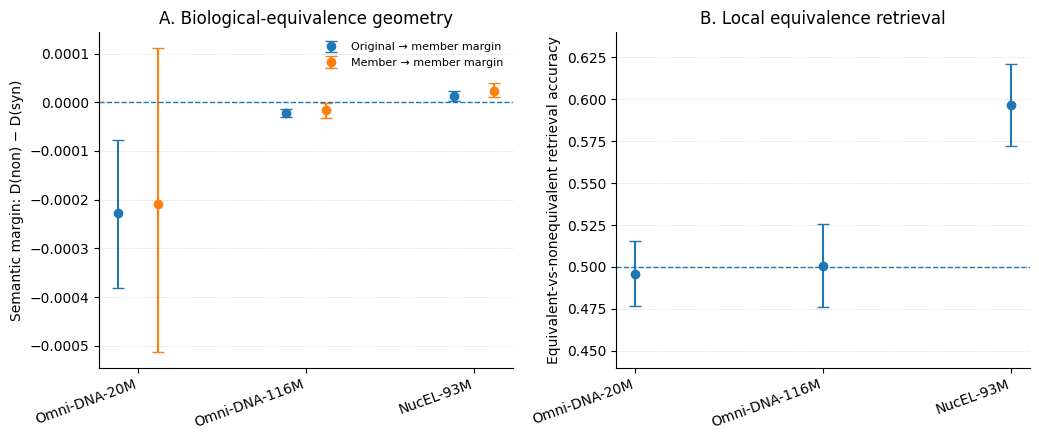

Saved:
/content/drive/MyDrive/wiml_equivalence/figures/figure3_cross_model_equivalence.png
/content/drive/MyDrive/wiml_equivalence/figures/figure3_cross_model_equivalence.pdf


In [67]:
# FINAL CROSS-MODEL FIGURE — 91-source matched comparison

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

comparison_df = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "cross_family_comparison_91_sources.csv"
)

models = [
    "Omni-DNA-20M",
    "Omni-DNA-116M",
    "NucEL-93M",
]

metrics = [
    "original_margin_non_minus_syn",
    "pairwise_margin_non_minus_syn",
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10.5, 4.5),
)

# Panel A: semantic margins
ax = axes[0]

x_positions = np.arange(len(models))
offsets = [-0.12, 0.12]

for metric_idx, metric in enumerate(metrics):

    metric_df = (
        comparison_df[
            comparison_df["metric"] == metric
        ]
        .set_index("model")
        .loc[models]
        .reset_index()
    )

    estimates = metric_df["mean"].to_numpy()
    lower = metric_df["ci95_low"].to_numpy()
    upper = metric_df["ci95_high"].to_numpy()

    xerr = np.vstack([
        estimates - lower,
        upper - estimates,
    ])

    label = (
        "Original → member margin"
        if metric == "original_margin_non_minus_syn"
        else "Member → member margin"
    )

    ax.errorbar(
        x_positions + offsets[metric_idx],
        estimates,
        yerr=xerr,
        fmt="o",
        capsize=4,
        linewidth=1.5,
        label=label,
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xticks(x_positions)
ax.set_xticklabels(
    models,
    rotation=20,
    ha="right",
)

ax.set_ylabel(
    "Semantic margin: D(non) − D(syn)"
)

ax.set_title(
    "A. Biological-equivalence geometry"
)

ax.legend(
    frameon=False,
    fontsize=8,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.4,
)


# Panel B: retrieval accuracy
ax = axes[1]

retrieval_df = (
    comparison_df[
        comparison_df["metric"]
        == "equivalence_retrieval_accuracy"
    ]
    .set_index("model")
    .loc[models]
    .reset_index()
)

accuracy = retrieval_df["mean"].to_numpy()
lower = retrieval_df["ci95_low"].to_numpy()
upper = retrieval_df["ci95_high"].to_numpy()

yerr = np.vstack([
    accuracy - lower,
    upper - accuracy,
])

ax.errorbar(
    x_positions,
    accuracy,
    yerr=yerr,
    fmt="o",
    capsize=4,
    linewidth=1.5,
)

ax.axhline(
    0.5,
    linestyle="--",
    linewidth=1,
)

ax.set_xticks(x_positions)
ax.set_xticklabels(
    models,
    rotation=20,
    ha="right",
)

ax.set_ylabel(
    "Equivalent-vs-nonequivalent retrieval accuracy"
)

ax.set_ylim(
    0.44,
    0.64,
)

ax.set_title(
    "B. Local equivalence retrieval"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.4,
)

fig.tight_layout()

CROSS_MODEL_FIGURE_PNG = (
    PROJECT_ROOT
    / "figures"
    / "figure3_cross_model_equivalence.png"
)

CROSS_MODEL_FIGURE_PDF = (
    PROJECT_ROOT
    / "figures"
    / "figure3_cross_model_equivalence.pdf"
)

fig.savefig(
    CROSS_MODEL_FIGURE_PNG,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    CROSS_MODEL_FIGURE_PDF,
    bbox_inches="tight",
)

plt.show()

print("Saved:")
print(CROSS_MODEL_FIGURE_PNG)
print(CROSS_MODEL_FIGURE_PDF)

assert CROSS_MODEL_FIGURE_PNG.exists()
assert CROSS_MODEL_FIGURE_PDF.exists()
assert CROSS_MODEL_FIGURE_PNG.stat().st_size > 0
assert CROSS_MODEL_FIGURE_PDF.stat().st_size > 0

In [68]:
# FINAL CORE EXPERIMENT — Freeze complete multi-model artifact manifest

import json
import pandas as pd
from datetime import datetime, timezone

core_artifacts = {
    # Frozen datasets
    "pilot_sources":
        PROJECT_ROOT / "data" / "processed" / "original_sequences.csv",

    "structural_sources_100":
        PROJECT_ROOT / "data" / "processed" / "structural_extension_sources.csv",

    "structural_synonymous_100":
        PROJECT_ROOT / "data" / "processed" / "structural_synonymous_variants.csv",

    "structural_nonsynonymous_100":
        PROJECT_ROOT / "data" / "processed" / "structural_nonsynonymous_controls.csv",

    "cross_family_sources_91":
        PROJECT_ROOT / "data" / "processed" / "cross_family_sources_91.csv",

    "cross_family_synonymous_91":
        PROJECT_ROOT / "data" / "processed" / "cross_family_synonymous_variants_91.csv",

    "cross_family_nonsynonymous_91":
        PROJECT_ROOT / "data" / "processed" / "cross_family_nonsynonymous_controls_91.csv",

    # Embeddings
    "omnidna20m_structural_embeddings":
        PROJECT_ROOT / "embeddings" / "omnidna20m_structural_embeddings.pt",

    "omnidna116m_structural_embeddings":
        PROJECT_ROOT / "embeddings" / "omnidna116m_structural_embeddings.pt",

    "nucel93m_cross_family_embeddings":
        PROJECT_ROOT / "embeddings" / "nucel_cross_family_embeddings_91.pt",

    # Omni-DNA-20M
    "omni20_path":
        PROJECT_ROOT / "results" / "path_consistency_bootstrap_summary.csv",

    "omni20_geometry":
        PROJECT_ROOT / "results" / "equivalence_class_geometry_bootstrap_summary.csv",

    "omni20_retrieval":
        PROJECT_ROOT / "results" / "equivalence_retrieval_bootstrap_summary.csv",

    # Omni-DNA-116M
    "omni116_path":
        PROJECT_ROOT / "results" / "path_consistency_bootstrap_summary_116m.csv",

    "omni116_geometry":
        PROJECT_ROOT / "results" / "equivalence_class_geometry_bootstrap_summary_116m.csv",

    "omni116_retrieval":
        PROJECT_ROOT / "results" / "equivalence_retrieval_bootstrap_summary_116m.csv",

    # NucEL
    "nucel_path":
        PROJECT_ROOT / "results" / "path_consistency_bootstrap_summary_nucel.csv",

    "nucel_geometry":
        PROJECT_ROOT / "results" / "equivalence_class_geometry_bootstrap_summary_nucel.csv",

    "nucel_retrieval":
        PROJECT_ROOT / "results" / "equivalence_retrieval_bootstrap_summary_nucel.csv",

    # Cross-model results
    "omnidna_scale_comparison":
        PROJECT_ROOT / "results" / "omnidna_scale_comparison.csv",

    "cross_family_comparison_91":
        PROJECT_ROOT / "results" / "cross_family_comparison_91_sources.csv",

    # Figures
    "figure1_composition":
        PROJECT_ROOT / "figures" / "figure1_depth_vs_distance.png",

    "figure2_omni20_structure":
        PROJECT_ROOT / "figures" / "figure2_structural_geometry_20m.png",

    "figure3_cross_model":
        PROJECT_ROOT / "figures" / "figure3_cross_model_equivalence.png",
}

manifest_rows = []

for artifact, path in core_artifacts.items():

    exists = path.exists()
    size_bytes = path.stat().st_size if exists else 0

    manifest_rows.append({
        "artifact": artifact,
        "path": str(path),
        "exists": exists,
        "size_bytes": size_bytes,
    })

final_core_manifest_df = pd.DataFrame(
    manifest_rows
)

FINAL_CORE_MANIFEST_PATH = (
    PROJECT_ROOT
    / "metadata"
    / "final_core_experiment_manifest.csv"
)

final_core_manifest_df.to_csv(
    FINAL_CORE_MANIFEST_PATH,
    index=False,
)

final_core_summary = {
    "status": "CORE EXPERIMENT COMPLETE",
    "frozen_utc": datetime.now(timezone.utc).isoformat(),

    "models": {
        "Omni-DNA-20M": {
            "model_id": "zehui127/Omni-DNA-20M",
            "role": "primary pilot and structural model",
        },
        "Omni-DNA-116M": {
            "model_id": "zehui127/Omni-DNA-116M",
            "role": "same-family scale replication",
        },
        "NucEL-93M": {
            "model_id": "FreakingPotato/NucEL",
            "revision":
                "0c802982985e572d9dc0659b072a1ceb03c8000f",
            "role": "cross-family replication",
        },
    },

    "cohorts": {
        "pilot_sources": 300,
        "structural_sources": 100,
        "cross_family_matched_sources": 91,
        "paths_per_structural_source": 10,
        "composition_depth": 3,
    },

    "headline_result": (
        "Protein-level biological-equivalence geometry is model-dependent. "
        "Omni-DNA-20M and Omni-DNA-116M show chance-level local equivalence "
        "retrieval and do not recover the expected synonymous preference, "
        "whereas NucEL-93M shows tighter synonymous geometry and "
        "above-chance equivalence retrieval on the same matched cohort."
    ),

    "cross_family_retrieval_accuracy": {
        "Omni-DNA-20M": 0.4957265,
        "Omni-DNA-116M": 0.5003663,
        "NucEL-93M": 0.5964591,
    },
}

FINAL_CORE_SUMMARY_PATH = (
    PROJECT_ROOT
    / "metadata"
    / "final_core_experiment_summary.json"
)

with open(
    FINAL_CORE_SUMMARY_PATH,
    "w",
) as f:
    json.dump(
        final_core_summary,
        f,
        indent=2,
    )

print(
    final_core_manifest_df[
        ["artifact", "exists", "size_bytes"]
    ].to_string(index=False)
)

print(
    "\nArtifacts present:",
    int(final_core_manifest_df["exists"].sum()),
    "/",
    len(final_core_manifest_df),
)

print("\nSaved:")
print(FINAL_CORE_MANIFEST_PATH)
print(FINAL_CORE_SUMMARY_PATH)

assert final_core_manifest_df["exists"].all()
assert (
    final_core_manifest_df["size_bytes"] > 0
).all()

assert len(final_core_manifest_df) == 24
assert FINAL_CORE_MANIFEST_PATH.exists()
assert FINAL_CORE_SUMMARY_PATH.exists()

                         artifact  exists  size_bytes
                    pilot_sources    True      324332
           structural_sources_100    True      100108
        structural_synonymous_100    True     4194885
     structural_nonsynonymous_100    True     4197880
          cross_family_sources_91    True       86263
       cross_family_synonymous_91    True     3599007
    cross_family_nonsynonymous_91    True     3601732
 omnidna20m_structural_embeddings    True     6248280
omnidna116m_structural_embeddings    True    18741087
 nucel93m_cross_family_embeddings    True    11370328
                      omni20_path    True         294
                  omni20_geometry    True         331
                 omni20_retrieval    True         304
                     omni116_path    True         295
                 omni116_geometry    True         333
                omni116_retrieval    True         286
                       nucel_path    True         313
                   nucel_geo

# DOWNSTREAM PROBE 1 — Freeze protein-level amino-acid composition targets

In [69]:
# DOWNSTREAM PROBE 1 — Freeze protein-level amino-acid composition targets

import numpy as np
import pandas as pd

AA_ORDER = list("ACDEFGHIKLMNPQRSTVWY")
AA_TO_INDEX = {
    aa: i
    for i, aa in enumerate(AA_ORDER)
}

def protein_composition_from_dna(seq):
    protein = translate_cds(seq)

    # Exclude terminal stop if represented by "*".
    protein = protein.replace("*", "")

    counts = np.zeros(
        len(AA_ORDER),
        dtype=np.float64,
    )

    for aa in protein:
        if aa not in AA_TO_INDEX:
            raise ValueError(
                f"Unexpected amino acid: {aa}"
            )

        counts[
            AA_TO_INDEX[aa]
        ] += 1.0

    assert counts.sum() > 0

    return counts / counts.sum()


probe_target_records = []

for _, row in cross_family_source_df.iterrows():

    sequence_id = row["sequence_id"]
    original_seq = row["original_sequence"]

    original_target = (
        protein_composition_from_dna(
            original_seq
        )
    )

    probe_target_records.append({
        "sequence_id": sequence_id,
        "condition": "original",
        "path_id": -1,
        "depth": 0,
        **{
            f"aa_{aa}": original_target[i]
            for i, aa in enumerate(AA_ORDER)
        },
    })


for condition, variant_df in [
    (
        "synonymous",
        cross_family_syn_df,
    ),
    (
        "nonsynonymous",
        cross_family_non_df,
    ),
]:

    depth3_df = variant_df[
        variant_df["depth"] == 3
    ]

    for _, row in depth3_df.iterrows():

        target = (
            protein_composition_from_dna(
                row["variant_sequence"]
            )
        )

        probe_target_records.append({
            "sequence_id": row["sequence_id"],
            "condition": condition,
            "path_id": int(row["path_id"]),
            "depth": 3,
            **{
                f"aa_{aa}": target[i]
                for i, aa in enumerate(AA_ORDER)
            },
        })


protein_probe_targets_df = pd.DataFrame(
    probe_target_records
)

AA_COLUMNS = [
    f"aa_{aa}"
    for aa in AA_ORDER
]

print("Target rows:", len(protein_probe_targets_df))

print("\nRows by condition:")
print(
    protein_probe_targets_df[
        "condition"
    ].value_counts()
)


# Verify every target is a valid amino-acid composition.
target_sums = (
    protein_probe_targets_df[
        AA_COLUMNS
    ].sum(axis=1)
)

print("\nTarget-vector sum range:")
print(
    float(target_sums.min()),
    float(target_sums.max()),
)


# Synonymous targets must exactly match their source protein target.
original_targets = (
    protein_probe_targets_df[
        protein_probe_targets_df[
            "condition"
        ] == "original"
    ]
    .set_index("sequence_id")[
        AA_COLUMNS
    ]
)

syn_targets = (
    protein_probe_targets_df[
        protein_probe_targets_df[
            "condition"
        ] == "synonymous"
    ]
)

syn_target_differences = []

for row in syn_targets.itertuples():

    source_target = (
        original_targets.loc[
            row.sequence_id
        ].to_numpy()
    )

    variant_target = np.array(
        [
            getattr(row, col)
            for col in AA_COLUMNS
        ]
    )

    syn_target_differences.append(
        np.abs(
            variant_target
            - source_target
        ).max()
    )


# Nonsynonymous targets should differ from source targets.
non_targets = (
    protein_probe_targets_df[
        protein_probe_targets_df[
            "condition"
        ] == "nonsynonymous"
    ]
)

non_target_l1_changes = []

for row in non_targets.itertuples():

    source_target = (
        original_targets.loc[
            row.sequence_id
        ].to_numpy()
    )

    variant_target = np.array(
        [
            getattr(row, col)
            for col in AA_COLUMNS
        ]
    )

    non_target_l1_changes.append(
        np.abs(
            variant_target
            - source_target
        ).sum()
    )


print(
    "\nMaximum synonymous target difference:",
    max(syn_target_differences)
)

print(
    "Nonsynonymous target L1 change:"
)

print(
    pd.Series(
        non_target_l1_changes
    ).describe(
        percentiles=[
            0.10,
            0.50,
            0.90,
            0.95,
        ]
    )
)


PROBE_TARGET_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "protein_semantic_probe_targets_91.csv"
)

protein_probe_targets_df.to_csv(
    PROBE_TARGET_PATH,
    index=False,
)

print("\nSaved:")
print(PROBE_TARGET_PATH)

assert len(protein_probe_targets_df) == (
    91 + 910 + 910
)

assert np.allclose(
    target_sums.to_numpy(),
    1.0,
    atol=1e-12,
)

assert max(
    syn_target_differences
) < 1e-12

assert min(
    non_target_l1_changes
) > 0

assert PROBE_TARGET_PATH.exists()
assert PROBE_TARGET_PATH.stat().st_size > 0

Target rows: 1911

Rows by condition:
condition
synonymous       910
nonsynonymous    910
original          91
Name: count, dtype: int64

Target-vector sum range:
0.9999999999999997 1.0000000000000002

Maximum synonymous target difference: 0.0
Nonsynonymous target L1 change:
count    910.000000
mean       0.029368
std        0.013313
min        0.005882
10%        0.014706
50%        0.024700
90%        0.053097
95%        0.055046
max        0.060606
dtype: float64

Saved:
/content/drive/MyDrive/wiml_equivalence/data/processed/protein_semantic_probe_targets_91.csv


In [70]:
# DOWNSTREAM PROBE 2 — Build aligned 91-source embedding/target tables

import numpy as np
import pandas as pd
import torch

# Build a canonical key order from the frozen target table.
probe_keys_df = (
    protein_probe_targets_df[
        [
            "sequence_id",
            "condition",
            "path_id",
            "depth",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(probe_keys_df) == 1911

def extract_model_probe_embeddings(
    embedding_matrix,
    metadata_df,
    model_name,
):
    lookup = {
        (
            row.sequence_id,
            row.condition,
            int(row.path_id),
            int(row.depth),
        ): int(row.embedding_index)
        for row in metadata_df.itertuples()
    }

    indices = []

    for row in probe_keys_df.itertuples():

        key = (
            row.sequence_id,
            row.condition,
            int(row.path_id),
            int(row.depth),
        )

        assert key in lookup, (
            f"Missing {model_name} embedding for {key}"
        )

        indices.append(
            lookup[key]
        )

    X = (
        embedding_matrix[
            indices
        ]
        .float()
        .cpu()
        .numpy()
    )

    return X


# Omni-DNA-20M: use 100-source embeddings, subset to 91-source keys.
X_omni20_probe = extract_model_probe_embeddings(
    structural_embedding_matrix,
    structural_embedding_metadata_df,
    "Omni-DNA-20M",
)

# Omni-DNA-116M
X_omni116_probe = extract_model_probe_embeddings(
    structural_embedding_matrix_116m,
    metadata_116m_df,
    "Omni-DNA-116M",
)

# NucEL-93M
X_nucel_probe = extract_model_probe_embeddings(
    nucel_embedding_matrix,
    nucel_embedding_metadata_df,
    "NucEL-93M",
)

Y_probe = (
    protein_probe_targets_df[
        AA_COLUMNS
    ]
    .to_numpy(
        dtype=np.float64
    )
)

probe_model_shapes = {
    "Omni-DNA-20M": X_omni20_probe.shape,
    "Omni-DNA-116M": X_omni116_probe.shape,
    "NucEL-93M": X_nucel_probe.shape,
}

print("Embedding shapes:")
for model_name, shape in probe_model_shapes.items():
    print(
        f"{model_name:15s}: {shape}"
    )

print("\nTarget shape:")
print(Y_probe.shape)

print("\nRows by condition:")
print(
    probe_keys_df[
        "condition"
    ].value_counts()
)

print("\nFinite checks:")
print(
    "Omni-20M :",
    np.isfinite(
        X_omni20_probe
    ).all()
)
print(
    "Omni-116M:",
    np.isfinite(
        X_omni116_probe
    ).all()
)
print(
    "NucEL-93M:",
    np.isfinite(
        X_nucel_probe
    ).all()
)
print(
    "Targets   :",
    np.isfinite(
        Y_probe
    ).all()
)

PROBE_KEYS_PATH = (
    PROJECT_ROOT
    / "metadata"
    / "protein_probe_embedding_alignment_91.csv"
)

probe_keys_df.to_csv(
    PROBE_KEYS_PATH,
    index=False,
)

assert X_omni20_probe.shape == (1911, 256)
assert X_omni116_probe.shape == (1911, 768)
assert X_nucel_probe.shape == (1911, 512)
assert Y_probe.shape == (1911, 20)

assert np.isfinite(X_omni20_probe).all()
assert np.isfinite(X_omni116_probe).all()
assert np.isfinite(X_nucel_probe).all()
assert np.isfinite(Y_probe).all()

assert (
    probe_keys_df[
        "condition"
    ].value_counts().to_dict()
    ==
    {
        "synonymous": 910,
        "nonsynonymous": 910,
        "original": 91,
    }
)

print("\nSaved:")
print(PROBE_KEYS_PATH)

Embedding shapes:
Omni-DNA-20M   : (1911, 256)
Omni-DNA-116M  : (1911, 768)
NucEL-93M      : (1911, 512)

Target shape:
(1911, 20)

Rows by condition:
condition
synonymous       910
nonsynonymous    910
original          91
Name: count, dtype: int64

Finite checks:
Omni-20M : True
Omni-116M: True
NucEL-93M: True
Targets   : True

Saved:
/content/drive/MyDrive/wiml_equivalence/metadata/protein_probe_embedding_alignment_91.csv


In [71]:
# DOWNSTREAM PROBE 3 — 5-fold source-level Ridge probe evaluation

import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

SEED = 42
N_FOLDS = 5

ALPHA_GRID = [
    1e-4,
    1e-3,
    1e-2,
    1e-1,
    1.0,
    10.0,
    100.0,
]

MODEL_PROBE_MATRICES = {
    "Omni-DNA-20M": X_omni20_probe,
    "Omni-DNA-116M": X_omni116_probe,
    "NucEL-93M": X_nucel_probe,
}

probe_metadata_df = probe_keys_df.copy()

# Original rows define the source-level train/test splits.
original_row_indices = (
    probe_metadata_df.index[
        probe_metadata_df["condition"] == "original"
    ]
    .to_numpy()
)

original_sequence_ids = (
    probe_metadata_df.loc[
        original_row_indices,
        "sequence_id",
    ]
    .to_numpy()
)

assert len(original_sequence_ids) == 91
assert len(np.unique(original_sequence_ids)) == 91

outer_cv = KFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED,
)

fold_assignment = {}

for fold_id, (_, test_pos) in enumerate(
    outer_cv.split(original_sequence_ids)
):
    for pos in test_pos:
        fold_assignment[
            original_sequence_ids[pos]
        ] = fold_id

assert len(fold_assignment) == 91

probe_prediction_records = []
probe_hyperparameter_records = []

for model_name, X_all in MODEL_PROBE_MATRICES.items():

    for fold_id in range(N_FOLDS):

        test_source_ids = {
            seq_id
            for seq_id, assigned_fold
            in fold_assignment.items()
            if assigned_fold == fold_id
        }

        train_source_ids = set(
            original_sequence_ids
        ) - test_source_ids

        train_mask = (
            (probe_metadata_df["condition"] == "original")
            &
            probe_metadata_df["sequence_id"].isin(
                train_source_ids
            )
        )

        train_indices = (
            probe_metadata_df.index[
                train_mask
            ].to_numpy()
        )

        X_train = X_all[train_indices]
        Y_train = Y_probe[train_indices]

        # Inner source-level CV on original training sources only.
        inner_cv = KFold(
            n_splits=4,
            shuffle=True,
            random_state=SEED + fold_id,
        )

        alpha_scores = []

        for alpha in ALPHA_GRID:

            inner_mse = []

            for inner_train_pos, inner_val_pos in inner_cv.split(
                X_train
            ):

                probe = Pipeline([
                    (
                        "scale",
                        StandardScaler(),
                    ),
                    (
                        "ridge",
                        Ridge(
                            alpha=alpha,
                        ),
                    ),
                ])

                probe.fit(
                    X_train[inner_train_pos],
                    Y_train[inner_train_pos],
                )

                pred = probe.predict(
                    X_train[inner_val_pos]
                )

                mse = mean_squared_error(
                    Y_train[inner_val_pos],
                    pred,
                )

                inner_mse.append(mse)

            alpha_scores.append({
                "alpha": alpha,
                "mean_inner_mse": np.mean(
                    inner_mse
                ),
            })

        alpha_scores_df = pd.DataFrame(
            alpha_scores
        )

        best_alpha = float(
            alpha_scores_df.sort_values(
                "mean_inner_mse"
            ).iloc[0]["alpha"]
        )

        final_probe = Pipeline([
            (
                "scale",
                StandardScaler(),
            ),
            (
                "ridge",
                Ridge(
                    alpha=best_alpha,
                ),
            ),
        ])

        final_probe.fit(
            X_train,
            Y_train,
        )

        # Evaluate all examples belonging to held-out source CDSs.
        test_mask = (
            probe_metadata_df[
                "sequence_id"
            ].isin(test_source_ids)
        )

        test_indices = (
            probe_metadata_df.index[
                test_mask
            ].to_numpy()
        )

        predictions = final_probe.predict(
            X_all[test_indices]
        )

        for local_i, global_idx in enumerate(
            test_indices
        ):

            metadata_row = (
                probe_metadata_df.loc[
                    global_idx
                ]
            )

            true_target = Y_probe[
                global_idx
            ]

            pred_target = predictions[
                local_i
            ]

            mse = np.mean(
                (
                    pred_target
                    - true_target
                ) ** 2
            )

            mae = np.mean(
                np.abs(
                    pred_target
                    - true_target
                )
            )

            probe_prediction_records.append({
                "model": model_name,
                "fold": fold_id,
                "sequence_id":
                    metadata_row["sequence_id"],
                "condition":
                    metadata_row["condition"],
                "path_id":
                    int(metadata_row["path_id"]),
                "depth":
                    int(metadata_row["depth"]),
                "target_mse": mse,
                "target_mae": mae,
                **{
                    f"pred_{aa}":
                        pred_target[i]
                    for i, aa
                    in enumerate(AA_ORDER)
                },
            })

        probe_hyperparameter_records.append({
            "model": model_name,
            "fold": fold_id,
            "n_train_sources":
                len(train_source_ids),
            "n_test_sources":
                len(test_source_ids),
            "best_alpha":
                best_alpha,
        })


probe_predictions_df = pd.DataFrame(
    probe_prediction_records
)

probe_hyperparameters_df = pd.DataFrame(
    probe_hyperparameter_records
)

print("Prediction rows:", len(probe_predictions_df))

print("\nRows by model and condition:")
print(
    probe_predictions_df
    .groupby(
        ["model", "condition"]
    )
    .size()
)

print("\nSelected Ridge alphas:")
print(
    probe_hyperparameters_df
    .pivot(
        index="fold",
        columns="model",
        values="best_alpha",
    )
)

print("\nOriginal held-out MSE:")
print(
    probe_predictions_df[
        probe_predictions_df[
            "condition"
        ] == "original"
    ]
    .groupby("model")[
        "target_mse"
    ]
    .agg(
        ["mean", "median", "std"]
    )
)

PROBE_PREDICTIONS_PATH = (
    PROJECT_ROOT
    / "results"
    / "protein_semantic_probe_predictions.csv"
)

PROBE_HYPERPARAMETERS_PATH = (
    PROJECT_ROOT
    / "metadata"
    / "protein_semantic_probe_hyperparameters.csv"
)

probe_predictions_df.to_csv(
    PROBE_PREDICTIONS_PATH,
    index=False,
)

probe_hyperparameters_df.to_csv(
    PROBE_HYPERPARAMETERS_PATH,
    index=False,
)

assert len(probe_predictions_df) == (
    1911 * 3
)

assert (
    probe_predictions_df[
        ["model", "sequence_id", "condition", "path_id"]
    ]
    .duplicated()
    .sum()
    == 0
)

assert np.isfinite(
    probe_predictions_df[
        [
            "target_mse",
            "target_mae",
        ]
    ].to_numpy()
).all()

assert len(probe_hyperparameters_df) == 15

print("\nSaved:")
print(PROBE_PREDICTIONS_PATH)
print(PROBE_HYPERPARAMETERS_PATH)

/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.26084e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=5.47043e-09): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.10638e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=8.93189e-09): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=4.41464e-09): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/pytho

Prediction rows: 5733

Rows by model and condition:
model          condition    
NucEL-93M      nonsynonymous    910
               original          91
               synonymous       910
Omni-DNA-116M  nonsynonymous    910
               original          91
               synonymous       910
Omni-DNA-20M   nonsynonymous    910
               original          91
               synonymous       910
dtype: int64

Selected Ridge alphas:
model  NucEL-93M  Omni-DNA-116M  Omni-DNA-20M
fold                                         
0          100.0          100.0         100.0
1          100.0          100.0         100.0
2          100.0          100.0         100.0
3          100.0          100.0         100.0
4          100.0          100.0         100.0

Original held-out MSE:
                   mean    median       std
model                                      
NucEL-93M      0.000459  0.000306  0.000962
Omni-DNA-116M  0.000546  0.000393  0.000820
Omni-DNA-20M   0.000532  0.000378  0

In [72]:
# DOWNSTREAM PROBE 3B — Refit numerically stable Ridge probes

import warnings
import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

SEED = 42
N_FOLDS = 5

# Expanded because the previous search selected the old maximum (100)
# in every fold for every model.
STABLE_ALPHA_GRID = [
    1e-2,
    1e-1,
    1.0,
    10.0,
    100.0,
    1e3,
    1e4,
    1e5,
    1e6,
    1e7,
]

MODEL_PROBE_MATRICES = {
    "Omni-DNA-20M": X_omni20_probe.astype(np.float64),
    "Omni-DNA-116M": X_omni116_probe.astype(np.float64),
    "NucEL-93M": X_nucel_probe.astype(np.float64),
}

probe_prediction_records_stable = []
probe_hyperparameter_records_stable = []
warning_records = []

for model_name, X_all in MODEL_PROBE_MATRICES.items():

    for fold_id in range(N_FOLDS):

        test_source_ids = {
            seq_id
            for seq_id, assigned_fold in fold_assignment.items()
            if assigned_fold == fold_id
        }

        train_source_ids = (
            set(original_sequence_ids)
            - test_source_ids
        )

        train_mask = (
            (probe_metadata_df["condition"] == "original")
            &
            probe_metadata_df["sequence_id"].isin(
                train_source_ids
            )
        )

        train_indices = (
            probe_metadata_df.index[
                train_mask
            ].to_numpy()
        )

        X_train = X_all[train_indices]
        Y_train = Y_probe[
            train_indices
        ].astype(np.float64)

        inner_cv = KFold(
            n_splits=4,
            shuffle=True,
            random_state=SEED + fold_id,
        )

        alpha_scores = []

        for alpha in STABLE_ALPHA_GRID:

            inner_mse = []

            for inner_train_pos, inner_val_pos in inner_cv.split(
                X_train
            ):

                probe = Pipeline([
                    (
                        "scale",
                        StandardScaler(),
                    ),
                    (
                        "ridge",
                        Ridge(
                            alpha=alpha,
                            solver="svd",
                        ),
                    ),
                ])

                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")

                    probe.fit(
                        X_train[inner_train_pos],
                        Y_train[inner_train_pos],
                    )

                    pred = probe.predict(
                        X_train[inner_val_pos]
                    )

                for warning in caught:
                    warning_records.append({
                        "model": model_name,
                        "fold": fold_id,
                        "alpha": alpha,
                        "warning":
                            str(warning.message),
                    })

                inner_mse.append(
                    mean_squared_error(
                        Y_train[inner_val_pos],
                        pred,
                    )
                )

            alpha_scores.append({
                "alpha": alpha,
                "mean_inner_mse":
                    float(np.mean(inner_mse)),
            })

        alpha_scores_df = pd.DataFrame(
            alpha_scores
        )

        best_row = (
            alpha_scores_df
            .sort_values(
                "mean_inner_mse",
                ascending=True,
            )
            .iloc[0]
        )

        best_alpha = float(
            best_row["alpha"]
        )

        final_probe = Pipeline([
            (
                "scale",
                StandardScaler(),
            ),
            (
                "ridge",
                Ridge(
                    alpha=best_alpha,
                    solver="svd",
                ),
            ),
        ])

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")

            final_probe.fit(
                X_train,
                Y_train,
            )

        for warning in caught:
            warning_records.append({
                "model": model_name,
                "fold": fold_id,
                "alpha": best_alpha,
                "warning":
                    str(warning.message),
            })

        test_mask = (
            probe_metadata_df[
                "sequence_id"
            ].isin(test_source_ids)
        )

        test_indices = (
            probe_metadata_df.index[
                test_mask
            ].to_numpy()
        )

        predictions = final_probe.predict(
            X_all[test_indices]
        )

        # Baseline: training-original mean target.
        baseline_target = (
            Y_train.mean(axis=0)
        )

        original_test_indices = [
            idx
            for idx in test_indices
            if probe_metadata_df.loc[
                idx, "condition"
            ] == "original"
        ]

        baseline_original_mse = np.mean([
            np.mean(
                (
                    baseline_target
                    - Y_probe[idx]
                ) ** 2
            )
            for idx in original_test_indices
        ])

        for local_i, global_idx in enumerate(
            test_indices
        ):

            metadata_row = (
                probe_metadata_df.loc[
                    global_idx
                ]
            )

            true_target = Y_probe[
                global_idx
            ]

            pred_target = predictions[
                local_i
            ]

            probe_prediction_records_stable.append({
                "model": model_name,
                "fold": fold_id,
                "sequence_id":
                    metadata_row["sequence_id"],
                "condition":
                    metadata_row["condition"],
                "path_id":
                    int(metadata_row["path_id"]),
                "depth":
                    int(metadata_row["depth"]),
                "target_mse":
                    np.mean(
                        (
                            pred_target
                            - true_target
                        ) ** 2
                    ),
                "target_mae":
                    np.mean(
                        np.abs(
                            pred_target
                            - true_target
                        )
                    ),
                **{
                    f"pred_{aa}":
                        pred_target[i]
                    for i, aa in enumerate(
                        AA_ORDER
                    )
                },
            })

        probe_hyperparameter_records_stable.append({
            "model": model_name,
            "fold": fold_id,
            "n_train_sources":
                len(train_source_ids),
            "n_test_sources":
                len(test_source_ids),
            "best_alpha":
                best_alpha,
            "best_inner_mse":
                float(
                    best_row[
                        "mean_inner_mse"
                    ]
                ),
            "baseline_original_mse":
                baseline_original_mse,
        })


probe_predictions_stable_df = pd.DataFrame(
    probe_prediction_records_stable
)

probe_hyperparameters_stable_df = pd.DataFrame(
    probe_hyperparameter_records_stable
)

probe_warnings_stable_df = pd.DataFrame(
    warning_records
)


original_probe_summary = (
    probe_predictions_stable_df[
        probe_predictions_stable_df[
            "condition"
        ] == "original"
    ]
    .groupby("model")[
        "target_mse"
    ]
    .agg(
        ["mean", "median", "std"]
    )
)

baseline_summary = (
    probe_hyperparameters_stable_df
    .groupby("model")[
        "baseline_original_mse"
    ]
    .mean()
)


print("Prediction rows:",
      len(probe_predictions_stable_df))

print("\nSelected stable Ridge alphas:")
print(
    probe_hyperparameters_stable_df
    .pivot(
        index="fold",
        columns="model",
        values="best_alpha",
    )
)

print("\nOriginal held-out probe MSE:")
print(original_probe_summary)

print("\nTraining-mean baseline MSE:")
print(baseline_summary)

print(
    "\nCaptured numerical warnings:",
    len(probe_warnings_stable_df)
)

if len(probe_warnings_stable_df):
    print(
        probe_warnings_stable_df[
            "warning"
        ]
        .value_counts()
        .head(10)
    )

STABLE_PROBE_PREDICTIONS_PATH = (
    PROJECT_ROOT
    / "results"
    / "protein_semantic_probe_predictions_stable.csv"
)

STABLE_PROBE_HYPERPARAMETERS_PATH = (
    PROJECT_ROOT
    / "metadata"
    / "protein_semantic_probe_hyperparameters_stable.csv"
)

probe_predictions_stable_df.to_csv(
    STABLE_PROBE_PREDICTIONS_PATH,
    index=False,
)

probe_hyperparameters_stable_df.to_csv(
    STABLE_PROBE_HYPERPARAMETERS_PATH,
    index=False,
)

assert len(probe_predictions_stable_df) == 5733
assert len(probe_hyperparameters_stable_df) == 15

assert np.isfinite(
    probe_predictions_stable_df[
        ["target_mse", "target_mae"]
    ].to_numpy()
).all()

assert len(probe_warnings_stable_df) == 0

# Fail loudly if the optimal regularization still hits
# the upper edge of the expanded grid.
assert not (
    probe_hyperparameters_stable_df[
        "best_alpha"
    ] == max(STABLE_ALPHA_GRID)
).any(), (
    "Best alpha still hits the maximum grid value; "
    "expand the regularization search again."
)

print("\nSaved:")
print(STABLE_PROBE_PREDICTIONS_PATH)
print(STABLE_PROBE_HYPERPARAMETERS_PATH)

Prediction rows: 5733

Selected stable Ridge alphas:
model  NucEL-93M  Omni-DNA-116M  Omni-DNA-20M
fold                                         
0          100.0         1000.0         100.0
1          100.0         1000.0         100.0
2          100.0         1000.0        1000.0
3         1000.0         1000.0        1000.0
4          100.0         1000.0         100.0

Original held-out probe MSE:
                   mean    median       std
model                                      
NucEL-93M      0.000474  0.000306  0.000971
Omni-DNA-116M  0.000519  0.000358  0.000782
Omni-DNA-20M   0.000541  0.000378  0.000827

Training-mean baseline MSE:
model
NucEL-93M        0.000654
Omni-DNA-116M    0.000654
Omni-DNA-20M     0.000654
Name: baseline_original_mse, dtype: float64

Captured numerical warnings: 0

Saved:
/content/drive/MyDrive/wiml_equivalence/results/protein_semantic_probe_predictions_stable.csv
/content/drive/MyDrive/wiml_equivalence/metadata/protein_semantic_probe_hyperparamet

In [73]:
# DOWNSTREAM PROBE 4 — Measure prediction instability under transformations

import numpy as np
import pandas as pd

PRED_COLUMNS = [
    f"pred_{aa}"
    for aa in AA_ORDER
]

probe_prediction_change_records = []

for model_name in probe_predictions_stable_df["model"].unique():

    model_df = (
        probe_predictions_stable_df[
            probe_predictions_stable_df["model"] == model_name
        ]
        .copy()
    )

    for sequence_id, source_df in model_df.groupby("sequence_id"):

        original_rows = source_df[
            source_df["condition"] == "original"
        ]

        assert len(original_rows) == 1

        original_row = original_rows.iloc[0]

        original_prediction = (
            original_row[PRED_COLUMNS]
            .to_numpy(dtype=float)
        )

        original_target = (
            original_targets.loc[
                sequence_id
            ]
            .to_numpy(dtype=float)
        )

        transformed_df = source_df[
            source_df["condition"].isin(
                [
                    "synonymous",
                    "nonsynonymous",
                ]
            )
        ]

        assert len(transformed_df) == 20

        for _, row in transformed_df.iterrows():

            transformed_prediction = (
                row[PRED_COLUMNS]
                .to_numpy(dtype=float)
            )

            prediction_change_l1 = np.abs(
                transformed_prediction
                - original_prediction
            ).sum()

            prediction_change_l2 = np.linalg.norm(
                transformed_prediction
                - original_prediction
            )

            if row["condition"] == "synonymous":

                true_target_change_l1 = 0.0
                target_change_alignment = np.nan

            else:

                target_row = (
                    protein_probe_targets_df[
                        (
                            protein_probe_targets_df["sequence_id"]
                            == sequence_id
                        )
                        &
                        (
                            protein_probe_targets_df["condition"]
                            == "nonsynonymous"
                        )
                        &
                        (
                            protein_probe_targets_df["path_id"]
                            == int(row["path_id"])
                        )
                    ]
                )

                assert len(target_row) == 1

                transformed_target = (
                    target_row[
                        AA_COLUMNS
                    ]
                    .iloc[0]
                    .to_numpy(dtype=float)
                )

                true_delta = (
                    transformed_target
                    - original_target
                )

                predicted_delta = (
                    transformed_prediction
                    - original_prediction
                )

                true_target_change_l1 = (
                    np.abs(true_delta).sum()
                )

                true_norm = np.linalg.norm(
                    true_delta
                )

                pred_norm = np.linalg.norm(
                    predicted_delta
                )

                if true_norm > 0 and pred_norm > 0:
                    target_change_alignment = (
                        np.dot(
                            true_delta,
                            predicted_delta,
                        )
                        /
                        (
                            true_norm
                            * pred_norm
                        )
                    )
                else:
                    target_change_alignment = np.nan

            probe_prediction_change_records.append({
                "model": model_name,
                "sequence_id": sequence_id,
                "condition": row["condition"],
                "path_id": int(row["path_id"]),
                "prediction_change_l1":
                    prediction_change_l1,
                "prediction_change_l2":
                    prediction_change_l2,
                "true_target_change_l1":
                    true_target_change_l1,
                "target_change_alignment":
                    target_change_alignment,
            })


probe_prediction_changes_df = pd.DataFrame(
    probe_prediction_change_records
)

print("Transformation rows:",
      len(probe_prediction_changes_df))

print("\nPrediction change from original:")
print(
    probe_prediction_changes_df
    .groupby(
        ["model", "condition"]
    )[
        "prediction_change_l1"
    ]
    .agg(
        ["mean", "median", "std"]
    )
)

print("\nNonsynonymous target-change alignment:")
print(
    probe_prediction_changes_df[
        probe_prediction_changes_df[
            "condition"
        ] == "nonsynonymous"
    ]
    .groupby("model")[
        "target_change_alignment"
    ]
    .agg(
        ["mean", "median", "std"]
    )
)

# Aggregate to source level for later paired bootstrap.
source_probe_stability_df = (
    probe_prediction_changes_df
    .groupby(
        [
            "model",
            "sequence_id",
            "condition",
        ],
        as_index=False,
    )
    .agg(
        mean_prediction_change_l1=(
            "prediction_change_l1",
            "mean",
        ),
        median_prediction_change_l1=(
            "prediction_change_l1",
            "median",
        ),
        mean_prediction_change_l2=(
            "prediction_change_l2",
            "mean",
        ),
        mean_target_change_alignment=(
            "target_change_alignment",
            "mean",
        ),
    )
)

paired_probe_stability_df = (
    source_probe_stability_df[
        source_probe_stability_df[
            "condition"
        ] == "synonymous"
    ]
    .merge(
        source_probe_stability_df[
            source_probe_stability_df[
                "condition"
            ] == "nonsynonymous"
        ],
        on=[
            "model",
            "sequence_id",
        ],
        suffixes=("_syn", "_non"),
        validate="one_to_one",
    )
)

paired_probe_stability_df[
    "non_minus_syn_prediction_change_l1"
] = (
    paired_probe_stability_df[
        "mean_prediction_change_l1_non"
    ]
    -
    paired_probe_stability_df[
        "mean_prediction_change_l1_syn"
    ]
)

print("\nSource-level downstream semantic margin")
print("(positive = protein-changing controls alter the readout more):")

print(
    paired_probe_stability_df
    .groupby("model")[
        "non_minus_syn_prediction_change_l1"
    ]
    .agg(
        ["mean", "median", "std"]
    )
)

PROBE_CHANGE_PATH = (
    PROJECT_ROOT
    / "results"
    / "protein_semantic_probe_prediction_changes.csv"
)

PROBE_SOURCE_STABILITY_PATH = (
    PROJECT_ROOT
    / "results"
    / "protein_semantic_probe_source_stability.csv"
)

probe_prediction_changes_df.to_csv(
    PROBE_CHANGE_PATH,
    index=False,
)

paired_probe_stability_df.to_csv(
    PROBE_SOURCE_STABILITY_PATH,
    index=False,
)

assert len(probe_prediction_changes_df) == 5460
assert len(paired_probe_stability_df) == 273

assert np.isfinite(
    probe_prediction_changes_df[
        [
            "prediction_change_l1",
            "prediction_change_l2",
            "true_target_change_l1",
        ]
    ].to_numpy()
).all()

print("\nSaved:")
print(PROBE_CHANGE_PATH)
print(PROBE_SOURCE_STABILITY_PATH)

Transformation rows: 5460

Prediction change from original:
                                 mean    median       std
model         condition                                  
NucEL-93M     nonsynonymous  0.024765  0.021008  0.014973
              synonymous     0.020950  0.017808  0.012298
Omni-DNA-116M nonsynonymous  0.019541  0.016914  0.010586
              synonymous     0.019531  0.017520  0.010001
Omni-DNA-20M  nonsynonymous  0.023371  0.019473  0.016094
              synonymous     0.023344  0.020152  0.015446

Nonsynonymous target-change alignment:
                   mean    median       std
model                                      
NucEL-93M      0.319113  0.341571  0.230373
Omni-DNA-116M  0.196668  0.201958  0.221513
Omni-DNA-20M   0.187461  0.205487  0.228537

Source-level downstream semantic margin
(positive = protein-changing controls alter the readout more):
                   mean    median       std
model                                      
NucEL-93M      0.003815 

In [74]:
# DOWNSTREAM PROBE 5 — Source-level bootstrap of downstream consequence metrics

import numpy as np
import pandas as pd

N_BOOT = 10000
rng_master = np.random.default_rng(SEED)

bootstrap_summary_records = []

models = [
    "Omni-DNA-20M",
    "Omni-DNA-116M",
    "NucEL-93M",
]

for model_name in models:

    model_margin_df = (
        paired_probe_stability_df[
            paired_probe_stability_df["model"] == model_name
        ]
        .copy()
        .sort_values("sequence_id")
        .reset_index(drop=True)
    )

    assert len(model_margin_df) == 91

    margin_values = (
        model_margin_df[
            "non_minus_syn_prediction_change_l1"
        ]
        .to_numpy(dtype=float)
    )

    # Nonsynonymous alignment is stored in the nonsynonymous-side aggregate.
    alignment_values = (
        model_margin_df[
            "mean_target_change_alignment_non"
        ]
        .to_numpy(dtype=float)
    )

    assert np.isfinite(margin_values).all()
    assert np.isfinite(alignment_values).all()

    # Independent but reproducible stream per model.
    model_seed = (
        SEED
        + models.index(model_name) * 1000
    )

    rng = np.random.default_rng(
        model_seed
    )

    boot_margin = np.empty(N_BOOT)
    boot_alignment = np.empty(N_BOOT)

    for i in range(N_BOOT):

        idx = rng.integers(
            0,
            len(model_margin_df),
            size=len(model_margin_df),
        )

        boot_margin[i] = (
            margin_values[idx].mean()
        )

        boot_alignment[i] = (
            alignment_values[idx].mean()
        )

    margin_ci = np.quantile(
        boot_margin,
        [0.025, 0.975],
    )

    alignment_ci = np.quantile(
        boot_alignment,
        [0.025, 0.975],
    )

    bootstrap_summary_records.append({
        "model": model_name,
        "metric":
            "downstream_semantic_margin_non_minus_syn_l1",
        "n_sources": 91,
        "mean":
            margin_values.mean(),
        "median":
            np.median(margin_values),
        "ci95_low":
            margin_ci[0],
        "ci95_high":
            margin_ci[1],
        "fraction_positive":
            np.mean(margin_values > 0),
        "reference":
            0.0,
    })

    bootstrap_summary_records.append({
        "model": model_name,
        "metric":
            "nonsynonymous_target_change_alignment",
        "n_sources": 91,
        "mean":
            alignment_values.mean(),
        "median":
            np.median(alignment_values),
        "ci95_low":
            alignment_ci[0],
        "ci95_high":
            alignment_ci[1],
        "fraction_positive":
            np.mean(alignment_values > 0),
        "reference":
            0.0,
    })


downstream_probe_bootstrap_df = pd.DataFrame(
    bootstrap_summary_records
)

print(
    downstream_probe_bootstrap_df[
        [
            "model",
            "metric",
            "mean",
            "median",
            "ci95_low",
            "ci95_high",
            "fraction_positive",
            "reference",
        ]
    ].to_string(index=False)
)

DOWNSTREAM_PROBE_BOOTSTRAP_PATH = (
    PROJECT_ROOT
    / "results"
    / "protein_semantic_probe_bootstrap_summary.csv"
)

downstream_probe_bootstrap_df.to_csv(
    DOWNSTREAM_PROBE_BOOTSTRAP_PATH,
    index=False,
)

print("\nSaved:")
print(DOWNSTREAM_PROBE_BOOTSTRAP_PATH)

assert len(downstream_probe_bootstrap_df) == 6

assert np.isfinite(
    downstream_probe_bootstrap_df[
        [
            "mean",
            "median",
            "ci95_low",
            "ci95_high",
            "fraction_positive",
        ]
    ].to_numpy()
).all()

assert (
    downstream_probe_bootstrap_df[
        "n_sources"
    ] == 91
).all()

        model                                      metric     mean   median  ci95_low  ci95_high  fraction_positive  reference
 Omni-DNA-20M downstream_semantic_margin_non_minus_syn_l1 0.000028 0.000012 -0.000560   0.000630           0.516484        0.0
 Omni-DNA-20M       nonsynonymous_target_change_alignment 0.187461 0.185292  0.172110   0.203019           1.000000        0.0
Omni-DNA-116M downstream_semantic_margin_non_minus_syn_l1 0.000010 0.000351 -0.000605   0.000638           0.549451        0.0
Omni-DNA-116M       nonsynonymous_target_change_alignment 0.196668 0.191409  0.181832   0.211073           0.989011        0.0
    NucEL-93M downstream_semantic_margin_non_minus_syn_l1 0.003815 0.003233  0.002903   0.004860           0.923077        0.0
    NucEL-93M       nonsynonymous_target_change_alignment 0.319113 0.337655  0.297027   0.341099           0.989011        0.0

Saved:
/content/drive/MyDrive/wiml_equivalence/results/protein_semantic_probe_bootstrap_summary.csv


# JEPA-DNA 1 — Pin and inspect the official NVIDIA NTv3 checkpoint

In [75]:
# JEPA-DNA 1 — Pin and inspect the official NVIDIA NTv3 checkpoint

import json
from pathlib import Path

from huggingface_hub import HfApi, hf_hub_download

JEPA_MODEL_ID = "nvidia/NV-JEPA-DNA-NTv3"

api = HfApi()

info = api.model_info(
    JEPA_MODEL_ID,
    files_metadata=True,
)

JEPA_REVISION = info.sha

print("Model ID:", JEPA_MODEL_ID)
print("Pinned revision:", JEPA_REVISION)
print("Author:", info.author)
print("Pipeline tag:", info.pipeline_tag)
print("Library:", info.library_name)

siblings = sorted(
    [
        f.rfilename
        for f in info.siblings
    ]
)

print("\nRepository files:")
for filename in siblings:
    print(filename)

assert JEPA_REVISION is not None
assert len(JEPA_REVISION) >= 7
assert "config.json" in siblings

config_path = hf_hub_download(
    repo_id=JEPA_MODEL_ID,
    filename="config.json",
    revision=JEPA_REVISION,
)

with open(config_path, "r") as f:
    jepa_config = json.load(f)

print("\nConfig:")
for key in [
    "architectures",
    "model_type",
    "hidden_size",
    "d_model",
    "num_hidden_layers",
    "n_layer",
    "num_attention_heads",
    "n_head",
    "max_position_embeddings",
    "max_length",
    "vocab_size",
    "torch_dtype",
]:
    if key in jepa_config:
        print(f"{key}: {jepa_config[key]}")

print("\nAuto-map:")
print(
    json.dumps(
        jepa_config.get("auto_map", {}),
        indent=2,
    )
)

weight_files = [
    f
    for f in siblings
    if (
        f.endswith(".safetensors")
        or f.endswith(".bin")
    )
]

print("\nWeight files:")
for f in weight_files:
    print(f)

assert len(weight_files) > 0, (
    "No model weight file found."
)

JEPA_INSPECTION_PATH = (
    PROJECT_ROOT
    / "metadata"
    / "jepa_dna_ntv3_checkpoint_inspection.json"
)

inspection = {
    "model_id": JEPA_MODEL_ID,
    "revision": JEPA_REVISION,
    "author": info.author,
    "pipeline_tag": info.pipeline_tag,
    "library_name": info.library_name,
    "files": siblings,
    "config": jepa_config,
}

with open(
    JEPA_INSPECTION_PATH,
    "w",
) as f:
    json.dump(
        inspection,
        f,
        indent=2,
        default=str,
    )

assert JEPA_INSPECTION_PATH.exists()
assert JEPA_INSPECTION_PATH.stat().st_size > 0

print("\nSaved:")
print(JEPA_INSPECTION_PATH)

Model ID: nvidia/NV-JEPA-DNA-NTv3
Pinned revision: be526df5438b375223017051b1a36d8b9dee2f59
Author: nvidia
Pipeline tag: None
Library: None

Repository files:
.gitattributes
README.md
jepa_dna_ntv3_target.pt


AssertionError: 

In [76]:
# JEPA-DNA 1B — Inspect NVIDIA's official loading instructions

from huggingface_hub import hf_hub_download

README_PATH = hf_hub_download(
    repo_id=JEPA_MODEL_ID,
    filename="README.md",
    revision=JEPA_REVISION,
)

with open(
    README_PATH,
    "r",
    encoding="utf-8",
) as f:
    jepa_readme = f.read()

print("README characters:", len(jepa_readme))

keywords = [
    "install",
    "load",
    "checkpoint",
    "ntv3",
    "target",
    "encoder",
    "embedding",
    "representation",
    "inference",
    "github",
]

lines = jepa_readme.splitlines()

matched_indices = sorted({
    i
    for i, line in enumerate(lines)
    if any(
        keyword in line.lower()
        for keyword in keywords
    )
})

# Print surrounding context while avoiding duplicate overlapping blocks.
printed = set()

for idx in matched_indices:
    start = max(0, idx - 3)
    end = min(len(lines), idx + 10)

    block_key = (start, end)

    if any(
        start <= previous_idx < end
        for previous_idx in printed
    ):
        continue

    print(
        f"\n--- README lines {start + 1}-{end} ---"
    )

    for j in range(start, end):
        print(
            f"{j + 1:04d}: {lines[j]}"
        )

    printed.add(idx)

assert len(jepa_readme) > 0
assert "jepa" in jepa_readme.lower()

README.md: 0.00B [00:00, ?B/s]

README characters: 8600

--- README lines 2-14 ---
0002: license: other
0003: license_name: nvidia-noncommercial-license
0004: license_link: >-
0005:   https://developer.download.nvidia.com/licenses/NVIDIA-OneWay-Noncommercial-License-22Mar2022.pdf?t=eyJscyI6ImdzZW8iLCJsc2QiOiJ
0006: ---
0007: 
0008: # Model Overview
0009: 
0010: JEPA-DNA-NTv3-100M is the Nucleotide Transformer v3 (NTv3) 100M backbone of the JEPA-DNA family, a model-agnostic continual pre-training framework that grounds genomic foundation models by coupling standard token-level DNA language modeling with a Joint-Embedding Predictive Architecture (JEPA). Where conventional genomic models rely purely on masked language modeling and prioritize local token reconstruction, JEPA-DNA additionally supervises the model's global sequence embedding in a latent space, forcing it to predict the functional representation of masked genomic segments rather than their literal tokens. This shifts the learning signal from token recovery 

In [77]:
# JEPA-DNA 2 — Pin and inspect NVIDIA's official implementation

import os
import subprocess
from pathlib import Path

JEPA_REPO_URL = (
    "https://github.com/NVIDIA-Digital-Bio/JEPA-DNA.git"
)

JEPA_REPO_DIR = Path(
    "/content/JEPA-DNA"
)

if JEPA_REPO_DIR.exists():
    subprocess.run(
        [
            "git",
            "-C",
            str(JEPA_REPO_DIR),
            "fetch",
            "--all",
        ],
        check=True,
    )
else:
    subprocess.run(
        [
            "git",
            "clone",
            JEPA_REPO_URL,
            str(JEPA_REPO_DIR),
        ],
        check=True,
    )

repo_commit = subprocess.check_output(
    [
        "git",
        "-C",
        str(JEPA_REPO_DIR),
        "rev-parse",
        "HEAD",
    ],
    text=True,
).strip()

print("Repository:", JEPA_REPO_URL)
print("Pinned Git commit:", repo_commit)

files = sorted(
    p.relative_to(JEPA_REPO_DIR)
    for p in JEPA_REPO_DIR.rglob("*")
    if (
        p.is_file()
        and ".git" not in p.parts
    )
)

print("\nTop-level files:")
for p in sorted(JEPA_REPO_DIR.iterdir()):
    if p.name != ".git":
        print(p.name)

search_terms = [
    "ntv3",
    "jepa_dna_ntv3_target",
    "target.pt",
    "load_state_dict",
    "mean_pool",
    "mean pool",
    "embedding",
    "representation",
    "extract",
]

matches = []

text_suffixes = {
    ".py",
    ".md",
    ".yaml",
    ".yml",
    ".json",
    ".toml",
    ".txt",
    ".sh",
}

for relative_path in files:

    path = JEPA_REPO_DIR / relative_path

    if path.suffix.lower() not in text_suffixes:
        continue

    try:
        text = path.read_text(
            encoding="utf-8",
            errors="ignore",
        )
    except Exception:
        continue

    lines = text.splitlines()

    for line_number, line in enumerate(
        lines,
        start=1,
    ):
        lower = line.lower()

        if any(
            term.lower() in lower
            for term in search_terms
        ):
            matches.append(
                (
                    str(relative_path),
                    line_number,
                    line.strip(),
                )
            )

print("\nRelevant code/documentation matches:")
for path, line_number, line in matches[:250]:
    print(
        f"{path}:{line_number}: {line}"
    )

print(
    "\nTotal relevant matches:",
    len(matches),
)

requirements_candidates = [
    "requirements.txt",
    "pyproject.toml",
    "environment.yml",
    "environment.yaml",
    "setup.py",
]

print("\nEnvironment/install files found:")
for name in requirements_candidates:
    path = JEPA_REPO_DIR / name
    if path.exists():
        print(name)

JEPA_REPO_METADATA_PATH = (
    PROJECT_ROOT
    / "metadata"
    / "jepa_dna_official_repo_commit.txt"
)

JEPA_REPO_METADATA_PATH.write_text(
    "\n".join([
        f"repository={JEPA_REPO_URL}",
        f"commit={repo_commit}",
        f"hf_model={JEPA_MODEL_ID}",
        f"hf_revision={JEPA_REVISION}",
    ])
)

assert len(repo_commit) == 40
assert len(matches) > 0
assert JEPA_REPO_METADATA_PATH.exists()

print("\nSaved:")
print(JEPA_REPO_METADATA_PATH)

Repository: https://github.com/NVIDIA-Digital-Bio/JEPA-DNA.git
Pinned Git commit: 99e443341646e7cce3663f6a5a333cf421f24061

Top-level files:
.gitignore
LICENSE
README.md
SECURITY.md
THIRD_PARTY_NOTICES.md
jepa_dna
paper_examples
requirements.txt

Relevant code/documentation matches:
README.md:3: JEPA-DNA implements a genomic foundation model that combines generative pretraining with a joint-embedding predictive objective, so the model learns both local nucleotide patterns and broader functional structure from DNA sequences. Benchmarking uses the **GFMBench-API** evaluation library (install separately; see [GFMBench-API clone and PYTHONPATH](#gfmbench-api-clone-and-pythonpath) below).
README.md:88: # NTv3
README.md:89: hf download nvidia/NV-JEPA-DNA-NTv3 \
README.md:90: --local-dir paper_examples/paper_checkpoints/NV-JEPA-DNA-NTv3
README.md:101: | DNABERT-2 | `paper_examples/paper_checkpoints/NV-JEPA-DNA-DNABERT2/jepa_dna_dnabert2_target.pt` |
README.md:102: | NTv3 | `paper_examples/pap

In [78]:
# JEPA-DNA 3 — Inspect exact NTv3 constructor, pooling, and checkpoint loading

from pathlib import Path

NTV3_FILE = (
    JEPA_REPO_DIR
    / "jepa_dna"
    / "models"
    / "encoders"
    / "ntv3.py"
)

FACTORY_FILE = (
    JEPA_REPO_DIR
    / "jepa_dna"
    / "models"
    / "jepa_encoder_factory.py"
)

REQUIREMENTS_FILE = (
    JEPA_REPO_DIR
    / "requirements.txt"
)

README_FILE = (
    JEPA_REPO_DIR
    / "README.md"
)

assert NTV3_FILE.exists()
assert FACTORY_FILE.exists()
assert REQUIREMENTS_FILE.exists()
assert README_FILE.exists()


def print_lines(path, start, end):
    lines = path.read_text(
        encoding="utf-8",
        errors="ignore",
    ).splitlines()

    print(
        f"\n{path.relative_to(JEPA_REPO_DIR)} "
        f"lines {start}-{end}"
    )

    for i in range(start - 1, min(end, len(lines))):
        print(
            f"{i + 1:04d}: {lines[i]}"
        )


# NTv3 constructor and backbone selection
print_lines(
    NTV3_FILE,
    30,
    100,
)

# Forward path + exact pooling implementation
print_lines(
    NTV3_FILE,
    115,
    195,
)

# Sequence-representation inference path
print_lines(
    NTV3_FILE,
    285,
    385,
)

# Checkpoint-loading implementation
print_lines(
    NTV3_FILE,
    405,
    495,
)

# Factory logic for NTv3 100M
print_lines(
    FACTORY_FILE,
    115,
    155,
)

# NVIDIA's exact benchmark invocation for NTv3
print_lines(
    README_FILE,
    80,
    155,
)

print("\nrequirements.txt")
print(
    REQUIREMENTS_FILE.read_text(
        encoding="utf-8",
        errors="ignore",
    )
)


jepa_dna/models/encoders/ntv3.py lines 30-100
0030:     """InstaDeep NTv3 (MLM): full HF model as encoder, ``get_mlm_head()`` for MLM/JEPA; ``infer_*`` for variant scoring."""
0031: 
0032:     @staticmethod
0033:     def _resolve_hf_model_id(model_name: Optional[str]) -> str:
0034:         if model_name is None:
0035:             model_name = "NTv3_8M_pre"
0036:         if model_name == "NTv3_8M_pre":
0037:             return "InstaDeepAI/NTv3_8M_pre"
0038:         if model_name == "NTv3_100M_pre":
0039:             return "InstaDeepAI/NTv3_100M_pre"
0040:         raise ValueError(
0041:             f"Unknown model_name={model_name!r}. Expected 'NTv3_8M_pre', 'NTv3_100M_pre', or None."
0042:         )
0043: 
0044:     def __init__(
0045:         self,
0046:         device: str = 'cuda',
0047:         max_length: int = 2500,
0048:         pretrained: bool = True,
0049:         model_name: Optional[str] = None,
0050:     ):
0051:         """
0052:         Initialize NTv3 model for JEPA 

In [79]:
# JEPA-DNA 4 — Check current environment and inspect released checkpoint structure
# No package upgrades and no model instantiation yet.

import sys
import importlib
from pathlib import Path

import torch
import transformers
import tokenizers
import huggingface_hub

from huggingface_hub import hf_hub_download

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("huggingface_hub:", huggingface_hub.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Make the pinned NVIDIA repository importable without installing it.
repo_path = str(JEPA_REPO_DIR)

if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

import_error = None

try:
    ntv3_module = importlib.import_module(
        "jepa_dna.models.encoders.ntv3"
    )

    NucleotideTransformerV3Model = (
        ntv3_module.NucleotideTransformerV3Model
    )

    print("\nNVIDIA NTv3 wrapper import: SUCCESS")
    print(
        "Wrapper class:",
        NucleotideTransformerV3Model.__name__,
    )

except Exception as exc:
    import_error = exc

    print("\nNVIDIA NTv3 wrapper import: FAILED")
    print(
        type(exc).__name__,
        ":",
        str(exc),
    )


JEPA_CHECKPOINT_PATH = hf_hub_download(
    repo_id=JEPA_MODEL_ID,
    filename="jepa_dna_ntv3_target.pt",
    revision=JEPA_REVISION,
)

checkpoint_path = Path(
    JEPA_CHECKPOINT_PATH
)

print("\nCheckpoint:")
print(checkpoint_path)

print(
    "Size MB:",
    round(
        checkpoint_path.stat().st_size
        / (1024 ** 2),
        2,
    ),
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False,
)

print("\nCheckpoint object type:")
print(type(checkpoint))

if isinstance(checkpoint, dict):

    print("\nTop-level keys:")
    print(sorted(checkpoint.keys()))

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint[
            "model_state_dict"
        ]
        state_source = "model_state_dict"
    else:
        state_dict = checkpoint
        state_source = "top-level dictionary"

    print(
        "\nState source:",
        state_source,
    )

    tensor_items = [
        (name, value)
        for name, value in state_dict.items()
        if torch.is_tensor(value)
    ]

    print(
        "Tensor parameter entries:",
        len(tensor_items),
    )

    print("\nFirst 20 tensor entries:")

    for name, value in tensor_items[:20]:
        print(
            name,
            tuple(value.shape),
            str(value.dtype),
        )

    total_parameters = sum(
        value.numel()
        for _, value in tensor_items
    )

    print(
        "\nParameters represented in checkpoint:",
        f"{total_parameters:,}",
    )

else:
    state_dict = None


assert checkpoint_path.exists()
assert checkpoint_path.stat().st_size > 0
assert isinstance(checkpoint, dict)
assert state_dict is not None
assert len(tensor_items) > 0

if import_error is not None:
    raise RuntimeError(
        "Checkpoint is valid, but the NVIDIA NTv3 wrapper "
        "cannot import in the current environment. "
        "We must repair dependencies before model loading."
    ) from import_error

Python: 3.12.13
PyTorch: 2.11.0+cu128
Transformers: 4.48.3
Tokenizers: 0.21.0
huggingface_hub: 0.28.1
CUDA available: True
GPU: Tesla T4

NVIDIA NTv3 wrapper import: SUCCESS
Wrapper class: NucleotideTransformerV3Model


jepa_dna_ntv3_target.pt:   0%|          | 0.00/426M [00:00<?, ?B/s]


Checkpoint:
/root/.cache/huggingface/hub/models--nvidia--NV-JEPA-DNA-NTv3/snapshots/be526df5438b375223017051b1a36d8b9dee2f59/jepa_dna_ntv3_target.pt
Size MB: 406.31

Checkpoint object type:
<class 'dict'>

Top-level keys:
['model_state_dict', 'step']

State source: model_state_dict
Tensor parameter entries: 219

First 20 tensor entries:
core.embed_layer.weight (11, 16) torch.float32
core.stem.conv.weight (768, 16, 15) torch.float32
core.stem.conv.bias (768,) torch.float32
core.conv_tower_blocks.0.conv.conv.weight (768, 768, 5) torch.float32
core.conv_tower_blocks.0.conv.conv.bias (768,) torch.float32
core.conv_tower_blocks.0.conv.layer_norm.weight (768,) torch.float32
core.conv_tower_blocks.0.conv.layer_norm.bias (768,) torch.float32
core.conv_tower_blocks.0.res_conv.conv_block.conv.weight (768, 768, 1) torch.float32
core.conv_tower_blocks.0.res_conv.conv_block.conv.bias (768,) torch.float32
core.conv_tower_blocks.0.res_conv.conv_block.layer_norm.weight (768,) torch.float32
core.conv_

In [80]:
# JEPA-DNA 5 — Load JEPA-DNA NTv3-100M and validate one sequence

import gc
import numpy as np
import torch

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

# Instantiate the exact 100M NTv3 backbone through NVIDIA's wrapper.
jepa_ntv3_model = NucleotideTransformerV3Model(
    device=device,
    max_length=8192,
    pretrained=True,
    model_name="NTv3_100M_pre",
)

print(
    "Backbone:",
    jepa_ntv3_model.model_name,
)

print(
    "Hidden dim:",
    jepa_ntv3_model.hidden_dim,
)

print(
    "Representative type:",
    jepa_ntv3_model.sequence_representative_type,
)

assert (
    jepa_ntv3_model.sequence_representative_type
    == "mean"
)

# Load checkpoint manually so we can inspect compatibility rather than
# relying on load_checkpoint(), which suppresses mismatch details.
checkpoint_state = checkpoint[
    "model_state_dict"
]

load_result = (
    jepa_ntv3_model.model.load_state_dict(
        checkpoint_state,
        strict=False,
    )
)

missing_keys = list(
    load_result.missing_keys
)

unexpected_keys = list(
    load_result.unexpected_keys
)

print(
    "\nMissing keys:",
    len(missing_keys),
)

for key in missing_keys[:20]:
    print("  ", key)

print(
    "\nUnexpected keys:",
    len(unexpected_keys),
)

for key in unexpected_keys[:20]:
    print("  ", key)

# For this released target-encoder checkpoint we expect effectively
# complete architectural compatibility.
assert len(unexpected_keys) == 0, (
    f"Unexpected checkpoint keys detected: "
    f"{unexpected_keys[:10]}"
)

assert len(missing_keys) == 0, (
    f"Missing checkpoint keys detected: "
    f"{missing_keys[:10]}"
)

jepa_ntv3_model.eval()

# Use a real sequence from the frozen 91-source cohort.
test_sequence = str(
    cross_family_source_df.iloc[0][
        "original_sequence"
    ]
)

print(
    "\nTest sequence length:",
    len(test_sequence),
)

assert 0 < len(test_sequence) <= 1024
assert set(test_sequence).issubset(
    set("ACGT")
)

with torch.no_grad():

    seq_embeddings, representative = (
        jepa_ntv3_model
        .infer_sequence_to_sequence_representative(
            [test_sequence]
        )
    )

seq_embeddings = np.asarray(
    seq_embeddings
)

representative = np.asarray(
    representative
)

print(
    "\nToken embedding shape:",
    seq_embeddings.shape,
)

print(
    "Representative shape:",
    representative.shape,
)

print(
    "Representative finite:",
    np.isfinite(
        representative
    ).all(),
)

print(
    "Representative norm:",
    float(
        np.linalg.norm(
            representative[0]
        )
    ),
)

assert representative.shape == (
    1,
    jepa_ntv3_model.hidden_dim,
)

assert np.isfinite(
    representative
).all()

assert (
    np.linalg.norm(
        representative[0]
    )
    > 0
)

if torch.cuda.is_available():

    peak_gb = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 3)
    )

    print(
        "Peak GPU memory GB:",
        round(
            peak_gb,
            3,
        ),
    )

Device: cuda
Loading NucleotideTransformerV3 model: InstaDeepAI/NTv3_100M_pre (pretrained=True)


OSError: You are trying to access a gated repo.
Make sure to have access to it at https://huggingface.co/InstaDeepAI/NTv3_100M_pre.
401 Client Error. (Request ID: Root=1-6a836ab1-61885fc31d63f8755223c485;70d5067b-d53a-4987-b332-be3da4d51b3f)

Cannot access gated repo for url https://huggingface.co/InstaDeepAI/NTv3_100M_pre/resolve/main/config.json.
Access to model InstaDeepAI/NTv3_100M_pre is restricted. You must have access to it and be authenticated to access it. Please log in.

In [81]:
# JEPA-DNA 5B — Check Hugging Face authentication and NTv3 gated access

import os
from huggingface_hub import HfApi, whoami

NTV3_BASE_ID = "InstaDeepAI/NTv3_100M_pre"

token = (
    os.environ.get("HF_TOKEN")
    or os.environ.get("HUGGINGFACE_HUB_TOKEN")
)

print(
    "Token present in environment:",
    token is not None,
)

authenticated = False

try:
    account = whoami(
        token=token
    )

    authenticated = True

    print(
        "Authenticated:",
        True,
    )

    print(
        "HF username:",
        account.get(
            "name",
            "<unknown>",
        ),
    )

except Exception as exc:

    print(
        "Authenticated:",
        False,
    )

    print(
        "Authentication error:",
        type(exc).__name__,
        str(exc),
    )


access_ok = False

if authenticated:

    api = HfApi(
        token=token
    )

    try:
        info = api.model_info(
            NTV3_BASE_ID,
            token=token,
        )

        access_ok = True

        print(
            "\nNTv3 gated access:",
            "SUCCESS",
        )

        print(
            "Model ID:",
            info.id,
        )

        print(
            "Revision:",
            info.sha,
        )

    except Exception as exc:

        print(
            "\nNTv3 gated access:",
            "FAILED",
        )

        print(
            "Access error:",
            type(exc).__name__,
            str(exc),
        )


assert authenticated, (
    "No usable Hugging Face authentication found. "
    "Authenticate the notebook with your HF account first."
)

assert access_ok, (
    "HF authentication works, but this account does not currently "
    "have access to InstaDeepAI/NTv3_100M_pre."
)

Token present in environment: False
Authenticated: False
Authentication error: LocalTokenNotFoundError Token is required (`token=True`), but no token found. You need to provide a token or be logged in to Hugging Face with `huggingface-cli login` or `huggingface_hub.login`. See https://huggingface.co/settings/tokens.


AssertionError: No usable Hugging Face authentication found. Authenticate the notebook with your HF account first.

In [84]:
# JEPA-DNA 5C — Authenticate this Colab session with Hugging Face

from huggingface_hub import login, whoami

login()

account = whoami()

print(
    "Authenticated:",
    True,
)

print(
    "HF username:",
    account.get(
        "name",
        "<unknown>",
    ),
)

assert account.get("name") is not None

In [85]:
# JEPA-DNA 5E — Log Colab into Hugging Face and verify gated NTv3 access

from huggingface_hub import notebook_login, whoami, HfApi
from huggingface_hub.utils import get_token

NTV3_BASE_ID = "InstaDeepAI/NTv3_100M_pre"

notebook_login()

token = get_token()

assert token is not None, (
    "No Hugging Face token was stored. "
    "Paste the token into the widget and click Login."
)

account = whoami(token=token)

print("Authenticated:", True)
print("HF username:", account.get("name", "<unknown>"))

api = HfApi(token=token)

info = api.model_info(
    NTV3_BASE_ID,
    token=token,
)

print("\nNTv3 gated access: SUCCESS")
print("Model ID:", info.id)
print("Revision:", info.sha)

assert info.id == NTV3_BASE_ID

In [87]:
# JEPA-DNA 5F — Verify login and gated NTv3 access

from huggingface_hub import whoami, HfApi
from huggingface_hub.utils import get_token

NTV3_BASE_ID = "InstaDeepAI/NTv3_100M_pre"

token = get_token()

print("Token stored:", token is not None)

assert token is not None, (
    "No Hugging Face token is cached in this runtime."
)

account = whoami(token=token)

print("Authenticated:", True)
print("HF username:", account.get("name", "<unknown>"))

api = HfApi(token=token)

info = api.model_info(
    NTV3_BASE_ID,
    token=token,
)

print("\nNTv3 gated access: SUCCESS")
print("Model ID:", info.id)
print("Revision:", info.sha)

assert info.id == NTV3_BASE_ID

In [88]:
# JEPA-DNA 5G — Verify HF access using the cell's returned value

from huggingface_hub import whoami, HfApi
from huggingface_hub.utils import get_token

NTV3_BASE_ID = "InstaDeepAI/NTv3_100M_pre"

token = get_token()

assert token is not None, (
    "No Hugging Face token is cached in this runtime."
)

account = whoami(token=token)

api = HfApi(token=token)

info = api.model_info(
    NTV3_BASE_ID,
    token=token,
)

assert info.id == NTV3_BASE_ID

verification = {
    "token_stored": token is not None,
    "authenticated": True,
    "hf_username": account.get("name", "<unknown>"),
    "ntv3_gated_access": "SUCCESS",
    "model_id": info.id,
    "revision": info.sha,
}

verification

{'token_stored': True,
 'authenticated': True,
 'hf_username': 'padmajam',
 'ntv3_gated_access': 'SUCCESS',
 'model_id': 'InstaDeepAI/NTv3_100M_pre',
 'revision': '5c685dca15891f5c5b80e0c930e23b87a217e441'}

In [89]:
# JEPA-DNA 6 — Load the gated NTv3-100M backbone, apply JEPA weights,
# and validate one real sequence.

import gc
import numpy as np
import torch

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

jepa_ntv3_model = NucleotideTransformerV3Model(
    device=device,
    max_length=8192,
    pretrained=True,
    model_name="NTv3_100M_pre",
)

print(
    "Backbone:",
    jepa_ntv3_model.model_name,
)

print(
    "Hidden dim:",
    jepa_ntv3_model.hidden_dim,
)

print(
    "Representative type:",
    jepa_ntv3_model.sequence_representative_type,
)

assert (
    jepa_ntv3_model.sequence_representative_type
    == "mean"
)

checkpoint_state = checkpoint[
    "model_state_dict"
]

load_result = (
    jepa_ntv3_model.model.load_state_dict(
        checkpoint_state,
        strict=False,
    )
)

missing_keys = list(
    load_result.missing_keys
)

unexpected_keys = list(
    load_result.unexpected_keys
)

print(
    "\nMissing keys:",
    len(missing_keys),
)

for key in missing_keys[:20]:
    print(" ", key)

print(
    "\nUnexpected keys:",
    len(unexpected_keys),
)

for key in unexpected_keys[:20]:
    print(" ", key)

assert len(missing_keys) == 0, (
    f"Missing checkpoint keys: {missing_keys[:10]}"
)

assert len(unexpected_keys) == 0, (
    f"Unexpected checkpoint keys: {unexpected_keys[:10]}"
)

jepa_ntv3_model.eval()

test_sequence = str(
    cross_family_source_df.iloc[0][
        "original_sequence"
    ]
)

print(
    "\nTest sequence length:",
    len(test_sequence),
)

assert 0 < len(test_sequence) <= 1024
assert set(test_sequence).issubset(
    set("ACGT")
)

with torch.no_grad():
    seq_embeddings, representative = (
        jepa_ntv3_model
        .infer_sequence_to_sequence_representative(
            [test_sequence]
        )
    )

seq_embeddings = np.asarray(
    seq_embeddings
)

representative = np.asarray(
    representative
)

print(
    "\nToken embedding shape:",
    seq_embeddings.shape,
)

print(
    "Representative shape:",
    representative.shape,
)

print(
    "Representative finite:",
    np.isfinite(
        representative
    ).all(),
)

print(
    "Representative norm:",
    float(
        np.linalg.norm(
            representative[0]
        )
    ),
)

assert representative.shape == (
    1,
    jepa_ntv3_model.hidden_dim,
)

assert np.isfinite(
    representative
).all()

assert (
    np.linalg.norm(
        representative[0]
    )
    > 0
)

if torch.cuda.is_available():
    peak_gb = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 3)
    )

    print(
        "Peak GPU memory GB:",
        round(
            peak_gb,
            3,
        ),
    )

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenization_ntv3.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/InstaDeepAI/ntv3_base_model:
- tokenization_ntv3.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


vocab.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/149 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

configuration_ntv3_pretrained.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/InstaDeepAI/ntv3_base_model:
- configuration_ntv3_pretrained.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_ntv3_pretrained.py: 0.00B [00:00, ?B/s]

Encountered exception while importing configuration_ntv3_pretrained: No module named 'configuration_ntv3_pretrained'


ImportError: This modeling file requires the following packages that were not found in your environment: configuration_ntv3_pretrained. Run `pip install configuration_ntv3_pretrained`

In [90]:
# JEPA-DNA 6B — Pin NTv3 custom source locally and repair its import path
# Does not change package versions or load the 100M weights.

import sys
import importlib
from pathlib import Path

from huggingface_hub import (
    HfApi,
    snapshot_download,
)

NTV3_CODE_REPO = "InstaDeepAI/ntv3_base_model"

api = HfApi(
    token=token
)

code_info = api.model_info(
    NTV3_CODE_REPO,
    token=token,
)

NTV3_CODE_REVISION = code_info.sha

print(
    "NTv3 code revision:",
    NTV3_CODE_REVISION,
)

NTV3_CODE_DIR = Path(
    snapshot_download(
        repo_id=NTV3_CODE_REPO,
        revision=NTV3_CODE_REVISION,
        token=token,
        allow_patterns=[
            "*.py",
            "*.json",
        ],
    )
)

print(
    "NTv3 code directory:",
    NTV3_CODE_DIR,
)

required_files = [
    "configuration_ntv3_pretrained.py",
    "modeling_ntv3_pretrained.py",
    "tokenization_ntv3.py",
]

for filename in required_files:
    path = (
        NTV3_CODE_DIR
        / filename
    )

    print(
        filename,
        "exists:",
        path.exists(),
    )

    assert path.exists(), (
        f"Missing required NTv3 source file: {filename}"
    )

code_dir_string = str(
    NTV3_CODE_DIR
)

if code_dir_string not in sys.path:
    sys.path.insert(
        0,
        code_dir_string,
    )

# Clear any partial imports left by the failed attempt.
for module_name in [
    "configuration_ntv3_pretrained",
    "modeling_ntv3_pretrained",
    "tokenization_ntv3",
]:
    sys.modules.pop(
        module_name,
        None,
    )

config_module = importlib.import_module(
    "configuration_ntv3_pretrained"
)

print(
    "\nConfiguration import: SUCCESS"
)

tokenizer_module = importlib.import_module(
    "tokenization_ntv3"
)

print(
    "Tokenizer import: SUCCESS"
)

modeling_module = importlib.import_module(
    "modeling_ntv3_pretrained"
)

print(
    "Modeling import: SUCCESS"
)

NTV3_CODE_METADATA_PATH = (
    PROJECT_ROOT
    / "metadata"
    / "ntv3_base_code_revision.txt"
)

NTV3_CODE_METADATA_PATH.write_text(
    "\n".join([
        f"repo={NTV3_CODE_REPO}",
        f"revision={NTV3_CODE_REVISION}",
        f"local_snapshot={NTV3_CODE_DIR}",
    ])
)

assert (
    "configuration_ntv3_pretrained"
    in sys.modules
)

assert (
    "modeling_ntv3_pretrained"
    in sys.modules
)

print(
    "\nSaved:",
    NTV3_CODE_METADATA_PATH,
)

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

__init__.py:   0%|          | 0.00/66.0 [00:00<?, ?B/s]

modeling_ntv3_posttrained.py: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/149 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

configuration_ntv3_posttrained.py: 0.00B [00:00, ?B/s]

In [91]:
# JEPA-DNA 6C — Inspect exact NTv3 snapshot files before changing anything

from pathlib import Path

assert "NTV3_CODE_DIR" in globals()

snapshot_files = sorted(
    p.name
    for p in Path(NTV3_CODE_DIR).iterdir()
    if p.is_file()
)

print("Snapshot files:")
for filename in snapshot_files:
    print(filename)

print("\nExpected pretrained files:")
for filename in [
    "configuration_ntv3_pretrained.py",
    "modeling_ntv3_pretrained.py",
    "tokenization_ntv3.py",
]:
    path = Path(NTV3_CODE_DIR) / filename
    print(
        filename,
        "exists:",
        path.exists(),
    )

print("\nPosttrained files:")
for filename in [
    "configuration_ntv3_posttrained.py",
    "modeling_ntv3_posttrained.py",
]:
    path = Path(NTV3_CODE_DIR) / filename
    print(
        filename,
        "exists:",
        path.exists(),
    )

assert (
    Path(NTV3_CODE_DIR)
    / "tokenization_ntv3.py"
).exists()

In [92]:
# JEPA-DNA 6D — Return NTv3 snapshot inspection as a rendered object

from pathlib import Path

assert "NTV3_CODE_DIR" in globals()

snapshot_dir = Path(NTV3_CODE_DIR)

snapshot_files = sorted(
    p.name
    for p in snapshot_dir.iterdir()
    if p.is_file()
)

inspection = {
    "snapshot_dir": str(snapshot_dir),
    "files": snapshot_files,
    "configuration_pretrained_exists": (
        snapshot_dir / "configuration_ntv3_pretrained.py"
    ).exists(),
    "modeling_pretrained_exists": (
        snapshot_dir / "modeling_ntv3_pretrained.py"
    ).exists(),
    "configuration_posttrained_exists": (
        snapshot_dir / "configuration_ntv3_posttrained.py"
    ).exists(),
    "modeling_posttrained_exists": (
        snapshot_dir / "modeling_ntv3_posttrained.py"
    ).exists(),
    "tokenization_exists": (
        snapshot_dir / "tokenization_ntv3.py"
    ).exists(),
}

assert inspection["tokenization_exists"]

inspection

{'snapshot_dir': '/root/.cache/huggingface/hub/models--InstaDeepAI--ntv3_base_model/snapshots/0ecff3637f0d3ba5b686d1095083218157c2ca34',
 'files': ['__init__.py',
  'configuration_ntv3_posttrained.py',
  'configuration_ntv3_pretrained.py',
  'modeling_ntv3_posttrained.py',
  'modeling_ntv3_pretrained.py',
  'special_tokens_map.json',
  'tokenization_ntv3.py',
  'tokenizer_config.json',
  'vocab.json'],
 'configuration_pretrained_exists': True,
 'modeling_pretrained_exists': True,
 'configuration_posttrained_exists': True,
 'modeling_posttrained_exists': True,
 'tokenization_exists': True}

In [93]:
# JEPA-DNA 6E — Verify pretrained NTv3 modules import from the pinned snapshot

import sys
import importlib
from pathlib import Path

snapshot_dir = Path(NTV3_CODE_DIR)

snapshot_path = str(snapshot_dir)

if snapshot_path not in sys.path:
    sys.path.insert(
        0,
        snapshot_path,
    )

for module_name in [
    "configuration_ntv3_pretrained",
    "modeling_ntv3_pretrained",
    "tokenization_ntv3",
]:
    sys.modules.pop(
        module_name,
        None,
    )

config_module = importlib.import_module(
    "configuration_ntv3_pretrained"
)

modeling_module = importlib.import_module(
    "modeling_ntv3_pretrained"
)

tokenizer_module = importlib.import_module(
    "tokenization_ntv3"
)

import_status = {
    "snapshot_on_sys_path":
        snapshot_path in sys.path,
    "configuration_import":
        config_module.__name__,
    "modeling_import":
        modeling_module.__name__,
    "tokenizer_import":
        tokenizer_module.__name__,
    "configuration_file":
        str(Path(config_module.__file__).resolve()),
    "modeling_file":
        str(Path(modeling_module.__file__).resolve()),
    "tokenizer_file":
        str(Path(tokenizer_module.__file__).resolve()),
}

assert import_status[
    "snapshot_on_sys_path"
]

assert (
    snapshot_dir
    in Path(
        import_status[
            "configuration_file"
        ]
    ).parents
)

assert (
    snapshot_dir
    in Path(
        import_status[
            "modeling_file"
        ]
    ).parents
)

assert (
    snapshot_dir
    in Path(
        import_status[
            "tokenizer_file"
        ]
    ).parents
)

import_status

AssertionError: 

In [94]:
# JEPA-DNA 6F — Inspect where the NTv3 modules were actually imported from

from pathlib import Path
import sys

module_path_status = {
    "snapshot_dir": str(Path(NTV3_CODE_DIR).resolve()),
    "snapshot_on_sys_path": str(Path(NTV3_CODE_DIR)) in sys.path,
    "configuration_module": config_module.__name__,
    "configuration_file": str(
        Path(config_module.__file__).resolve()
    ),
    "modeling_module": modeling_module.__name__,
    "modeling_file": str(
        Path(modeling_module.__file__).resolve()
    ),
    "tokenizer_module": tokenizer_module.__name__,
    "tokenizer_file": str(
        Path(tokenizer_module.__file__).resolve()
    ),
}

module_path_status

{'snapshot_dir': '/root/.cache/huggingface/hub/models--InstaDeepAI--ntv3_base_model/snapshots/0ecff3637f0d3ba5b686d1095083218157c2ca34',
 'snapshot_on_sys_path': True,
 'configuration_module': 'configuration_ntv3_pretrained',
 'configuration_file': '/root/.cache/huggingface/hub/models--InstaDeepAI--ntv3_base_model/blobs/adefe5a8de99e985866c55cbe976a4c5fb31974b',
 'modeling_module': 'modeling_ntv3_pretrained',
 'modeling_file': '/root/.cache/huggingface/hub/models--InstaDeepAI--ntv3_base_model/blobs/94bed3c8b70ef969ca5f1601c60ea14596c22f24',
 'tokenizer_module': 'tokenization_ntv3',
 'tokenizer_file': '/root/.cache/huggingface/hub/models--InstaDeepAI--ntv3_base_model/blobs/562382464d30e8c87ded587abcfdc2b77a1cc206'}

In [95]:
# JEPA-DNA 6G — Retry official NTv3-100M + JEPA checkpoint loading

import gc
import numpy as np
import torch

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

# Required NTv3 custom modules are already imported and available.
assert "configuration_ntv3_pretrained" in sys.modules
assert "modeling_ntv3_pretrained" in sys.modules
assert "tokenization_ntv3" in sys.modules

jepa_ntv3_model = NucleotideTransformerV3Model(
    device=device,
    max_length=8192,
    pretrained=True,
    model_name="NTv3_100M_pre",
)

print("Backbone:", jepa_ntv3_model.model_name)
print("Hidden dim:", jepa_ntv3_model.hidden_dim)
print(
    "Representative type:",
    jepa_ntv3_model.sequence_representative_type,
)

assert (
    jepa_ntv3_model.sequence_representative_type
    == "mean"
)

checkpoint_state = checkpoint[
    "model_state_dict"
]

load_result = (
    jepa_ntv3_model.model.load_state_dict(
        checkpoint_state,
        strict=False,
    )
)

missing_keys = list(
    load_result.missing_keys
)

unexpected_keys = list(
    load_result.unexpected_keys
)

print("\nMissing keys:", len(missing_keys))
print("Unexpected keys:", len(unexpected_keys))

if missing_keys:
    print(
        "First missing keys:",
        missing_keys[:20],
    )

if unexpected_keys:
    print(
        "First unexpected keys:",
        unexpected_keys[:20],
    )

assert len(missing_keys) == 0, (
    f"Missing checkpoint keys: {missing_keys[:10]}"
)

assert len(unexpected_keys) == 0, (
    f"Unexpected checkpoint keys: {unexpected_keys[:10]}"
)

jepa_ntv3_model.eval()

test_sequence = str(
    cross_family_source_df.iloc[0][
        "original_sequence"
    ]
)

assert 0 < len(test_sequence) <= 1024
assert set(test_sequence).issubset(
    set("ACGT")
)

with torch.no_grad():
    seq_embeddings, representative = (
        jepa_ntv3_model
        .infer_sequence_to_sequence_representative(
            [test_sequence]
        )
    )

seq_embeddings = np.asarray(
    seq_embeddings
)

representative = np.asarray(
    representative
)

validation = {
    "test_sequence_length":
        len(test_sequence),
    "token_embedding_shape":
        tuple(seq_embeddings.shape),
    "representative_shape":
        tuple(representative.shape),
    "representative_finite":
        bool(
            np.isfinite(
                representative
            ).all()
        ),
    "representative_norm":
        float(
            np.linalg.norm(
                representative[0]
            )
        ),
    "missing_keys":
        len(missing_keys),
    "unexpected_keys":
        len(unexpected_keys),
}

if torch.cuda.is_available():
    validation[
        "peak_gpu_memory_gb"
    ] = round(
        torch.cuda.max_memory_allocated()
        / (1024 ** 3),
        3,
    )

assert representative.shape == (
    1,
    jepa_ntv3_model.hidden_dim,
)

assert validation[
    "representative_finite"
]

assert validation[
    "representative_norm"
] > 0

validation

model.safetensors:   0%|          | 0.00/426M [00:00<?, ?B/s]

AssertionError: Unexpected checkpoint keys: ['core.transformer_blocks.0.sa_layer.rotary_embedding.cos_cached', 'core.transformer_blocks.0.sa_layer.rotary_embedding.sin_cached', 'core.transformer_blocks.1.sa_layer.rotary_embedding.cos_cached', 'core.transformer_blocks.1.sa_layer.rotary_embedding.sin_cached', 'core.transformer_blocks.2.sa_layer.rotary_embedding.cos_cached', 'core.transformer_blocks.2.sa_layer.rotary_embedding.sin_cached', 'core.transformer_blocks.3.sa_layer.rotary_embedding.cos_cached', 'core.transformer_blocks.3.sa_layer.rotary_embedding.sin_cached', 'core.transformer_blocks.4.sa_layer.rotary_embedding.cos_cached', 'core.transformer_blocks.4.sa_layer.rotary_embedding.sin_cached']

In [96]:
# JEPA-DNA 6H — Validate checkpoint mismatches and complete one-sequence forward pass

import numpy as np
import torch

missing_keys = list(
    load_result.missing_keys
)

unexpected_keys = list(
    load_result.unexpected_keys
)

allowed_rotary_suffixes = (
    ".rotary_embedding.cos_cached",
    ".rotary_embedding.sin_cached",
)

non_rotary_unexpected = [
    key
    for key in unexpected_keys
    if not key.endswith(
        allowed_rotary_suffixes
    )
]

checkpoint_validation = {
    "missing_keys_count":
        len(missing_keys),
    "unexpected_keys_count":
        len(unexpected_keys),
    "non_rotary_unexpected_count":
        len(non_rotary_unexpected),
    "first_missing_keys":
        missing_keys[:20],
    "first_unexpected_keys":
        unexpected_keys[:20],
    "first_non_rotary_unexpected":
        non_rotary_unexpected[:20],
}

print(checkpoint_validation)

assert len(missing_keys) == 0, (
    f"Missing model keys detected: {missing_keys[:20]}"
)

assert len(non_rotary_unexpected) == 0, (
    "Unexpected checkpoint entries exist beyond benign "
    f"rotary caches: {non_rotary_unexpected[:20]}"
)

jepa_ntv3_model.eval()

test_sequence = str(
    cross_family_source_df.iloc[0][
        "original_sequence"
    ]
)

assert 0 < len(test_sequence) <= 1024
assert set(test_sequence).issubset(
    set("ACGT")
)

with torch.no_grad():
    seq_embeddings, representative = (
        jepa_ntv3_model
        .infer_sequence_to_sequence_representative(
            [test_sequence]
        )
    )

seq_embeddings = np.asarray(
    seq_embeddings
)

representative = np.asarray(
    representative
)

forward_validation = {
    "sequence_length":
        len(test_sequence),
    "hidden_dim":
        int(jepa_ntv3_model.hidden_dim),
    "token_embedding_shape":
        tuple(seq_embeddings.shape),
    "representative_shape":
        tuple(representative.shape),
    "representative_finite":
        bool(
            np.isfinite(
                representative
            ).all()
        ),
    "representative_norm":
        float(
            np.linalg.norm(
                representative[0]
            )
        ),
}

if torch.cuda.is_available():
    forward_validation[
        "peak_gpu_memory_gb"
    ] = round(
        torch.cuda.max_memory_allocated()
        / (1024 ** 3),
        3,
    )

assert representative.shape == (
    1,
    jepa_ntv3_model.hidden_dim,
)

assert forward_validation[
    "representative_finite"
]

assert forward_validation[
    "representative_norm"
] > 0

{
    "checkpoint_validation":
        checkpoint_validation,
    "forward_validation":
        forward_validation,
}

{'checkpoint_validation': {'missing_keys_count': 0,
  'unexpected_keys_count': 12,
  'non_rotary_unexpected_count': 0,
  'first_missing_keys': [],
  'first_unexpected_keys': ['core.transformer_blocks.0.sa_layer.rotary_embedding.cos_cached',
   'core.transformer_blocks.0.sa_layer.rotary_embedding.sin_cached',
   'core.transformer_blocks.1.sa_layer.rotary_embedding.cos_cached',
   'core.transformer_blocks.1.sa_layer.rotary_embedding.sin_cached',
   'core.transformer_blocks.2.sa_layer.rotary_embedding.cos_cached',
   'core.transformer_blocks.2.sa_layer.rotary_embedding.sin_cached',
   'core.transformer_blocks.3.sa_layer.rotary_embedding.cos_cached',
   'core.transformer_blocks.3.sa_layer.rotary_embedding.sin_cached',
   'core.transformer_blocks.4.sa_layer.rotary_embedding.cos_cached',
   'core.transformer_blocks.4.sa_layer.rotary_embedding.sin_cached',
   'core.transformer_blocks.5.sa_layer.rotary_embedding.cos_cached',
   'core.transformer_blocks.5.sa_layer.rotary_embedding.sin_cached'],

In [98]:
# JEPA-DNA 7B — Reload the exact frozen 91-source input table from disk

import pandas as pd
from pathlib import Path

JEPA_INPUT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "cross_family_embedding_inputs_91.csv"
)

assert JEPA_INPUT_PATH.exists(), (
    f"Missing frozen input file: {JEPA_INPUT_PATH}"
)

jepa_input_df = pd.read_csv(
    JEPA_INPUT_PATH
)

inspection = {
    "rows": len(jepa_input_df),
    "columns": jepa_input_df.columns.tolist(),
    "path": str(JEPA_INPUT_PATH),
}

assert len(jepa_input_df) == 5551

inspection

{'rows': 5551,
 'columns': ['sequence_id',
  'path_id',
  'condition',
  'depth',
  'sequence',
  'token_length',
  'bp_length'],
 'path': '/content/drive/MyDrive/wiml_equivalence/data/processed/cross_family_embedding_inputs_91.csv'}

In [99]:
# JEPA-DNA 7C — Find a safe batch size on the longest frozen sequences

import gc
import numpy as np
import torch

assert len(jepa_input_df) == 5551
assert "sequence" in jepa_input_df.columns
assert "bp_length" in jepa_input_df.columns

longest_df = (
    jepa_input_df
    .sort_values(
        "bp_length",
        ascending=False,
    )
    .head(32)
    .reset_index(drop=True)
)

print(
    "Length range:",
    int(jepa_input_df["bp_length"].min()),
    int(jepa_input_df["bp_length"].max()),
)

assert (
    jepa_input_df["bp_length"].max()
    <= 1024
)

batch_results = []

for batch_size in [
    4,
    8,
    16,
]:

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    batch_sequences = (
        longest_df["sequence"]
        .head(batch_size)
        .astype(str)
        .tolist()
    )

    try:

        with torch.no_grad():
            _, reps = (
                jepa_ntv3_model
                .infer_sequence_to_sequence_representative(
                    batch_sequences
                )
            )

        reps = np.asarray(reps)

        peak_gb = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 3)
        )

        result = {
            "batch_size": batch_size,
            "success": True,
            "shape": tuple(reps.shape),
            "finite": bool(
                np.isfinite(reps).all()
            ),
            "peak_gpu_gb": round(
                peak_gb,
                3,
            ),
        }

        assert reps.shape == (
            batch_size,
            768,
        )

        assert np.isfinite(
            reps
        ).all()

    except torch.cuda.OutOfMemoryError:

        result = {
            "batch_size": batch_size,
            "success": False,
            "shape": None,
            "finite": False,
            "peak_gpu_gb": None,
        }

        torch.cuda.empty_cache()

    batch_results.append(
        result
    )

batch_results

[{'batch_size': 4,
  'success': True,
  'shape': (4, 768),
  'finite': True,
  'peak_gpu_gb': 1.965},
 {'batch_size': 8,
  'success': True,
  'shape': (8, 768),
  'finite': True,
  'peak_gpu_gb': 2.059},
 {'batch_size': 16,
  'success': True,
  'shape': (16, 768),
  'finite': True,
  'peak_gpu_gb': 2.247}]

In [100]:
# JEPA-DNA 8 — Embed the complete frozen 91-source cross-family cohort

import gc
import time
import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm

JEPA_BATCH_SIZE = 16
JEPA_HIDDEN_DIM = 768

jepa_ntv3_model.eval()

assert len(jepa_input_df) == 5551
assert jepa_input_df["sequence"].notna().all()
assert (
    jepa_input_df["bp_length"] <= 1024
).all()

all_jepa_embeddings = []

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

start_time = time.time()

for start in tqdm(
    range(
        0,
        len(jepa_input_df),
        JEPA_BATCH_SIZE,
    ),
    desc="JEPA-DNA embeddings",
):

    end = min(
        start + JEPA_BATCH_SIZE,
        len(jepa_input_df),
    )

    sequences = (
        jepa_input_df
        .iloc[start:end]["sequence"]
        .astype(str)
        .tolist()
    )

    with torch.no_grad():

        _, batch_representatives = (
            jepa_ntv3_model
            .infer_sequence_to_sequence_representative(
                sequences
            )
        )

    batch_representatives = np.asarray(
        batch_representatives,
        dtype=np.float32,
    )

    assert batch_representatives.shape == (
        len(sequences),
        JEPA_HIDDEN_DIM,
    )

    assert np.isfinite(
        batch_representatives
    ).all()

    all_jepa_embeddings.append(
        batch_representatives
    )


jepa_embedding_matrix = np.concatenate(
    all_jepa_embeddings,
    axis=0,
)

elapsed_minutes = (
    time.time() - start_time
) / 60.0

assert jepa_embedding_matrix.shape == (
    5551,
    JEPA_HIDDEN_DIM,
)

assert np.isfinite(
    jepa_embedding_matrix
).all()


# Preserve exact row alignment with the frozen input table.
jepa_embedding_metadata_df = (
    jepa_input_df[
        [
            "sequence_id",
            "path_id",
            "condition",
            "depth",
            "bp_length",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

jepa_embedding_metadata_df.insert(
    0,
    "embedding_index",
    np.arange(
        len(jepa_embedding_metadata_df)
    ),
)

jepa_embedding_metadata_df[
    "model"
] = "JEPA-DNA-NTv3-100M"

jepa_embedding_metadata_df[
    "jepa_checkpoint_revision"
] = JEPA_REVISION

jepa_embedding_metadata_df[
    "ntv3_base_revision"
] = "5c685dca15891f5c5b80e0c930e23b87a217e441"

jepa_embedding_metadata_df[
    "jepa_repo_commit"
] = "99e443341646e7cce3663f6a5a333cf421f24061"

jepa_embedding_metadata_df[
    "representation"
] = "final_hidden_state_masked_mean"


JEPA_EMBEDDING_PATH = (
    PROJECT_ROOT
    / "embeddings"
    / "jepa_dna_ntv3_100m_cross_family_embeddings_91.pt"
)

JEPA_METADATA_PATH = (
    PROJECT_ROOT
    / "embeddings"
    / "jepa_dna_ntv3_100m_cross_family_embedding_metadata_91.csv"
)

torch.save(
    torch.from_numpy(
        jepa_embedding_matrix
    ),
    JEPA_EMBEDDING_PATH,
)

jepa_embedding_metadata_df.to_csv(
    JEPA_METADATA_PATH,
    index=False,
)


peak_gpu_gb = (
    torch.cuda.max_memory_allocated()
    / (1024 ** 3)
    if torch.cuda.is_available()
    else 0.0
)

validation = {
    "rows": int(
        jepa_embedding_matrix.shape[0]
    ),
    "hidden_dim": int(
        jepa_embedding_matrix.shape[1]
    ),
    "finite": bool(
        np.isfinite(
            jepa_embedding_matrix
        ).all()
    ),
    "nan_count": int(
        np.isnan(
            jepa_embedding_matrix
        ).sum()
    ),
    "inf_count": int(
        np.isinf(
            jepa_embedding_matrix
        ).sum()
    ),
    "elapsed_minutes": round(
        elapsed_minutes,
        2,
    ),
    "peak_gpu_memory_gb": round(
        peak_gpu_gb,
        3,
    ),
    "embedding_file_mb": round(
        JEPA_EMBEDDING_PATH.stat().st_size
        / (1024 ** 2),
        2,
    ),
    "embedding_path": str(
        JEPA_EMBEDDING_PATH
    ),
    "metadata_path": str(
        JEPA_METADATA_PATH
    ),
}

assert JEPA_EMBEDDING_PATH.exists()
assert JEPA_EMBEDDING_PATH.stat().st_size > 0
assert JEPA_METADATA_PATH.exists()
assert len(jepa_embedding_metadata_df) == 5551

validation

JEPA-DNA embeddings:   0%|          | 0/347 [00:00<?, ?it/s]

{'rows': 5551,
 'hidden_dim': 768,
 'finite': True,
 'nan_count': 0,
 'inf_count': 0,
 'elapsed_minutes': 1.2,
 'peak_gpu_memory_gb': 2.247,
 'embedding_file_mb': 16.26,
 'embedding_path': '/content/drive/MyDrive/wiml_equivalence/embeddings/jepa_dna_ntv3_100m_cross_family_embeddings_91.pt',
 'metadata_path': '/content/drive/MyDrive/wiml_equivalence/embeddings/jepa_dna_ntv3_100m_cross_family_embedding_metadata_91.csv'}

In [101]:
# JEPA-DNA 9 — Structural equivalence analyses on the exact 91-source cohort

import itertools
import numpy as np
import pandas as pd
from pathlib import Path

N_BOOT = 10000
BOOT_SEED = 42

X = np.asarray(
    jepa_embedding_matrix,
    dtype=np.float64,
)

meta = (
    jepa_embedding_metadata_df
    .copy()
    .reset_index(drop=True)
)

assert X.shape == (5551, 768)
assert len(meta) == 5551

# Normalize once so cosine distance = 1 - dot product.
norms = np.linalg.norm(
    X,
    axis=1,
    keepdims=True,
)

assert np.all(norms > 0)

Xn = X / norms


def cosine_distance(i, j):
    return float(
        1.0
        - np.clip(
            np.dot(
                Xn[i],
                Xn[j],
            ),
            -1.0,
            1.0,
        )
    )


# Build exact embedding lookup.
lookup = {}

for row in meta.itertuples():
    key = (
        row.sequence_id,
        row.condition,
        int(row.path_id),
        int(row.depth),
    )

    assert key not in lookup

    lookup[key] = int(
        row.embedding_index
    )


source_ids = sorted(
    meta.loc[
        meta["condition"] == "original",
        "sequence_id",
    ].unique()
)

assert len(source_ids) == 91


# ------------------------------------------------------------
# 1. MULTIPLE-PATH CONSISTENCY
# ------------------------------------------------------------

path_records = []

for sequence_id in source_ids:

    syn_indices = [
        lookup[
            (
                sequence_id,
                "synonymous",
                path_id,
                3,
            )
        ]
        for path_id in range(10)
    ]

    non_indices = [
        lookup[
            (
                sequence_id,
                "nonsynonymous",
                path_id,
                3,
            )
        ]
        for path_id in range(10)
    ]

    syn_pair_distances = [
        cosine_distance(
            syn_indices[i],
            syn_indices[j],
        )
        for i, j in itertools.combinations(
            range(10),
            2,
        )
    ]

    non_pair_distances = [
        cosine_distance(
            non_indices[i],
            non_indices[j],
        )
        for i, j in itertools.combinations(
            range(10),
            2,
        )
    ]

    assert len(syn_pair_distances) == 45
    assert len(non_pair_distances) == 45

    mean_syn = float(
        np.mean(syn_pair_distances)
    )

    mean_non = float(
        np.mean(non_pair_distances)
    )

    path_records.append({
        "sequence_id": sequence_id,
        "synonymous_dispersion":
            mean_syn,
        "nonsynonymous_dispersion":
            mean_non,
        "syn_minus_non_dispersion":
            mean_syn - mean_non,
    })


jepa_path_source_df = pd.DataFrame(
    path_records
)


# ------------------------------------------------------------
# 2. EQUIVALENCE GEOMETRY
# ------------------------------------------------------------

geometry_records = []

for sequence_id in source_ids:

    original_candidates = meta[
        (meta["sequence_id"] == sequence_id)
        &
        (meta["condition"] == "original")
    ]

    assert len(original_candidates) == 1

    original_idx = int(
        original_candidates.iloc[0][
            "embedding_index"
        ]
    )

    syn_indices = [
        lookup[
            (
                sequence_id,
                "synonymous",
                path_id,
                3,
            )
        ]
        for path_id in range(10)
    ]

    non_indices = [
        lookup[
            (
                sequence_id,
                "nonsynonymous",
                path_id,
                3,
            )
        ]
        for path_id in range(10)
    ]

    orig_syn = np.array([
        cosine_distance(
            original_idx,
            idx,
        )
        for idx in syn_indices
    ])

    orig_non = np.array([
        cosine_distance(
            original_idx,
            idx,
        )
        for idx in non_indices
    ])

    syn_pair = np.array([
        cosine_distance(
            syn_indices[i],
            syn_indices[j],
        )
        for i, j in itertools.combinations(
            range(10),
            2,
        )
    ])

    non_pair = np.array([
        cosine_distance(
            non_indices[i],
            non_indices[j],
        )
        for i, j in itertools.combinations(
            range(10),
            2,
        )
    ])

    geometry_records.append({
        "sequence_id": sequence_id,
        "mean_original_to_syn":
            float(orig_syn.mean()),
        "mean_original_to_non":
            float(orig_non.mean()),
        "original_semantic_margin_non_minus_syn":
            float(
                orig_non.mean()
                - orig_syn.mean()
            ),
        "mean_syn_pair_distance":
            float(syn_pair.mean()),
        "mean_non_pair_distance":
            float(non_pair.mean()),
        "pairwise_semantic_margin_non_minus_syn":
            float(
                non_pair.mean()
                - syn_pair.mean()
            ),
        "coherence_ratio_syn_over_non":
            float(
                syn_pair.mean()
                / non_pair.mean()
            )
            if non_pair.mean() > 0
            else np.nan,
    })


jepa_geometry_source_df = pd.DataFrame(
    geometry_records
)


# ------------------------------------------------------------
# 3. MATCHED LOCAL RETRIEVAL
# ------------------------------------------------------------

retrieval_comparison_records = []
retrieval_source_records = []

for sequence_id in source_ids:

    syn_indices = {
        path_id: lookup[
            (
                sequence_id,
                "synonymous",
                path_id,
                3,
            )
        ]
        for path_id in range(10)
    }

    non_indices = {
        path_id: lookup[
            (
                sequence_id,
                "nonsynonymous",
                path_id,
                3,
            )
        ]
        for path_id in range(10)
    }

    source_correct = []
    source_margins = []
    source_syn_distances = []
    source_non_distances = []

    for query_path in range(10):

        query_idx = syn_indices[
            query_path
        ]

        for candidate_path in range(10):

            if candidate_path == query_path:
                continue

            syn_distance = cosine_distance(
                query_idx,
                syn_indices[
                    candidate_path
                ],
            )

            non_distance = cosine_distance(
                query_idx,
                non_indices[
                    candidate_path
                ],
            )

            semantic_margin = (
                non_distance
                - syn_distance
            )

            correct = float(
                syn_distance
                < non_distance
            )

            source_correct.append(
                correct
            )

            source_margins.append(
                semantic_margin
            )

            source_syn_distances.append(
                syn_distance
            )

            source_non_distances.append(
                non_distance
            )

            retrieval_comparison_records.append({
                "sequence_id":
                    sequence_id,
                "query_path":
                    query_path,
                "candidate_path":
                    candidate_path,
                "syn_distance":
                    syn_distance,
                "non_distance":
                    non_distance,
                "semantic_margin_non_minus_syn":
                    semantic_margin,
                "correct":
                    correct,
            })

    assert len(source_correct) == 90

    retrieval_source_records.append({
        "sequence_id":
            sequence_id,
        "retrieval_accuracy":
            float(
                np.mean(
                    source_correct
                )
            ),
        "semantic_margin_non_minus_syn":
            float(
                np.mean(
                    source_margins
                )
            ),
        "mean_syn_candidate_distance":
            float(
                np.mean(
                    source_syn_distances
                )
            ),
        "mean_non_candidate_distance":
            float(
                np.mean(
                    source_non_distances
                )
            ),
    })


jepa_retrieval_comparisons_df = pd.DataFrame(
    retrieval_comparison_records
)

jepa_retrieval_source_df = pd.DataFrame(
    retrieval_source_records
)

assert len(
    jepa_retrieval_comparisons_df
) == 8190

assert len(
    jepa_retrieval_source_df
) == 91


# ------------------------------------------------------------
# SOURCE-LEVEL BOOTSTRAP
# ------------------------------------------------------------

def bootstrap_mean_ci(
    values,
    seed,
    n_boot=10000,
):
    values = np.asarray(
        values,
        dtype=np.float64,
    )

    assert len(values) == 91
    assert np.isfinite(values).all()

    rng = np.random.default_rng(
        seed
    )

    boot_means = np.empty(
        n_boot,
        dtype=np.float64,
    )

    for i in range(n_boot):
        idx = rng.integers(
            0,
            len(values),
            size=len(values),
        )

        boot_means[i] = (
            values[idx].mean()
        )

    low, high = np.quantile(
        boot_means,
        [0.025, 0.975],
    )

    return (
        float(values.mean()),
        float(np.median(values)),
        float(low),
        float(high),
        float(
            np.mean(
                values > 0
            )
        ),
    )


summary_specs = [
    (
        "path_consistency_syn_minus_non",
        jepa_path_source_df[
            "syn_minus_non_dispersion"
        ].to_numpy(),
        0.0,
    ),
    (
        "original_semantic_margin_non_minus_syn",
        jepa_geometry_source_df[
            "original_semantic_margin_non_minus_syn"
        ].to_numpy(),
        0.0,
    ),
    (
        "pairwise_semantic_margin_non_minus_syn",
        jepa_geometry_source_df[
            "pairwise_semantic_margin_non_minus_syn"
        ].to_numpy(),
        0.0,
    ),
    (
        "retrieval_accuracy",
        jepa_retrieval_source_df[
            "retrieval_accuracy"
        ].to_numpy(),
        0.5,
    ),
    (
        "retrieval_semantic_margin_non_minus_syn",
        jepa_retrieval_source_df[
            "semantic_margin_non_minus_syn"
        ].to_numpy(),
        0.0,
    ),
]

summary_records = []

for metric_idx, (
    metric,
    values,
    reference,
) in enumerate(summary_specs):

    if metric == "retrieval_accuracy":
        shifted_values = (
            values - reference
        )

        (
            shifted_mean,
            shifted_median,
            shifted_low,
            shifted_high,
            fraction_positive,
        ) = bootstrap_mean_ci(
            shifted_values,
            BOOT_SEED + metric_idx,
            N_BOOT,
        )

        mean = float(
            values.mean()
        )

        median = float(
            np.median(values)
        )

        ci_low = (
            shifted_low
            + reference
        )

        ci_high = (
            shifted_high
            + reference
        )

        fraction_above_reference = (
            fraction_positive
        )

    else:

        (
            mean,
            median,
            ci_low,
            ci_high,
            fraction_above_reference,
        ) = bootstrap_mean_ci(
            values,
            BOOT_SEED + metric_idx,
            N_BOOT,
        )

    summary_records.append({
        "model":
            "JEPA-DNA-NTv3-100M",
        "metric":
            metric,
        "n_sources":
            91,
        "mean":
            mean,
        "median":
            median,
        "ci95_low":
            ci_low,
        "ci95_high":
            ci_high,
        "fraction_above_reference":
            fraction_above_reference,
        "reference":
            reference,
    })


jepa_structural_summary_df = pd.DataFrame(
    summary_records
)


# Descriptive values useful for interpretation.
descriptive = {
    "syn_path_dispersion_mean":
        float(
            jepa_path_source_df[
                "synonymous_dispersion"
            ].mean()
        ),
    "non_path_dispersion_mean":
        float(
            jepa_path_source_df[
                "nonsynonymous_dispersion"
            ].mean()
        ),
    "original_to_syn_mean":
        float(
            jepa_geometry_source_df[
                "mean_original_to_syn"
            ].mean()
        ),
    "original_to_non_mean":
        float(
            jepa_geometry_source_df[
                "mean_original_to_non"
            ].mean()
        ),
    "coherence_ratio_mean":
        float(
            jepa_geometry_source_df[
                "coherence_ratio_syn_over_non"
            ].mean()
        ),
    "retrieval_syn_candidate_distance":
        float(
            jepa_retrieval_source_df[
                "mean_syn_candidate_distance"
            ].mean()
        ),
    "retrieval_non_candidate_distance":
        float(
            jepa_retrieval_source_df[
                "mean_non_candidate_distance"
            ].mean()
        ),
}


RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
)

JEPA_PATH_RESULT = (
    RESULTS_DIR
    / "jepa_dna_ntv3_100m_path_consistency_91.csv"
)

JEPA_GEOMETRY_RESULT = (
    RESULTS_DIR
    / "jepa_dna_ntv3_100m_equivalence_geometry_91.csv"
)

JEPA_RETRIEVAL_RESULT = (
    RESULTS_DIR
    / "jepa_dna_ntv3_100m_retrieval_91.csv"
)

JEPA_RETRIEVAL_COMPARISONS = (
    RESULTS_DIR
    / "jepa_dna_ntv3_100m_retrieval_comparisons_91.csv"
)

JEPA_STRUCTURAL_SUMMARY = (
    RESULTS_DIR
    / "jepa_dna_ntv3_100m_structural_summary_91.csv"
)

jepa_path_source_df.to_csv(
    JEPA_PATH_RESULT,
    index=False,
)

jepa_geometry_source_df.to_csv(
    JEPA_GEOMETRY_RESULT,
    index=False,
)

jepa_retrieval_source_df.to_csv(
    JEPA_RETRIEVAL_RESULT,
    index=False,
)

jepa_retrieval_comparisons_df.to_csv(
    JEPA_RETRIEVAL_COMPARISONS,
    index=False,
)

jepa_structural_summary_df.to_csv(
    JEPA_STRUCTURAL_SUMMARY,
    index=False,
)


assert len(jepa_path_source_df) == 91
assert len(jepa_geometry_source_df) == 91
assert len(jepa_retrieval_source_df) == 91
assert len(jepa_structural_summary_df) == 5

for path in [
    JEPA_PATH_RESULT,
    JEPA_GEOMETRY_RESULT,
    JEPA_RETRIEVAL_RESULT,
    JEPA_RETRIEVAL_COMPARISONS,
    JEPA_STRUCTURAL_SUMMARY,
]:
    assert path.exists()
    assert path.stat().st_size > 0


{
    "summary":
        jepa_structural_summary_df[
            [
                "metric",
                "mean",
                "median",
                "ci95_low",
                "ci95_high",
                "fraction_above_reference",
                "reference",
            ]
        ].to_dict(
            orient="records"
        ),
    "descriptive":
        descriptive,
}

{'summary': [{'metric': 'path_consistency_syn_minus_non',
   'mean': 0.0007778675092534783,
   'median': -2.427599185682457e-06,
   'ci95_low': -0.0020424772485866612,
   'ci95_high': 0.003650359490348995,
   'fraction_above_reference': 0.4945054945054945,
   'reference': 0.0},
  {'metric': 'original_semantic_margin_non_minus_syn',
   'mean': 0.0011292408391269896,
   'median': -5.054120254854898e-06,
   'ci95_low': -0.0012815911859753852,
   'ci95_high': 0.004273079813416853,
   'fraction_above_reference': 0.4945054945054945,
   'reference': 0.0},
  {'metric': 'pairwise_semantic_margin_non_minus_syn',
   'mean': -0.0007778675092534783,
   'median': 2.427599185682457e-06,
   'ci95_low': -0.0037976330123820085,
   'ci95_high': 0.00203293750677096,
   'fraction_above_reference': 0.5054945054945055,
   'reference': 0.0},
  {'metric': 'retrieval_accuracy',
   'mean': 0.5242979242979243,
   'median': 0.5111111111111111,
   'ci95_low': 0.5003632478632478,
   'ci95_high': 0.5495726495726496,


In [102]:
# JEPA-DNA 10 — Align JEPA embeddings to the frozen downstream-probe examples

import numpy as np
import pandas as pd

assert len(probe_keys_df) == 1911
assert jepa_embedding_matrix.shape == (5551, 768)
assert len(jepa_embedding_metadata_df) == 5551

jepa_lookup = {
    (
        row.sequence_id,
        row.condition,
        int(row.path_id),
        int(row.depth),
    ): int(row.embedding_index)
    for row in jepa_embedding_metadata_df.itertuples()
}

jepa_probe_indices = []

missing_probe_keys = []

for row in probe_keys_df.itertuples():

    key = (
        row.sequence_id,
        row.condition,
        int(row.path_id),
        int(row.depth),
    )

    if key not in jepa_lookup:
        missing_probe_keys.append(
            key
        )
        continue

    jepa_probe_indices.append(
        jepa_lookup[key]
    )

assert len(missing_probe_keys) == 0, (
    f"Missing JEPA probe embeddings: "
    f"{missing_probe_keys[:10]}"
)

X_jepa_probe = (
    jepa_embedding_matrix[
        jepa_probe_indices
    ]
    .astype(
        np.float64
    )
)

alignment_status = {
    "probe_rows":
        len(probe_keys_df),
    "embedding_shape":
        tuple(X_jepa_probe.shape),
    "finite":
        bool(
            np.isfinite(
                X_jepa_probe
            ).all()
        ),
    "unique_sources":
        int(
            probe_keys_df[
                "sequence_id"
            ].nunique()
        ),
    "condition_counts":
        probe_keys_df[
            "condition"
        ].value_counts().to_dict(),
}

JEPA_PROBE_ALIGNMENT_PATH = (
    PROJECT_ROOT
    / "metadata"
    / "jepa_dna_protein_probe_alignment_91.csv"
)

jepa_probe_alignment_df = (
    probe_keys_df.copy()
)

jepa_probe_alignment_df[
    "jepa_embedding_index"
] = jepa_probe_indices

jepa_probe_alignment_df.to_csv(
    JEPA_PROBE_ALIGNMENT_PATH,
    index=False,
)

assert X_jepa_probe.shape == (
    1911,
    768,
)

assert np.isfinite(
    X_jepa_probe
).all()

assert alignment_status[
    "unique_sources"
] == 91

assert JEPA_PROBE_ALIGNMENT_PATH.exists()
assert JEPA_PROBE_ALIGNMENT_PATH.stat().st_size > 0

alignment_status

{'probe_rows': 1911,
 'embedding_shape': (1911, 768),
 'finite': True,
 'unique_sources': 91,
 'condition_counts': {'synonymous': 910, 'nonsynonymous': 910, 'original': 91}}

In [103]:
# JEPA-DNA 11 — Train stable 5-fold protein-semantic Ridge probe

import warnings
import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

JEPA_MODEL_NAME = "JEPA-DNA-NTv3-100M"

STABLE_ALPHA_GRID = [
    1e-2,
    1e-1,
    1.0,
    10.0,
    100.0,
    1e3,
    1e4,
    1e5,
    1e6,
    1e7,
]

jepa_probe_prediction_records = []
jepa_probe_hyperparameter_records = []
jepa_warning_records = []

for fold_id in range(5):

    test_source_ids = {
        seq_id
        for seq_id, assigned_fold in fold_assignment.items()
        if assigned_fold == fold_id
    }

    train_source_ids = (
        set(original_sequence_ids)
        - test_source_ids
    )

    train_mask = (
        (probe_metadata_df["condition"] == "original")
        &
        probe_metadata_df["sequence_id"].isin(
            train_source_ids
        )
    )

    train_indices = (
        probe_metadata_df.index[
            train_mask
        ].to_numpy()
    )

    X_train = (
        X_jepa_probe[
            train_indices
        ].astype(np.float64)
    )

    Y_train = (
        Y_probe[
            train_indices
        ].astype(np.float64)
    )

    inner_cv = KFold(
        n_splits=4,
        shuffle=True,
        random_state=SEED + fold_id,
    )

    alpha_scores = []

    for alpha in STABLE_ALPHA_GRID:

        inner_mse = []

        for inner_train_pos, inner_val_pos in inner_cv.split(
            X_train
        ):

            probe = Pipeline([
                (
                    "scale",
                    StandardScaler(),
                ),
                (
                    "ridge",
                    Ridge(
                        alpha=alpha,
                        solver="svd",
                    ),
                ),
            ])

            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")

                probe.fit(
                    X_train[inner_train_pos],
                    Y_train[inner_train_pos],
                )

                pred = probe.predict(
                    X_train[inner_val_pos]
                )

            for warning in caught:
                jepa_warning_records.append({
                    "fold": fold_id,
                    "alpha": alpha,
                    "warning": str(
                        warning.message
                    ),
                })

            inner_mse.append(
                mean_squared_error(
                    Y_train[inner_val_pos],
                    pred,
                )
            )

        alpha_scores.append({
            "alpha": alpha,
            "mean_inner_mse":
                float(
                    np.mean(
                        inner_mse
                    )
                ),
        })

    alpha_scores_df = pd.DataFrame(
        alpha_scores
    )

    best_row = (
        alpha_scores_df
        .sort_values(
            "mean_inner_mse"
        )
        .iloc[0]
    )

    best_alpha = float(
        best_row["alpha"]
    )

    final_probe = Pipeline([
        (
            "scale",
            StandardScaler(),
        ),
        (
            "ridge",
            Ridge(
                alpha=best_alpha,
                solver="svd",
            ),
        ),
    ])

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")

        final_probe.fit(
            X_train,
            Y_train,
        )

    for warning in caught:
        jepa_warning_records.append({
            "fold": fold_id,
            "alpha": best_alpha,
            "warning": str(
                warning.message
            ),
        })

    test_mask = (
        probe_metadata_df[
            "sequence_id"
        ].isin(test_source_ids)
    )

    test_indices = (
        probe_metadata_df.index[
            test_mask
        ].to_numpy()
    )

    predictions = (
        final_probe.predict(
            X_jepa_probe[
                test_indices
            ]
        )
    )

    baseline_target = (
        Y_train.mean(axis=0)
    )

    original_test_indices = [
        idx
        for idx in test_indices
        if probe_metadata_df.loc[
            idx,
            "condition",
        ] == "original"
    ]

    baseline_original_mse = float(
        np.mean([
            np.mean(
                (
                    baseline_target
                    - Y_probe[idx]
                ) ** 2
            )
            for idx in original_test_indices
        ])
    )

    for local_i, global_idx in enumerate(
        test_indices
    ):

        metadata_row = (
            probe_metadata_df.loc[
                global_idx
            ]
        )

        true_target = (
            Y_probe[
                global_idx
            ]
        )

        pred_target = (
            predictions[
                local_i
            ]
        )

        jepa_probe_prediction_records.append({
            "model":
                JEPA_MODEL_NAME,
            "fold":
                fold_id,
            "sequence_id":
                metadata_row[
                    "sequence_id"
                ],
            "condition":
                metadata_row[
                    "condition"
                ],
            "path_id":
                int(
                    metadata_row[
                        "path_id"
                    ]
                ),
            "depth":
                int(
                    metadata_row[
                        "depth"
                    ]
                ),
            "target_mse":
                float(
                    np.mean(
                        (
                            pred_target
                            - true_target
                        ) ** 2
                    )
                ),
            "target_mae":
                float(
                    np.mean(
                        np.abs(
                            pred_target
                            - true_target
                        )
                    )
                ),
            **{
                f"pred_{aa}":
                    float(
                        pred_target[i]
                    )
                for i, aa
                in enumerate(
                    AA_ORDER
                )
            },
        })

    jepa_probe_hyperparameter_records.append({
        "model":
            JEPA_MODEL_NAME,
        "fold":
            fold_id,
        "n_train_sources":
            len(
                train_source_ids
            ),
        "n_test_sources":
            len(
                test_source_ids
            ),
        "best_alpha":
            best_alpha,
        "best_inner_mse":
            float(
                best_row[
                    "mean_inner_mse"
                ]
            ),
        "baseline_original_mse":
            baseline_original_mse,
    })


jepa_probe_predictions_df = pd.DataFrame(
    jepa_probe_prediction_records
)

jepa_probe_hyperparameters_df = pd.DataFrame(
    jepa_probe_hyperparameter_records
)

jepa_probe_warnings_df = pd.DataFrame(
    jepa_warning_records
)

original_summary = (
    jepa_probe_predictions_df[
        jepa_probe_predictions_df[
            "condition"
        ] == "original"
    ]
    ["target_mse"]
    .agg(
        ["mean", "median", "std"]
    )
)

result = {
    "prediction_rows":
        len(
            jepa_probe_predictions_df
        ),
    "selected_alphas":
        jepa_probe_hyperparameters_df[
            [
                "fold",
                "best_alpha",
            ]
        ].to_dict(
            orient="records"
        ),
    "original_mse_mean":
        float(
            original_summary[
                "mean"
            ]
        ),
    "original_mse_median":
        float(
            original_summary[
                "median"
            ]
        ),
    "original_mse_std":
        float(
            original_summary[
                "std"
            ]
        ),
    "baseline_mse_mean":
        float(
            jepa_probe_hyperparameters_df[
                "baseline_original_mse"
            ].mean()
        ),
    "numerical_warnings":
        len(
            jepa_probe_warnings_df
        ),
}


JEPA_PROBE_PREDICTIONS_PATH = (
    PROJECT_ROOT
    / "results"
    / "jepa_dna_protein_semantic_probe_predictions.csv"
)

JEPA_PROBE_HYPERPARAMETERS_PATH = (
    PROJECT_ROOT
    / "metadata"
    / "jepa_dna_protein_semantic_probe_hyperparameters.csv"
)

jepa_probe_predictions_df.to_csv(
    JEPA_PROBE_PREDICTIONS_PATH,
    index=False,
)

jepa_probe_hyperparameters_df.to_csv(
    JEPA_PROBE_HYPERPARAMETERS_PATH,
    index=False,
)

assert len(
    jepa_probe_predictions_df
) == 1911

assert len(
    jepa_probe_hyperparameters_df
) == 5

assert len(
    jepa_probe_warnings_df
) == 0

assert np.isfinite(
    jepa_probe_predictions_df[
        [
            "target_mse",
            "target_mae",
        ]
    ].to_numpy()
).all()

assert not (
    jepa_probe_hyperparameters_df[
        "best_alpha"
    ]
    == max(
        STABLE_ALPHA_GRID
    )
).any(), (
    "JEPA best alpha still hits the top grid boundary."
)

result

{'prediction_rows': 1911,
 'selected_alphas': [{'fold': 0, 'best_alpha': 100.0},
  {'fold': 1, 'best_alpha': 100.0},
  {'fold': 2, 'best_alpha': 100.0},
  {'fold': 3, 'best_alpha': 100.0},
  {'fold': 4, 'best_alpha': 100.0}],
 'original_mse_mean': 0.00041702597774232435,
 'original_mse_median': 0.00029754319892559496,
 'original_mse_std': 0.0006546040150417511,
 'baseline_mse_mean': 0.000654307962651972,
 'numerical_warnings': 0}

In [104]:
# JEPA-DNA 12 — Downstream perturbation consequence + source-level bootstrap

import numpy as np
import pandas as pd

PRED_COLUMNS = [
    f"pred_{aa}"
    for aa in AA_ORDER
]

change_records = []

for sequence_id, source_df in (
    jepa_probe_predictions_df
    .groupby("sequence_id")
):

    original_rows = source_df[
        source_df["condition"] == "original"
    ]

    assert len(original_rows) == 1

    original_row = original_rows.iloc[0]

    original_prediction = (
        original_row[PRED_COLUMNS]
        .to_numpy(dtype=float)
    )

    original_target = (
        original_targets.loc[
            sequence_id
        ]
        .to_numpy(dtype=float)
    )

    transformed_df = source_df[
        source_df["condition"].isin(
            [
                "synonymous",
                "nonsynonymous",
            ]
        )
    ]

    assert len(transformed_df) == 20

    for _, row in transformed_df.iterrows():

        transformed_prediction = (
            row[PRED_COLUMNS]
            .to_numpy(dtype=float)
        )

        prediction_change_l1 = float(
            np.abs(
                transformed_prediction
                - original_prediction
            ).sum()
        )

        prediction_change_l2 = float(
            np.linalg.norm(
                transformed_prediction
                - original_prediction
            )
        )

        if row["condition"] == "synonymous":

            true_target_change_l1 = 0.0
            target_change_alignment = np.nan

        else:

            target_row = (
                protein_probe_targets_df[
                    (
                        protein_probe_targets_df[
                            "sequence_id"
                        ] == sequence_id
                    )
                    &
                    (
                        protein_probe_targets_df[
                            "condition"
                        ] == "nonsynonymous"
                    )
                    &
                    (
                        protein_probe_targets_df[
                            "path_id"
                        ] == int(
                            row["path_id"]
                        )
                    )
                ]
            )

            assert len(target_row) == 1

            transformed_target = (
                target_row[
                    AA_COLUMNS
                ]
                .iloc[0]
                .to_numpy(dtype=float)
            )

            true_delta = (
                transformed_target
                - original_target
            )

            predicted_delta = (
                transformed_prediction
                - original_prediction
            )

            true_target_change_l1 = float(
                np.abs(
                    true_delta
                ).sum()
            )

            true_norm = np.linalg.norm(
                true_delta
            )

            pred_norm = np.linalg.norm(
                predicted_delta
            )

            if true_norm > 0 and pred_norm > 0:
                target_change_alignment = float(
                    np.dot(
                        true_delta,
                        predicted_delta,
                    )
                    /
                    (
                        true_norm
                        * pred_norm
                    )
                )
            else:
                target_change_alignment = np.nan

        change_records.append({
            "model":
                JEPA_MODEL_NAME,
            "sequence_id":
                sequence_id,
            "condition":
                row["condition"],
            "path_id":
                int(row["path_id"]),
            "prediction_change_l1":
                prediction_change_l1,
            "prediction_change_l2":
                prediction_change_l2,
            "true_target_change_l1":
                true_target_change_l1,
            "target_change_alignment":
                target_change_alignment,
        })


jepa_probe_changes_df = pd.DataFrame(
    change_records
)

assert len(jepa_probe_changes_df) == 1820


# Source-level aggregation
jepa_source_stability_df = (
    jepa_probe_changes_df
    .groupby(
        [
            "model",
            "sequence_id",
            "condition",
        ],
        as_index=False,
    )
    .agg(
        mean_prediction_change_l1=(
            "prediction_change_l1",
            "mean",
        ),
        mean_prediction_change_l2=(
            "prediction_change_l2",
            "mean",
        ),
        mean_target_change_alignment=(
            "target_change_alignment",
            "mean",
        ),
    )
)

jepa_paired_stability_df = (
    jepa_source_stability_df[
        jepa_source_stability_df[
            "condition"
        ] == "synonymous"
    ]
    .merge(
        jepa_source_stability_df[
            jepa_source_stability_df[
                "condition"
            ] == "nonsynonymous"
        ],
        on=[
            "model",
            "sequence_id",
        ],
        suffixes=(
            "_syn",
            "_non",
        ),
        validate="one_to_one",
    )
)

jepa_paired_stability_df[
    "non_minus_syn_prediction_change_l1"
] = (
    jepa_paired_stability_df[
        "mean_prediction_change_l1_non"
    ]
    -
    jepa_paired_stability_df[
        "mean_prediction_change_l1_syn"
    ]
)

assert len(
    jepa_paired_stability_df
) == 91


# 10,000-source bootstrap
N_BOOT = 10000

margin_values = (
    jepa_paired_stability_df[
        "non_minus_syn_prediction_change_l1"
    ]
    .to_numpy(dtype=float)
)

alignment_values = (
    jepa_paired_stability_df[
        "mean_target_change_alignment_non"
    ]
    .to_numpy(dtype=float)
)

assert np.isfinite(
    margin_values
).all()

assert np.isfinite(
    alignment_values
).all()

rng = np.random.default_rng(
    SEED + 4000
)

boot_margin = np.empty(
    N_BOOT
)

boot_alignment = np.empty(
    N_BOOT
)

for i in range(N_BOOT):

    idx = rng.integers(
        0,
        91,
        size=91,
    )

    boot_margin[i] = (
        margin_values[
            idx
        ].mean()
    )

    boot_alignment[i] = (
        alignment_values[
            idx
        ].mean()
    )


margin_ci = np.quantile(
    boot_margin,
    [0.025, 0.975],
)

alignment_ci = np.quantile(
    boot_alignment,
    [0.025, 0.975],
)


raw_change_summary = (
    jepa_probe_changes_df
    .groupby("condition")[
        "prediction_change_l1"
    ]
    .agg(
        ["mean", "median", "std"]
    )
)


jepa_downstream_summary = {
    "raw_prediction_change": (
        raw_change_summary
        .to_dict(
            orient="index"
        )
    ),
    "downstream_semantic_margin": {
        "mean":
            float(
                margin_values.mean()
            ),
        "median":
            float(
                np.median(
                    margin_values
                )
            ),
        "ci95_low":
            float(
                margin_ci[0]
            ),
        "ci95_high":
            float(
                margin_ci[1]
            ),
        "fraction_positive":
            float(
                np.mean(
                    margin_values > 0
                )
            ),
    },
    "nonsynonymous_target_alignment": {
        "mean":
            float(
                alignment_values.mean()
            ),
        "median":
            float(
                np.median(
                    alignment_values
                )
            ),
        "ci95_low":
            float(
                alignment_ci[0]
            ),
        "ci95_high":
            float(
                alignment_ci[1]
            ),
        "fraction_positive":
            float(
                np.mean(
                    alignment_values > 0
                )
            ),
    },
}


JEPA_PROBE_CHANGE_PATH = (
    PROJECT_ROOT
    / "results"
    / "jepa_dna_protein_semantic_probe_prediction_changes.csv"
)

JEPA_PROBE_STABILITY_PATH = (
    PROJECT_ROOT
    / "results"
    / "jepa_dna_protein_semantic_probe_source_stability.csv"
)

jepa_probe_changes_df.to_csv(
    JEPA_PROBE_CHANGE_PATH,
    index=False,
)

jepa_paired_stability_df.to_csv(
    JEPA_PROBE_STABILITY_PATH,
    index=False,
)

assert JEPA_PROBE_CHANGE_PATH.exists()
assert JEPA_PROBE_STABILITY_PATH.exists()

jepa_downstream_summary

{'raw_prediction_change': {'nonsynonymous': {'mean': 0.07262825124094498,
   'median': 0.05970529069509255,
   'std': 0.04919325098284598},
  'synonymous': {'mean': 0.07094997066217378,
   'median': 0.05978066769752796,
   'std': 0.049454575797605926}},
 'downstream_semantic_margin': {'mean': 0.0016782805787712118,
  'median': 0.0008190156738697371,
  'ci95_low': -0.00215981757512763,
  'ci95_high': 0.005588042296676766,
  'fraction_positive': 0.5604395604395604},
 'nonsynonymous_target_alignment': {'mean': 0.16425344408699022,
  'median': 0.1735443060429816,
  'ci95_low': 0.1437641999653085,
  'ci95_high': 0.1849124503020258,
  'fraction_positive': 0.9340659340659341}}

In [105]:
# FINAL CONSOLIDATION — Four-model structural + downstream comparison

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Existing exact 91-source structural results
# ------------------------------------------------------------

cross_family_path = (
    PROJECT_ROOT
    / "results"
    / "cross_family_comparison_91_sources.csv"
)

assert cross_family_path.exists()

cross_family_df = pd.read_csv(
    cross_family_path
)

# Inspect schema defensively.
required_base_models = {
    "Omni-DNA-20M",
    "Omni-DNA-116M",
    "NucEL-93M",
}

assert required_base_models.issubset(
    set(
        cross_family_df[
            "model"
        ].unique()
    )
)

# ------------------------------------------------------------
# Convert JEPA structural summary to same conceptual metrics
# ------------------------------------------------------------

jepa_structural_map = {
    row["metric"]: row
    for row in (
        jepa_structural_summary_df
        .to_dict(
            orient="records"
        )
    )
}

jepa_rows = []

metric_name_map = {
    "path_consistency_syn_minus_non":
        "path_consistency_syn_minus_non",
    "original_semantic_margin_non_minus_syn":
        "original_semantic_margin_non_minus_syn",
    "pairwise_semantic_margin_non_minus_syn":
        "pairwise_semantic_margin_non_minus_syn",
    "retrieval_accuracy":
        "retrieval_accuracy",
    "retrieval_semantic_margin_non_minus_syn":
        "retrieval_semantic_margin_non_minus_syn",
}

for source_metric, target_metric in metric_name_map.items():

    row = jepa_structural_map[
        source_metric
    ]

    jepa_rows.append({
        "model":
            "JEPA-DNA-NTv3-100M",
        "metric":
            target_metric,
        "mean":
            row["mean"],
        "ci95_low":
            row["ci95_low"],
        "ci95_high":
            row["ci95_high"],
        "reference":
            row["reference"],
        "n_sources":
            91,
    })

jepa_structural_long_df = pd.DataFrame(
    jepa_rows
)


# ------------------------------------------------------------
# Normalize existing cross-family table into long format
# ------------------------------------------------------------

base_long_records = []

expected_metrics = [
    "path_consistency_syn_minus_non",
    "original_semantic_margin_non_minus_syn",
    "pairwise_semantic_margin_non_minus_syn",
    "retrieval_accuracy",
    "retrieval_semantic_margin_non_minus_syn",
]

for _, row in cross_family_df.iterrows():

    metric = row["metric"]

    if metric not in expected_metrics:
        continue

    base_long_records.append({
        "model":
            row["model"],
        "metric":
            metric,
        "mean":
            float(
                row["mean"]
            ),
        "ci95_low":
            float(
                row["ci95_low"]
            ),
        "ci95_high":
            float(
                row["ci95_high"]
            ),
        "reference":
            float(
                row["reference"]
            )
            if "reference" in row
            and pd.notna(
                row["reference"]
            )
            else (
                0.5
                if metric
                == "retrieval_accuracy"
                else 0.0
            ),
        "n_sources":
            91,
    })

base_structural_long_df = pd.DataFrame(
    base_long_records
)

assert len(
    base_structural_long_df
) == 15


four_model_structural_df = pd.concat(
    [
        base_structural_long_df,
        jepa_structural_long_df,
    ],
    ignore_index=True,
)

assert len(
    four_model_structural_df
) == 20


# ------------------------------------------------------------
# Downstream probe summaries
# ------------------------------------------------------------

existing_downstream = (
    downstream_probe_bootstrap_df[
        downstream_probe_bootstrap_df[
            "metric"
        ]
        == "downstream_semantic_margin_non_minus_syn_l1"
    ]
    .copy()
)

existing_downstream = (
    existing_downstream[
        [
            "model",
            "mean",
            "ci95_low",
            "ci95_high",
            "fraction_positive",
            "n_sources",
        ]
    ]
)

jepa_downstream_row = pd.DataFrame([
    {
        "model":
            "JEPA-DNA-NTv3-100M",
        "mean":
            jepa_downstream_summary[
                "downstream_semantic_margin"
            ]["mean"],
        "ci95_low":
            jepa_downstream_summary[
                "downstream_semantic_margin"
            ]["ci95_low"],
        "ci95_high":
            jepa_downstream_summary[
                "downstream_semantic_margin"
            ]["ci95_high"],
        "fraction_positive":
            jepa_downstream_summary[
                "downstream_semantic_margin"
            ]["fraction_positive"],
        "n_sources":
            91,
    }
])

four_model_downstream_df = pd.concat(
    [
        existing_downstream,
        jepa_downstream_row,
    ],
    ignore_index=True,
)

assert len(
    four_model_downstream_df
) == 4


# ------------------------------------------------------------
# Save final frozen result tables
# ------------------------------------------------------------

FINAL_STRUCTURAL_PATH = (
    PROJECT_ROOT
    / "results"
    / "final_four_model_structural_comparison_91.csv"
)

FINAL_DOWNSTREAM_PATH = (
    PROJECT_ROOT
    / "results"
    / "final_four_model_downstream_probe_comparison_91.csv"
)

four_model_structural_df.to_csv(
    FINAL_STRUCTURAL_PATH,
    index=False,
)

four_model_downstream_df.to_csv(
    FINAL_DOWNSTREAM_PATH,
    index=False,
)


# ------------------------------------------------------------
# Final figure:
# A = original semantic geometry
# B = matched retrieval
# C = downstream semantic margin
# ------------------------------------------------------------

MODEL_ORDER = [
    "Omni-DNA-20M",
    "Omni-DNA-116M",
    "NucEL-93M",
    "JEPA-DNA-NTv3-100M",
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.8),
)

# Panel A
panel_a = (
    four_model_structural_df[
        four_model_structural_df[
            "metric"
        ]
        == "original_semantic_margin_non_minus_syn"
    ]
    .set_index("model")
    .loc[MODEL_ORDER]
    .reset_index()
)

x = np.arange(
    len(MODEL_ORDER)
)

axes[0].errorbar(
    x,
    panel_a["mean"],
    yerr=[
        panel_a["mean"]
        - panel_a["ci95_low"],
        panel_a["ci95_high"]
        - panel_a["mean"],
    ],
    fmt="o",
    capsize=4,
)

axes[0].axhline(
    0,
    linewidth=1,
)

axes[0].set_xticks(
    x
)

axes[0].set_xticklabels(
    MODEL_ORDER,
    rotation=35,
    ha="right",
)

axes[0].set_ylabel(
    "Cosine-distance margin\n(non − synonymous)"
)

axes[0].set_title(
    "A  Original-relative geometry"
)


# Panel B
panel_b = (
    four_model_structural_df[
        four_model_structural_df[
            "metric"
        ]
        == "retrieval_accuracy"
    ]
    .set_index("model")
    .loc[MODEL_ORDER]
    .reset_index()
)

axes[1].errorbar(
    x,
    panel_b["mean"],
    yerr=[
        panel_b["mean"]
        - panel_b["ci95_low"],
        panel_b["ci95_high"]
        - panel_b["mean"],
    ],
    fmt="o",
    capsize=4,
)

axes[1].axhline(
    0.5,
    linewidth=1,
)

axes[1].set_xticks(
    x
)

axes[1].set_xticklabels(
    MODEL_ORDER,
    rotation=35,
    ha="right",
)

axes[1].set_ylabel(
    "Matched retrieval accuracy"
)

axes[1].set_title(
    "B  Local equivalence retrieval"
)


# Panel C
panel_c = (
    four_model_downstream_df
    .set_index("model")
    .loc[MODEL_ORDER]
    .reset_index()
)

axes[2].errorbar(
    x,
    panel_c["mean"],
    yerr=[
        panel_c["mean"]
        - panel_c["ci95_low"],
        panel_c["ci95_high"]
        - panel_c["mean"],
    ],
    fmt="o",
    capsize=4,
)

axes[2].axhline(
    0,
    linewidth=1,
)

axes[2].set_xticks(
    x
)

axes[2].set_xticklabels(
    MODEL_ORDER,
    rotation=35,
    ha="right",
)

axes[2].set_ylabel(
    "Probe-change margin\n(non − synonymous)"
)

axes[2].set_title(
    "C  Downstream semantic stability"
)

fig.tight_layout()

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FINAL_FIGURE_PNG = (
    FIGURE_DIR
    / "figure4_final_four_model_comparison.png"
)

FINAL_FIGURE_PDF = (
    FIGURE_DIR
    / "figure4_final_four_model_comparison.pdf"
)

fig.savefig(
    FINAL_FIGURE_PNG,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FINAL_FIGURE_PDF,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

assert FINAL_STRUCTURAL_PATH.exists()
assert FINAL_STRUCTURAL_PATH.stat().st_size > 0

assert FINAL_DOWNSTREAM_PATH.exists()
assert FINAL_DOWNSTREAM_PATH.stat().st_size > 0

assert FINAL_FIGURE_PNG.exists()
assert FINAL_FIGURE_PNG.stat().st_size > 0

assert FINAL_FIGURE_PDF.exists()
assert FINAL_FIGURE_PDF.stat().st_size > 0

{
    "structural_rows":
        len(
            four_model_structural_df
        ),
    "downstream_rows":
        len(
            four_model_downstream_df
        ),
    "models":
        MODEL_ORDER,
    "structural_path":
        str(
            FINAL_STRUCTURAL_PATH
        ),
    "downstream_path":
        str(
            FINAL_DOWNSTREAM_PATH
        ),
    "figure_png":
        str(
            FINAL_FIGURE_PNG
        ),
    "figure_pdf":
        str(
            FINAL_FIGURE_PDF
        ),
}

AssertionError: 

In [106]:
# FINAL CONSOLIDATION 1B — Inspect the exact saved cross-family comparison schema

import pandas as pd

cross_family_path = (
    PROJECT_ROOT
    / "results"
    / "cross_family_comparison_91_sources.csv"
)

assert cross_family_path.exists()

cross_family_df = pd.read_csv(
    cross_family_path
)

inspection = {
    "shape": tuple(
        cross_family_df.shape
    ),
    "columns": cross_family_df.columns.tolist(),
    "models": (
        cross_family_df["model"]
        .unique()
        .tolist()
        if "model" in cross_family_df.columns
        else None
    ),
    "metrics": (
        cross_family_df["metric"]
        .unique()
        .tolist()
        if "metric" in cross_family_df.columns
        else None
    ),
    "records": cross_family_df.to_dict(
        orient="records"
    ),
}

inspection

{'shape': (15, 6),
 'columns': ['model', 'metric', 'mean', 'ci95_low', 'ci95_high', 'reference'],
 'models': ['Omni-DNA-20M', 'Omni-DNA-116M', 'NucEL-93M'],
 'metrics': ['syn_minus_non_endpoint_dispersion',
  'original_margin_non_minus_syn',
  'pairwise_margin_non_minus_syn',
  'equivalence_retrieval_accuracy',
  'semantic_margin_non_minus_syn'],
 'records': [{'model': 'Omni-DNA-20M',
   'metric': 'syn_minus_non_endpoint_dispersion',
   'mean': 0.0002095274290613,
   'ci95_low': -0.0001075620452562,
   'ci95_high': 0.0005097493703985,
   'reference': 0.0},
  {'model': 'Omni-DNA-20M',
   'metric': 'original_margin_non_minus_syn',
   'mean': -0.0002271269703959,
   'ci95_low': -0.0003805497370578,
   'ci95_high': -7.65911432412955e-05,
   'reference': 0.0},
  {'model': 'Omni-DNA-20M',
   'metric': 'pairwise_margin_non_minus_syn',
   'mean': -0.0002095274290613,
   'ci95_low': -0.0005135070280568,
   'ci95_high': 0.0001124189060831,
   'reference': 0.0},
  {'model': 'Omni-DNA-20M',
   'me

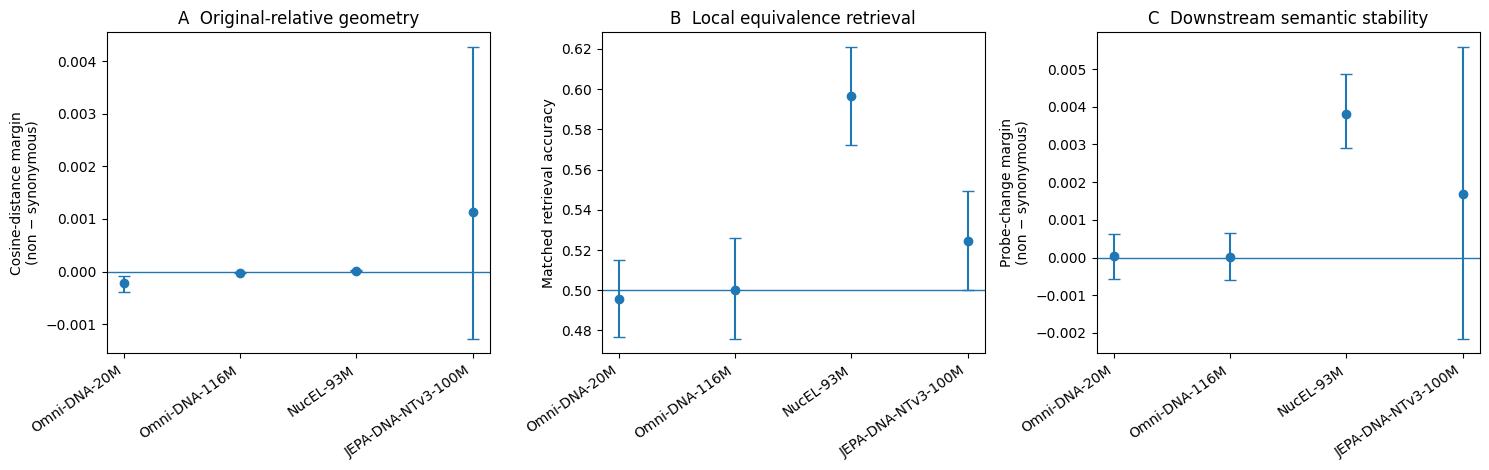

{'structural_rows': 20,
 'downstream_rows': 4,
 'models': ['Omni-DNA-20M',
  'Omni-DNA-116M',
  'NucEL-93M',
  'JEPA-DNA-NTv3-100M'],
 'structural_path': '/content/drive/MyDrive/wiml_equivalence/results/final_four_model_structural_comparison_91.csv',
 'downstream_path': '/content/drive/MyDrive/wiml_equivalence/results/final_four_model_downstream_probe_comparison_91.csv',
 'figure_png': '/content/drive/MyDrive/wiml_equivalence/figures/figure4_final_four_model_comparison.png',
 'figure_pdf': '/content/drive/MyDrive/wiml_equivalence/figures/figure4_final_four_model_comparison.pdf'}

In [107]:
# FINAL CONSOLIDATION 1C — Build exact four-model comparison and final figure

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MODEL_ORDER = [
    "Omni-DNA-20M",
    "Omni-DNA-116M",
    "NucEL-93M",
    "JEPA-DNA-NTv3-100M",
]

# ------------------------------------------------------------
# 1. Start from the frozen 3-model exact 91-source table
# ------------------------------------------------------------

assert cross_family_df.shape == (15, 6)

expected_metrics = [
    "syn_minus_non_endpoint_dispersion",
    "original_margin_non_minus_syn",
    "pairwise_margin_non_minus_syn",
    "equivalence_retrieval_accuracy",
    "semantic_margin_non_minus_syn",
]

assert set(
    cross_family_df["metric"].unique()
) == set(expected_metrics)

base_structural_df = (
    cross_family_df.copy()
)

base_structural_df[
    "n_sources"
] = 91


# ------------------------------------------------------------
# 2. Map JEPA metrics to exact frozen schema
# ------------------------------------------------------------

jepa_metric_map = {
    "path_consistency_syn_minus_non":
        "syn_minus_non_endpoint_dispersion",
    "original_semantic_margin_non_minus_syn":
        "original_margin_non_minus_syn",
    "pairwise_semantic_margin_non_minus_syn":
        "pairwise_margin_non_minus_syn",
    "retrieval_accuracy":
        "equivalence_retrieval_accuracy",
    "retrieval_semantic_margin_non_minus_syn":
        "semantic_margin_non_minus_syn",
}

jepa_rows = []

for row in jepa_structural_summary_df.to_dict(
    orient="records"
):

    source_metric = row["metric"]

    assert source_metric in jepa_metric_map

    jepa_rows.append({
        "model":
            "JEPA-DNA-NTv3-100M",
        "metric":
            jepa_metric_map[
                source_metric
            ],
        "mean":
            float(
                row["mean"]
            ),
        "ci95_low":
            float(
                row["ci95_low"]
            ),
        "ci95_high":
            float(
                row["ci95_high"]
            ),
        "reference":
            float(
                row["reference"]
            ),
        "n_sources":
            91,
    })

jepa_structural_df = pd.DataFrame(
    jepa_rows
)

assert len(
    jepa_structural_df
) == 5

assert set(
    jepa_structural_df["metric"]
) == set(expected_metrics)


# ------------------------------------------------------------
# 3. Four-model structural table
# ------------------------------------------------------------

four_model_structural_df = pd.concat(
    [
        base_structural_df,
        jepa_structural_df,
    ],
    ignore_index=True,
)

assert len(
    four_model_structural_df
) == 20

assert set(
    four_model_structural_df["model"]
) == set(MODEL_ORDER)

assert (
    four_model_structural_df
    .groupby("model")
    .size()
    .eq(5)
    .all()
)


# ------------------------------------------------------------
# 4. Four-model downstream table
# ------------------------------------------------------------

existing_downstream = (
    downstream_probe_bootstrap_df[
        downstream_probe_bootstrap_df[
            "metric"
        ]
        == "downstream_semantic_margin_non_minus_syn_l1"
    ]
    [
        [
            "model",
            "mean",
            "median",
            "ci95_low",
            "ci95_high",
            "fraction_positive",
            "n_sources",
        ]
    ]
    .copy()
)

assert len(
    existing_downstream
) == 3

jepa_downstream_row = pd.DataFrame([
    {
        "model":
            "JEPA-DNA-NTv3-100M",
        "mean":
            jepa_downstream_summary[
                "downstream_semantic_margin"
            ]["mean"],
        "median":
            jepa_downstream_summary[
                "downstream_semantic_margin"
            ]["median"],
        "ci95_low":
            jepa_downstream_summary[
                "downstream_semantic_margin"
            ]["ci95_low"],
        "ci95_high":
            jepa_downstream_summary[
                "downstream_semantic_margin"
            ]["ci95_high"],
        "fraction_positive":
            jepa_downstream_summary[
                "downstream_semantic_margin"
            ]["fraction_positive"],
        "n_sources":
            91,
    }
])

four_model_downstream_df = pd.concat(
    [
        existing_downstream,
        jepa_downstream_row,
    ],
    ignore_index=True,
)

assert len(
    four_model_downstream_df
) == 4

assert set(
    four_model_downstream_df["model"]
) == set(MODEL_ORDER)


# ------------------------------------------------------------
# 5. Save frozen final tables
# ------------------------------------------------------------

FINAL_STRUCTURAL_PATH = (
    PROJECT_ROOT
    / "results"
    / "final_four_model_structural_comparison_91.csv"
)

FINAL_DOWNSTREAM_PATH = (
    PROJECT_ROOT
    / "results"
    / "final_four_model_downstream_probe_comparison_91.csv"
)

four_model_structural_df.to_csv(
    FINAL_STRUCTURAL_PATH,
    index=False,
)

four_model_downstream_df.to_csv(
    FINAL_DOWNSTREAM_PATH,
    index=False,
)


# ------------------------------------------------------------
# 6. Final three-panel figure
# ------------------------------------------------------------

x = np.arange(
    len(MODEL_ORDER)
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.8),
)


# Panel A — Original-relative semantic geometry
panel_a = (
    four_model_structural_df[
        four_model_structural_df[
            "metric"
        ]
        == "original_margin_non_minus_syn"
    ]
    .set_index("model")
    .loc[MODEL_ORDER]
    .reset_index()
)

axes[0].errorbar(
    x,
    panel_a["mean"],
    yerr=[
        panel_a["mean"]
        - panel_a["ci95_low"],
        panel_a["ci95_high"]
        - panel_a["mean"],
    ],
    fmt="o",
    capsize=4,
)

axes[0].axhline(
    0,
    linewidth=1,
)

axes[0].set_xticks(
    x
)

axes[0].set_xticklabels(
    MODEL_ORDER,
    rotation=35,
    ha="right",
)

axes[0].set_ylabel(
    "Cosine-distance margin\n(non − synonymous)"
)

axes[0].set_title(
    "A  Original-relative geometry"
)


# Panel B — Matched retrieval
panel_b = (
    four_model_structural_df[
        four_model_structural_df[
            "metric"
        ]
        == "equivalence_retrieval_accuracy"
    ]
    .set_index("model")
    .loc[MODEL_ORDER]
    .reset_index()
)

axes[1].errorbar(
    x,
    panel_b["mean"],
    yerr=[
        panel_b["mean"]
        - panel_b["ci95_low"],
        panel_b["ci95_high"]
        - panel_b["mean"],
    ],
    fmt="o",
    capsize=4,
)

axes[1].axhline(
    0.5,
    linewidth=1,
)

axes[1].set_xticks(
    x
)

axes[1].set_xticklabels(
    MODEL_ORDER,
    rotation=35,
    ha="right",
)

axes[1].set_ylabel(
    "Matched retrieval accuracy"
)

axes[1].set_title(
    "B  Local equivalence retrieval"
)


# Panel C — Downstream semantic stability
panel_c = (
    four_model_downstream_df
    .set_index("model")
    .loc[MODEL_ORDER]
    .reset_index()
)

axes[2].errorbar(
    x,
    panel_c["mean"],
    yerr=[
        panel_c["mean"]
        - panel_c["ci95_low"],
        panel_c["ci95_high"]
        - panel_c["mean"],
    ],
    fmt="o",
    capsize=4,
)

axes[2].axhline(
    0,
    linewidth=1,
)

axes[2].set_xticks(
    x
)

axes[2].set_xticklabels(
    MODEL_ORDER,
    rotation=35,
    ha="right",
)

axes[2].set_ylabel(
    "Probe-change margin\n(non − synonymous)"
)

axes[2].set_title(
    "C  Downstream semantic stability"
)

fig.tight_layout()


FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FINAL_FIGURE_PNG = (
    FIGURE_DIR
    / "figure4_final_four_model_comparison.png"
)

FINAL_FIGURE_PDF = (
    FIGURE_DIR
    / "figure4_final_four_model_comparison.pdf"
)

fig.savefig(
    FINAL_FIGURE_PNG,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FINAL_FIGURE_PDF,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# 7. Final validation
# ------------------------------------------------------------

for path in [
    FINAL_STRUCTURAL_PATH,
    FINAL_DOWNSTREAM_PATH,
    FINAL_FIGURE_PNG,
    FINAL_FIGURE_PDF,
]:
    assert path.exists()
    assert path.stat().st_size > 0

final_status = {
    "structural_rows":
        len(
            four_model_structural_df
        ),
    "downstream_rows":
        len(
            four_model_downstream_df
        ),
    "models":
        MODEL_ORDER,
    "structural_path":
        str(
            FINAL_STRUCTURAL_PATH
        ),
    "downstream_path":
        str(
            FINAL_DOWNSTREAM_PATH
        ),
    "figure_png":
        str(
            FINAL_FIGURE_PNG
        ),
    "figure_pdf":
        str(
            FINAL_FIGURE_PDF
        ),
}

final_status

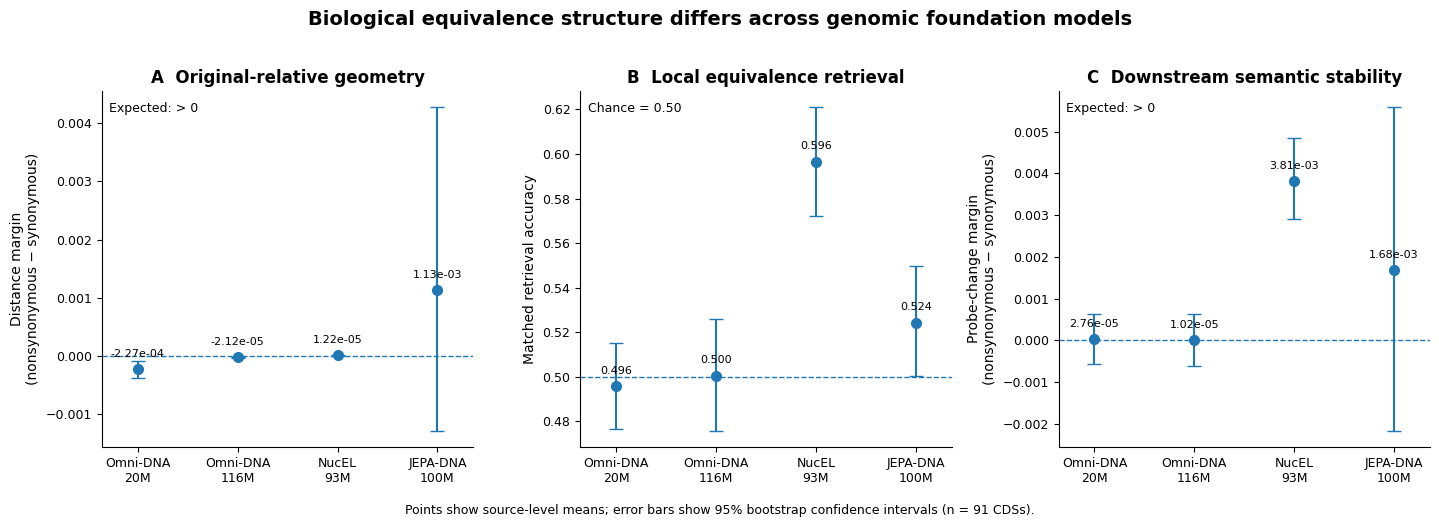

{'png': '/content/drive/MyDrive/wiml_equivalence/figures/figure4_four_model_publication.png',
 'pdf': '/content/drive/MyDrive/wiml_equivalence/figures/figure4_four_model_publication.pdf'}

In [108]:
# PUBLICATION FIGURE — Clean four-model summary for paper / WiML submission

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the frozen final result tables from disk.
FINAL_STRUCTURAL_PATH = (
    PROJECT_ROOT
    / "results"
    / "final_four_model_structural_comparison_91.csv"
)

FINAL_DOWNSTREAM_PATH = (
    PROJECT_ROOT
    / "results"
    / "final_four_model_downstream_probe_comparison_91.csv"
)

structural_df = pd.read_csv(
    FINAL_STRUCTURAL_PATH
)

downstream_df = pd.read_csv(
    FINAL_DOWNSTREAM_PATH
)

MODEL_ORDER = [
    "Omni-DNA-20M",
    "Omni-DNA-116M",
    "NucEL-93M",
    "JEPA-DNA-NTv3-100M",
]

MODEL_LABELS = [
    "Omni-DNA\n20M",
    "Omni-DNA\n116M",
    "NucEL\n93M",
    "JEPA-DNA\n100M",
]

assert set(structural_df["model"]) == set(MODEL_ORDER)
assert set(downstream_df["model"]) == set(MODEL_ORDER)

x = np.arange(
    len(MODEL_ORDER)
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14.5, 4.8),
)

# ------------------------------------------------------------
# Panel A — Original-relative biological geometry
# ------------------------------------------------------------

a = (
    structural_df[
        structural_df["metric"]
        == "original_margin_non_minus_syn"
    ]
    .set_index("model")
    .loc[MODEL_ORDER]
    .reset_index()
)

axes[0].errorbar(
    x,
    a["mean"],
    yerr=[
        a["mean"] - a["ci95_low"],
        a["ci95_high"] - a["mean"],
    ],
    fmt="o",
    markersize=7,
    capsize=5,
    linewidth=1.5,
)

axes[0].axhline(
    0,
    linewidth=1,
    linestyle="--",
)

axes[0].set_xticks(
    x,
    MODEL_LABELS,
)

axes[0].set_ylabel(
    "Distance margin\n"
    "(nonsynonymous − synonymous)"
)

axes[0].set_title(
    "A  Original-relative geometry",
    fontweight="bold",
)

axes[0].text(
    0.02,
    0.97,
    "Expected: > 0",
    transform=axes[0].transAxes,
    ha="left",
    va="top",
    fontsize=9,
)

for i, value in enumerate(a["mean"]):
    axes[0].annotate(
        f"{value:.2e}",
        (
            x[i],
            value,
        ),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )


# ------------------------------------------------------------
# Panel B — Matched local equivalence retrieval
# ------------------------------------------------------------

b = (
    structural_df[
        structural_df["metric"]
        == "equivalence_retrieval_accuracy"
    ]
    .set_index("model")
    .loc[MODEL_ORDER]
    .reset_index()
)

axes[1].errorbar(
    x,
    b["mean"],
    yerr=[
        b["mean"] - b["ci95_low"],
        b["ci95_high"] - b["mean"],
    ],
    fmt="o",
    markersize=7,
    capsize=5,
    linewidth=1.5,
)

axes[1].axhline(
    0.5,
    linewidth=1,
    linestyle="--",
)

axes[1].set_xticks(
    x,
    MODEL_LABELS,
)

axes[1].set_ylabel(
    "Matched retrieval accuracy"
)

axes[1].set_title(
    "B  Local equivalence retrieval",
    fontweight="bold",
)

axes[1].text(
    0.02,
    0.97,
    "Chance = 0.50",
    transform=axes[1].transAxes,
    ha="left",
    va="top",
    fontsize=9,
)

for i, value in enumerate(b["mean"]):
    axes[1].annotate(
        f"{value:.3f}",
        (
            x[i],
            value,
        ),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )


# ------------------------------------------------------------
# Panel C — Downstream protein-semantic stability
# ------------------------------------------------------------

c = (
    downstream_df
    .set_index("model")
    .loc[MODEL_ORDER]
    .reset_index()
)

axes[2].errorbar(
    x,
    c["mean"],
    yerr=[
        c["mean"] - c["ci95_low"],
        c["ci95_high"] - c["mean"],
    ],
    fmt="o",
    markersize=7,
    capsize=5,
    linewidth=1.5,
)

axes[2].axhline(
    0,
    linewidth=1,
    linestyle="--",
)

axes[2].set_xticks(
    x,
    MODEL_LABELS,
)

axes[2].set_ylabel(
    "Probe-change margin\n"
    "(nonsynonymous − synonymous)"
)

axes[2].set_title(
    "C  Downstream semantic stability",
    fontweight="bold",
)

axes[2].text(
    0.02,
    0.97,
    "Expected: > 0",
    transform=axes[2].transAxes,
    ha="left",
    va="top",
    fontsize=9,
)

for i, value in enumerate(c["mean"]):
    axes[2].annotate(
        f"{value:.2e}",
        (
            x[i],
            value,
        ),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )


# ------------------------------------------------------------
# Shared formatting
# ------------------------------------------------------------

for ax in axes:
    ax.spines["top"].set_visible(
        False
    )
    ax.spines["right"].set_visible(
        False
    )
    ax.tick_params(
        axis="both",
        labelsize=9,
    )
    ax.margins(
        x=0.12
    )

fig.suptitle(
    "Biological equivalence structure differs across genomic foundation models",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)

fig.text(
    0.5,
    -0.03,
    "Points show source-level means; error bars show 95% bootstrap confidence intervals (n = 91 CDSs).",
    ha="center",
    fontsize=9,
)

fig.tight_layout()


FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
)

PUBLICATION_FIGURE_PNG = (
    FIGURE_DIR
    / "figure4_four_model_publication.png"
)

PUBLICATION_FIGURE_PDF = (
    FIGURE_DIR
    / "figure4_four_model_publication.pdf"
)

fig.savefig(
    PUBLICATION_FIGURE_PNG,
    dpi=400,
    bbox_inches="tight",
)

fig.savefig(
    PUBLICATION_FIGURE_PDF,
    bbox_inches="tight",
)

plt.show()

assert PUBLICATION_FIGURE_PNG.exists()
assert PUBLICATION_FIGURE_PDF.exists()

{
    "png": str(
        PUBLICATION_FIGURE_PNG
    ),
    "pdf": str(
        PUBLICATION_FIGURE_PDF
    ),
}

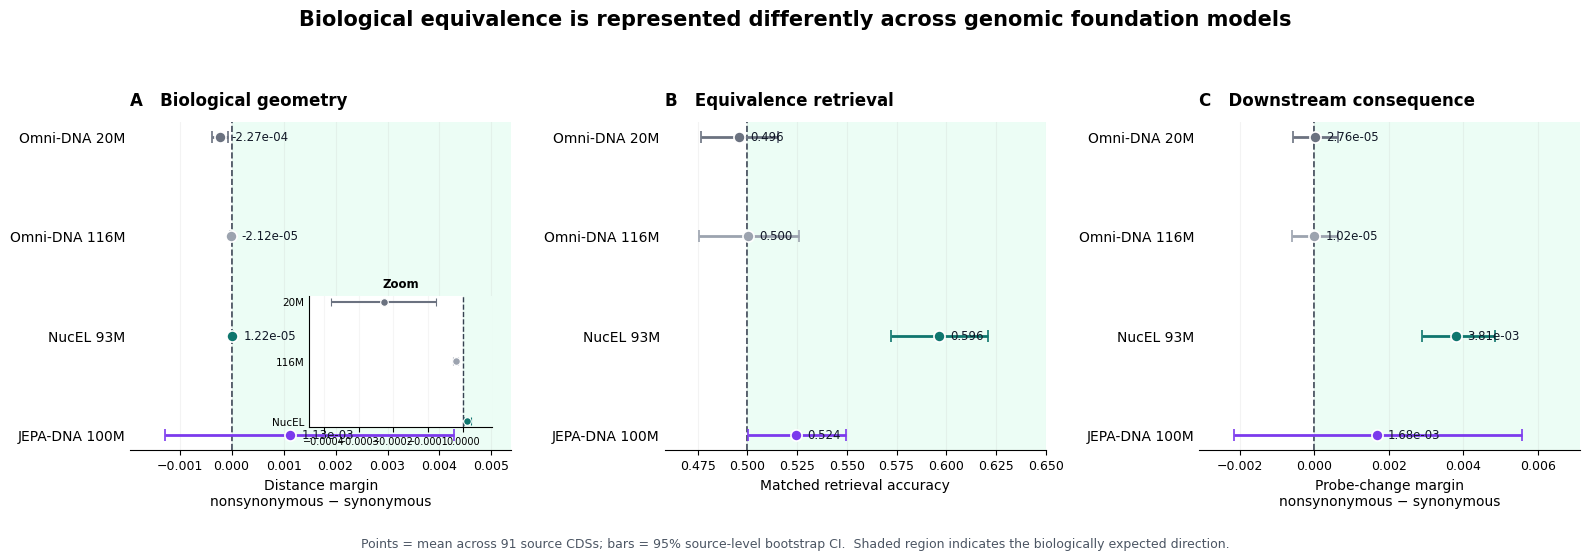

{'png': '/content/drive/MyDrive/wiml_equivalence/figures/figure4_four_model_forest_publication.png',
 'pdf': '/content/drive/MyDrive/wiml_equivalence/figures/figure4_four_model_forest_publication.pdf'}

In [109]:
# PUBLICATION FIGURE V2 — Polished forest-plot summary with Panel A zoom

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Load frozen results
# ------------------------------------------------------------

STRUCTURAL_PATH = (
    PROJECT_ROOT
    / "results"
    / "final_four_model_structural_comparison_91.csv"
)

DOWNSTREAM_PATH = (
    PROJECT_ROOT
    / "results"
    / "final_four_model_downstream_probe_comparison_91.csv"
)

structural_df = pd.read_csv(
    STRUCTURAL_PATH
)

downstream_df = pd.read_csv(
    DOWNSTREAM_PATH
)

MODEL_ORDER = [
    "Omni-DNA-20M",
    "Omni-DNA-116M",
    "NucEL-93M",
    "JEPA-DNA-NTv3-100M",
]

DISPLAY_NAMES = {
    "Omni-DNA-20M": "Omni-DNA 20M",
    "Omni-DNA-116M": "Omni-DNA 116M",
    "NucEL-93M": "NucEL 93M",
    "JEPA-DNA-NTv3-100M": "JEPA-DNA 100M",
}

MODEL_COLORS = {
    "Omni-DNA-20M": "#6B7280",
    "Omni-DNA-116M": "#9CA3AF",
    "NucEL-93M": "#0F766E",
    "JEPA-DNA-NTv3-100M": "#7C3AED",
}

# Put first model at top.
y_positions = np.arange(
    len(MODEL_ORDER)
)[::-1]


# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------

def ordered_metric(
    df,
    metric=None,
):
    if metric is not None:
        df = df[
            df["metric"] == metric
        ]

    return (
        df
        .set_index("model")
        .loc[MODEL_ORDER]
        .reset_index()
    )


def draw_forest(
    ax,
    df,
    reference,
    favorable_direction,
    xlabel,
    title,
    number_format,
):
    # Subtle favorable-region shading
    xmin = min(
        df["ci95_low"].min(),
        reference,
    )

    xmax = max(
        df["ci95_high"].max(),
        reference,
    )

    span = xmax - xmin

    xmin -= 0.12 * span
    xmax += 0.20 * span

    if favorable_direction == "right":
        ax.axvspan(
            reference,
            xmax,
            color="#ECFDF5",
            zorder=0,
        )
    else:
        ax.axvspan(
            xmin,
            reference,
            color="#ECFDF5",
            zorder=0,
        )

    ax.axvline(
        reference,
        color="#374151",
        linestyle="--",
        linewidth=1.2,
        zorder=1,
    )

    for y, row in zip(
        y_positions,
        df.itertuples(),
    ):
        color = MODEL_COLORS[
            row.model
        ]

        low_err = (
            row.mean
            - row.ci95_low
        )

        high_err = (
            row.ci95_high
            - row.mean
        )

        ax.errorbar(
            row.mean,
            y,
            xerr=np.array(
                [[low_err], [high_err]]
            ),
            fmt="o",
            markersize=8,
            markerfacecolor=color,
            markeredgecolor="white",
            markeredgewidth=1.2,
            ecolor=color,
            elinewidth=2.0,
            capsize=4,
            capthick=1.5,
            zorder=3,
        )

        text = number_format(
            row.mean
        )

        ax.annotate(
            text,
            (
                row.mean,
                y,
            ),
            xytext=(8, 0),
            textcoords="offset points",
            va="center",
            ha="left",
            fontsize=8.5,
            color="#111827",
            fontweight="medium",
        )

    ax.set_xlim(
        xmin,
        xmax,
    )

    ax.set_yticks(
        y_positions
    )

    ax.set_yticklabels(
        [
            DISPLAY_NAMES[m]
            for m in MODEL_ORDER
        ],
        fontsize=10,
    )

    ax.set_xlabel(
        xlabel,
        fontsize=10,
    )

    ax.set_title(
        title,
        loc="left",
        fontsize=12,
        fontweight="bold",
        pad=12,
    )

    ax.grid(
        axis="x",
        alpha=0.15,
        linewidth=0.8,
    )

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)

    ax.spines[
        "left"
    ].set_visible(False)

    ax.tick_params(
        axis="y",
        length=0,
    )

    ax.tick_params(
        axis="x",
        labelsize=9,
    )


# ------------------------------------------------------------
# Extract panels
# ------------------------------------------------------------

panel_a = ordered_metric(
    structural_df,
    "original_margin_non_minus_syn",
)

panel_b = ordered_metric(
    structural_df,
    "equivalence_retrieval_accuracy",
)

panel_c = ordered_metric(
    downstream_df,
)


# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5.3),
)

draw_forest(
    axes[0],
    panel_a,
    reference=0.0,
    favorable_direction="right",
    xlabel=(
        "Distance margin\n"
        "nonsynonymous − synonymous"
    ),
    title="A   Biological geometry",
    number_format=lambda x: f"{x:.2e}",
)

draw_forest(
    axes[1],
    panel_b,
    reference=0.5,
    favorable_direction="right",
    xlabel="Matched retrieval accuracy",
    title="B   Equivalence retrieval",
    number_format=lambda x: f"{x:.3f}",
)

draw_forest(
    axes[2],
    panel_c,
    reference=0.0,
    favorable_direction="right",
    xlabel=(
        "Probe-change margin\n"
        "nonsynonymous − synonymous"
    ),
    title="C   Downstream consequence",
    number_format=lambda x: f"{x:.2e}",
)


# ------------------------------------------------------------
# Panel A inset zoom
# Shows Omni-DNA + NucEL without hiding JEPA uncertainty.
# ------------------------------------------------------------

zoom_models = [
    "Omni-DNA-20M",
    "Omni-DNA-116M",
    "NucEL-93M",
]

zoom_df = (
    panel_a[
        panel_a["model"].isin(
            zoom_models
        )
    ]
    .set_index("model")
    .loc[zoom_models]
    .reset_index()
)

inset = axes[0].inset_axes(
    [
        0.47,
        0.07,
        0.48,
        0.40,
    ]
)

inset.axvspan(
    0,
    0.00015,
    color="#ECFDF5",
    zorder=0,
)

inset.axvline(
    0,
    color="#374151",
    linestyle="--",
    linewidth=1,
)

zoom_y = np.arange(
    len(
        zoom_models
    )
)[::-1]

for y, row in zip(
    zoom_y,
    zoom_df.itertuples(),
):
    color = MODEL_COLORS[
        row.model
    ]

    inset.errorbar(
        row.mean,
        y,
        xerr=np.array([
            [
                row.mean
                - row.ci95_low
            ],
            [
                row.ci95_high
                - row.mean
            ],
        ]),
        fmt="o",
        markersize=5.5,
        markerfacecolor=color,
        markeredgecolor="white",
        markeredgewidth=0.8,
        ecolor=color,
        elinewidth=1.5,
        capsize=3,
    )

inset.set_yticks(
    zoom_y
)

inset.set_yticklabels(
    [
        "20M",
        "116M",
        "NucEL",
    ],
    fontsize=7.5,
)

zoom_min = (
    zoom_df[
        "ci95_low"
    ].min()
)

zoom_max = (
    zoom_df[
        "ci95_high"
    ].max()
)

zoom_pad = (
    zoom_max
    - zoom_min
) * 0.15

inset.set_xlim(
    zoom_min
    - zoom_pad,
    zoom_max
    + zoom_pad,
)

inset.set_title(
    "Zoom",
    fontsize=8.5,
    fontweight="bold",
)

inset.tick_params(
    axis="x",
    labelsize=7,
)

inset.tick_params(
    axis="y",
    length=0,
)

inset.grid(
    axis="x",
    alpha=0.12,
)

inset.spines[
    "top"
].set_visible(False)

inset.spines[
    "right"
].set_visible(False)


# ------------------------------------------------------------
# Figure-level annotations
# ------------------------------------------------------------

fig.suptitle(
    "Biological equivalence is represented differently across genomic foundation models",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)

fig.text(
    0.5,
    0.00,
    (
        "Points = mean across 91 source CDSs; "
        "bars = 95% source-level bootstrap CI.  "
        "Shaded region indicates the biologically expected direction."
    ),
    ha="center",
    va="bottom",
    fontsize=9,
    color="#4B5563",
)

fig.tight_layout(
    rect=[
        0,
        0.05,
        1,
        0.96,
    ]
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

PRETTY_PNG = (
    FIGURE_DIR
    / "figure4_four_model_forest_publication.png"
)

PRETTY_PDF = (
    FIGURE_DIR
    / "figure4_four_model_forest_publication.pdf"
)

fig.savefig(
    PRETTY_PNG,
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    PRETTY_PDF,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

assert PRETTY_PNG.exists()
assert PRETTY_PDF.exists()

{
    "png": str(PRETTY_PNG),
    "pdf": str(PRETTY_PDF),
}

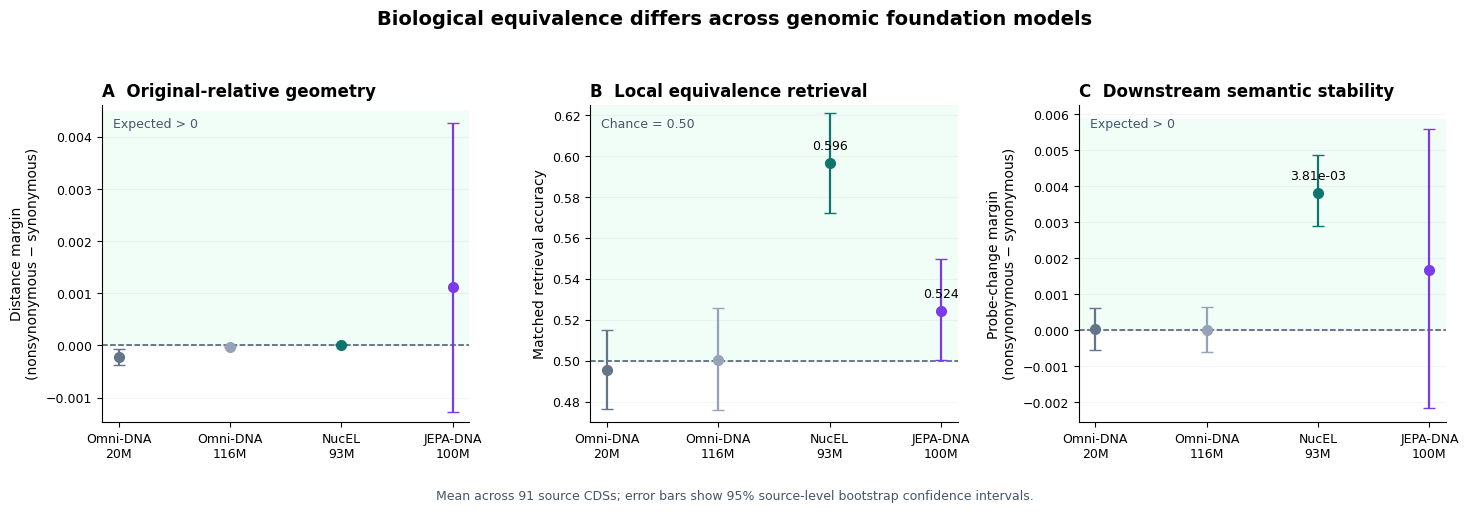

{'png': '/content/drive/MyDrive/wiml_equivalence/figures/figure4_four_model_clean_publication.png',
 'pdf': '/content/drive/MyDrive/wiml_equivalence/figures/figure4_four_model_clean_publication.pdf'}

In [110]:
# PUBLICATION FIGURE V3 — Cleaner version of the original 3-panel design

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

structural_df = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "final_four_model_structural_comparison_91.csv"
)

downstream_df = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "final_four_model_downstream_probe_comparison_91.csv"
)

MODEL_ORDER = [
    "Omni-DNA-20M",
    "Omni-DNA-116M",
    "NucEL-93M",
    "JEPA-DNA-NTv3-100M",
]

MODEL_LABELS = [
    "Omni-DNA\n20M",
    "Omni-DNA\n116M",
    "NucEL\n93M",
    "JEPA-DNA\n100M",
]

COLORS = [
    "#64748B",
    "#94A3B8",
    "#0F766E",
    "#7C3AED",
]

x = np.arange(4)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14.8, 4.8),
)

# ------------------------------------------------------------
# Panel A
# ------------------------------------------------------------

a = (
    structural_df[
        structural_df["metric"]
        == "original_margin_non_minus_syn"
    ]
    .set_index("model")
    .loc[MODEL_ORDER]
    .reset_index()
)

ymin = min(
    a["ci95_low"].min(),
    -0.0002,
)

ymax = max(
    a["ci95_high"].max(),
    0.0002,
)

axes[0].axhspan(
    0,
    ymax * 1.05,
    color="#ECFDF5",
    alpha=0.7,
    zorder=0,
)

axes[0].axhline(
    0,
    linestyle="--",
    linewidth=1.1,
    color="#475569",
)

for i, row in a.iterrows():
    axes[0].errorbar(
        x[i],
        row["mean"],
        yerr=[[
            row["mean"] - row["ci95_low"]
        ], [
            row["ci95_high"] - row["mean"]
        ]],
        fmt="o",
        markersize=7,
        capsize=4,
        linewidth=1.6,
        color=COLORS[i],
    )

axes[0].set_ylim(
    ymin * 1.15,
    ymax * 1.08,
)

axes[0].set_title(
    "A  Original-relative geometry",
    loc="left",
    fontweight="bold",
)

axes[0].set_ylabel(
    "Distance margin\n"
    "(nonsynonymous − synonymous)"
)

axes[0].text(
    0.03,
    0.96,
    "Expected > 0",
    transform=axes[0].transAxes,
    va="top",
    fontsize=9,
    color="#475569",
)


# ------------------------------------------------------------
# Panel B
# ------------------------------------------------------------

b = (
    structural_df[
        structural_df["metric"]
        == "equivalence_retrieval_accuracy"
    ]
    .set_index("model")
    .loc[MODEL_ORDER]
    .reset_index()
)

axes[1].axhspan(
    0.5,
    max(
        b["ci95_high"].max(),
        0.625,
    ),
    color="#ECFDF5",
    alpha=0.7,
    zorder=0,
)

axes[1].axhline(
    0.5,
    linestyle="--",
    linewidth=1.1,
    color="#475569",
)

for i, row in b.iterrows():
    axes[1].errorbar(
        x[i],
        row["mean"],
        yerr=[[
            row["mean"] - row["ci95_low"]
        ], [
            row["ci95_high"] - row["mean"]
        ]],
        fmt="o",
        markersize=7,
        capsize=4,
        linewidth=1.6,
        color=COLORS[i],
    )

axes[1].set_ylim(
    0.47,
    0.625,
)

axes[1].set_title(
    "B  Local equivalence retrieval",
    loc="left",
    fontweight="bold",
)

axes[1].set_ylabel(
    "Matched retrieval accuracy"
)

axes[1].text(
    0.03,
    0.96,
    "Chance = 0.50",
    transform=axes[1].transAxes,
    va="top",
    fontsize=9,
    color="#475569",
)

# Label only the most informative results.
axes[1].annotate(
    f"{b.iloc[2]['mean']:.3f}",
    (x[2], b.iloc[2]["mean"]),
    xytext=(0, 10),
    textcoords="offset points",
    ha="center",
    fontsize=9,
)

axes[1].annotate(
    f"{b.iloc[3]['mean']:.3f}",
    (x[3], b.iloc[3]["mean"]),
    xytext=(0, 10),
    textcoords="offset points",
    ha="center",
    fontsize=9,
)


# ------------------------------------------------------------
# Panel C
# ------------------------------------------------------------

c = (
    downstream_df
    .set_index("model")
    .loc[MODEL_ORDER]
    .reset_index()
)

c_ymax = max(
    c["ci95_high"].max(),
    0.0045,
)

axes[2].axhspan(
    0,
    c_ymax * 1.05,
    color="#ECFDF5",
    alpha=0.7,
    zorder=0,
)

axes[2].axhline(
    0,
    linestyle="--",
    linewidth=1.1,
    color="#475569",
)

for i, row in c.iterrows():
    axes[2].errorbar(
        x[i],
        row["mean"],
        yerr=[[
            row["mean"] - row["ci95_low"]
        ], [
            row["ci95_high"] - row["mean"]
        ]],
        fmt="o",
        markersize=7,
        capsize=4,
        linewidth=1.6,
        color=COLORS[i],
    )

axes[2].set_title(
    "C  Downstream semantic stability",
    loc="left",
    fontweight="bold",
)

axes[2].set_ylabel(
    "Probe-change margin\n"
    "(nonsynonymous − synonymous)"
)

axes[2].text(
    0.03,
    0.96,
    "Expected > 0",
    transform=axes[2].transAxes,
    va="top",
    fontsize=9,
    color="#475569",
)

axes[2].annotate(
    f"{c.iloc[2]['mean']:.2e}",
    (x[2], c.iloc[2]["mean"]),
    xytext=(0, 10),
    textcoords="offset points",
    ha="center",
    fontsize=9,
)


# ------------------------------------------------------------
# Shared formatting
# ------------------------------------------------------------

for ax in axes:
    ax.set_xticks(
        x,
        MODEL_LABELS,
    )

    ax.tick_params(
        axis="x",
        labelsize=9,
    )

    ax.tick_params(
        axis="y",
        labelsize=9,
    )

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)

    ax.grid(
        axis="y",
        alpha=0.12,
        linewidth=0.8,
    )

fig.suptitle(
    "Biological equivalence differs across genomic foundation models",
    fontsize=14,
    fontweight="bold",
    y=1.01,
)

fig.text(
    0.5,
    -0.01,
    (
        "Mean across 91 source CDSs; error bars show "
        "95% source-level bootstrap confidence intervals."
    ),
    ha="center",
    fontsize=9,
    color="#475569",
)

fig.tight_layout(
    rect=[
        0,
        0.04,
        1,
        0.96,
    ]
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
)

FINAL_PRETTY_PNG = (
    FIGURE_DIR
    / "figure4_four_model_clean_publication.png"
)

FINAL_PRETTY_PDF = (
    FIGURE_DIR
    / "figure4_four_model_clean_publication.pdf"
)

fig.savefig(
    FINAL_PRETTY_PNG,
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    FINAL_PRETTY_PDF,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

{
    "png": str(FINAL_PRETTY_PNG),
    "pdf": str(FINAL_PRETTY_PDF),
}